# Historical record — not a Run-All entry point

Use [predictions.ipynb](predictions.ipynb), [confidence_analysis.ipynb](confidence_analysis.ipynb) and [stability_analysis.ipynb](stability_analysis.ipynb) for the supported, TEST-only results. This archive deliberately preserves superseded interpretations, exploratory train/validation code, expensive optional replay cells and original relative paths; it is evidence of the analysis history, **not a single executable workflow or a source of current conclusions**. Historical sections may contradict later corrected results; the main notebooks state the final conclusions.

The finalization snapshots at the end include every replaced notebook, code cell, output and explanation. For the legacy `visualization/predictions.ipynb` snapshot, the original working directory was `visualization/`; its old ResNet50 CSV is not the current supplied ResNet50 pipeline.

# Archived analyses — complete pre-curation snapshots

These snapshots preserve every original code cell, interpretation and rendered output from commit `8ee69ba`. Complete source notebooks are included rather than isolated plots so that dependencies and computational provenance are not lost. Run a source section from a fresh kernel if reproducing it; the curated main notebooks read the existing validated caches.

- [Main confidence results](confidence_analysis.ipynb)
- [Main transformation stability results](stability_analysis.ipynb)

## Archive A — confidence_analysis.ipynb

Includes the original confidence/entropy distributions, four-panel transformation figures, all RGB distributions, full saturation and occlusion views, real-image PCA, both surrogate-region versions, local PCA slices and targeted error/control analyses.

# Confidence analysis
## Three run-1 models: ResNet18 224, ResNet50 28 and original ViT; full test split

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

threshold, n_bins = 0.90, 10
model_names = ['resnet18', 'resnet50', 'vit']
class_names = list(json.loads(Path('data/metadata.json').read_text())['label'].values())
class_names[3] = 'immature granulocytes'
with np.load('data/bloodmnist.npz', allow_pickle=False) as data:
    images, labels = data['test_images'], data['test_labels'].ravel()
probabilities = []
for name in model_names:
    rows = np.loadtxt(f'predictions/{name}_test.csv', delimiter=',', skiprows=1)
    np.testing.assert_array_equal(rows[:, 0], np.arange(len(labels)))
    np.testing.assert_array_equal(rows[:, 1], labels)
    probabilities.append(rows[:, 3:])
probabilities = np.stack(probabilities)
np.testing.assert_allclose(probabilities.sum(-1), 1, atol=1e-6)
predicted = probabilities.argmax(-1)
confidence = probabilities.max(-1)
correct = predicted == labels
bins = np.linspace(0, 1, n_bins + 1)
centers = (bins[:-1] + bins[1:]) / 2

def bin_ids(values):
    return np.clip(np.searchsorted(bins, values, side='right') - 1, 0, n_bins - 1)

def entropy(p):
    p = np.asarray(p, dtype=float)
    return -(p * np.log(np.maximum(p, 1e-300))).sum(-1) / np.log(p.shape[-1])

uncertainty = entropy(probabilities)
print(f'{len(labels)} test images; high-confidence threshold: {threshold:.0%}')
from itertools import combinations
pairs = list(combinations(range(len(model_names)), 2))
model_colors = ['#2678ad', '#3b9956', '#c25a7c']
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=model_colors)


3421 test images; high-confidence threshold: 90%


## Reliability diagram — equal-width confidence bins; ECE weighted by bin counts; empty bins omitted

resnet18: accuracy=96.61%, mean confidence=98.73%, ECE=0.0219
resnet50: accuracy=95.73%, mean confidence=98.66%, ECE=0.0298
vit: accuracy=96.99%, mean confidence=98.62%, ECE=0.0167


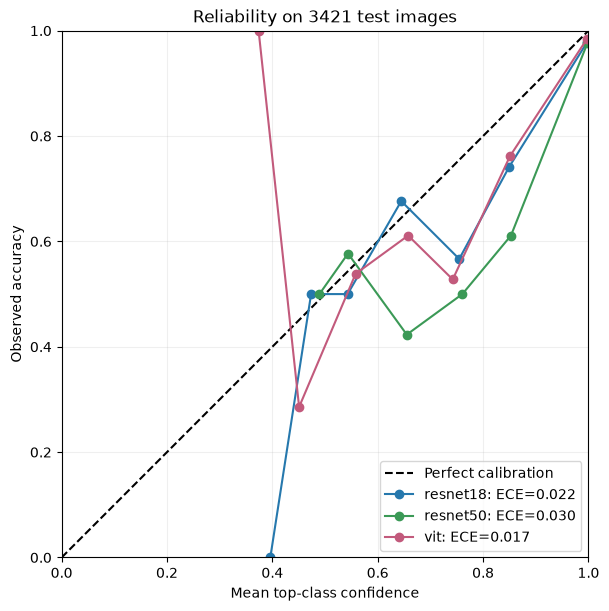

In [3]:
fig, ax = plt.subplots(figsize=(7, 6), layout='constrained')
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
for m, name in enumerate(model_names):
    groups = bin_ids(confidence[m])
    occupied = [groups == b for b in range(n_bins) if (groups == b).any()]
    x = np.array([confidence[m, mask].mean() for mask in occupied])
    y = np.array([correct[m, mask].mean() for mask in occupied])
    counts = np.array([mask.sum() for mask in occupied])
    ece = np.sum(counts * np.abs(y - x)) / len(labels)
    ax.plot(x, y, 'o-', label=f'{name}: ECE={ece:.3f}')
    print(f'{name}: accuracy={correct[m].mean():.2%}, mean confidence={confidence[m].mean():.2%}, ECE={ece:.4f}')
ax.set(xlabel='Mean top-class confidence', ylabel='Observed accuracy',
       title=f'Reliability on {len(labels)} test images', xlim=(0, 1), ylim=(0, 1))
ax.set_aspect('equal')
ax.grid(alpha=0.2)
ax.legend()
plt.show()

Compare each reliability curve with the diagonal, where confidence equals observed accuracy. Mean confidence exceeds accuracy by about 2.1 percentage points for ResNet18, 2.9 for ResNet50 and 1.6 for ViT. These test results indicate overconfidence, without establishing its training-time cause, and motivate checking calibration on separate data.

## Top-class confidence — all models overlaid, aggregated across classes; all correct and all incorrect test predictions

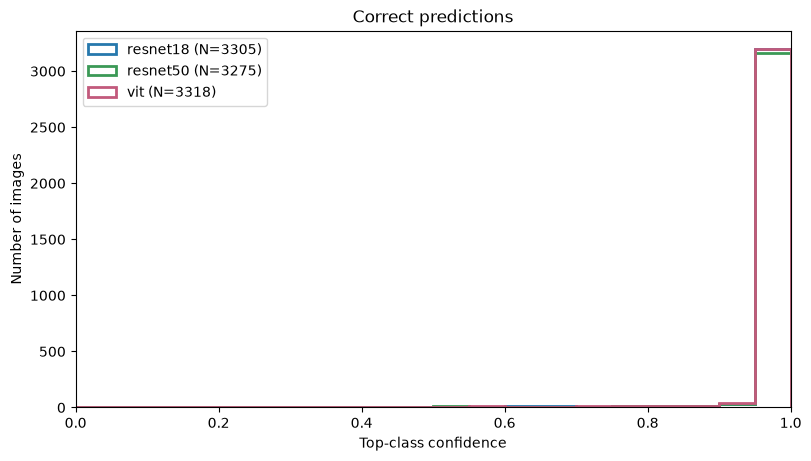

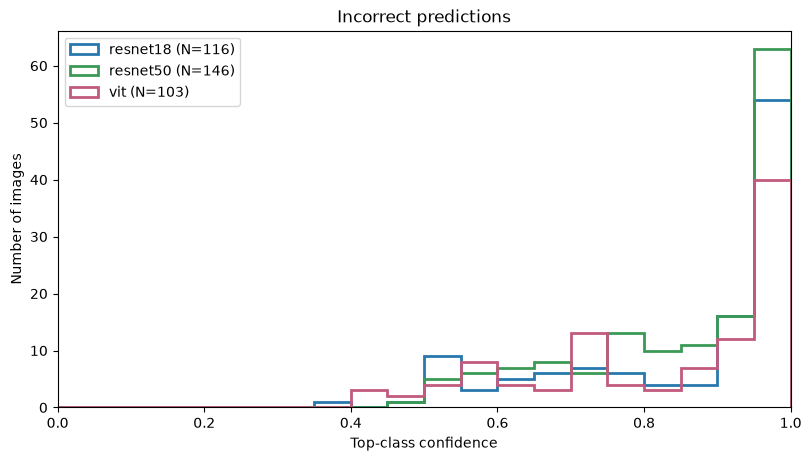

In [4]:
for is_correct, title in [(True, 'Correct predictions'), (False, 'Incorrect predictions')]:
    fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
    for m, color in enumerate(model_colors):
        mask = correct[m] == is_correct
        ax.hist(confidence[m, mask], bins=np.linspace(0, 1, 21), histtype='step',
                linewidth=2, color=color, label=f'{model_names[m]} (N={mask.sum()})')
    ax.set(title=title, xlabel='Top-class confidence', ylabel='Number of images', xlim=(0, 1))
    ax.legend()
    plt.show()

Compare the confidence distributions of correct and incorrect predictions, especially their overlap near one. Incorrect predictions also accumulate at high confidence, despite the models assigning higher average confidence to correct predictions. Maximum confidence alone therefore cannot reliably distinguish correct decisions from errors.

## Confidence disagreement — each model's own maximum probability, not necessarily the same class

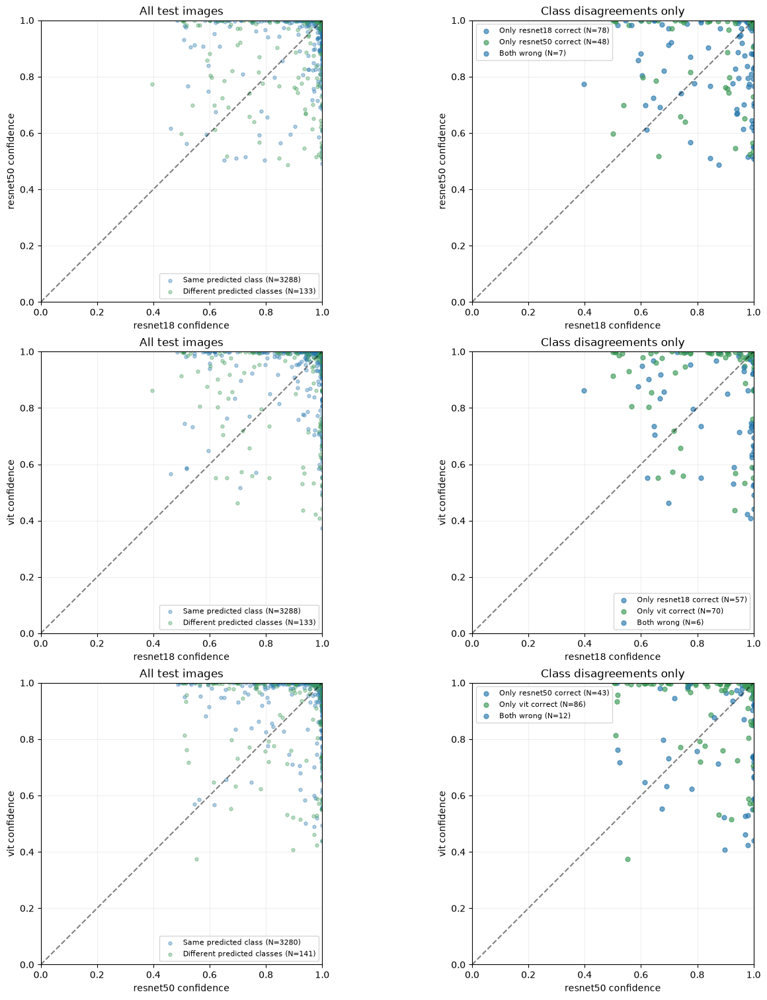

In [5]:
fig, axes = plt.subplots(len(pairs), 2, figsize=(13, 5 * len(pairs)), layout='constrained')
for row, (i, j) in enumerate(pairs):
    agree = predicted[i] == predicted[j]
    for mask, color, title in [(agree, 'C0', 'Same predicted class'), (~agree, 'C1', 'Different predicted classes')]:
        axes[row, 0].scatter(confidence[i, mask], confidence[j, mask], s=14, alpha=0.35,
                              color=color, label=f'{title} (N={mask.sum()})')
    groups = [(correct[i] & ~correct[j], 'C0', f'Only {model_names[i]} correct'),
              (~correct[i] & correct[j], 'C1', f'Only {model_names[j]} correct'),
              (~correct[i] & ~correct[j], 'C3', 'Both wrong')]
    for mask, color, title in groups:
        mask = mask & ~agree
        axes[row, 1].scatter(confidence[i, mask], confidence[j, mask], s=25, alpha=0.65,
                              color=color, label=f'{title} (N={mask.sum()})')
    for ax, title in zip(axes[row], ['All test images', 'Class disagreements only']):
        ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
        ax.set(title=title, xlabel=f'{model_names[i]} confidence', ylabel=f'{model_names[j]} confidence',
               xlim=(0, 1), ylim=(0, 1))
        ax.set_aspect('equal')
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
plt.show()


Look for model pairs that disagree on the label while both assign high confidence to their own predictions. On disagreement cases, choosing the more confident model is correct in only about 59–65% of cases across the three pairs. Resolving disagreement therefore requires a tested decision rule rather than assuming that the largest confidence score identifies the correct model.

## Predictive entropy — left: correct/error distributions; right: error percentage within each entropy bin

Entropy ranges from 0 (one class dominates) to 1 (all eight classes are equally probable). Each right-hand bar covers an entropy interval of width 0.1, with errors divided by all images in that interval; labels show errors/total and empty bins are omitted. The dashed line is the model’s overall test error rate, so bars above it identify bins with a higher observed error rate.

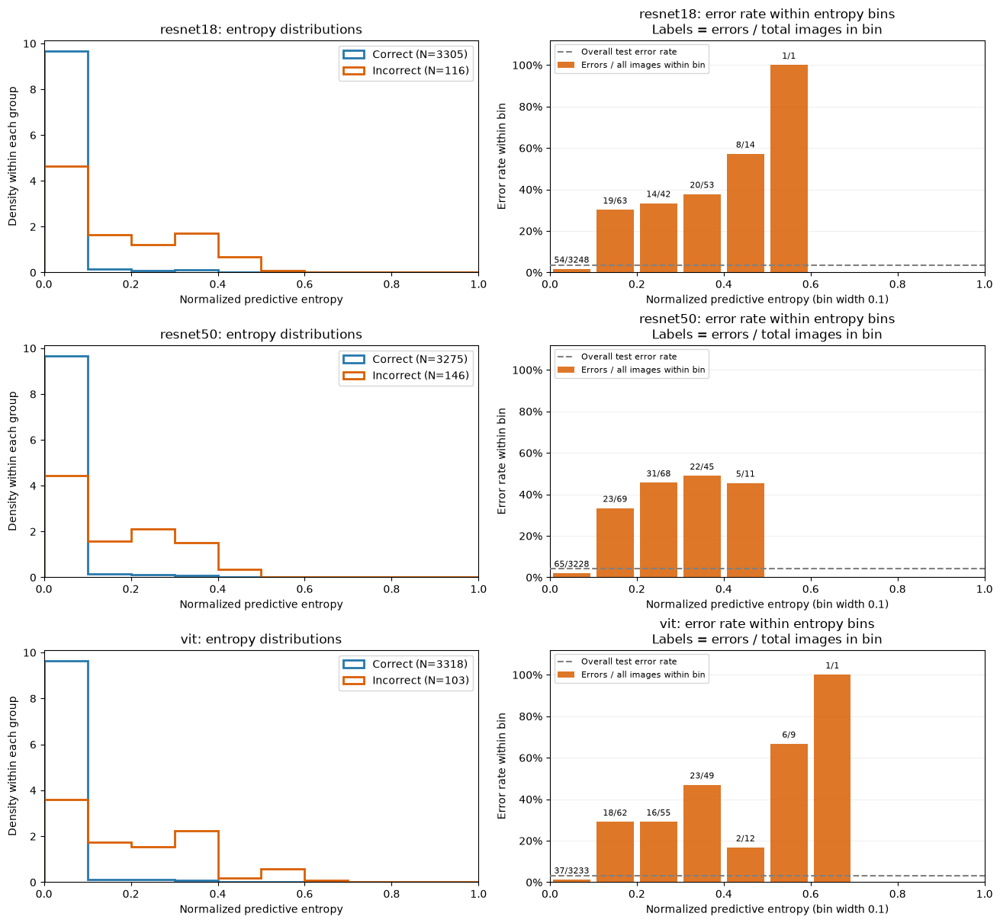

In [6]:
from matplotlib.ticker import PercentFormatter

correct_color, error_color = '#2678ad', '#d95f02'
fig, axes = plt.subplots(len(model_names), 2, figsize=(13, 4 * len(model_names)), layout='constrained')
for m, name in enumerate(model_names):
    for mask, color, title in [(correct[m], correct_color, 'Correct'), (~correct[m], error_color, 'Incorrect')]:
        if mask.any():
            axes[m, 0].hist(uncertainty[m, mask], bins=bins, density=True, histtype='step',
                            linewidth=2, color=color, label=f'{title} (N={mask.sum()})')
    axes[m, 0].set(title=f'{name}: entropy distributions', xlabel='Normalized predictive entropy',
                   ylabel='Density within each group', xlim=(0, 1))
    axes[m, 0].legend()
    groups = bin_ids(uncertainty[m])
    counts = np.bincount(groups, minlength=n_bins)
    errors = np.bincount(groups, weights=~correct[m], minlength=n_bins).astype(int)
    occupied = counts > 0
    rates = errors[occupied] / counts[occupied]
    ax = axes[m, 1]
    ax.bar(centers[occupied], rates, width=0.85 / n_bins, color=error_color, alpha=0.85,
           label='Errors / all images within bin', zorder=3)
    ax.axhline((~correct[m]).mean(), color='gray', ls='--', label='Overall test error rate', zorder=4)
    for x, y, e, count in zip(centers[occupied], rates, errors[occupied], counts[occupied]):
        ax.annotate(f'{e}/{count}', (x, y), xytext=(0, 6), textcoords='offset points',
                    ha='center', fontsize=8)
    ax.set(title=f'{name}: error rate within entropy bins\nLabels = errors / total images in bin',
           xlabel='Normalized predictive entropy (bin width 0.1)', ylabel='Error rate within bin',
           xlim=(0, 1), ylim=(0, 1.12), yticks=np.linspace(0, 1, 6))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(axis='y', alpha=0.2, zorder=0)
plt.show()

Compare the blue correct and orange incorrect distributions on the left with the error percentages on the right, whose labels show errors/total images in each bin. For ResNet18, the lowest-entropy bin contains 54/3,248 errors, an error rate of only 1.7%, even though those 54 images account for 47% of its 116 errors. The left plots therefore show where each group lies while the right plots show error risk within a bin, and extreme percentages based on one or a few images provide weak evidence.

## Confidence under transformations — directly comparable probability changes; all 3,421 test images

Compare maximum-confidence change with the change in support for the fixed original class on the same −100 to +10 percentage-point scale, shared by all transformation figures. The lower panels use fixed 0–100% error-rate and 0–1 entropy scales, with noise repeats averaged within each of the 3,421 test images. Dashed lines mark unmodified references, and confident-error rates include pre-existing mistakes rather than only newly induced errors.

In [7]:
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved['model_names'], model_names)
    indices, stability_labels = saved['indices'], saved['labels']
    baseline = saved['baseline']
    levels = {key[7:]: saved[key] for key in saved.files if key.startswith('levels_')}
    transformed = {kind: saved[kind] for kind in levels}
np.testing.assert_array_equal(stability_labels, labels[indices])
np.testing.assert_allclose(baseline, probabilities[:, indices], atol=1e-9)
base_confidence = baseline.max(-1)
base_entropy = entropy(baseline)
base_high_wrong = (baseline.argmax(-1) != stability_labels) & (base_confidence >= threshold)
from matplotlib.ticker import PercentFormatter

change_limits = (-100, 10)
original_class = baseline.argmax(-1)
confidence_changes = {}
for kind, p in transformed.items():
    conf = p.max(-1)
    support = np.take_along_axis(p, original_class[:, None, None, :, None], axis=-1)[..., 0]
    high_wrong = (p.argmax(-1) != stability_labels) & (conf >= threshold)
    # Average repeats and images without retaining another per-image experiment array.
    confidence_changes[kind] = {
        'Maximum confidence: change': conf.mean((2, 3), dtype=float) - base_confidence.mean(-1)[:, None],
        'Original-class support: change': support.mean((2, 3), dtype=float) - base_confidence.mean(-1)[:, None],
        f'Confidently wrong (≥{threshold:.0%})': high_wrong.mean((2, 3)),
        'Normalized predictive entropy': entropy(p).mean((2, 3)),
    }

def plot_confidence_change(kind, p):
    references = [np.zeros(len(model_names)), np.zeros(len(model_names)),
                  base_high_wrong.mean(-1), base_entropy.mean(-1)]
    fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True, layout='constrained')
    reference = 1 if kind.endswith('_scale') or kind == 'brightness' else 0
    for j, (ax, (title, curves), original) in enumerate(zip(axes.flat, confidence_changes[kind].items(), references)):
        factor = 100 if j < 2 else 1
        for m, name in enumerate(model_names):
            y = factor * curves[m]
            if j < 2:
                assert change_limits[0] <= y.min() and y.max() <= change_limits[1], 'Change would be clipped.'
            ax.plot(levels[kind], y, 'o-', color=model_colors[m], label=name)
            if j >= 2:
                ax.axhline(original[m], color=model_colors[m], ls='--', alpha=0.4)
        if j < 2:
            ax.axhline(0, color='gray', ls='--')
            ax.set(ylim=change_limits, ylabel='Change (percentage points)')
        else:
            ax.set(ylim=(0, 1), yticks=np.linspace(0, 1, 5),
                   ylabel='Fraction of all test images' if j == 2 else 'Entropy (0–1)')
            if j == 2:
                ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        ax.axvline(reference, color='gray', ls=':', alpha=0.5)
        ax.set(title=title, xlabel=kind)
        ax.grid(alpha=0.2)
    axes[0, 0].legend()
    fig.suptitle(f'{kind} · N={len(stability_labels)} · fixed y-scales across transformations')
    plt.show()


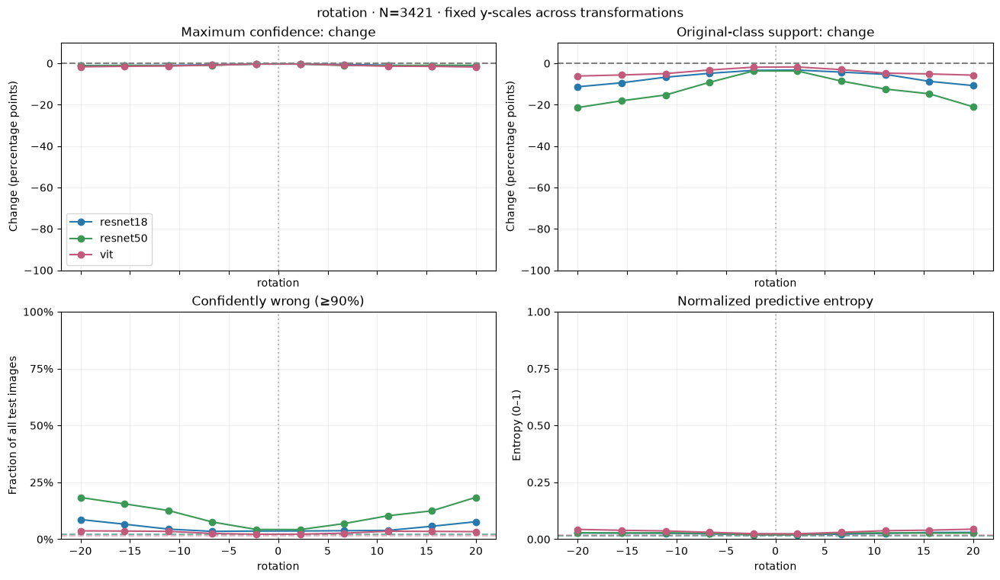

In [8]:
plot_confidence_change('rotation', transformed['rotation'])

Compare the two upper panels on their identical percentage-point scales to see whether rotation changes certainty or support for the original answer. ResNet50 loses only 0.9 percentage points of maximum confidence but 12.8 points of original-class support, while its high-confidence-error fraction averages 11.1%. Rotation can therefore change the answer without making the model much less certain, and the confident-error fraction includes pre-existing errors.

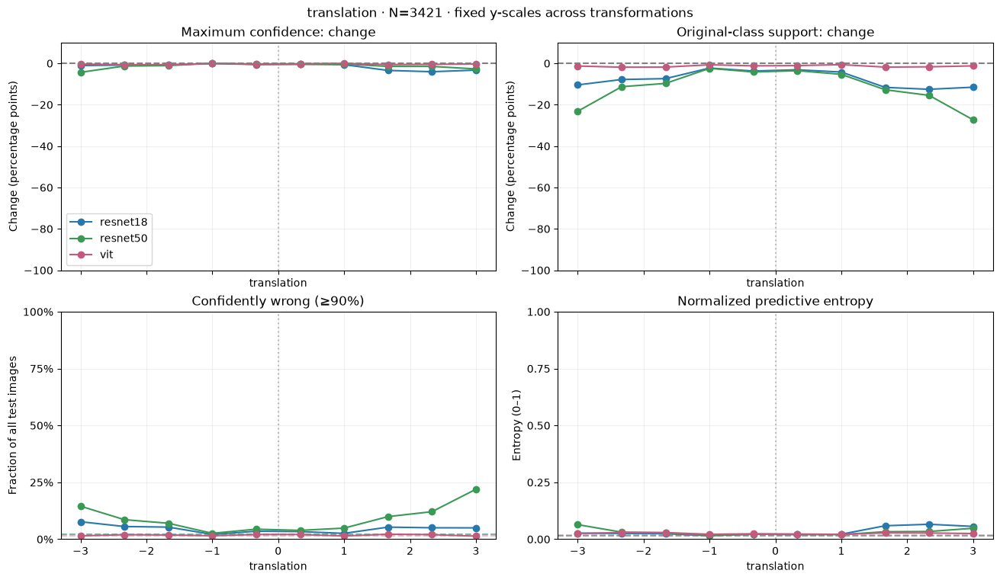

In [9]:
plot_confidence_change('translation', transformed['translation'])

Compare maximum-confidence change with original-class support on the shared scale before checking the confident-error panel. ResNet50 loses only 1.3 percentage points of maximum confidence but 11.5 points of original-class support, with a 9.0% high-confidence-error fraction versus 1.8% for ViT. Translation therefore changes ResNet50’s answers more than its certainty, so nearly constant maximum confidence is not evidence of consistent decisions.

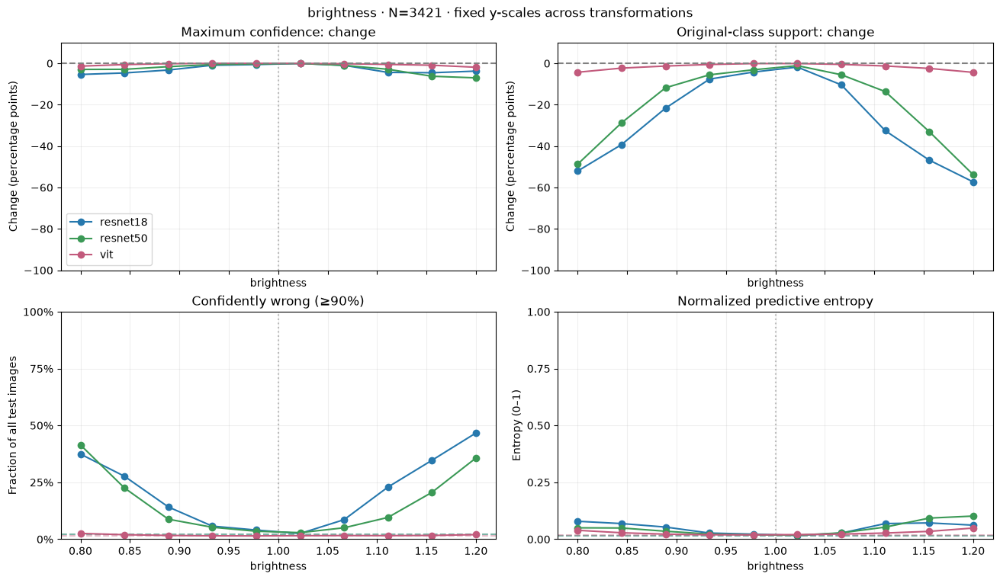

In [10]:
plot_confidence_change('brightness', transformed['brightness'])

Compare the two upper curves on their shared scale and check whether confident-error frequency rises as brightness changes. ResNet18 loses 2.8 percentage points of maximum confidence but 27.3 points of original-class support, with mean confident-error fractions of 20.5% for ResNet18, 15.5% for ResNet50 and 1.8% for ViT. The CNNs therefore often retain concentrated outputs while brightness redirects support away from the original answer.

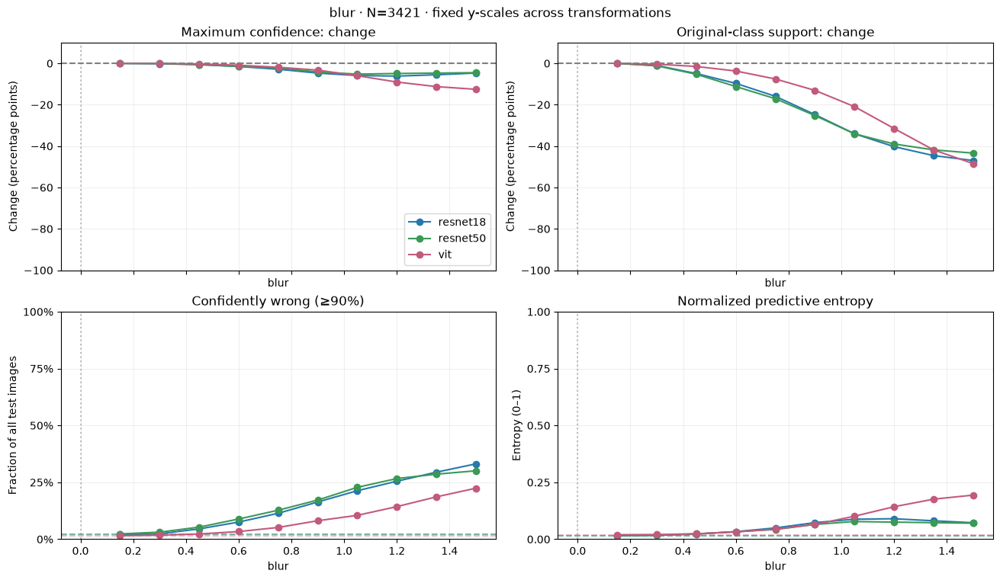

In [11]:
plot_confidence_change('blur', transformed['blur'])

Compare how entropy and confident-error frequency change as blur removes spatial detail. ViT reaches a mean normalized entropy of 0.082, versus 0.054 and 0.049 for the CNNs, and has a lower confident-error fraction of 8.8%. Its blur response spreads probability across competing classes more strongly, so fewer confident errors do not imply that its decisions remain unchanged.

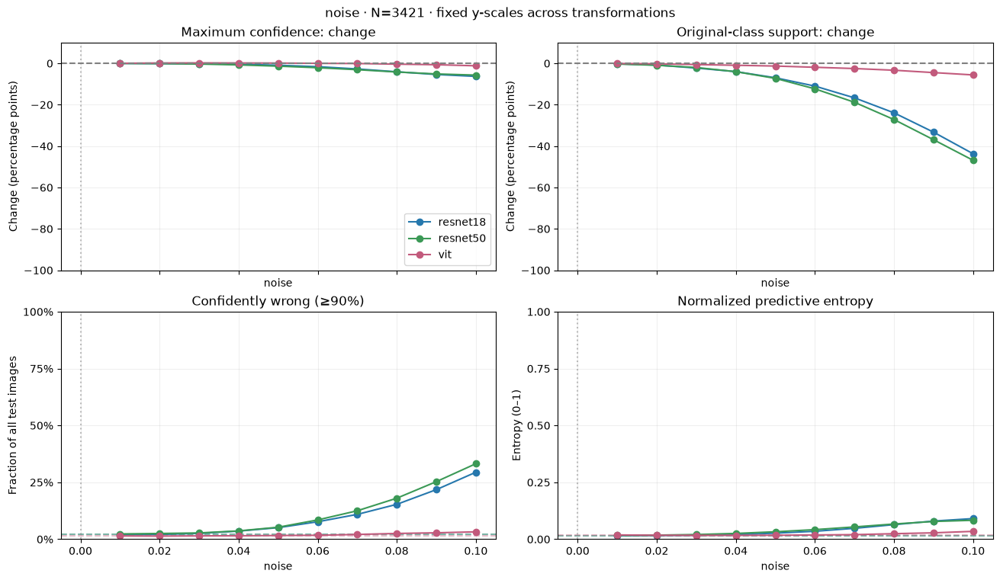

In [12]:
plot_confidence_change('noise', transformed['noise'])

Check whether nearly unchanged confidence under noise accompanies stable accuracy or hides additional confident errors. ViT loses only 0.2 percentage points of maximum confidence and averages 96.2% accuracy, close to its 97.0% baseline, with a 2.0% high-confidence-error fraction. Here confidence stability largely accompanies decision stability, unlike the CNN brightness response, although the confident-error fraction still includes original errors.

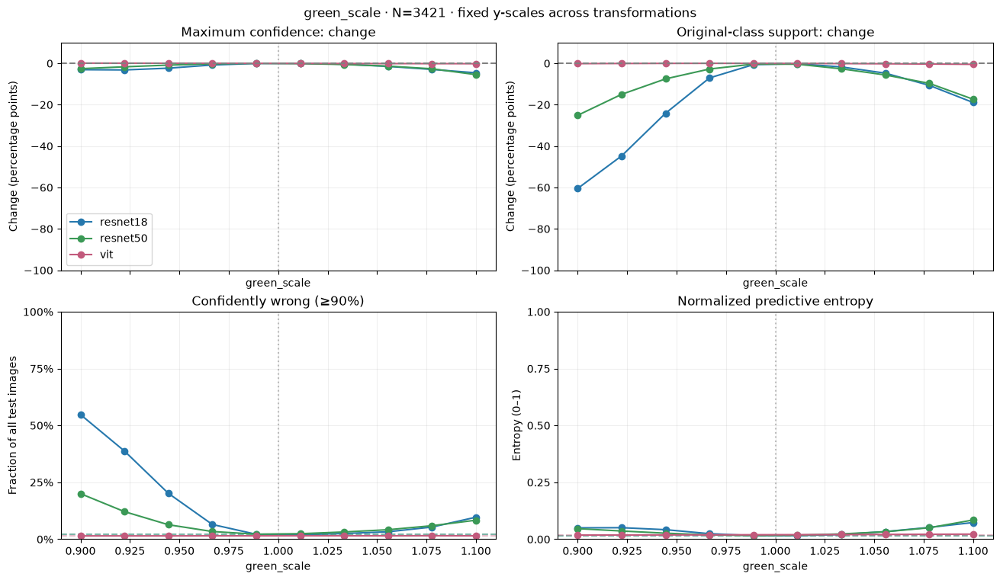

In [13]:
plot_confidence_change('green_scale', transformed['green_scale'])

Compare the direction of green scaling with changes in confidence and confidently wrong predictions. ResNet18 produces high-confidence errors on 14.5% of image–level pairs despite a mean maximum-confidence loss of only 1.9 percentage points, while ViT changes much less. Green-channel sensitivity is therefore strongly checkpoint-dependent and can redirect confident CNN decisions without a proportional uncertainty signal.

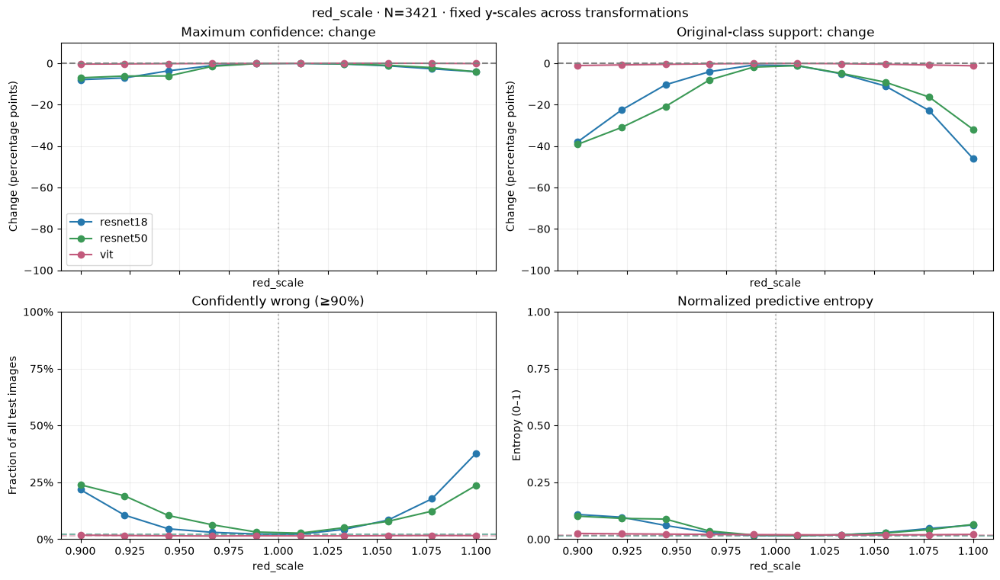

In [14]:
plot_confidence_change('red_scale', transformed['red_scale'])

Compare the two upper panels on their identical scale and use the lower-left panel to check how often confident predictions are wrong. The CNNs lose about 16 percentage points of original-class support but only 2.8 points of maximum confidence, with confident-error fractions of 11.3% and 11.4%. Red scaling therefore changes which answer receives concentrated support more strongly than it reduces certainty.

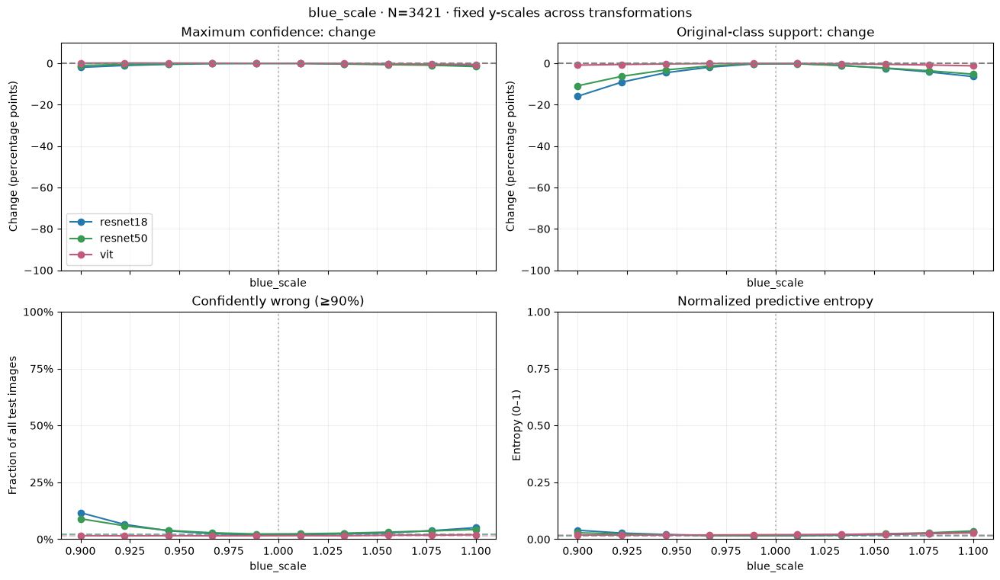

In [15]:
plot_confidence_change('blue_scale', transformed['blue_scale'])

Compare the blue-scaling confident-error curves with the red- and green-scaling curves over the same factor interval. The CNN high-confidence-error fractions are only 4.2% and 4.0% under blue scaling, below their corresponding red and green values. Color sensitivity is therefore channel-specific rather than a uniform response to multiplying any RGB channel.

## What drives the accuracy change? — interactive explorer

Compare recovered errors above zero with new errors below zero; dark orange marks new errors at ≥90% confidence. All panels use the same test-image denominator and linked axes, including while zooming. Choose a transformation, then wheel or drag to zoom; use Reset to return to the full range.

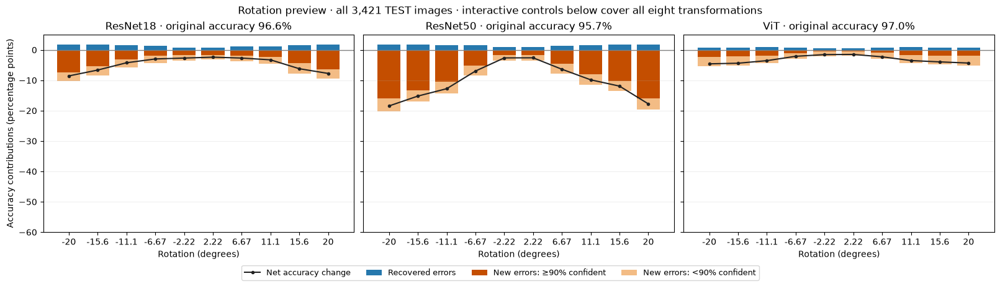

In [52]:
# Correctness changes explain accuracy; a switch between two wrong labels is not a gain or loss.
transition_data = dict(n=len(labels), threshold=threshold, models=['ResNet18', 'ResNet50', 'ViT'], operations={})
operation_names = {'rotation': ('Rotation', 'degrees'), 'translation': ('Translation', 'pixels'),
                   'brightness': ('Brightness', 'factor'), 'blur': ('Blur', 'pixels'),
                   'noise': ('Noise', 'sigma'), 'green_scale': ('Green scaling', 'factor'),
                   'red_scale': ('Red scaling', 'factor'), 'blue_scale': ('Blue scaling', 'factor')}
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    assert str(saved['split']) == 'test'
    np.testing.assert_array_equal(saved['indices'], np.arange(len(labels)))
    np.testing.assert_array_equal(saved['labels'], labels)
    np.testing.assert_array_equal(saved['baseline'], probabilities)
    was_correct = saved['baseline'].argmax(-1) == labels
    baseline_accuracy = 100 * was_correct.mean(-1)
    transition_data.update(baseline_accuracy=baseline_accuracy.tolist(),
                           baseline_errors=(~was_correct).sum(-1).tolist())
    for kind, (name, unit) in operation_names.items():
        p = saved[kind]
        now_correct = p.argmax(-1) == labels
        new_error = was_correct[:, None, None, :] & ~now_correct
        recovered = ~was_correct[:, None, None, :] & now_correct
        # Each original image has equal weight, including when noise has three repeats.
        counts = lambda mask: mask.mean(2).sum(-1)
        lost, gained = counts(new_error), counts(recovered)
        confident_lost = counts(new_error & (p.max(-1) >= threshold))
        np.testing.assert_allclose(baseline_accuracy[:, None] + 100 * (gained - lost) / len(labels),
                                   100 * now_correct.mean((2, 3)), atol=1e-10)
        assert (confident_lost <= lost).all()
        transition_data['operations'][kind] = dict(name=name, unit=unit, levels=saved[f'levels_{kind}'].tolist(),
            repeats=p.shape[2], lost=lost.tolist(), recovered=gained.tolist(), hc_lost=confident_lost.tolist())
max_loss = max(np.max(op['lost']) for op in transition_data['operations'].values())
max_gain = max(np.max(op['recovered']) for op in transition_data['operations'].values())
transition_data.update(ymin=float(-10 * np.ceil(100 * max_loss / len(labels) / 10)),
                       ymax=float(max(5, 5 * np.ceil(100 * max_gain / len(labels) / 5))))

# A static rotation preview remains readable on GitHub; the explorer below includes all operations.
preview = transition_data['operations']['rotation']
x = np.arange(len(preview['levels']))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True, layout='constrained')
for m, ax in enumerate(axes):
    gained, lost, hc = [100 * np.asarray(preview[key])[m] / len(labels) for key in ['recovered', 'lost', 'hc_lost']]
    ax.bar(x, gained, color='#2678ad', label='Recovered errors')
    ax.bar(x, -hc, color='#c44e00', label=f'New errors: ≥{threshold:.0%} confident')
    ax.bar(x, -(lost - hc), bottom=-hc, color='#f3bc85', label=f'New errors: <{threshold:.0%} confident')
    ax.plot(x, gained - lost, 'o-', color='#222', ms=3, label='Net accuracy change')
    ax.axhline(0, color='gray', lw=1)
    ax.set(title=f'{transition_data["models"][m]} · original accuracy {baseline_accuracy[m]:.1f}%',
           xticks=x, xticklabels=[f'{v:.3g}' for v in preview['levels']], xlabel='Rotation (degrees)',
           ylim=(transition_data['ymin'], transition_data['ymax']))
    ax.grid(axis='y', alpha=0.2)
axes[0].set_ylabel('Accuracy contributions (percentage points)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=4, fontsize=9)
fig.suptitle(f'Rotation preview · all {len(labels):,} TEST images · interactive controls below cover all eight transformations')
plt.show()


Compare bars above and below zero at the same level, then follow the black line to see which side dominates. At +20° rotation, ResNet50 recovers 60 errors but introduces 668 new ones, 547 of which are ≥90% confident, for a net accuracy loss of 17.8 percentage points. Helpful wrong-to-correct reversals are therefore overwhelmed by new, often confident errors, explaining why the overall accuracy falls despite some original mistakes becoming correct.

In [53]:
import html
from IPython.display import HTML, FileLink, display

# Self-contained HTML/SVG/JavaScript: no CDN, web service, widget backend or extra dependency.
transition_template = r'''<!doctype html>
<html lang="en"><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Transformation explorer</title>
<style>
*{box-sizing:border-box}body{font:14px system-ui,sans-serif;color:#252b32;max-width:1500px;margin:16px auto;padding:0 16px}h1{font-size:21px;margin:0}header,.toolbar,.legend{display:flex;align-items:center;flex-wrap:wrap;gap:12px}header{justify-content:space-between;margin-bottom:16px}.toolbar{gap:10px}label{display:flex;align-items:center;gap:8px;color:#58616b}select,button{font:inherit;background:white;border:1px solid #cfd5db;border-radius:5px;padding:5px 9px;color:#252b32}button{cursor:pointer}button:hover{background:#f1f4f7}button:focus-visible,select:focus-visible{outline:2px solid #2678ad}input{width:155px}output{min-width:94px;font-variant-numeric:tabular-nums}.legend{font-size:12px;color:#58616b;margin-bottom:12px;gap:18px}.swatch{display:inline-block;width:12px;height:9px;margin-right:5px}.models{display:grid;grid-template-columns:repeat(3,minmax(250px,1fr));gap:14px}.card{border:1px solid #e1e5e9;border-radius:7px;padding:12px}.model-head{display:flex;align-items:baseline;justify-content:space-between;gap:6px}.model-head h2{font-size:17px;margin:0}.accuracy{font-size:15px;font-weight:600;white-space:nowrap}.delta{font-size:12px;font-weight:400;color:#69737e;margin-left:6px}svg{width:100%;height:auto;touch-action:none;user-select:none;cursor:crosshair}.stats{display:grid;grid-template-columns:repeat(3,1fr);gap:8px;border-top:1px solid #edf0f3;padding-top:8px}.stats span{display:block;color:#69737e;font-size:11px}.stats strong{font-size:17px;font-weight:600;font-variant-numeric:tabular-nums}.footer{display:flex;justify-content:space-between;flex-wrap:wrap;gap:10px;margin-top:12px;color:#69737e;font-size:12px}details{margin-top:14px;color:#58616b;font-size:12px;line-height:1.6}summary{cursor:pointer}details p{max-width:1050px}a{color:#17689c}.selection{fill:#2678ad;fill-opacity:.12;stroke:#2678ad;stroke-dasharray:4 3;pointer-events:none}@media(max-width:850px){.models{grid-template-columns:1fr}header{align-items:flex-start}.toolbar{width:100%}}
</style>
<header><h1>Transformation explorer</h1><div class="toolbar"><select id="transformation" aria-label="Transformation"></select><label>Level <input id="level" aria-label="Transformation level" type="range" min="0" max="9" step="1" value="9"></label><output id="levelLabel" aria-live="polite"></output><button id="zoom-in" aria-label="Zoom in" title="Zoom into the selected level">+</button><button id="zoom-out" aria-label="Zoom out" title="Zoom out">−</button><button id="fit" title="Fit this transformation’s data, using the same axes for all models">Fit</button><button id="reset" title="Restore the shared full range">Reset</button></div></header>
<div class="legend"><span><i class="swatch" style="background:#2678ad"></i>Recovered</span><span><i class="swatch" style="background:#c44e00"></i>New: ≥__THRESHOLD__</span><span><i class="swatch" style="background:#f3bc85"></i>New: &lt;__THRESHOLD__</span><span>━━ Net accuracy change</span></div>
<div id="models" class="models"></div>
<div class="footer"><span id="status"></span><span>Wheel / drag to zoom · double-click to reset</span></div>
<details><summary>How to read · definitions · sources</summary><p>Bars above zero are originally wrong images that become correct; bars below zero are originally correct images that become wrong. Dark orange identifies new errors with confidence ≥__THRESHOLD__. The black line is recovered minus new errors, so it measures the net accuracy change. All contributions use the same full-test denominator, not different correct/wrong group sizes; switches between two wrong labels do not contribute. Header percentages show accuracy at the selected level, with the change from the original prediction beside them; hover for the original accuracy.</p><p>Zoom is linked across all three models. Drag a rectangle or use the wheel to zoom, click a bar or move the slider to inspect a level, use Fit for the current transformation’s range, or Reset / double-click for the full range. Changing transformations resets zoom. Noise counts are means of three realizations, not independent extra images. Transformed inputs may leave the data distribution or change the label: these views describe checkpoint responses, not a correction strategy.</p><p>Design: <a href="https://pmc.ncbi.nlm.nih.gov/articles/PMC7733875/">small multiples</a> · <a href="https://data.europa.eu/apps/data-visualisation-guide/the-information-seeking-mantra">overview, filter, details on demand</a>.</p></details>
<script>
const D=__DATA__;
const select=document.getElementById('transformation'), slider=document.getElementById('level');
for(const [key,p] of Object.entries(D.operations)){const o=document.createElement('option');o.value=key;o.textContent=p.name;select.append(o);}
const G={W:460,H:310,L:42,R:10,T:20,B:38};G.w=G.W-G.L-G.R;G.h=G.H-G.T-G.B;
const full={xmin:-.5,xmax:9.5,ymin:D.ymin,ymax:D.ymax};let view={...full},chosen=9,suppressClickUntil=0;
const fmt=x=>Math.abs(x)<1e-9?'0':Number(x.toPrecision(3)).toString();
const count=x=>Math.abs(x-Math.round(x))<1e-6?Math.round(x).toLocaleString():x.toFixed(1);
const pp=x=>(x>=0?'+':'')+x.toFixed(1)+' pp';
const X=j=>G.L+(j-view.xmin)/(view.xmax-view.xmin)*G.w;
const Y=v=>G.T+(view.ymax-v)/(view.ymax-view.ymin)*G.h;
const invX=x=>view.xmin+(x-G.L)/G.w*(view.xmax-view.xmin);
const invY=y=>view.ymax-(y-G.T)/G.h*(view.ymax-view.ymin);
function bounded(lo,hi,min,max,minSpan){const span=Math.min(max-min,Math.max(minSpan,hi-lo));lo=Math.max(min,Math.min((lo+hi-span)/2,max-span));return[lo,lo+span];}
function setView(xmin,xmax,ymin,ymax){[view.xmin,view.xmax]=bounded(xmin,xmax,full.xmin,full.xmax,1.5);[view.ymin,view.ymax]=bounded(ymin,ymax,full.ymin,full.ymax,.5);if(chosen<view.xmin||chosen>view.xmax){chosen=Math.max(0,Math.min(9,Math.round((view.xmin+view.xmax)/2)));slider.value=chosen;}render();}
function zoom(factor,cx=chosen,cy=0){setView(cx+(view.xmin-cx)*factor,cx+(view.xmax-cx)*factor,cy+(view.ymin-cy)*factor,cy+(view.ymax-cy)*factor);}
function reset(){view={...full};render();}
function ticks(lo,hi){const raw=(hi-lo)/5,power=10**Math.floor(Math.log10(raw)),r=raw/power,step=(r<=1?1:r<=2?2:r<=5?5:10)*power,result=[];for(let v=Math.ceil(lo/step)*step;v<=hi+step*1e-8;v+=step)result.push(v);return result;}
function chart(p,m){
 const dx=G.w/(view.xmax-view.xmin),clip=`clip${m}`;
 let s=`<svg viewBox="0 0 ${G.W} ${G.H}" data-model="${m}" role="img" aria-label="${D.models[m]}: zoomable accuracy contributions"><defs><clipPath id="${clip}"><rect x="${G.L}" y="${G.T}" width="${G.w}" height="${G.h}"/></clipPath></defs>`;
 s+=`<g clip-path="url(#${clip})"><rect x="${X(chosen)-dx/2}" y="${G.T}" width="${dx}" height="${G.h}" fill="#f5f7fa"/></g>`;
 for(const tick of ticks(view.ymin,view.ymax))s+=`<line x1="${G.L}" x2="${G.W-G.R}" y1="${Y(tick)}" y2="${Y(tick)}" stroke="${Math.abs(tick)<1e-8?'#969fa9':'#edf0f3'}"/><text x="${G.L-6}" y="${Y(tick)+4}" text-anchor="end" font-size="11" fill="#69737e">${fmt(tick)}</text>`;
 s+=`<text x="${G.L}" y="12" font-size="10" fill="#69737e">Accuracy contributions (pp)</text><g clip-path="url(#${clip})">`;
 for(let j=0;j<10;j++){
  const gain=100*p.recovered[m][j]/D.n,loss=100*p.lost[m][j]/D.n,hc=100*p.hc_lost[m][j]/D.n,a=X(j)-.33*dx,b=.66*dx;
  s+=`<g data-step="${j}" style="cursor:pointer"><title>${p.name} ${fmt(p.levels[j])} ${p.unit}: ${count(p.lost[m][j])} new (${count(p.hc_lost[m][j])} confident); ${count(p.recovered[m][j])} recovered</title><rect x="${X(j)-dx/2}" y="${G.T}" width="${dx}" height="${G.h}" fill="transparent"/><rect x="${a}" y="${Y(gain)}" width="${b}" height="${Y(0)-Y(gain)}" fill="#2678ad"/><rect x="${a}" y="${Y(0)}" width="${b}" height="${Y(-hc)-Y(0)}" fill="#c44e00"/><rect x="${a}" y="${Y(-hc)}" width="${b}" height="${Y(-loss)-Y(-hc)}" fill="#f3bc85"/></g>`;
 }
 const points=p.levels.map((_,j)=>`${X(j)},${Y(100*(p.recovered[m][j]-p.lost[m][j])/D.n)}`).join(' ');
 s+=`<polyline points="${points}" fill="none" stroke="#222" stroke-width="2" pointer-events="none"/><circle cx="${X(chosen)}" cy="${Y(100*(p.recovered[m][chosen]-p.lost[m][chosen])/D.n)}" r="4" fill="#222" pointer-events="none"/></g>`;
 const first=Math.max(0,Math.ceil(view.xmin)),last=Math.min(9,Math.floor(view.xmax)),stride=Math.max(1,Math.ceil((last-first+1)/6));
 for(let j=first;j<=last;j++)if((j-first)%stride===0||j===last||j===chosen)s+=`<text x="${X(j)}" y="${G.H-20}" text-anchor="middle" font-size="10" fill="#69737e">${fmt(p.levels[j])}</text>`;
 return s+`<text x="${G.L+G.w/2}" y="${G.H-3}" text-anchor="middle" font-size="10" fill="#69737e">${p.unit}</text></svg>`;
}
function localPoint(svg,e){const p=svg.createSVGPoint();p.x=e.clientX;p.y=e.clientY;return p.matrixTransform(svg.getScreenCTM().inverse());}
function inside(p){return p.x>=G.L&&p.x<=G.W-G.R&&p.y>=G.T&&p.y<=G.H-G.B;}
function bindZoom(svg){
 svg.addEventListener('wheel',e=>{const p=localPoint(svg,e);if(!inside(p))return;e.preventDefault();zoom(Math.exp(Math.max(-1,Math.min(1,e.deltaY*.002))),invX(p.x),invY(p.y));},{passive:false});
 svg.ondblclick=e=>{e.preventDefault();reset();};
 svg.onclick=e=>{if(Date.now()<suppressClickUntil)return;const p=localPoint(svg,e);if(inside(p)){chosen=Math.max(0,Math.min(9,Math.round(invX(p.x))));slider.value=chosen;render();}};
 let start=null,box=null;
 svg.onpointerdown=e=>{const p=localPoint(svg,e);if(e.button!==0||!inside(p))return;e.preventDefault();start=p;try{svg.setPointerCapture(e.pointerId);}catch{}box=document.createElementNS('http://www.w3.org/2000/svg','rect');box.setAttribute('class','selection');svg.append(box);};
 svg.onpointermove=e=>{if(!start)return;const p=localPoint(svg,e),x=Math.max(G.L,Math.min(G.W-G.R,p.x)),y=Math.max(G.T,Math.min(G.H-G.B,p.y));for(const[k,v]of Object.entries({x:Math.min(start.x,x),y:Math.min(start.y,y),width:Math.abs(x-start.x),height:Math.abs(y-start.y)}))box.setAttribute(k,v);};
 svg.onpointerup=e=>{if(!start)return;const p=localPoint(svg,e),x=Math.max(G.L,Math.min(G.W-G.R,p.x)),y=Math.max(G.T,Math.min(G.H-G.B,p.y)),a=start;start=null;box.remove();if(Math.abs(x-a.x)>6&&Math.abs(y-a.y)>6){suppressClickUntil=Date.now()+250;setView(invX(Math.min(x,a.x)),invX(Math.max(x,a.x)),invY(Math.max(y,a.y)),invY(Math.min(y,a.y)));}};
 svg.onpointercancel=()=>{start=null;if(box)box.remove();};
}
function render(){
 const p=D.operations[select.value],j=chosen;document.getElementById('levelLabel').textContent=fmt(p.levels[j])+' '+p.unit;
 document.getElementById('models').innerHTML=D.models.map((name,m)=>{const net=100*(p.recovered[m][j]-p.lost[m][j])/D.n,accuracy=D.baseline_accuracy[m]+net;return `<section class="card"><div class="model-head"><h2>${name}</h2><span class="accuracy" title="Original: ${D.baseline_accuracy[m].toFixed(1)}%; ${D.baseline_errors[m]} errors">${accuracy.toFixed(1)}%<span class="delta">${pp(net)}</span></span></div>${chart(p,m)}<div class="stats"><div><span>New errors</span><strong>${count(p.lost[m][j])}</strong></div><div><span>≥__THRESHOLD__ confident</span><strong>${count(p.hc_lost[m][j])}</strong></div><div><span>Recovered</span><strong>${count(p.recovered[m][j])}</strong></div></div></section>`;}).join('');
 document.querySelectorAll('svg').forEach(bindZoom);
 const zoomed=Object.keys(full).some(k=>Math.abs(view[k]-full[k])>1e-7);
 document.getElementById('status').textContent=`${D.n.toLocaleString()} TEST images · linked axes · ${zoomed?'zoomed':'full range'}`+(p.repeats===3?' · counts averaged over 3 noise realizations':'');
}
select.onchange=reset;slider.oninput=()=>{chosen=Number(slider.value);render();};
document.getElementById('zoom-in').onclick=()=>zoom(.65);document.getElementById('zoom-out').onclick=()=>zoom(1.6,(view.xmin+view.xmax)/2,(view.ymin+view.ymax)/2);
document.getElementById('reset').onclick=reset;
document.getElementById('fit').onclick=()=>{const p=D.operations[select.value],lo=-100*Math.max(...p.lost.flat())/D.n,hi=100*Math.max(...p.recovered.flat())/D.n,pad=Math.max(1,(hi-lo)*.08);setView(full.xmin,full.xmax,Math.max(full.ymin,lo-pad),Math.min(full.ymax,hi+pad));};
render();
</script></html>
'''
transition_html = transition_template.replace('__DATA__', json.dumps(transition_data, allow_nan=False).replace('</', '<\\/'))
transition_html = transition_html.replace('__THRESHOLD__', f'{threshold:.0%}')
transition_path = Path('visualizations/transformation_explorer.html')
transition_path.parent.mkdir(exist_ok=True)
transition_path.write_text(transition_html, encoding='utf-8')
display(HTML('<p>For interactive controls, trust this notebook or open the offline HTML.</p>'))
display(FileLink(str(transition_path), result_html_prefix='Standalone offline explorer: '))
display(HTML('<iframe title="Transformation transition explorer" sandbox="allow-scripts" '
             'style="width:100%;height:560px;border:1px solid #ddd" srcdoc="'
             + html.escape(transition_html, quote=True) + '"></iframe>'))


C:\Users\Viktor\projects\AI_and_Visualization_Project\visualizations\transformation_explorer.html

C:\Users\Viktor\AppData\Roaming\Python\Python314\site-packages\IPython\core\display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


## Extract every high-confidence error — original RGB image, test index, labels, all probabilities, confidence and entropy; threshold editable above

In [16]:
high_confidence_wrong = {}
for m, name in enumerate(model_names):
    ids = np.flatnonzero(~correct[m] & (confidence[m] >= threshold))
    ids = ids[np.argsort(-confidence[m, ids], kind='stable')]
    high_confidence_wrong[name] = ids
    path = Path(f'predictions/high_confidence_wrong_{name}.npz')
    np.savez_compressed(path, images=images[ids], sample_index=ids, true_label=labels[ids],
                        predicted_label=predicted[m, ids], probabilities=probabilities[m, ids],
                        confidence=confidence[m, ids], normalized_entropy=uncertainty[m, ids],
                        class_names=class_names, model=name, split='test', threshold=threshold,
                        logits=np.load(f'predictions/{name}_test.npz')['logits'][ids])
    print(f'{name}: {len(ids)} high-confidence errors → {path}')


resnet18: 70 high-confidence errors → predictions\high_confidence_wrong_resnet18.npz
resnet50: 79 high-confidence errors → predictions\high_confidence_wrong_resnet50.npz
vit: 52 high-confidence errors → predictions\high_confidence_wrong_vit.npz


## High-confidence-error overlap — all three models and each model pair; model-relative percentages and Jaccard have different denominators

Errors shared by all three: 18 test IDs: [35, 340, 476, 496, 642, 839, 1413, 1462, 1629, 1750, 1762, 2384, 2434, 2649, 3015, 3126, 3329, 3373]
resnet18 / resnet50: shared 36, fractions 51.4% / 45.6%, Jaccard 31.9%
Same wrong class among shared errors: 97.2%
resnet18 / vit: shared 22, fractions 31.4% / 42.3%, Jaccard 22.0%
Same wrong class among shared errors: 95.5%
resnet50 / vit: shared 23, fractions 29.1% / 44.2%, Jaccard 21.3%
Same wrong class among shared errors: 95.7%


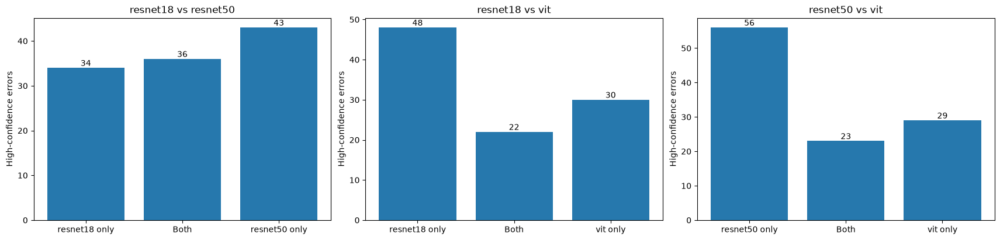

In [17]:
error_ids = [high_confidence_wrong[name] for name in model_names]
shared, union = error_ids[0].copy(), error_ids[0].copy()
for ids in error_ids[1:]:
    shared, union = np.intersect1d(shared, ids), np.union1d(union, ids)
print('Errors shared by all three:', len(shared), 'test IDs:', shared.tolist())
pair_overlap = np.zeros((len(model_names), len(model_names)), dtype=int)
pair_jaccard = np.full_like(pair_overlap, np.nan, dtype=float)
fig, axes = plt.subplots(1, len(pairs), figsize=(17, 4), layout='constrained')
for ax, (i, j) in zip(axes, pairs):
    common, combined = np.intersect1d(error_ids[i], error_ids[j]), np.union1d(error_ids[i], error_ids[j])
    pair_overlap[i, j] = pair_overlap[j, i] = len(common)
    pair_jaccard[i, j] = pair_jaccard[j, i] = len(common) / len(combined) if len(combined) else np.nan
    fractions = [len(common) / len(error_ids[m]) if len(error_ids[m]) else np.nan for m in (i, j)]
    print(f'{model_names[i]} / {model_names[j]}: shared {len(common)}, fractions {fractions[0]:.1%} / {fractions[1]:.1%}, Jaccard {pair_jaccard[i, j]:.1%}')
    if len(common):
        print(f'Same wrong class among shared errors: {(predicted[i, common] == predicted[j, common]).mean():.1%}')
    counts = [len(error_ids[i]) - len(common), len(common), len(error_ids[j]) - len(common)]
    ax.bar([f'{model_names[i]} only', 'Both', f'{model_names[j]} only'], counts)
    ax.bar_label(ax.containers[0])
    ax.set(ylabel='High-confidence errors', title=f'{model_names[i]} vs {model_names[j]}')
for m, ids in enumerate(error_ids):
    pair_overlap[m, m], pair_jaccard[m, m] = len(ids), 1 if len(ids) else np.nan
plt.show()


Compare pairwise high-confidence-error counts together with Jaccard overlap, which accounts for different cohort sizes. ResNet18 and ResNet50 share 36 errors with 31.9% Jaccard overlap, versus 22 and 23 errors and about 21–22% overlap for the CNN–ViT pairs. The CNNs share more of their confident failures, but their non-shared errors also show that the checkpoints are not interchangeable.

## True class → wrong predicted class — counts and percentages within each model's high-confidence errors, not class-specific error rates

resnet18: immature granulocytes → monocyte: 13/70 (18.6%)
resnet18: immature granulocytes → neutrophil: 11/70 (15.7%)
resnet18: neutrophil → immature granulocytes: 9/70 (12.9%)
resnet18: immature granulocytes → lymphocyte: 6/70 (8.6%)
resnet18: monocyte → immature granulocytes: 5/70 (7.1%)
resnet50: monocyte → immature granulocytes: 12/79 (15.2%)
resnet50: neutrophil → immature granulocytes: 11/79 (13.9%)
resnet50: immature granulocytes → monocyte: 10/79 (12.7%)
resnet50: immature granulocytes → neutrophil: 10/79 (12.7%)
resnet50: basophil → immature granulocytes: 5/79 (6.3%)
vit: monocyte → immature granulocytes: 9/52 (17.3%)
vit: immature granulocytes → monocyte: 8/52 (15.4%)
vit: neutrophil → immature granulocytes: 8/52 (15.4%)
vit: basophil → immature granulocytes: 7/52 (13.5%)
vit: immature granulocytes → neutrophil: 6/52 (11.5%)


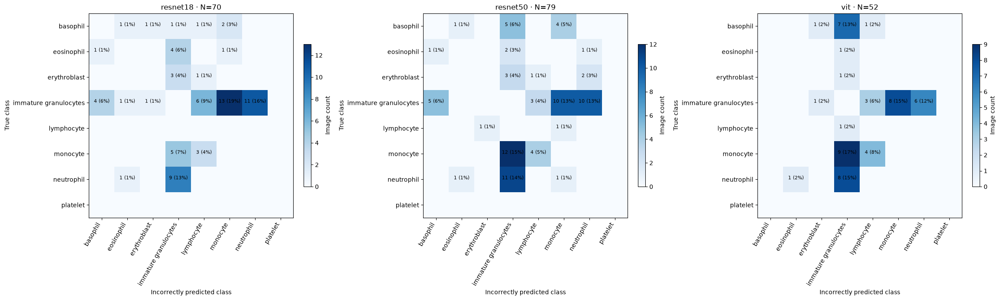

In [18]:
confusions, example_ids = [], []
fig, axes = plt.subplots(1, len(model_names), figsize=(23, 7), layout='constrained')
for m, (ax, ids) in enumerate(zip(axes, error_ids)):
    matrix = np.zeros((8, 8), dtype=int)
    np.add.at(matrix, (labels[ids], predicted[m, ids]), 1)
    confusions.append(matrix)
    im = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=max(matrix.max(), 1))
    ax.set(title=f'{model_names[m]} · N={len(ids)}', xlabel='Incorrectly predicted class', ylabel='True class',
           xticks=range(8), xticklabels=class_names, yticks=range(8), yticklabels=class_names)
    plt.setp(ax.get_xticklabels(), rotation=60, ha='right')
    for c, d in zip(*np.nonzero(matrix)):
        ax.text(d, c, f'{matrix[c, d]} ({matrix[c, d] / len(ids):.0%})', ha='center', fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.6, label='Image count')
    pairs = np.dstack(np.unravel_index(np.argsort(-matrix.ravel(), kind='stable'), matrix.shape))[0]
    pairs = [(c, d) for c, d in pairs if matrix[c, d] > 0]
    for c, d in pairs[:5]:
        print(f'{model_names[m]}: {class_names[c]} → {class_names[d]}: {matrix[c, d]}/{len(ids)} ({matrix[c, d] / len(ids):.1%})')
    example_ids.append(np.array([ids[np.flatnonzero((labels[ids] == c) & (predicted[m, ids] == d))[0]] for c, d in pairs[:3]], dtype=int))
plt.show()

Read the true-to-predicted class counts to identify recurring substitutions, without treating them as per-class error rates. Immature granulocytes occur on either side of 58/70 ResNet18 error pairs, 61/79 ResNet50 pairs and 45/52 ViT pairs. These failures concentrate around particular class competitions, while the later class-rate view is needed to separate that concentration from class frequency.

## Simple RGB features — boundary gradient energy is only a proxy for edge content, not cell location or segmentation

In [19]:
rgb = images.astype(float) / 255
luminance = rgb @ np.array([0.299, 0.587, 0.114])
maximum, minimum = rgb.max(-1), rgb.min(-1)
saturation = np.divide(maximum - minimum, maximum, out=np.zeros_like(maximum), where=maximum > 0)
gy, gx = np.gradient(luminance, axis=(1, 2))
energy = np.hypot(gx, gy)
border = np.ones((28, 28), dtype=bool)
border[4:-4, 4:-4] = False
boundary_energy = energy[:, border].sum(-1) / np.maximum(energy.sum((1, 2)), 1e-12)
features = np.column_stack((luminance.mean((1, 2)), saturation.mean((1, 2)),
                            rgb.mean((1, 2)), luminance.std((1, 2)), boundary_energy))
feature_names = ['Mean brightness', 'Mean saturation', 'Mean red', 'Mean green', 'Mean blue',
                 'Luminance contrast (std)', 'Boundary gradient fraction']
control_weights, feature_effects = [], []
for m, ids in enumerate(error_ids):
    weights = np.zeros(len(labels))
    for c in range(8):
        mask = correct[m] & (labels == c)
        if mask.any() and len(ids):
            weights[mask] = (labels[ids] == c).mean() / mask.sum()
    control_weights.append(weights)
    if not len(ids):
        feature_effects.append(np.full(len(feature_names), np.nan))
        continue
    mean = np.average(features, axis=0, weights=weights)
    std = np.sqrt(np.average((features - mean) ** 2, axis=0, weights=weights))
    effects = (features[ids].mean(0) - mean) / np.maximum(std, 1e-12)
    feature_effects.append(effects)

def plot_feature_comparison(m):
    ids = error_ids[m]
    weights, effects = control_weights[m], feature_effects[m]
    fig, axes = plt.subplots(2, 4, figsize=(16, 7), layout='constrained')
    for j, ax in enumerate(axes.flat[:7]):
        edges = np.linspace(features[:, j].min(), features[:, j].max() + 1e-12, 16)
        ax.hist(features[:, j], bins=edges, weights=weights, histtype='step', linewidth=2, label='Correct, class-matched weights')
        ax.hist(features[ids, j], bins=edges, weights=np.full(len(ids), 1 / len(ids)),
                histtype='step', linewidth=2, label='High-confidence errors')
        ax.set(title=feature_names[j], ylabel='Fraction within group')
    axes[0, 0].legend(fontsize=7)
    axes[1, 3].barh(feature_names, effects)
    axes[1, 3].axvline(0, color='gray')
    axes[1, 3].set(title='Error minus correct mean', xlabel='Correct-control standard deviations')
    fig.suptitle(f'{model_names[m]} — correct controls weighted to the error group’s true-class proportions')
    plt.show()

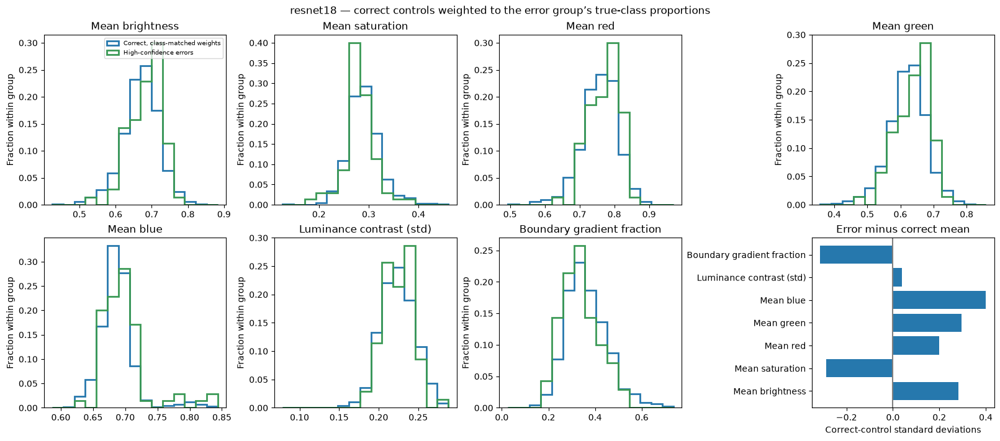

In [20]:
plot_feature_comparison(0)

Compare the feature distributions and standardized effects for ResNet18 errors against correct controls with the same true-class proportions. Errors have higher blue values by 0.40 control SD and lower saturation by 0.29 SD, with substantial overlap between groups. These are appearance associations worth testing, not features that explain or detect every error.

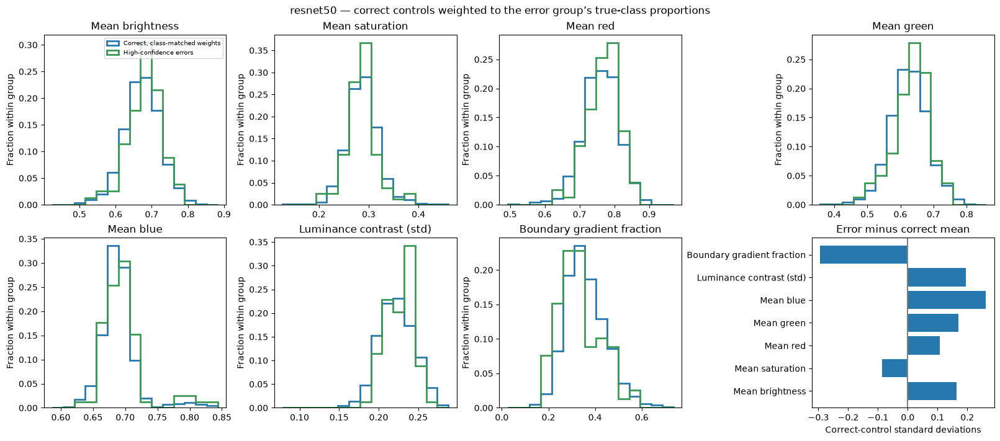

In [21]:
plot_feature_comparison(1)

Look for features that shift consistently between ResNet50 errors and class-weighted correct controls rather than isolated extreme images. Errors have modestly higher blue values by 0.26 control SD and lower boundary gradient fraction by 0.29 SD, without clear separation. The result suggests overlapping appearance differences, not a single error signature or evidence that an annotated cell lies near the border.

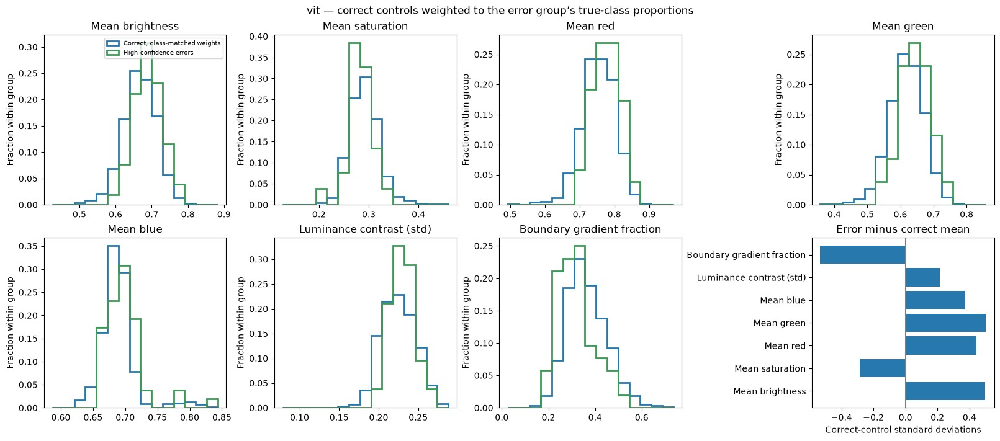

In [22]:
plot_feature_comparison(2)

Compare ViT error/control feature shifts after accounting for their true-class proportions. Errors are brighter by 0.50 control SD and have lower boundary gradient energy by 0.53 SD, while the distributions still overlap. Several related appearance properties may contribute to this association, so the pattern motivates controlled interventions rather than identifying an internal model mechanism.

## Nearest-image matches for the controlled galleries — raw RGB distance, restricted to the relevant true or predicted class

In [23]:
flat = rgb.reshape(len(images), -1).astype(np.float32)
squared = np.square(flat).sum(-1)
neighbor_ids, neighbor_rmse = [], []
for m, ids in enumerate(error_ids):
    distances = np.maximum(squared[:, None] + squared[ids][None, :] - 2 * flat @ flat[ids].T, 0) / flat.shape[1]
    matches, rmses = [], []
    for target in [labels[ids], predicted[m, ids]]:
        allowed = correct[m, :, None] & (confidence[m, :, None] >= threshold) & (labels[:, None] == target[None, :])
        assert allowed.any(axis=0).all(), 'No correct comparison image in a requested class'
        nearest = np.where(allowed, distances, np.inf).argmin(axis=0)
        matches.append(nearest)
        rmses.append(np.sqrt(distances[nearest, np.arange(len(ids))]))
    neighbor_ids.append(np.stack(matches))
    neighbor_rmse.append(np.stack(rmses))


## Load models for interventions — no training; saturation and occlusion act on original 28 × 28 RGB images

In [24]:
import torch
from PIL import Image, ImageEnhance
from transformers import ViTForImageClassification, ViTImageProcessor
from torchvision.models import resnet18
from models.resnet18.models import ResNet50

torch.manual_seed(42)
torch.backends.cudnn.benchmark = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
batch_size = 32
models = [resnet18(weights=None, num_classes=8), ResNet50(in_channels=3, num_classes=8)]
checkpoints = ['weights_bloodmnist/resnet18_224_1.pth', 'weights_bloodmnist/resnet50_28_1.pth', 'models/vit']
for model, path in zip(models, checkpoints):
    model.load_state_dict(torch.load(path, map_location='cpu', weights_only=True)['net'])
models.append(ViTForImageClassification.from_pretrained('models/vit', local_files_only=True))
models = [model.to(device).eval() for model in models]
processor = ViTImageProcessor.from_pretrained('models/vit', local_files_only=True)

@torch.inference_mode()
def predict(m, images):
    probabilities, scores = [], []
    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size]
        if model_names[m] != 'vit':
            x = torch.from_numpy(batch.copy()).permute(0, 3, 1, 2).to(device).float()
            if model_names[m] == 'resnet18':
                x = torch.nn.functional.interpolate(x, size=(224, 224), mode='nearest')
            logits = models[m]((x / 255 - 0.5) / 0.5)
        else:
            inputs = processor(images=list(batch), return_tensors='pt').to(device)
            logits = models[m](**inputs).logits
        probabilities.append(logits.softmax(-1).cpu().numpy())
        scores.append(logits.cpu().numpy())
    return np.concatenate(probabilities), np.concatenate(scores)

def intervention_predict(m, batch_images):
    return predict(m, batch_images)[0]

for m, ids in enumerate(error_ids):
    if len(ids):
        np.testing.assert_allclose(intervention_predict(m, images[ids]), probabilities[m, ids], atol=1e-5, rtol=1e-4)


## Saturation intervention — HC errors versus nearest same-class correct ≥90%-confident controls; repeated controls are not independent samples

In [25]:
saturation_levels = np.linspace(0.5, 1.5, 11)
saturation_results, saturation_ids = [], []
saturation_cache = {}
if Path('predictions/high_confidence_error_analysis.npz').exists():
    with np.load('predictions/high_confidence_error_analysis.npz', allow_pickle=False) as saved:
        if np.array_equal(saved['baseline_probabilities'], probabilities) and np.array_equal(saved['saturation_levels'], saturation_levels):
            for m, name in enumerate(model_names):
                selected = np.stack((error_ids[m], neighbor_ids[m][0]))
                if np.array_equal(saved[f'{name}_saturation_ids'], selected):
                    saturation_cache[m] = saved[f'{name}_saturation_probabilities']
for m, ids in enumerate(error_ids):
    selected = np.stack((ids, neighbor_ids[m][0]))
    saturation_ids.append(selected)
    if not len(ids):
        saturation_results.append(np.empty((2, 11, 0, 8)))
        continue
    if m in saturation_cache:
        saturation_results.append(saturation_cache[m])
        continue
    inputs = images[selected.ravel()]
    values = []
    for level in saturation_levels:
        changed = np.stack([np.asarray(ImageEnhance.Color(Image.fromarray(image)).enhance(float(level))) for image in inputs])
        values.append(intervention_predict(m, changed).reshape(2, len(ids), 8))
    p = np.stack(values, axis=1)
    saturation_results.append(p)
    np.testing.assert_allclose(p[:, 5], probabilities[m, selected], atol=1e-5, rtol=1e-4)


def plot_saturation(m):
    ids, selected, p = error_ids[m], saturation_ids[m], saturation_results[m]
    original = probabilities[m, selected].argmax(-1)
    retained = np.take_along_axis(p, original[:, None, :, None], axis=-1)[..., 0]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')
    for role, name in enumerate(['HC errors', 'Matched correct controls']):
        axes[0, 0].plot(saturation_levels, retained[role].mean(-1), 'o-', label=name)
        axes[0, 1].plot(saturation_levels, (p[role].argmax(-1) == labels[selected[role]]).mean(-1), 'o-', label=name)
        distribution = np.stack([(p[role].argmax(-1) == c).mean(-1) for c in range(8)])
        im = axes[1, role].imshow(distribution, vmin=0, vmax=1, cmap='Blues', aspect='auto')
        axes[1, role].set(title=name, yticks=range(8), yticklabels=class_names,
                          xticks=[0, 5, 10], xticklabels=['0.5', '1.0', '1.5'], xlabel='Saturation factor')
    axes[0, 0].set(title='Support for each original decision', ylabel='Mean probability')
    axes[0, 1].set(title='Fraction selecting the recorded true class', ylabel='Fraction')
    for ax in axes[0]:
        ax.axvline(1, color='gray', ls='--')
        ax.set_xlabel('Saturation factor')
        ax.legend(fontsize=8)
    fig.colorbar(im, ax=axes[1], label='Fraction assigned to each class')
    fig.suptitle(f'{model_names[m]} · same-class paired cohorts · N={len(ids)}')
    plt.show()


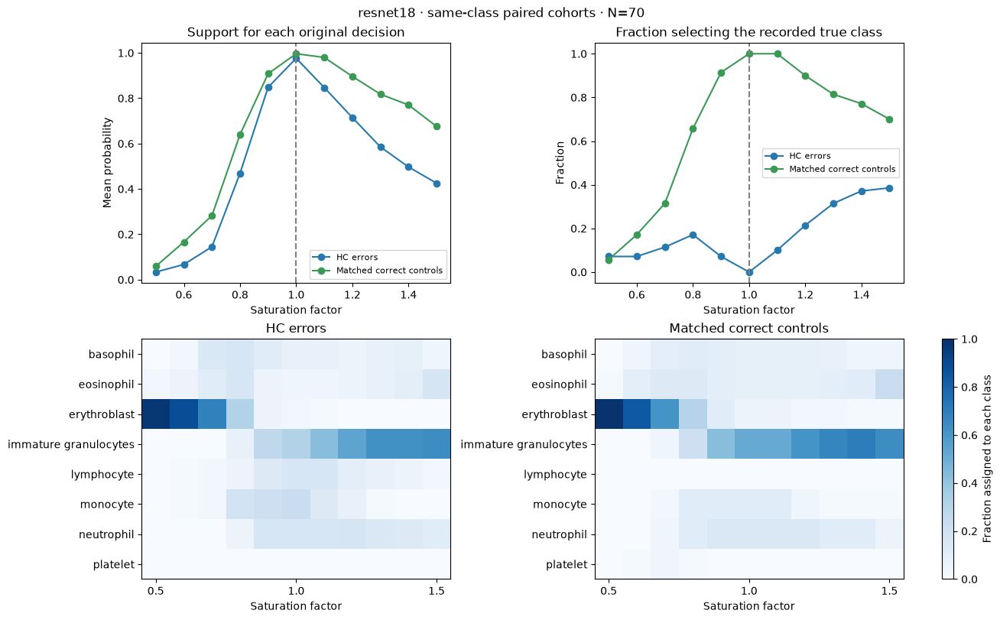

In [26]:
plot_saturation(0)

Compare the destination-class distributions of errors and matched correct controls as saturation decreases. At saturation ×0.5, ResNet18 assigns erythroblast to 68/70 error images and 69/70 controls despite their different original decisions. This shared class collapse indicates dependence on saturation-related appearance, not an effect specific to originally wrong images.

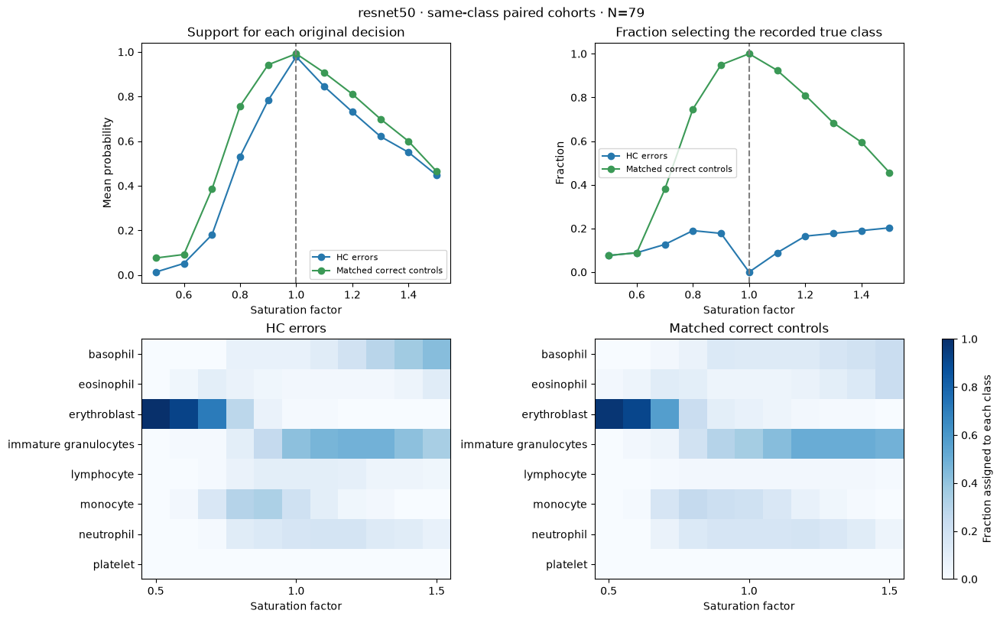

In [27]:
plot_saturation(1)

Check whether desaturation sends ResNet50 errors and same-class correct controls toward the same destination class. At saturation ×0.5, all 79 errors and 77/79 controls are assigned to erythroblast. Because the cohorts have identical true-class composition, this convergence indicates a color-dependent class-attractor response rather than a selective correction of the original errors.

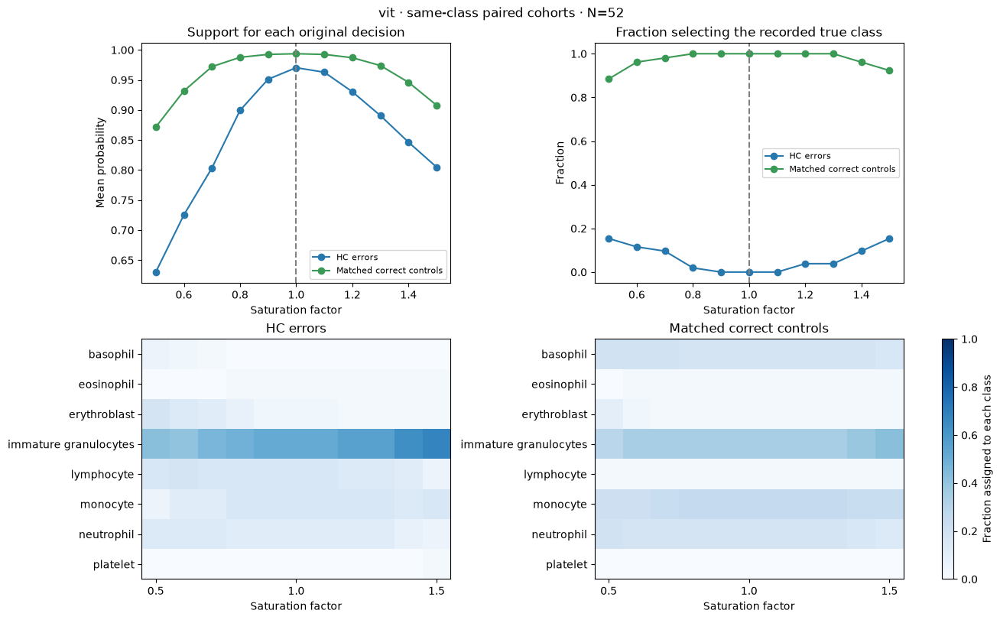

In [28]:
plot_saturation(2)

Compare ViT’s original-decision probability curves for errors and controls alongside the destination-class distributions. At saturation ×0.5, original-decision support drops by 0.340 for errors versus 0.122 for controls, without the near-complete erythroblast collapse seen in the CNNs. ViT therefore shows more error-specific saturation dependence in these cohorts, although the intervention does not identify which internal feature caused the original mistakes.

## Model-wide occlusion — all 3,421 test images, all classes and confidence levels

Each model receives the same 49 gray 4×4 patches before its usual preprocessing. The original predicted class is held fixed when measuring probability loss. Accuracy change uses the complete test population; the high-confidence-error analysis below is a separate conditional view.

In [29]:
import hashlib
from numpy.lib.format import open_memmap

patch_size = 4
positions = np.array([(y, x) for y in range(0, 28, patch_size) for x in range(0, 28, patch_size)])
files = [*checkpoints[:2], 'models/vit/model.safetensors', 'models/vit/config.json', 'models/vit/preprocessor_config.json']
weight_hashes = [hashlib.sha256(Path(path).read_bytes()).hexdigest() for path in files]
signature = hashlib.sha256(images.tobytes() + labels.tobytes() + probabilities.tobytes() + positions.tobytes()
                           + str(weight_hashes).encode() + b'gray128_resnet18-nearest224_resnet50-28_vit-local_v1').hexdigest()
population_path = Path('predictions/occlusion_test.npz')
if not population_path.exists():
    cache = Path('outputs/occlusion_test_v1')
    cache.mkdir(parents=True, exist_ok=True)
    lock = cache / 'signature.txt'
    assert not lock.exists() or lock.read_text() == signature, 'Inputs changed: use a new cache directory.'
    lock.write_text(signature)
    arrays = []
    for filename, shape, dtype in [('probabilities.npy', (3, 49, len(images), 8), 'float32'),
                                    ('logits.npy', (3, 49, len(images), 8), 'float32'), ('done.npy', (3, 49), 'bool')]:
        path = cache / filename
        fresh = not path.exists()
        array = open_memmap(path, mode='w+' if fresh else 'r+', dtype=dtype, shape=shape)
        if fresh and dtype == 'bool':
            array[:] = False
            array.flush()
        arrays.append(array)
    population_p, population_logits, done = arrays
    for m, name in enumerate(model_names):
        np.testing.assert_allclose(predict(m, images[:64])[0], probabilities[m, :64], atol=1e-5, rtol=1e-4)
        for j, (y, x) in enumerate(positions):
            if done[m, j]:
                continue
            changed = images.copy()
            changed[:, y:y + patch_size, x:x + patch_size] = 128
            population_p[m, j], population_logits[m, j] = predict(m, changed)
            population_p.flush()
            population_logits.flush()
            done[m, j] = True
            done.flush()
        print(f'{name}: all {len(images)} test images × 49 patch positions completed')
    np.savez_compressed(population_path, probabilities=population_p, logits=population_logits,
                        sample_index=np.arange(len(images)), labels=labels, baseline_probabilities=probabilities,
                        model_names=model_names, checkpoints=checkpoints, weight_hashes=weight_hashes,
                        class_names=class_names, positions=positions, patch_size=patch_size, fill_rgb=[128]*3,
                        signature=signature, split='test', axes=['model', 'patch', 'image', 'class'])
with np.load(population_path, allow_pickle=False) as saved:
    assert str(saved['signature']) == signature, 'Cached experiment does not match current inputs.'
    population_p = saved['probabilities']
print(f'Model-wide occlusion: {len(images)} shared test images per model; no confidence filtering')


Model-wide occlusion: 3421 shared test images per model; no confidence filtering


In [30]:
population_prediction = population_p.argmax(-1)
population_original = np.take_along_axis(population_p, predicted[:, None, :, None], axis=-1)[..., 0]
population_drop = (confidence[:, None] - population_original).transpose(0, 2, 1).reshape(3, len(labels), 7, 7)
population_correct = population_prediction == labels
population_before = predicted == labels
population_maps = {
    'Original-decision probability drop': population_drop.mean(1),
    'Label flip fraction': (population_prediction != predicted[:, None]).mean(-1).reshape(3, 7, 7),
    'Accuracy change (percentage points)': 100 * (population_correct.mean(-1) - population_before.mean(-1)[:, None]).reshape(3, 7, 7),
}
population_class_drop = np.stack([population_drop[:, labels == c].mean(1) for c in range(8)], axis=1)
population_group_difference = np.full((3, 8, 7, 7), np.nan)
population_group_counts = np.zeros((3, 8, 2), dtype=int)
for m in range(3):
    for c in range(8):
        right = (labels == c) & population_before[m]
        wrong = (labels == c) & ~population_before[m]
        population_group_counts[m, c] = [wrong.sum(), right.sum()]
        if wrong.any() and right.any():
            population_group_difference[m, c] = population_drop[m, wrong].mean(0) - population_drop[m, right].mean(0)

def plot_population_overview():
    fig, axes = plt.subplots(3, 3, figsize=(13, 11), layout='constrained')
    for col, (title, maps) in enumerate(population_maps.items()):
        signed = col != 1
        scale = max(np.abs(maps).max(), 0.01)
        for m, ax in enumerate(axes[:, col]):
            im = ax.imshow(maps[m], cmap='RdBu_r' if signed else 'viridis', vmin=-scale if signed else 0, vmax=scale)
            ax.set(title=f'{model_names[m]} · {title}', xticks=[], yticks=[])
        fig.colorbar(im, ax=axes[:, col], shrink=0.7)
    fig.suptitle('Model-wide occlusion · all 3,421 test images · same 49 gray patches for every model')
    plt.show()

def plot_population_classes(difference=False):
    maps = population_group_difference if difference else population_class_drop
    limit = max(np.nanmax(np.abs(maps)), 0.01)
    fig, axes = plt.subplots(3, 8, figsize=(23, 10), layout='constrained')
    for m in range(3):
        for c, ax in enumerate(axes[m]):
            im = ax.imshow(maps[m, c], cmap='RdBu_r', vmin=-limit, vmax=limit)
            count = f'wrong/right: {population_group_counts[m, c, 0]}/{population_group_counts[m, c, 1]}' if difference else f'N={(labels == c).sum()}'
            ax.set(title=f'{class_names[c]} · {count}', xticks=[], yticks=[])
            if difference and not np.isfinite(maps[m, c]).any():
                ax.text(0.5, 0.5, 'No initial errors', ha='center', transform=ax.transAxes)
        axes[m, 0].set_ylabel(model_names[m])
    fig.colorbar(im, ax=axes, shrink=0.7, label='Wrong minus correct decision-support drop' if difference else 'Mean original-decision probability drop')
    fig.suptitle('Within-class comparison: initially wrong minus initially correct' if difference else 'All test images, grouped by true class')
    plt.show()


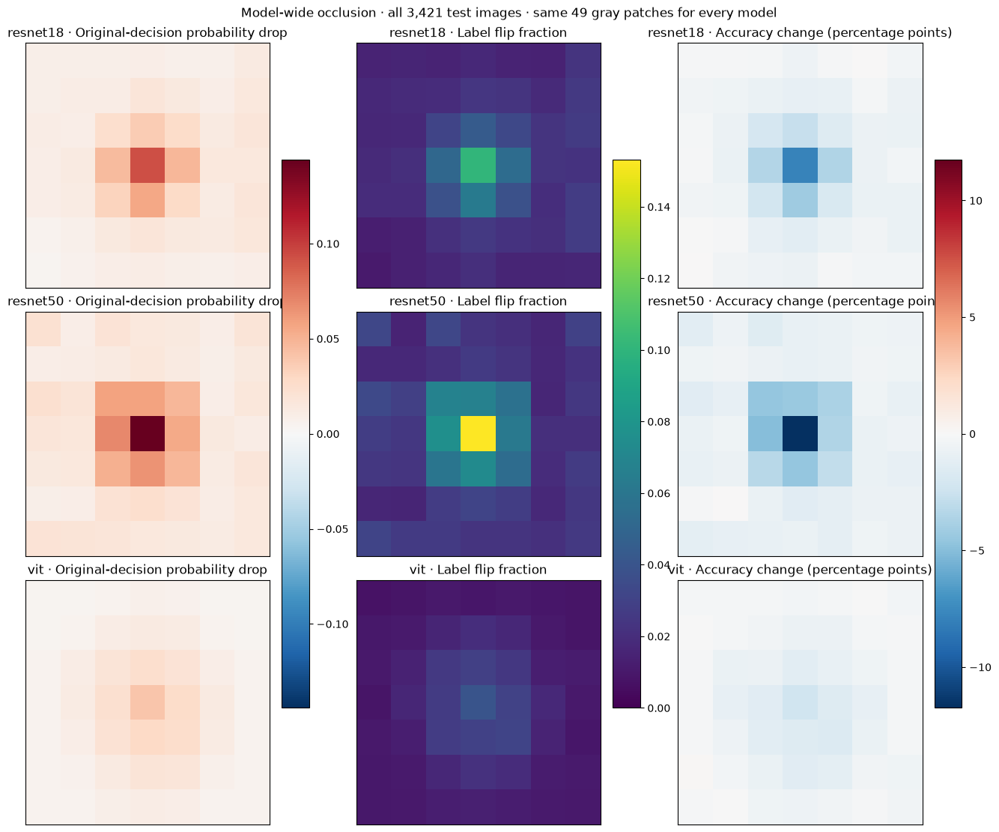

In [31]:
plot_population_overview()

Compare central and outer patches in the original-decision probability maps, using accuracy change separately to assess net correctness. Central/outer mean drops are 0.043/0.011 for ResNet18, 0.066/0.015 for ResNet50 and 0.025/0.008 for ViT. All models depend more on central image content, but these fixed coordinates in centered crops do not identify a nucleus or an attention mechanism.

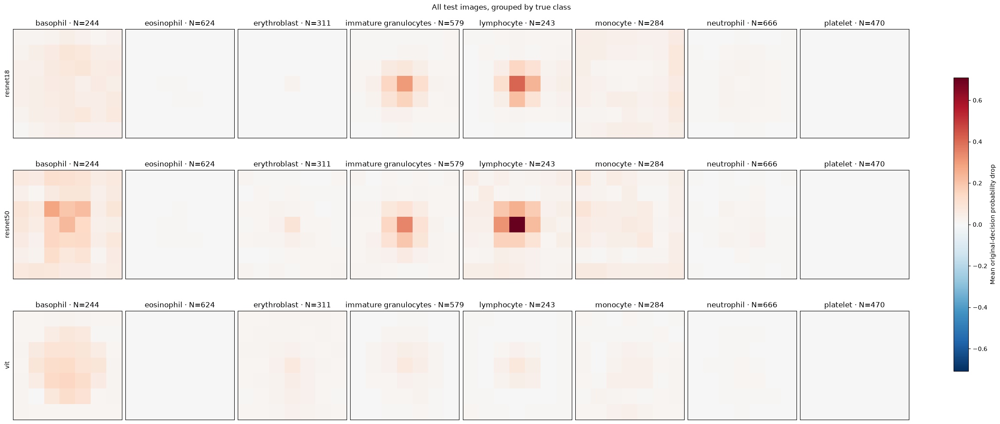

In [32]:
plot_population_classes()

Compare patch responses between true-class rows within each model, with each row averaged over its own images. ResNet50’s mean probability drop is 0.085 for basophils versus 0.009 for neutrophils, with almost no change for platelets. The population average therefore combines class-specific spatial dependencies rather than one common occlusion response.

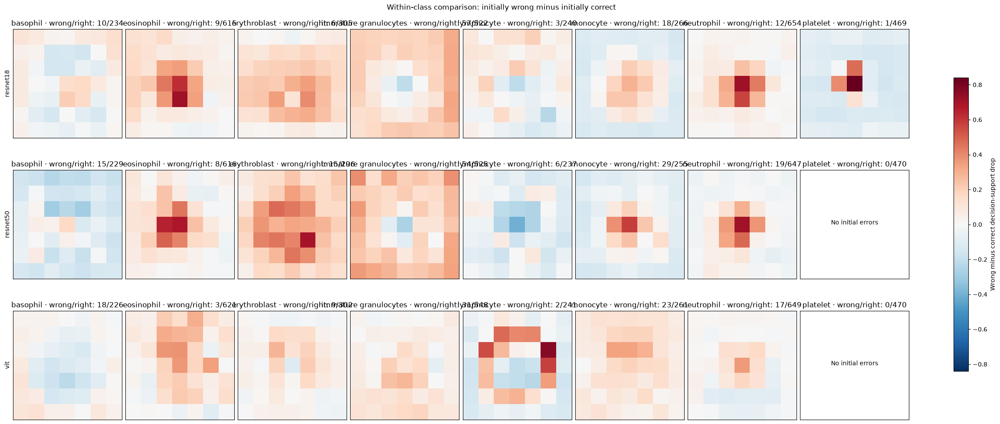

In [33]:
plot_population_classes(difference=True)

Read positive wrong-minus-correct probability-drop values as stronger dependence among original errors within the same true class. ResNet50’s central contrast is +0.212 for monocytes but −0.088 for basophils. Error-related spatial dependence therefore differs by class rather than increasing uniformly, and the matched HC comparison below checks a subgroup with more comparable starting confidence.

## High-confidence-error occlusion — conditional subgroup only; the model-wide population analysis is above

In [34]:
# Reuse the full-test predictions, retaining the original subgroup data format.
patch_size = 4
positions = np.array([(y, x) for y in range(0, 28, patch_size) for x in range(0, 28, patch_size)])
occlusion_results, occlusion_drop = [], []
for m, ids in enumerate(error_ids):
    p = population_p[m][:, ids].copy()
    occlusion_results.append(p)
    target = np.take_along_axis(p, predicted[m, ids][None, :, None], axis=-1)[..., 0]
    occlusion_drop.append((confidence[m, ids][None] - target).T.reshape(len(ids), 7, 7))


## Occlusion aggregated by true class and model — all high-confidence errors; original-decision drop and paired error-minus-control contrast; N = images, not patches; fixed image coordinates are not aligned cell structures

In [35]:
occlusion_counts = np.zeros((len(model_names), 8), dtype=int)
occlusion_class_metrics = {name: np.full((len(model_names), 8, 7, 7), np.nan) for name in
                           ['Mean wrong-class probability drop', 'Mean absolute probability change', 'Fraction corrected']}
for m, ids in enumerate(error_ids):
    patch_predictions = occlusion_results[m].argmax(-1).T.reshape(len(ids), 7, 7)
    corrected = patch_predictions == labels[ids, None, None]
    for c in range(8):
        mask = labels[ids] == c
        occlusion_counts[m, c] = mask.sum()
        if mask.any():
            occlusion_class_metrics['Mean wrong-class probability drop'][m, c] = occlusion_drop[m][mask].mean(0)
            occlusion_class_metrics['Mean absolute probability change'][m, c] = np.abs(occlusion_drop[m][mask]).mean(0)
            occlusion_class_metrics['Fraction corrected'][m, c] = corrected[mask].mean(0)
            print(f'{model_names[m]} · {class_names[c]} · N={mask.sum()} · mean absolute effect={np.abs(occlusion_drop[m][mask]).mean():.3f} · correction fraction across patches={corrected[mask].mean():.1%}')

occlusion_matched_ids = [np.stack((ids, neighbor_ids[m][0])) for m, ids in enumerate(error_ids)]
paired = np.full((3, 8, 7, 7), np.nan)
for m, selected in enumerate(occlusion_matched_ids):
    for c in range(8):
        mask = labels[selected[0]] == c
        if mask.any():
            paired[m, c] = (population_drop[m, selected[0, mask]] - population_drop[m, selected[1, mask]]).mean(0)
occlusion_class_metrics['Error minus matched-control probability drop'] = paired

def plot_occlusion_summary(title):
    maps = occlusion_class_metrics[title]
    signed = title != 'Mean absolute probability change' and title != 'Fraction corrected'
    limit = 1 if title == 'Fraction corrected' else max(np.nanmax(np.abs(maps)), 0.01)
    fig, axes = plt.subplots(len(model_names), 8, figsize=(23, 3.5 * len(model_names)), layout='constrained')
    for m in range(len(model_names)):
        for c, ax in enumerate(axes[m]):
            if occlusion_counts[m, c]:
                im = ax.imshow(maps[m, c], cmap='RdBu_r' if signed else 'viridis',
                               vmin=-limit if signed else 0, vmax=limit)
            else:
                ax.set_facecolor('#eeeeee')
                ax.text(0.5, 0.5, 'No images', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(f'{class_names[c]} (N={occlusion_counts[m, c]})', fontsize=8, wrap=True)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[m, 0].set_ylabel(model_names[m])
    fig.colorbar(im, ax=axes, shrink=0.65, label=title)
    fig.suptitle(f'{title} — each square covers 4 × 4 pixels; small classes are descriptive, not reliable comparisons')
    plt.show()

resnet18 · basophil · N=6 · mean absolute effect=0.136 · correction fraction across patches=1.7%
resnet18 · eosinophil · N=6 · mean absolute effect=0.092 · correction fraction across patches=6.8%
resnet18 · erythroblast · N=4 · mean absolute effect=0.075 · correction fraction across patches=5.6%
resnet18 · immature granulocytes · N=36 · mean absolute effect=0.123 · correction fraction across patches=9.0%
resnet18 · monocyte · N=8 · mean absolute effect=0.061 · correction fraction across patches=4.1%
resnet18 · neutrophil · N=10 · mean absolute effect=0.072 · correction fraction across patches=6.1%
resnet50 · basophil · N=10 · mean absolute effect=0.075 · correction fraction across patches=0.6%
resnet50 · eosinophil · N=4 · mean absolute effect=0.103 · correction fraction across patches=5.1%
resnet50 · erythroblast · N=6 · mean absolute effect=0.136 · correction fraction across patches=12.6%
resnet50 · immature granulocytes · N=28 · mean absolute effect=0.147 · correction fraction acros

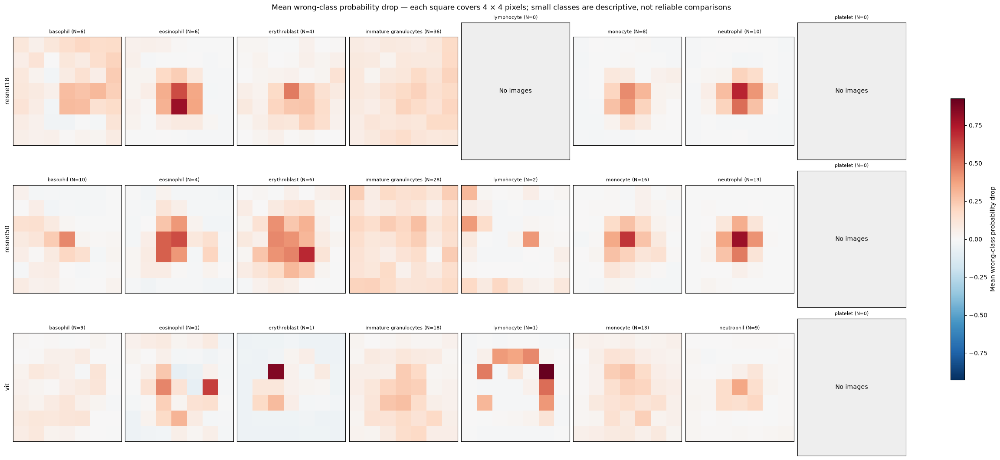

In [36]:
plot_occlusion_summary('Mean wrong-class probability drop')

Read larger positive values as a greater loss of support for the original wrong decision under that patch. Central mean drops among HC errors are 0.204 for ResNet18, 0.239 for ResNet50 and 0.156 for ViT. These maps localize support for wrong decisions, while the paired contrast below tests whether the same locations matter more than they do for correct decisions.

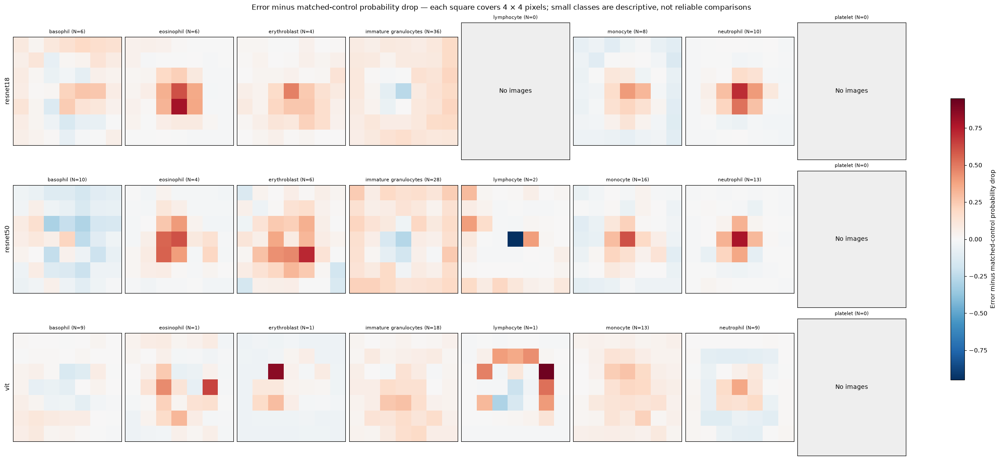

In [37]:
plot_occlusion_summary('Error minus matched-control probability drop')

Read positive error-minus-control values as locations where HC errors lose more original-decision support than their matched correct controls. The additional central drops are 0.104 for ResNet18, 0.098 for ResNet50 and 0.113 for ViT. HC errors therefore show stronger central dependence even after matching true class and the confidence threshold, although each image targets its own original decision and exact confidence is not matched.

## Save all high-confidence-error analysis data — all examples and all intervention probabilities, not just the displayed selections

In [38]:
analysis = dict(shared_indices=shared, union_indices=union, threshold=threshold, split='test',
                model_names=model_names, class_names=class_names, features=features, feature_names=feature_names,
                checkpoints=checkpoints, model_input_resolutions=[224, 28, 224],
                pair_overlap=pair_overlap, pair_jaccard=pair_jaccard,
                feature_sample_index=np.arange(len(labels)), true_labels=labels, baseline_probabilities=probabilities,
                control_weights=np.stack(control_weights), feature_effects=np.stack(feature_effects),
                saturation_levels=saturation_levels, occlusion_positions=positions, patch_size=patch_size,
                occlusion_fill_rgb=[128, 128, 128], neighbor_roles=['true_class', 'predicted_class'],
                saturation_roles=['high_confidence_errors', 'matched_correct_controls'],
                occlusion_class_counts=occlusion_counts, occlusion_grouping='true_class',
                **{f'occlusion_class_{name}': maps for name, maps in occlusion_class_metrics.items()})
for m, name in enumerate(model_names):
    for key, value in dict(error_ids=error_ids[m], confusion=confusions[m], selected_examples=example_ids[m],
                           neighbor_ids=neighbor_ids[m], neighbor_rmse=neighbor_rmse[m],
                           saturation_ids=saturation_ids[m], saturation_probabilities=saturation_results[m],
                           occlusion_probabilities=occlusion_results[m], occlusion_drop=occlusion_drop[m]).items():
        analysis[f'{name}_{key}'] = value
    if len(error_ids[m]):
        j = np.abs(feature_effects[m]).argmax()
        corrections = (saturation_results[m][0].argmax(-1) == labels[error_ids[m]]).sum(-1)
        print(f'{name}: largest descriptive feature shift: {feature_names[j]} ({feature_effects[m][j]:+.2f} control SD)')
        control_errors = (saturation_results[m][1].argmax(-1) != labels[saturation_ids[m][1]]).sum(-1)
        print('Saturation factor / corrected errors / newly wrong matched control pairs:', list(zip(saturation_levels.round(2).tolist(), corrections.tolist(), control_errors.tolist())))
        involved = ((labels[error_ids[m]] == 3) | (predicted[m, error_ids[m]] == 3)).sum()
        print(f'{name}: immature granulocytes occur on either side of {involved}/{len(error_ids[m])} error pairs')
        print(f'{name}: mean largest wrong-class probability drop per image under occlusion: {occlusion_drop[m].max((1, 2)).mean():.3f}')
path = Path('predictions/high_confidence_error_analysis.npz')
np.savez_compressed(path, **analysis)
print(path)
print('Hypotheses to investigate: appearance/staining sensitivity in a subset of errors; visual ambiguity around immature-granulocyte confusions. Saturation can also damage correct controls, so correction counts alone are not evidence of improvement.')
print('Exploratory only: correlated color features, class composition, pixel alignment, unequal neighbor-pool sizes and artificial interventions prevent causal or biological conclusions. Validate hypotheses on new images, not these selected errors.')

resnet18: largest descriptive feature shift: Mean blue (+0.40 control SD)
Saturation factor / corrected errors / newly wrong matched control pairs: [(0.5, 5, 66), (0.6, 5, 58), (0.7, 8, 48), (0.8, 12, 24), (0.9, 5, 6), (1.0, 0, 0), (1.1, 7, 0), (1.2, 15, 7), (1.3, 22, 13), (1.4, 26, 16), (1.5, 27, 21)]
resnet18: immature granulocytes occur on either side of 58/70 error pairs
resnet18: mean largest wrong-class probability drop per image under occlusion: 0.682
resnet50: largest descriptive feature shift: Boundary gradient fraction (-0.29 control SD)
Saturation factor / corrected errors / newly wrong matched control pairs: [(0.5, 6, 73), (0.6, 7, 72), (0.7, 10, 49), (0.8, 15, 20), (0.9, 14, 4), (1.0, 0, 0), (1.1, 7, 6), (1.2, 13, 15), (1.3, 14, 25), (1.4, 15, 32), (1.5, 16, 43)]
resnet50: immature granulocytes occur on either side of 61/79 error pairs
resnet50: mean largest wrong-class probability drop per image under occlusion: 0.761
vit: largest descriptive feature shift: Boundary gradi

## A · Shared and exclusive errors — all 39 shared errors; mark cases with ≥90% confidence in every model; class IDs listed below

Shared errors: 39 with ≥90% confidence in all models: 18
Classes: {0: np.str_('basophil'), 1: np.str_('eosinophil'), 2: np.str_('erythroblast'), 3: np.str_('immature granulocytes'), 4: np.str_('lymphocyte'), 5: np.str_('monocyte'), 6: np.str_('neutrophil'), 7: np.str_('platelet')}


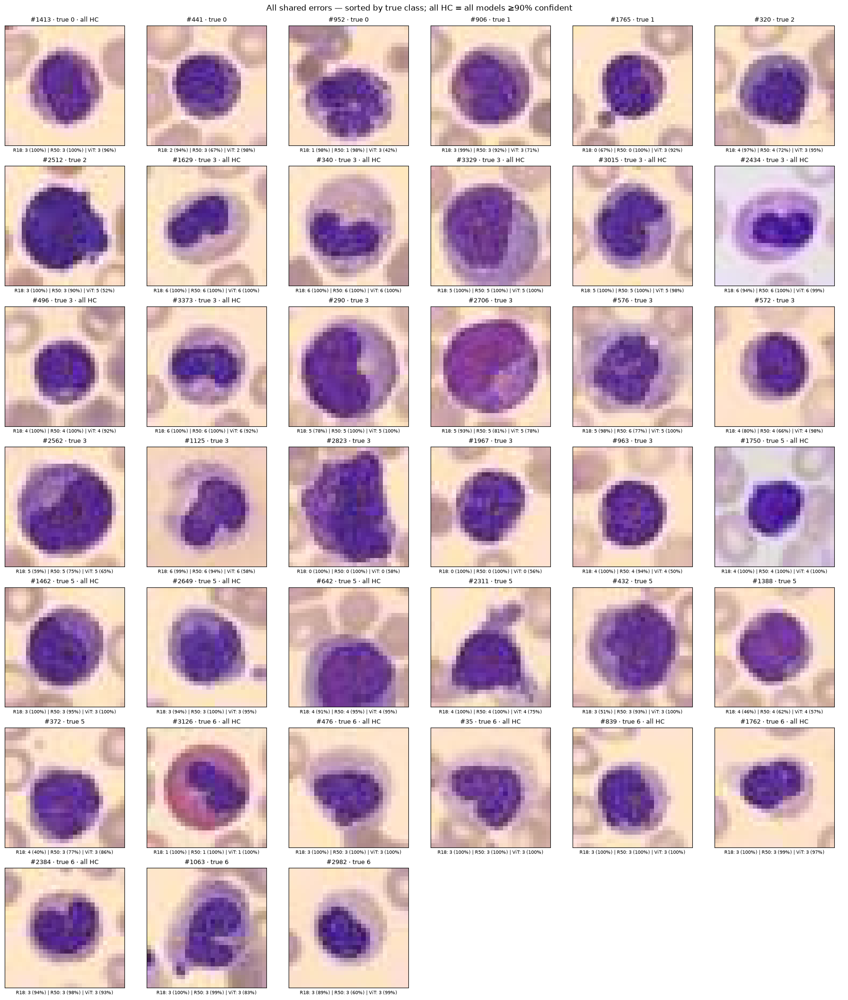

In [39]:
wrong = ~correct
high_wrong = wrong & (confidence >= threshold)
common_wrong = np.flatnonzero(wrong.all(0))
common_hc = np.flatnonzero(high_wrong.all(0))
exclusive_hc = [np.flatnonzero(high_wrong[m] & (wrong.sum(0) == 1)) for m in range(len(model_names))]
print('Shared errors:', len(common_wrong), 'with ≥90% confidence in all models:', len(common_hc))
print('Classes:', dict(enumerate(class_names)))

def gallery(ids, title, columns=6):
    rows = max(1, int(np.ceil(len(ids) / columns)))
    fig, axes = plt.subplots(rows, columns, figsize=(18, 3 * rows), squeeze=False, layout='constrained')
    for ax in axes.flat:
        ax.axis('off')
    for ax, i in zip(axes.flat, ids):
        ax.axis('on')
        ax.imshow(images[i])
        ax.set_title(f'#{i} · true {labels[i]}' + (' · all HC' if high_wrong[:, i].all() else ''), fontsize=9)
        ax.set_xlabel(' | '.join(f'{name}: {predicted[m, i]} ({confidence[m, i]:.0%})'
                                for m, name in enumerate(['R18', 'R50', 'ViT'])), fontsize=7, wrap=True)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(title)
    plt.show()

order = np.lexsort((-confidence[:, common_wrong].min(0), labels[common_wrong]))
gallery(common_wrong[order], 'All shared errors — sorted by true class; all HC = all models ≥90% confident')

Look for repeated wrong labels in the shared-error gallery, especially the images marked as highly confident in all models. All models misclassify 39 images, and the 18 shared HC errors receive the same wrong class from all three models, with nine substitutions between immature granulocytes and neutrophils. Agreement therefore leaves recurring class-specific blind spots rather than independently confirming the recorded label.

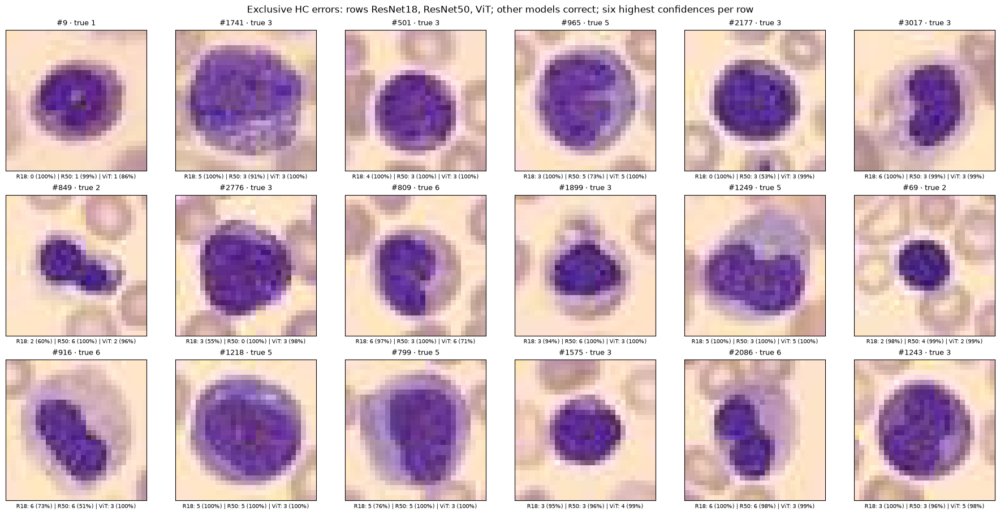

In [40]:
exclusive_examples = np.concatenate([ids[np.argsort(-confidence[m, ids], kind='stable')[:6]]
                                     for m, ids in enumerate(exclusive_hc)])
gallery(exclusive_examples, 'Exclusive HC errors: rows ResNet18, ResNet50, ViT; other models correct; six highest confidences per row')

Compare each row’s selected model with the other two models on the same images. The displayed high-confidence examples are wrong only for ResNet18, only for ResNet50 or only for ViT, while the other models classify them correctly. These exclusive failures show complementary behavior, but confidence-selected examples cannot establish that voting would resolve the shared errors.

## A · Matched images — errors beside similar same-class controls classified correctly with ≥90% confidence by every model

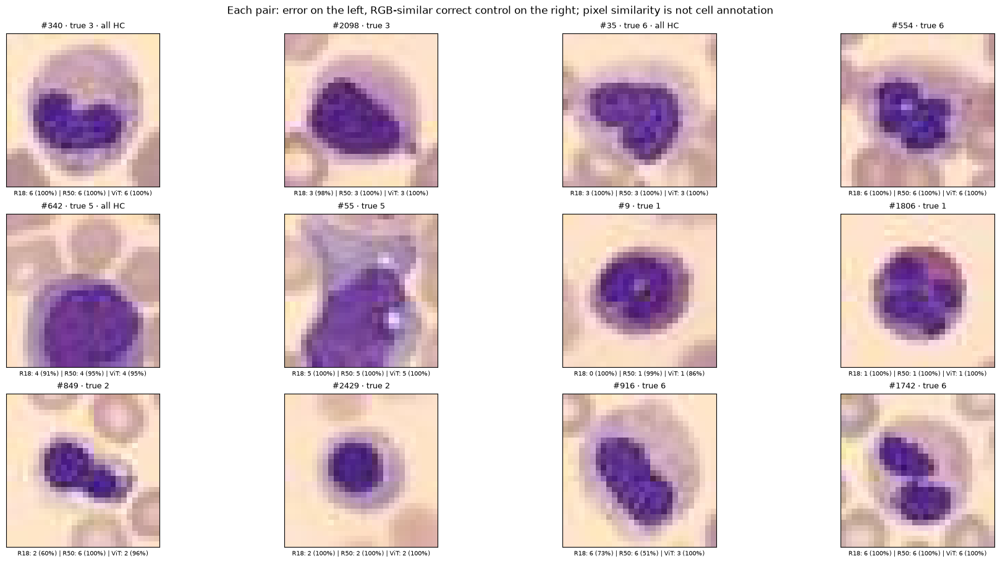

In [41]:
clean = correct.all(0) & (confidence >= threshold).all(0)
largest_classes = np.argsort(-np.bincount(labels[common_hc], minlength=8))[:3]
selected_errors = [common_hc[labels[common_hc] == c][0] for c in largest_classes if (labels[common_hc] == c).any()]
selected_errors += [ids[np.argmax(confidence[m, ids])] for m, ids in enumerate(exclusive_hc) if len(ids)]
gallery_pairs = []
for i in selected_errors:
    allowed = clean & (labels == labels[i])
    assert allowed.any()
    distance = squared + squared[i] - 2 * flat @ flat[i]
    control = np.where(allowed, distance, np.inf).argmin()
    gallery_pairs.append([i, control])
gallery_pairs = np.array(gallery_pairs)
gallery(gallery_pairs.ravel(), 'Each pair: error on the left, RGB-similar correct control on the right; pixel similarity is not cell annotation', columns=4)

Compare each error image with its RGB-near same-class control, using the class and confidence labels to track their different decisions. Pairs #340/#2098 and #35/#554 have similar broad color and layout despite opposite correctness outcomes. Overall appearance alone therefore does not explain every error, while alignment-sensitive RGB matching cannot replace expert assessment of cell structures.

## B · Hypotheses: class concentration and image features — error rate per true class; features versus class-matched controls correct and confident in every model

In [42]:
class_sizes = np.bincount(labels, minlength=8)
class_hc_counts = np.stack([np.bincount(labels[ids], minlength=8) for ids in error_ids])
class_hc_rates = class_hc_counts / class_sizes
cohorts = [common_hc, *exclusive_hc]
cohort_names = ['All three HC wrong', *[f'Only {name} HC wrong' for name in model_names]]
cohort_effects, cohort_weights = [], []
for ids in cohorts:
    weights = np.zeros(len(labels))
    for c in np.unique(labels[ids]):
        mask = clean & (labels == c)
        assert mask.any()
        weights[mask] = (labels[ids] == c).mean() / mask.sum()
    mean = np.average(features, axis=0, weights=weights)
    std = np.sqrt(np.average((features - mean) ** 2, axis=0, weights=weights))
    cohort_effects.append((features[ids].mean(0) - mean) / np.maximum(std, 1e-12))
    cohort_weights.append(weights)
cohort_effects = np.stack(cohort_effects)

def plot_class_rates():
    fig, ax = plt.subplots(figsize=(13, 4), layout='constrained')
    im = ax.imshow(class_hc_rates, cmap='Oranges', vmin=0, aspect='auto')
    ax.set(xticks=range(8), xticklabels=class_names, yticks=range(3), yticklabels=model_names)
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    for m in range(3):
        for c in range(8):
            ax.text(c, m, f'{class_hc_rates[m, c]:.1%} ({class_hc_counts[m, c]}/{class_sizes[c]})', ha='center', fontsize=8)
    fig.colorbar(im, ax=ax, label='Fraction of ≥90%-confident errors within each true class')
    plt.show()

def plot_shared_features():
    fig, ax = plt.subplots(figsize=(12, 5), layout='constrained')
    limit = max(np.abs(cohort_effects).max(), 0.01)
    im = ax.imshow(cohort_effects, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto')
    ax.set(xticks=range(7), xticklabels=feature_names, yticks=range(4),
           yticklabels=[f'{name} (N={len(ids)})' for name, ids in zip(cohort_names, cohorts)])
    plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
    for row in range(4):
        for col in range(7):
            ax.text(col, row, f'{cohort_effects[row, col]:+.2f}', ha='center')
    fig.colorbar(im, ax=ax, label='Error minus correct control, in control standard deviations')
    plt.show()

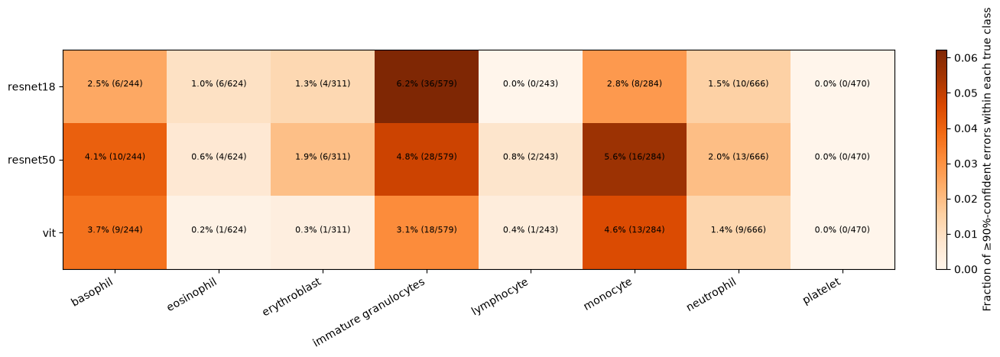

In [43]:
plot_class_rates()

Compare HC-error rates within each true class rather than raw error counts. ResNet18 reaches 6.22% for immature granulocytes versus 2.05% overall, while monocytes have the highest rates for ResNet50 and ViT at 5.63% and 4.58%. Class frequency alone therefore does not explain the error concentration, and the differing rankings indicate checkpoint-specific weaknesses.

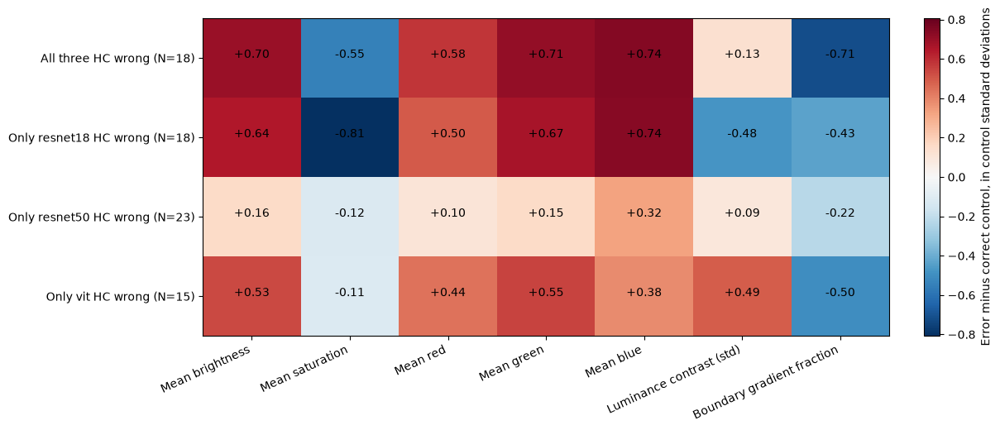

In [44]:
plot_shared_features()

Compare standardized feature shifts across shared and exclusive HC-error groups using class-matched confident correct controls. Shared errors are brighter by 0.70 control SD, have higher blue values by 0.74 SD and lower saturation by 0.55 SD, whereas exclusive groups have different profiles. There is no single appearance signature for all failures, so interventions should distinguish correlated brightness and color effects rather than attribute errors to one feature.

## PCA of all test images — aligned true/predicted-class views of the derived high-confidence-error cohort

In [45]:
pca_path = Path('predictions/test_pca.npz')
if not pca_path.exists():
    from pathlib import Path
    import hashlib
    import numpy as np
    from sklearn.decomposition import PCA
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.metrics import balanced_accuracy_score
    from threadpoolctl import threadpool_limits

    ROOT = Path('.')
    with np.load(ROOT/'data/bloodmnist.npz', allow_pickle=False) as z:
        images, labels = z['test_images'], z['test_labels'].ravel()
    with np.load(ROOT/'predictions/high_confidence_error_analysis.npz', allow_pickle=False) as z:
        probabilities, model_names, class_names = z['baseline_probabilities'], z['model_names'], z['class_names']
    anchor_pairs = gallery_pairs[:2]
    x = images.reshape(len(images), -1).astype(np.float32) / 255
    indices = np.arange(len(x))
    train, holdout = train_test_split(indices, test_size=0.25, random_state=42, stratify=labels)
    with threadpool_limits(limits=4):
        pca = PCA(n_components=2, svd_solver='randomized', random_state=42)
        xy = pca.fit_transform(x)
        validation_pca = PCA(n_components=2, svd_solver='randomized', random_state=42)
        validation_train = validation_pca.fit_transform(x[train])
        validation_holdout = validation_pca.transform(x[holdout])
        lower, upper = xy.min(0), xy.max(0)
        padding = (upper - lower) * 0.05
        gx, gy = np.meshgrid(np.linspace(lower[0]-padding[0],upper[0]+padding[0],160),
                             np.linspace(lower[1]-padding[1],upper[1]+padding[1],160))
        grid = np.column_stack((gx.ravel(),gy.ravel()))
        predicted = probabilities.argmax(-1)
        grid_labels, agreement, balanced_agreement, majority_agreement = [], [], [], []
        for m in range(len(model_names)):
            surrogate = KNeighborsClassifier(n_neighbors=25, weights='distance')
            surrogate.fit(validation_train, predicted[m, train])
            guesses = surrogate.predict(validation_holdout)
            agreement.append((guesses == predicted[m, holdout]).mean())
            balanced_agreement.append(balanced_accuracy_score(predicted[m, holdout], guesses))
            majority = np.bincount(predicted[m, train],minlength=8).argmax()
            majority_agreement.append((predicted[m, holdout] == majority).mean())
            surrogate.fit(xy, predicted[m])
            grid_labels.append(surrogate.predict(grid).reshape(gx.shape))
        # Suppress unsupported low-density regions rather than extrapolating across the full rectangle.
        density_threshold = np.quantile(surrogate.kneighbors(xy, n_neighbors=6)[0][:,5],0.95)
        support = surrogate.kneighbors(grid,n_neighbors=5)[0][:,4] <= density_threshold
        residual = x[anchor_pairs.ravel()] - pca.inverse_transform(xy[anchor_pairs.ravel()])
        np.testing.assert_allclose(pca.inverse_transform(xy[anchor_pairs.ravel()])+residual,
                                   x[anchor_pairs.ravel()], atol=1e-7)
    np.savez_compressed(ROOT/'predictions/test_pca.npz', coordinates=xy, components=pca.components_, mean=pca.mean_,
                        explained_variance=pca.explained_variance_, explained_variance_ratio=pca.explained_variance_ratio_,
                        sample_index=indices, labels=labels, model_names=model_names, class_names=class_names,
                        predicted_labels=predicted, probabilities=probabilities,
                        high_confidence_wrong=(predicted!=labels)&(probabilities.max(-1)>=0.9),
                        grid_x=gx, grid_y=gy, surrogate_regions=np.stack(grid_labels), support=support.reshape(gx.shape),
                        surrogate_agreement=agreement, surrogate_balanced_agreement=balanced_agreement,
                        majority_agreement=majority_agreement, train_indices=train, holdout_indices=holdout,
                        anchor_pairs=anchor_pairs, anchor_residual=residual, seed=42, n_neighbors=25,
                        input_sha256=hashlib.sha256(images.tobytes()).hexdigest(), split='test',
                        method='centered raw RGB [0,1]; no per-pixel standardization; randomized PCA',
                        validation='PCA and kNN refitted on training partition; held-out black-box-label agreement, not ground-truth accuracy')
    print('Explained variance:',pca.explained_variance_ratio_.tolist())
    for m,name in enumerate(model_names):
        print(name,'held-out surrogate agreement',round(float(agreement[m]),4),
              'balanced',round(float(balanced_agreement[m]),4),'majority',round(float(majority_agreement[m]),4))
    print('Anchor error/control pairs:',anchor_pairs.tolist())

with np.load(pca_path, allow_pickle=False) as saved:
    pca = {key:saved[key] for key in saved.files}
np.testing.assert_allclose(pca['probabilities'], probabilities, atol=1e-9)
np.testing.assert_array_equal(pca['labels'], labels)
for m, name in enumerate(model_names):
    print(name, 'held-out agreement / balanced agreement / majority baseline:',
          ' / '.join(f'{float(pca[key][m]):.2%}' for key in ['surrogate_agreement', 'surrogate_balanced_agreement', 'majority_agreement']))


resnet18 held-out agreement / balanced agreement / majority baseline: 58.29% / 53.85% / 19.63%
resnet50 held-out agreement / balanced agreement / majority baseline: 58.06% / 54.28% / 19.51%
vit held-out agreement / balanced agreement / majority baseline: 57.01% / 53.05% / 18.81%


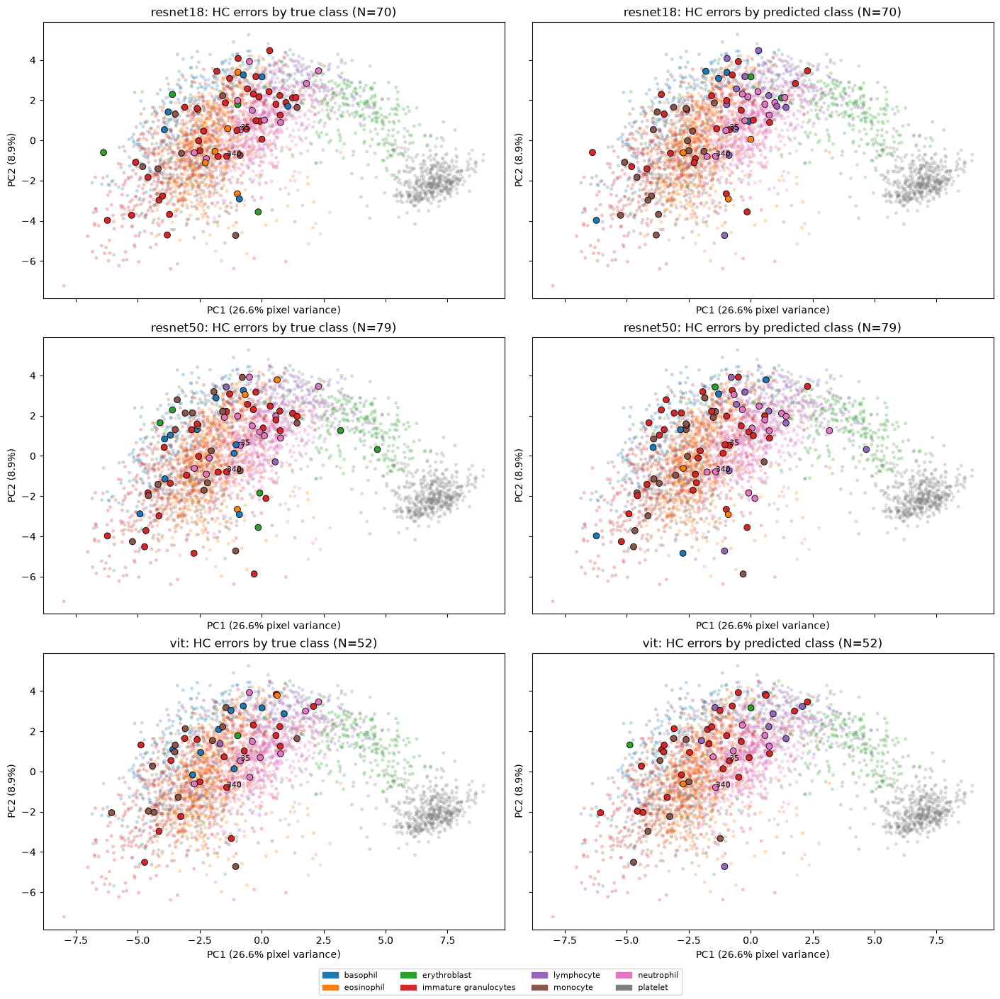

In [46]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
class_colors = plt.get_cmap('tab10')(np.arange(8))
class_cmap = ListedColormap(class_colors)
class_norm = BoundaryNorm(np.arange(9) - 0.5, 8)
xy = pca['coordinates']
fig, axes = plt.subplots(3, 2, figsize=(14, 14), sharex=True, sharey=True, layout='constrained')
for m, name in enumerate(model_names):
    ids = np.flatnonzero(pca['high_confidence_wrong'][m])
    for col, (title, colors) in enumerate([('True class', labels), ('Predicted class', predicted[m])]):
        ax = axes[m, col]
        ax.scatter(*xy.T, c=class_colors[colors], s=7, alpha=0.20)
        ax.scatter(*xy[ids].T, c=class_colors[colors[ids]], s=40, edgecolor='black', linewidth=0.6)
        for i in [340, 35]:
            if i in ids:ax.annotate(str(i), xy[i], fontsize=8)
        ax.set(title=f'{name}: HC errors by {title.lower()} (N={len(ids)})',
               xlabel=f'PC1 ({pca["explained_variance_ratio"][0]:.1%} pixel variance)',
               ylabel=f'PC2 ({pca["explained_variance_ratio"][1]:.1%})')
fig.legend(handles=[Patch(color=class_colors[c], label=class_names[c]) for c in range(8)],
           loc='outside lower center', ncol=4, fontsize=8)
plt.show()

Compare highlighted errors by true class on the left and predicted class on the right, keeping their shared PCA coordinates fixed. The first two PCs retain 35.6% of pixel variance, and PC1 correlates strongly with brightness at +0.91 and saturation at −0.90. This projection mainly summarizes appearance, so overlapping positions or changed class colors do not by themselves explain a model’s decision.

## Empirical decision-region approximation — validate the surrogate against black-box labels, not true labels

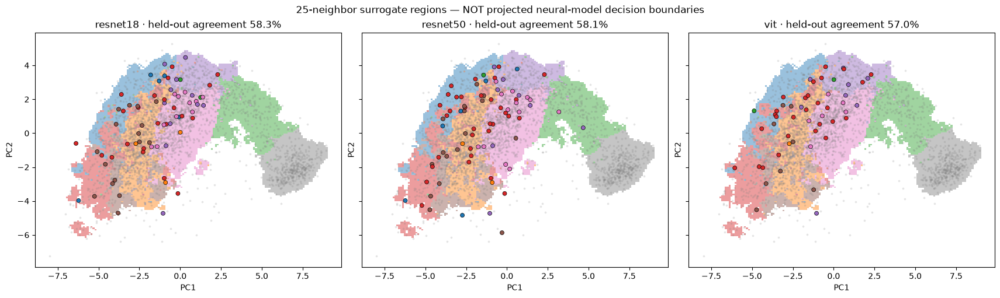

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True, layout='constrained')
for m, ax in enumerate(axes):
    region = np.ma.masked_where(~pca['support'], pca['surrogate_regions'][m])
    ax.pcolormesh(pca['grid_x'], pca['grid_y'], region, cmap=class_cmap, norm=class_norm, shading='auto', alpha=0.45)
    ids = np.flatnonzero(pca['high_confidence_wrong'][m])
    ax.scatter(*xy.T, color='gray', s=3, alpha=0.15)
    ax.scatter(*xy[ids].T, c=class_colors[predicted[m, ids]], s=25, edgecolor='black', linewidth=0.5)
    ax.set(title=f'{model_names[m]} · held-out agreement {pca["surrogate_agreement"][m]:.1%}', xlabel='PC1', ylabel='PC2')
fig.suptitle('25-neighbor surrogate regions — NOT projected neural-model decision boundaries')
plt.show()

Read colored regions as supported 25-neighbor surrogate assignments and use held-out agreement, with PCA and the surrogate refitted on the fit partition, to judge their fidelity. Agreement is only 58.3%, 58.1% and 57.0% for ResNet18, ResNet50 and ViT, despite exceeding the 19–20% majority-label baseline. These regions are therefore low-fidelity empirical approximations, not true projected neural-model decision boundaries.

## Reliability-screened version — blank background means insufficient evidence

Read color only as a locally screened approximation of the model’s labels, and blank background as insufficient evidence. PCA and 25-NN are fitted on 50% of TEST images; a separate 25% calibrates the local screen, and the remaining 25% audits it. The fit-only PCA can shift coordinates relative to the plot above, and agreement with the model is not classification accuracy against the true labels.

<details><summary>Screening rule and safeguards</summary>

- All three partitions contain only original TEST images: 1,710 fit, 855 calibration and 856 audit.
- At each location, use the 40 nearest calibration images to estimate how often the fit-only surrogate reproduced the neural model’s label; require the 95% Wilson lower bound to be at least 80%.
- Hide locations outside dense fit-data support; no extrapolated regions.
- Audit each surrogate-predicted class separately: its background is shown only if at least 30 audit images qualify and their Wilson lower bound is also at least 80%, so a reliable majority class cannot validate a rare class.
- Coverage means the percentage of audit images admitted, not the colored area of the plot; overlapping local intervals are screening scores, not simultaneous or pointwise guarantees.
- PCA axis signs are aligned for comparison, but the PCA basis and the surrogate are fitted without audit/calibration images; the audit is not used to tune the thresholds or the local mask.

</details>

In [54]:
import hashlib
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from threadpoolctl import threadpool_limits

# TEST-only partitions; the old holdout IDs are reserved for this screen's audit, not fitting/calibration.
screen_path = Path('predictions/pca_reliable_regions.npz')
with np.load('predictions/test_pca.npz', allow_pickle=False) as saved:
    audit_ids = saved['holdout_indices']
    remaining_ids = saved['train_indices']
    reference_components = saved['components']
screen_signature = hashlib.sha256(images.tobytes() + probabilities.tobytes() + audit_ids.tobytes()
    + reference_components.tobytes() + b'fit2of3-cal1of3-seed43-pca42-knn25-cal40-wilson1.96-lower.8-classAuditN30-v2').hexdigest()
if not screen_path.exists():
    fit_ids, calibration_ids = train_test_split(remaining_ids, test_size=1/3, random_state=43,
                                                stratify=labels[remaining_ids])
    pixels = images.reshape(len(images), -1).astype(np.float32) / 255
    targets = probabilities.argmax(-1)
    z, minimum_fidelity, local_neighbors, minimum_audit = 1.96, 0.80, 40, 30

    def wilson_lower(successes, n):
        n = np.maximum(n, 1)
        rate = successes / n
        return np.clip((rate + z*z/(2*n) - z*np.sqrt(rate*(1-rate)/n + z*z/(4*n*n))) / (1 + z*z/n), 0, 1)

    with threadpool_limits(limits=4):
        projection = PCA(n_components=2, svd_solver='randomized', random_state=42).fit(pixels[fit_ids])
        # Only align axis signs for comparison; distances, fitted subspace and predictions are unchanged.
        signs = np.sign((projection.components_ * reference_components).sum(-1))
        projection.components_ *= np.where(signs == 0, 1, signs)[:, None]
        coordinates = projection.transform(pixels)
        fit_xy, calibration_xy, audit_xy = coordinates[fit_ids], coordinates[calibration_ids], coordinates[audit_ids]
        low, high = coordinates.min(0), coordinates.max(0)
        padding = .05 * (high - low)
        grid_x, grid_y = np.meshgrid(np.linspace(low[0]-padding[0], high[0]+padding[0], 160),
                                     np.linspace(low[1]-padding[1], high[1]+padding[1], 160))
        grid = np.column_stack((grid_x.ravel(), grid_y.ravel()))
        density = NearestNeighbors(n_neighbors=6).fit(fit_xy)
        radius = np.quantile(density.kneighbors(fit_xy)[0][:, 5], .95)
        grid_support = density.kneighbors(grid, n_neighbors=5)[0][:, 4] <= radius
        audit_support = density.kneighbors(audit_xy, n_neighbors=5)[0][:, 4] <= radius
        calibration_neighbors = NearestNeighbors(n_neighbors=local_neighbors).fit(calibration_xy)
        grid_neighbors = calibration_neighbors.kneighbors(grid, return_distance=False)
        audit_neighbors = calibration_neighbors.kneighbors(audit_xy, return_distance=False)
        calibration_predictions, audit_predictions, grid_labels = [], [], []
        for m in range(len(model_names)):
            classifier = KNeighborsClassifier(n_neighbors=25, weights='distance').fit(fit_xy, targets[m, fit_ids])
            calibration_predictions.append(classifier.predict(calibration_xy))
            audit_predictions.append(classifier.predict(audit_xy))
            grid_labels.append(classifier.predict(grid))
        calibration_predictions, audit_predictions = np.array(calibration_predictions), np.array(audit_predictions)
        calibration_success = calibration_predictions == targets[:, calibration_ids]
        grid_lower = wilson_lower(calibration_success[:, grid_neighbors].sum(-1), local_neighbors)
        audit_lower_local = wilson_lower(calibration_success[:, audit_neighbors].sum(-1), local_neighbors)
        candidate_audit = (audit_lower_local >= minimum_fidelity) & audit_support
        audit_success = audit_predictions == targets[:, audit_ids]
        # Audit each predicted region class separately, so a reliable majority cannot validate a rare class.
        class_candidate = candidate_audit[:, :, None] & (audit_predictions[:, :, None] == np.arange(8))
        class_count = class_candidate.sum(1)
        class_correct = (class_candidate & audit_success[:, :, None]).sum(1)
        class_lower = wilson_lower(class_correct, class_count)
        class_pass = (class_count >= minimum_audit) & (class_lower >= minimum_fidelity)
        admitted_audit = candidate_audit & np.take_along_axis(class_pass, audit_predictions, axis=1)
        admitted_grid = ((grid_lower >= minimum_fidelity) & grid_support
                         & np.take_along_axis(class_pass, np.array(grid_labels), axis=1))
        admitted_count = admitted_audit.sum(-1)
        admitted_correct = (audit_success & admitted_audit).sum(-1)
        audit_lower = wilson_lower(admitted_correct, admitted_count)
        audit_pass = class_pass.any(-1)
        agreement = np.divide(admitted_correct, admitted_count, out=np.full(3, np.nan), where=admitted_count > 0)
        class_counts = np.stack([np.bincount(targets[m, audit_ids[admitted_audit[m]]], minlength=8) for m in range(3)])
    np.savez_compressed(screen_path, signature=screen_signature, split='test', sample_index=np.arange(len(images)),
        labels=labels, model_names=model_names, probabilities=probabilities, coordinates=coordinates,
        components=projection.components_, mean=projection.mean_, explained_variance_ratio=projection.explained_variance_ratio_,
        fit_indices=fit_ids, calibration_indices=calibration_ids, audit_indices=audit_ids,
        calibration_predictions=calibration_predictions, audit_predictions=audit_predictions,
        calibration_success=calibration_success, grid_x=grid_x, grid_y=grid_y,
        regions=np.array(grid_labels).reshape(3, 160, 160), grid_mask=admitted_grid.reshape(3, 160, 160),
        grid_support=grid_support.reshape(160, 160), grid_lower=grid_lower.reshape(3, 160, 160),
        grid_neighbors=grid_neighbors, audit_neighbors=audit_neighbors, audit_support=audit_support,
        audit_lower_local=audit_lower_local, candidate_audit=candidate_audit, admitted_audit=admitted_audit,
        admitted_count=admitted_count, admitted_correct=admitted_correct, audit_agreement=agreement,
        audit_lower=audit_lower, audit_pass=audit_pass, audit_coverage=admitted_audit.mean(-1),
        class_audit_count=class_count, class_audit_correct=class_correct, class_audit_lower=class_lower, class_audit_pass=class_pass,
        overall_audit_agreement=audit_success.mean(-1), admitted_class_counts=class_counts,
        minimum_fidelity=minimum_fidelity, local_neighbors=local_neighbors, z=z, minimum_audit=minimum_audit,
        method='fit-only PCA and 25-NN; calibration-neighborhood Wilson screen; separate per-predicted-class audit gate; not neural boundaries')
with np.load(screen_path, allow_pickle=False) as saved:
    assert str(saved['signature']) == screen_signature, 'Cached screen differs from the current experiment.'
    screened = {key:saved[key] for key in saved.files}
print(f'TEST-only fit / calibration / audit: {len(screened["fit_indices"])} / {len(screened["calibration_indices"])} / {len(screened["audit_indices"])}')
for m, name in enumerate(model_names):
    print(f'{name}: overall audit agreement {screened["overall_audit_agreement"][m]:.1%}; '
          f'retained audit agreement {screened["audit_agreement"][m]:.1%}, '
          f'Wilson lower bound {screened["audit_lower"][m]:.1%} (N={screened["admitted_count"][m]}); '
          f'audit gate {bool(screened["audit_pass"][m])}; retained coverage {screened["audit_coverage"][m]:.1%}')


TEST-only fit / calibration / audit: 1710 / 855 / 856
resnet18: overall audit agreement 58.8%; retained audit agreement 99.1%, Wilson lower bound 95.0% (N=109); audit gate True; retained coverage 12.7%
resnet50: overall audit agreement 57.9%; retained audit agreement 99.1%, Wilson lower bound 94.9% (N=107); audit gate True; retained coverage 12.5%
vit: overall audit agreement 57.6%; retained audit agreement 99.1%, Wilson lower bound 95.0% (N=109); audit gate True; retained coverage 12.7%


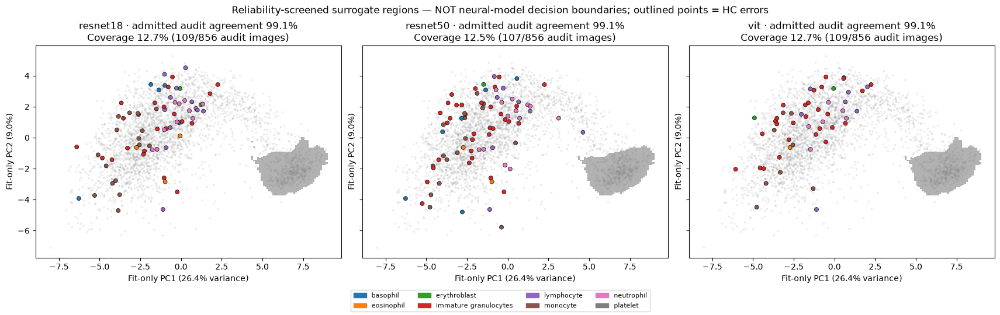

In [55]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

screen_colors = plt.get_cmap('tab10')(np.arange(8))
screen_cmap = ListedColormap(screen_colors)
screen_norm = BoundaryNorm(np.arange(9) - .5, 8)
screen_xy = screened['coordinates']
fig, axes = plt.subplots(1, 3, figsize=(17, 5.3), sharex=True, sharey=True, layout='constrained')
for m, ax in enumerate(axes):
    region = np.ma.masked_where(~screened['grid_mask'][m], screened['regions'][m])
    ax.pcolormesh(screened['grid_x'], screened['grid_y'], region,
                  cmap=screen_cmap, norm=screen_norm, shading='auto', alpha=.6)
    ax.scatter(*screen_xy.T, color='gray', s=3, alpha=.10)
    ids = np.flatnonzero((predicted[m] != labels) & (confidence[m] >= threshold))
    ax.scatter(*screen_xy[ids].T, c=screen_colors[predicted[m, ids]], s=25, edgecolor='black', linewidth=.5)
    admitted = int(screened['admitted_audit'][m].sum())
    title = (f'{model_names[m]} · admitted audit agreement {screened["audit_agreement"][m]:.1%}\n'
             f'Coverage {screened["audit_coverage"][m]:.1%} ({admitted}/{len(screened["audit_indices"])} audit images)'
             if screened['audit_pass'][m] else f'{model_names[m]} · no regions pass the audit gate')
    ax.set(title=title, xlabel=f'Fit-only PC1 ({screened["explained_variance_ratio"][0]:.1%} variance)',
           ylabel=f'Fit-only PC2 ({screened["explained_variance_ratio"][1]:.1%})')
fig.legend(handles=[Patch(color=screen_colors[c], label=class_names[c]) for c in range(8)],
           loc='outside lower center', ncol=4, fontsize=8)
fig.suptitle('Reliability-screened surrogate regions — NOT neural-model decision boundaries; outlined points = HC errors')
plt.show()


Compare the small retained regions with the uncolored main cloud and read agreement together with image coverage. Agreement on admitted audit images rounds to 99.1% for each model, but coverage is only 12.7%, 12.5% and 12.7% for ResNet18, ResNet50 and ViT, and only platelet-labeled surrogate regions qualify. The screen therefore identifies a narrow reproducible part of the surrogate rather than repairing the global PCA boundaries, and neither the local intervals nor the aggregate audit guarantee fidelity at every colored location.

## Local black-box slices — vary two PCs around real error/control images while keeping the remaining image information fixed

In [48]:
local_path = Path('predictions/pca_blackbox_slices.npz')
if not local_path.exists():
    anchors=pca['anchor_pairs'].ravel()
    axis=np.linspace(-0.5,0.5,41)
    gx,gy=np.meshgrid(axis,axis)
    delta=np.column_stack((gx.ravel(),gy.ravel())) * np.sqrt(pca['explained_variance'])
    output=np.empty((3,len(anchors),41,41,8),dtype=np.float32)
    scores=np.empty_like(output)
    clipped=np.empty((len(anchors),41,41),dtype=np.float32)
    realized=np.empty((len(anchors),41,41,2),dtype=np.float32)
    nearest_switch=np.full((3,len(anchors)),np.nan)
    distance=np.hypot(gx,gy)
    for j,i in enumerate(anchors):
        # Keep the anchor's residual outside the first two PCs, instead of inverse-PCA mean images.
        x=images[i].reshape(-1).astype(np.float32)/255
        raw=x[None]+delta@pca['components']
        clipped[j]=((raw<0)|(raw>1)).mean(-1).reshape(41,41)
        changed=np.rint(np.clip(raw,0,1)*255).astype(np.uint8).reshape(-1,28,28,3)
        np.testing.assert_array_equal(changed[20*41+20],images[i])
        realized[j]=((changed.reshape(len(changed),-1).astype(np.float32)/255-pca['mean'])@pca['components'].T).reshape(41,41,2)
        for m,name in enumerate(model_names):
            p,logits=predict(m,changed)
            output[m,j]=p.reshape(41,41,8)
            scores[m,j]=logits.reshape(41,41,8)
            np.testing.assert_allclose(output[m,j,20,20],probabilities[m,i],atol=1e-5,rtol=1e-4)
            switched=(output[m,j].argmax(-1)!=probabilities[m,i].argmax())&(clipped[j]<=0.05)
            if switched.any():nearest_switch[m,j]=distance[switched].min()
        print(f'Anchor #{i}: all three local black-box maps complete',flush=True)
    with np.load('predictions/occlusion_test.npz',allow_pickle=False) as z:
        checkpoint_hashes=z['weight_hashes']
    np.savez_compressed('predictions/pca_blackbox_slices.npz', probabilities=output,logits=scores,
                        sample_index=anchors,anchor_pairs=pca['anchor_pairs'],labels=labels[anchors],
                        baseline_probabilities=probabilities[:,anchors],model_names=model_names,checkpoints=checkpoints,
                        weight_hashes=checkpoint_hashes,grid_x=gx,grid_y=gy,clip_fraction=clipped,
                        realized_pca_coordinates=realized,components=pca['components'],mean=pca['mean'],
                        explained_variance=pca['explained_variance'],coordinates=pca['coordinates'][anchors],
                        nearest_observed_switch=nearest_switch,seed=42,split='test',max_display_clip_fraction=0.05,
                        method='anchor plus first-two-PC displacement; original residual fixed; clip to [0,1], round to uint8',
                        axes=['model','anchor','PC2 grid row','PC1 grid column','class'])
    assert np.isfinite(output).all() and np.isfinite(scores).all()
    np.testing.assert_allclose(output.sum(-1),1,atol=1e-6)
    for m in range(3):
        exp=np.exp(scores[m].astype(float)-scores[m].max(-1,keepdims=True))
        np.testing.assert_allclose(exp/exp.sum(-1,keepdims=True),output[m],atol=2e-7,rtol=1e-5)
    print('Nearest observed label switch (PC-standard-deviation units; NaN = none on displayed grid):',nearest_switch.tolist())
    print('Fraction of each grid with <=5% clipped pixels:',(clipped<=.05).mean((1,2)).tolist())

with np.load(local_path, allow_pickle=False) as saved:
    local = {key:saved[key] for key in saved.files}
np.testing.assert_allclose(local['baseline_probabilities'], probabilities[:, local['sample_index']], atol=1e-5, rtol=1e-4)

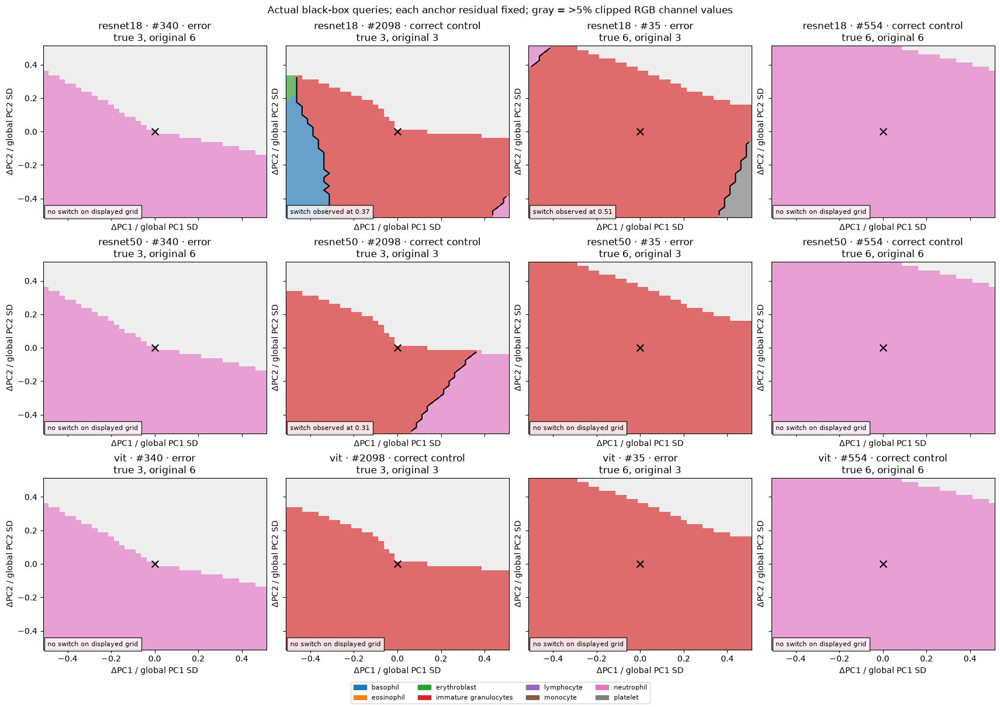

In [49]:
fig, axes = plt.subplots(3, 4, figsize=(17, 12), sharex=True, sharey=True, layout='constrained')
for m, name in enumerate(model_names):
    for j, i in enumerate(local['sample_index']):
        ax = axes[m, j]
        assigned = local['probabilities'][m, j].argmax(-1)
        invalid = local['clip_fraction'][j] > 0.05
        region = np.ma.masked_where(invalid, assigned)
        ax.set_facecolor('#eeeeee')
        ax.pcolormesh(local['grid_x'], local['grid_y'], region, cmap=class_cmap, norm=class_norm, shading='auto', alpha=0.65)
        original = local['baseline_probabilities'][m, j].argmax()
        same = np.ma.masked_where(invalid, assigned == original)
        if same.min() != same.max():ax.contour(local['grid_x'], local['grid_y'], same, levels=[0.5], colors='black')
        ax.scatter(0, 0, marker='x', color='black', s=70)
        nearest = local['nearest_observed_switch'][m, j]
        text = f'switch observed at {nearest:.2f}' if np.isfinite(nearest) else 'no switch on displayed grid'
        ax.set(title=f'{name} · #{i} · {"error" if j % 2 == 0 else "correct control"}\ntrue {labels[i]}, original {original}',
               xlabel='ΔPC1 / global PC1 SD', ylabel='ΔPC2 / global PC2 SD')
        ax.text(0.02, 0.02, text, transform=ax.transAxes, fontsize=8, bbox={'facecolor':'white','alpha':0.8})
fig.legend(handles=[Patch(color=class_colors[c], label=class_names[c]) for c in range(8)],
           loc='outside lower center', ncol=4, fontsize=8)
fig.suptitle('Actual black-box queries; each anchor residual fixed; gray = >5% clipped RGB channel values')
plt.show()

Look for class-color changes around each anchor’s center marker, excluding gray queries where more than 5% of RGB channel values would be clipped. Only three of twelve model/anchor maps contain an admitted switch, with no switch around shared error #340 but switches around correct control #2098 for both CNNs. These selected finite slices do not support errors being consistently closer to a leading-PC boundary, and a constant region is not a global robustness certificate.

## C · Linking errors to stability — same brightness and translation levels; all HC errors versus RGB-near correct ≥90%-confident same-class controls; a changed decision is not necessarily a correction

In [50]:
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    followup_levels = {kind: saved[f'levels_{kind}'] for kind in ['brightness', 'translation']}
followup = dict(model_names=model_names, threshold=threshold, common_wrong=common_wrong, common_hc=common_hc,
                gallery_pairs=gallery_pairs, class_sizes=class_sizes, class_hc_counts=class_hc_counts,
                cohort_names=cohort_names, cohort_effects=cohort_effects, cohort_weights=np.stack(cohort_weights),
                cohort_roles=['HC errors', 'correct HC controls'], checkpoints=checkpoints)
for m, ids in enumerate(error_ids):
    controls = neighbor_ids[m][0]
    assert correct[m, controls].all() and (confidence[m, controls] >= threshold).all()
    np.testing.assert_array_equal(labels[controls], labels[ids])
    selected = np.stack((ids, controls))
    base = probabilities[m, selected]
    scores = np.load(f'predictions/{model_names[m]}_test.npz')['logits'][selected]
    original = base.argmax(-1)
    original_probability = base.max(-1)
    followup[f'{model_names[m]}_ids'] = selected
    followup[f'{model_names[m]}_exclusive_hc'] = exclusive_hc[m]
    followup[f'{model_names[m]}_baseline'] = base
    followup[f'{model_names[m]}_baseline_logits'] = scores.reshape(2, len(ids), 8)
    print(f'{model_names[m]}: {len(ids)} errors, {len(np.unique(controls))} unique controls; mean baseline confidence {original_probability[0].mean():.1%} / {original_probability[1].mean():.1%}')
    for col, (kind, values) in enumerate(followup_levels.items()):
        with np.load('predictions/stability.npz', allow_pickle=False) as saved:
            p = saved[kind][m, :, 0][:, selected].transpose(1, 0, 2, 3)
            logits = saved[f'logits_{kind}'][m, :, 0][:, selected].transpose(1, 0, 2, 3)
        delta = np.take_along_axis(p, original[:, None, :, None], axis=-1)[..., 0] - original_probability[:, None]
        followup[f'{model_names[m]}_{kind}'] = p
        followup[f'{model_names[m]}_{kind}_logits'] = logits
        print(f'{model_names[m]} {kind}: mean probability drop for errors {-delta[0].mean():.3f}, controls {-delta[1].mean():.3f}')
followup.update({f'levels_{kind}': values for kind, values in followup_levels.items()})
np.savez_compressed('predictions/high_confidence_followup.npz', **followup)

def plot_targeted_followup():
    fig, axes = plt.subplots(3, 2, figsize=(13, 10), layout='constrained')
    for m, model in enumerate(model_names):
        ids = followup[f'{model}_ids'][0]
        base = followup[f'{model}_baseline']
        original, original_probability = base.argmax(-1), base.max(-1)
        for col, (kind, values) in enumerate(followup_levels.items()):
            p = followup[f'{model}_{kind}']
            delta = np.take_along_axis(p, original[:, None, :, None], axis=-1)[..., 0] - original_probability[:, None]
            for role, name in enumerate(['HC errors', 'Correct HC controls']):
                y = 100 * delta[role].mean(-1)
                assert change_limits[0] <= y.min() and y.max() <= change_limits[1], 'Change would be clipped.'
                axes[m, col].plot(values, y, 'o-', label=name)
            axes[m, col].axhline(0, color='gray', ls='--')
            axes[m, col].set(title=f'{model_names[m]} · {kind} · N={len(ids)} pairs',
                              xlabel=kind, ylabel='Change (percentage points)', ylim=change_limits)
            axes[m, col].grid(alpha=0.2)
    axes[0, 0].legend()
    fig.suptitle('Targeted follow-up using stability levels: errors versus class-matched correct decisions')
    plt.show()

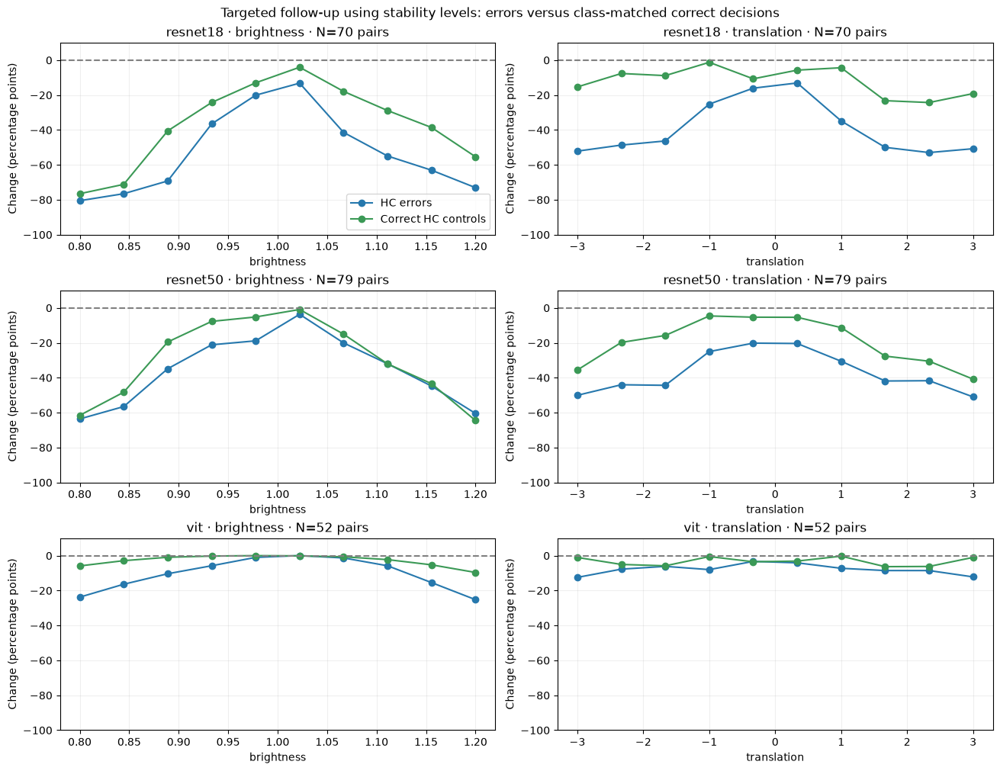

In [51]:
plot_targeted_followup()

Compare original-class probability changes for HC errors and same-class HC-correct controls at identical brightness and translation levels. Errors lose more support under both operations in all three models, including a mean ResNet18 translation drop of 39.0 percentage points versus 12.0 for controls. Transformation response may therefore add information beyond high starting confidence, but differing baseline confidence and potentially wrong replacement labels prevent treating it as an established error detector.

## Findings

- **Shared class substitutions:** Compare the repeated labels in the shared gallery with the exclusive-error examples. All models misclassify 39 images, including 18 shared HC errors with identical wrong labels and nine immature-granulocyte/neutrophil substitutions. These recurring substitutions reveal shared class competition, while exclusive errors show that the checkpoints do not share every weakness.
- **Class and color dependence:** Compare per-class HC-error rates with the destination classes reached under desaturation. Immature granulocytes have ResNet18’s highest rate at 6.22%, monocytes have the highest ResNet50/ViT rates at 5.63%/4.58%, and desaturation sends almost all CNN errors and matched controls to erythroblast. The results indicate class-specific weaknesses and a shared color-dependent class attractor, not a selective repair of the original errors.
- **Appearance versus decision geometry:** Compare error/control appearance shifts with surrogate fidelity and actual local boundary crossings. Shared errors are brighter by 0.70 control SD, but the PCA surrogate reproduces only 57–58% of held-out decisions and error #340 has no switch while correct control #2098 crosses for both CNNs. Appearance associations therefore do not establish that HC errors are consistently closer to a leading-PC boundary.
- **Spatial support for wrong decisions:** Compare population occlusion with same-class HC error-minus-control contrasts rather than interpreting central dependence alone. ResNet50’s central error contrast differs in sign between monocytes and basophils, while paired HC errors show additional central drops of 0.104, 0.098 and 0.113 for ResNet18, ResNet50 and ViT. Wrong decisions can therefore have stronger spatial dependence than comparable correct decisions, without those fixed patches identifying anatomical structures.
- **Direction-specific instability:** Compare the targeted brightness/translation responses with the mostly constant local PCA slices. HC errors lose more original-class support than their correct controls under both operations, including 39.0 versus 12.0 percentage points for ResNet18 translation, while only three local PCA maps contain an admitted label switch. High confidence therefore does not imply uniformly stable or fragile decisions, because the chosen perturbation direction matters.

**Limits:** Treat these test-only results as exploratory rather than independent confirmation of selected hypotheses. Paired intervention controls match true class and confidence threshold but not exact confidence and can be reused; feature-distribution controls are class-weighted, and ResNet18/ViT resize to 224×224 whereas ResNet50 uses 28×28 with different resizing methods. Correlated features, potentially out-of-distribution or label-changing transformations, and selected finite clipped PCA slices limit causal and global robustness claims.


## Archive B — stability_analysis.ipynb

Includes original model loading and resumable forward passes, complete probability/logit export, four-panel transformation figures, conditional transitions, class-wise and model-difference maps, and selected image sequences. The original sources and outputs below are unchanged; start this section with a fresh kernel when reproducing it.

# Experiment 2: Stability, correctness and class-specific responses
## All 3,421 test images; seed 42; three noise realizations; run-1 ResNet18 224, ResNet50 28 and original ViT

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageFilter
from transformers import ViTForImageClassification, ViTImageProcessor
from torchvision.models import resnet18
from models.resnet18.models import ResNet50

seed, batch_size = 42, 32
torch.manual_seed(seed)
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_names = ['resnet18', 'resnet50', 'vit']
class_names = list(json.loads(Path('data/metadata.json').read_text())['label'].values())
class_names[3] = 'immature granulocytes'
output = Path('predictions/stability.npz')
output.parent.mkdir(exist_ok=True)
print(device)
from itertools import combinations
pairs = list(combinations(range(len(model_names)), 2))

cuda


## Ten non-identity levels per operation — translation in subpixels, noise σ on [0, 1], blur radius in pixels

In [2]:
levels = {
    'rotation': np.linspace(-20, 20, 10),
    'translation': np.linspace(-3, 3, 10),
    'brightness': np.linspace(0.8, 1.2, 10),
    'blur': np.linspace(0.15, 1.5, 10),
    'noise': np.linspace(0.01, 0.1, 10),
    'green_scale': np.linspace(0.9, 1.1, 10),
    'red_scale': np.linspace(0.9, 1.1, 10),
    'blue_scale': np.linspace(0.9, 1.1, 10),
}
with np.load('data/bloodmnist.npz', allow_pickle=False) as data:
    test_images = data['test_images']
    test_labels = data['test_labels'].ravel()
indices = np.arange(len(test_images))
images, labels = test_images[indices], test_labels[indices]
baseline = []
for name in model_names:
    rows = np.loadtxt(f'predictions/{name}_test.csv', delimiter=',', skiprows=1)[indices]
    np.testing.assert_array_equal(rows[:, 0], indices)
    np.testing.assert_array_equal(rows[:, 1], labels)
    baseline.append(rows[:, 3:])
baseline = np.stack(baseline)
base_class = baseline.argmax(-1)
all_correct = (base_class == labels).all(axis=0)
print(f'{len(images)} images; {all_correct.sum()} initially correct for all models')

3421 images; 3191 initially correct for all models


## Transform original 28 × 28 RGB images — shared inputs for all models, gray borders, no wraparound

Noise seeds use the original test index, severity and repeat. The previous subset experiment used subset positions, so the full-population noise realizations follow a new explicit seed protocol.

In [3]:
def transform(images, kind, level, repeat=0):
    result = []
    for i, image in enumerate(images):
        pil = Image.fromarray(image)
        if kind == 'rotation':
            changed = pil.rotate(float(level), resample=Image.Resampling.BILINEAR, fillcolor=(128, 128, 128))
        elif kind == 'translation':
            changed = pil.transform(pil.size, Image.Transform.AFFINE, (1, 0, -float(level), 0, 1, 0),
                                    resample=Image.Resampling.BILINEAR, fillcolor=(128, 128, 128))
        elif kind == 'brightness':
            changed = ImageEnhance.Brightness(pil).enhance(float(level))
        elif kind == 'blur':
            changed = pil.filter(ImageFilter.GaussianBlur(float(level)))
        elif kind == 'noise':
            key = f'{seed}:{i}:{level}:{repeat}'
            noise_seed = int.from_bytes(hashlib.sha256(key.encode()).digest()[:8], 'little')
            noise = np.random.default_rng(noise_seed).normal(0, level, image.shape)
            changed = np.rint(np.clip(image / 255.0 + noise, 0, 1) * 255).astype(np.uint8)
        else:
            channel = {'red_scale': 0, 'green_scale': 1, 'blue_scale': 2}[kind]
            changed = image.astype(float)
            changed[..., channel] *= level
            changed = np.rint(np.clip(changed, 0, 255)).astype(np.uint8)
        result.append(np.asarray(changed))
    return np.stack(result)

## Load models and predict in batches

In [4]:
models = [resnet18(weights=None, num_classes=8), ResNet50(in_channels=3, num_classes=8)]
checkpoints = ['weights_bloodmnist/resnet18_224_1.pth', 'weights_bloodmnist/resnet50_28_1.pth', 'models/vit']
for model, path in zip(models, checkpoints):
    model.load_state_dict(torch.load(path, map_location='cpu', weights_only=True)['net'])
models.append(ViTForImageClassification.from_pretrained('models/vit', local_files_only=True))
models = [model.to(device).eval() for model in models]
processor = ViTImageProcessor.from_pretrained('models/vit', local_files_only=True)

@torch.inference_mode()
def predict(m, images):
    probabilities, scores = [], []
    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size]
        if model_names[m] != 'vit':
            x = torch.from_numpy(batch.copy()).permute(0, 3, 1, 2).to(device).float()
            if model_names[m] == 'resnet18':
                x = torch.nn.functional.interpolate(x, size=(224, 224), mode='nearest')
            logits = models[m]((x / 255 - 0.5) / 0.5)
        else:
            inputs = processor(images=list(batch), return_tensors='pt').to(device)
            logits = models[m](**inputs).logits
        probabilities.append(logits.softmax(-1).cpu().numpy())
        scores.append(logits.cpu().numpy())
    return np.concatenate(probabilities), np.concatenate(scores)

baseline_logits = [np.load(f'predictions/{name}_test.npz')['logits'][indices] for name in model_names]
gate = np.concatenate([np.flatnonzero(labels == c)[:8] for c in range(8)])
for m in range(len(models)):
    np.testing.assert_allclose(predict(m, images[gate])[0], baseline[m, gate], atol=1e-5, rtol=1e-4)


## Run experiment and save full probabilities and raw logits — model × level × realization × image × class

In [5]:
from numpy.lib.format import open_memmap

files = [*checkpoints[:2], 'models/vit/model.safetensors', 'models/vit/config.json', 'models/vit/preprocessor_config.json']
weight_hashes = [hashlib.sha256(Path(path).read_bytes()).hexdigest() for path in files]
signature = hashlib.sha256(images.tobytes() + labels.tobytes() + baseline.tobytes()
                           + str(weight_hashes).encode() + str(levels).encode() + str(seed).encode() + b'test-index-noise-v2').hexdigest()
if output.exists():
    with np.load(output, allow_pickle=False) as saved:
        assert str(saved['signature']) == signature, 'Saved experiment differs from current inputs.'
    print(f'Using validated full-test cache: {output}')
else:
    cache = Path('outputs/stability_test_v2')
    cache.mkdir(parents=True, exist_ok=True)
    lock = cache / 'signature.txt'
    assert not lock.exists() or lock.read_text() == signature, 'Inputs changed: use a new cache directory.'
    lock.write_text(signature)
    probabilities, logits = {}, {}
    for kind, values in levels.items():
        repeats = 3 if kind == 'noise' else 1
        arrays = []
        for suffix, shape, dtype in [('p', (3, 10, repeats, len(images), 8), 'float32'),
                                      ('logits', (3, 10, repeats, len(images), 8), 'float32'),
                                      ('done', (3, 10, repeats), 'bool')]:
            path = cache / f'{kind}_{suffix}.npy'
            fresh = not path.exists()
            a = open_memmap(path, mode='w+' if fresh else 'r+', dtype=dtype, shape=shape)
            if fresh and dtype == 'bool':
                a[:] = False
                a.flush()
            arrays.append(a)
        p, scores, done = arrays
        for j, level in enumerate(values):
            for repeat in range(repeats):
                if done[:, j, repeat].all():
                    continue
                changed = transform(images, kind, level, repeat)
                for m in range(len(models)):
                    if not done[m, j, repeat]:
                        p[m, j, repeat], scores[m, j, repeat] = predict(m, changed)
                        p.flush()
                        scores.flush()
                        done[m, j, repeat] = True
                        done.flush()
        probabilities[kind], logits[kind] = p, scores
        print(f'{kind}: all {len(images)} test images, {len(values)} levels, {repeats} realizations completed')
    np.savez_compressed(output, **probabilities, baseline=baseline, indices=indices, labels=labels,
                        seed=seed, model_names=model_names, class_names=class_names, signature=signature,
                        checkpoints=checkpoints, weight_hashes=weight_hashes, model_input_resolutions=[224,28,224],
                        baseline_logits=np.stack(baseline_logits), split='test', noise_seed_scope='original test index',
                        axes=['model','level','realization','image','class'], border_fill_rgb=[128]*3, input_shape=[28,28,3],
                        **{f'logits_{kind}': scores for kind, scores in logits.items()},
                        **{f'levels_{kind}': values for kind, values in levels.items()})
    print(output)


Using validated full-test cache: predictions\stability.npz


## Load saved results — average noise realizations within each image, not as independent images

In [6]:
with np.load(output, allow_pickle=False) as saved:
    levels = {kind: saved[f'levels_{kind}'] for kind in levels}
    probabilities = {kind: saved[kind] for kind in levels}
    baseline, indices, labels = saved['baseline'], saved['indices'], saved['labels']
    model_names = saved['model_names'].tolist()
    seed = int(saved['seed'])
images = test_images[indices]
base_class = baseline.argmax(-1)
base_probability = np.take_along_axis(baseline, base_class[..., None], axis=-1)[..., 0]
all_correct = (base_class == labels).all(axis=0)
metrics = {}
for kind, p in probabilities.items():
    predicted = p.argmax(-1)
    target = np.broadcast_to(base_class[:, None, None, :, None], p.shape[:-1] + (1,))
    retained = np.take_along_axis(p, target, axis=-1)[..., 0].mean(axis=2)
    correct = (predicted == labels).mean(axis=2)
    metrics[kind] = {
        'Change in p(original class)': retained - base_probability[:, None, :],
        'Label flip fraction': (predicted != base_class[:, None, None, :]).mean(axis=2),
        'Accuracy (all images)': correct,
        'Correct-label retention (all initially correct)': correct[:, :, all_correct],
        'Correct → wrong': (1 - correct) * (base_class == labels)[:, None, :],
        'Wrong → correct': correct * (base_class != labels)[:, None, :],
    }

## 2A — Stability and correctness: ten points per operation; dashed lines mark unmodified references

In [7]:
from matplotlib.ticker import PercentFormatter

change_limits = (-100, 10)
def plot_stability(kind, values):
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.5), layout='constrained')
    reference = 1 if kind in ('brightness', 'green_scale', 'red_scale', 'blue_scale') else 0
    for ax, title in zip(axes, list(metrics[kind])[:4]):
        is_change = title.startswith('Change')
        for m, name in enumerate(model_names):
            data = metrics[kind][title][m]
            y = data.mean(axis=-1) if data.shape[-1] else np.full(10, np.nan)
            if is_change:
                y = 100 * y
                assert change_limits[0] <= y.min() and y.max() <= change_limits[1], 'Change would be clipped.'
            line, = ax.plot(values, y, 'o-', label=name)
            base = (base_class[m] == labels).mean() if title.startswith('Accuracy') else (1 if title.startswith('Correct-label') else 0)
            ax.axhline(base, color=line.get_color(), ls='--', alpha=0.35)
        ax.axvline(reference, color='gray', ls=':', alpha=0.5)
        ax.set(title='Original-class support: change' if is_change else title, xlabel=kind)
        if is_change:
            ax.set(ylim=change_limits, ylabel='Change (percentage points)')
        else:
            ax.set(ylim=(-0.03, 1.03), yticks=np.linspace(0, 1, 5))
            ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        ax.grid(alpha=0.2)
    axes[0].legend()
    fig.suptitle(f'{kind} · N={len(labels)} · shared correct N={all_correct.sum()} · fixed y-scales')
    plt.show()


Compare original-class support and label flips with accuracy, using identical y-scales across transformations rather than judging independently zoomed curves. The experiment covers 3,421 test images, including 3,191 originally classified correctly by all three models, with probability changes shown in percentage points and rates in percent. These panels separate consistency from correctness while preventing different axis ranges from exaggerating differences in response size.

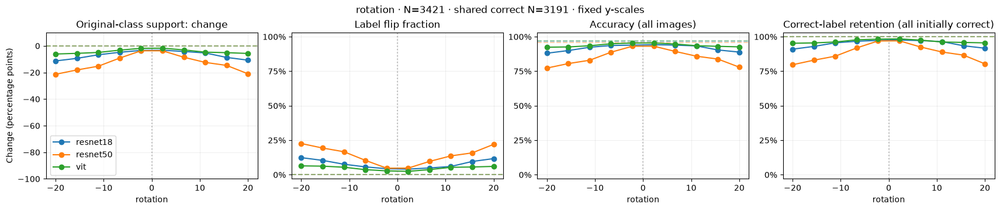

In [8]:
plot_stability('rotation', levels['rotation'])

Compare rotation-induced label flips across models and use the class map below to locate concentrated sensitivity. Rotation changes 14.0% of ResNet50 decisions, versus 7.7% for ResNet18 and 4.8% for ViT, with ResNet50’s basophil original-class support falling by about 0.70. The response is therefore checkpoint- and class-dependent, although rotation includes interpolation and border changes as well as orientation changes.

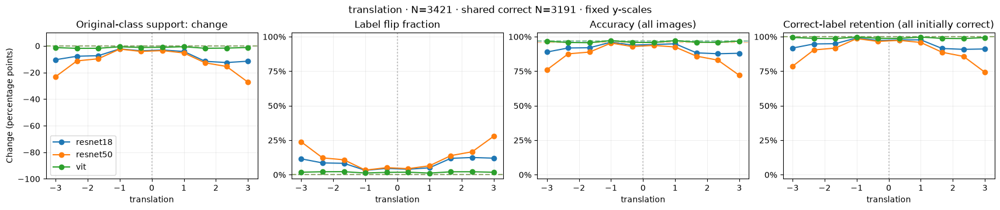

In [9]:
plot_stability('translation', levels['translation'])

Compare both ends of the translation curves rather than judging sensitivity from one shift direction. ResNet50 accuracy falls to 76.0% and 72.1% at the extremes, while ViT remains at 96.8% and 96.9%. ResNet50 is sensitive in both directions, but the non-monotonic individual sequences below show why endpoint-only testing can still miss intermediate failures.

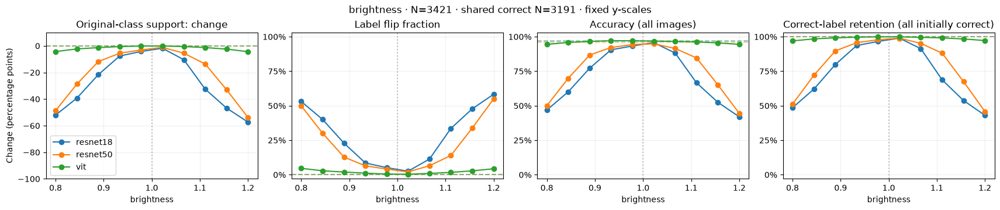

In [10]:
plot_stability('brightness', levels['brightness'])

Compare brightness accuracy curves across models and then check whether their class-specific responses are uniform. Mean accuracy is 71.3% for ResNet18, 77.4% for ResNet50 and 96.1% for ViT, with especially large CNN support losses for monocytes in the class map. The CNNs therefore depend strongly on appearance changes that do not displace image structures, and that dependence differs between cell classes.

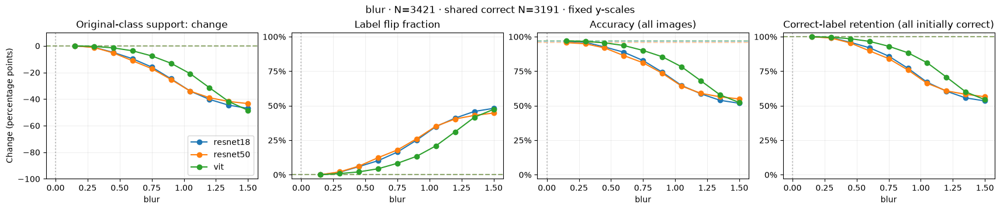

In [11]:
plot_stability('blur', levels['blur'])

Compare model rankings at moderate blur with their accuracy at the strongest blur level. At radius 1.5, ViT accuracy is 52.3%, versus 51.8% and 54.9% for the CNNs, despite its advantage at moderate levels. ViT’s tolerance to other interventions therefore does not imply tolerance to strong removal of spatial detail.

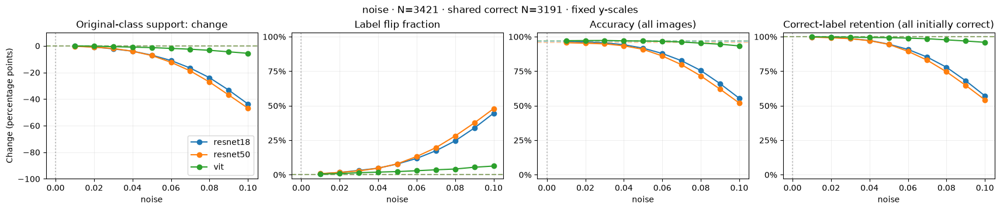

In [12]:
plot_stability('noise', levels['noise'])

Compare noise accuracy curves with the blur curves, averaging the three noise realizations within each image. At noise σ=0.1, accuracy is 55.4% for ResNet18, 52.0% for ResNet50 and 93.3% for ViT. ViT therefore tolerates added random variation much better than the CNNs, but its strong-blur failures show that this advantage does not extend equally to systematic smoothing.

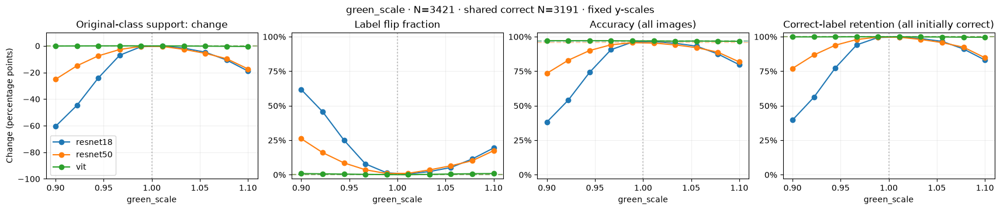

In [13]:
plot_stability('green_scale', levels['green_scale'])

Compare green scaling below and above one to check whether equal-sized changes have symmetric effects. ResNet18 accuracy is 38.2% at factor 0.9 but 79.7% at 1.1, with a weaker blue-channel response and a different ResNet50 profile. The failures therefore depend on the direction and channel of the color change, not simply its distance from the original input.

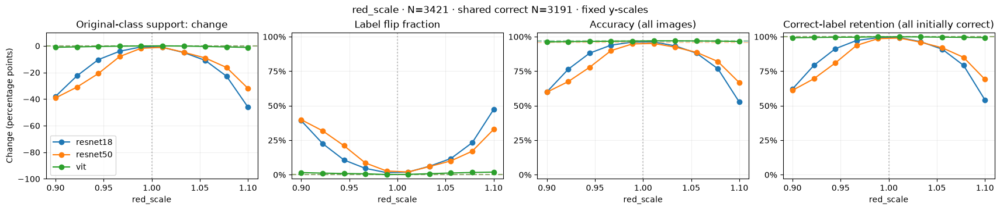

In [14]:
plot_stability('red_scale', levels['red_scale'])

Compare red-scaling label flips across models and contrast their ranking with rotation and green scaling. Red scaling changes 16.9% of ResNet18 and 17.2% of ResNet50 decisions, versus only 1.0% of ViT decisions. The CNNs are similarly sensitive here despite their different responses elsewhere, so one overall robustness ranking would hide intervention-specific weaknesses.

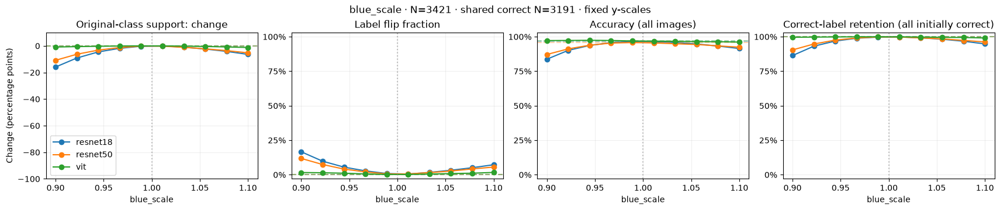

In [15]:
plot_stability('blue_scale', levels['blue_scale'])

Compare blue-channel label flips with red and green scaling over the same factor interval. Blue scaling changes only 5.3% of ResNet18 and 4.1% of ResNet50 decisions, below their red and green responses. The color sensitivity is therefore channel-specific, although raw RGB gains are not independently controlled staining components.

## Conditional correctness transitions — normalize by the initially correct or initially wrong group; average noise repeats within images

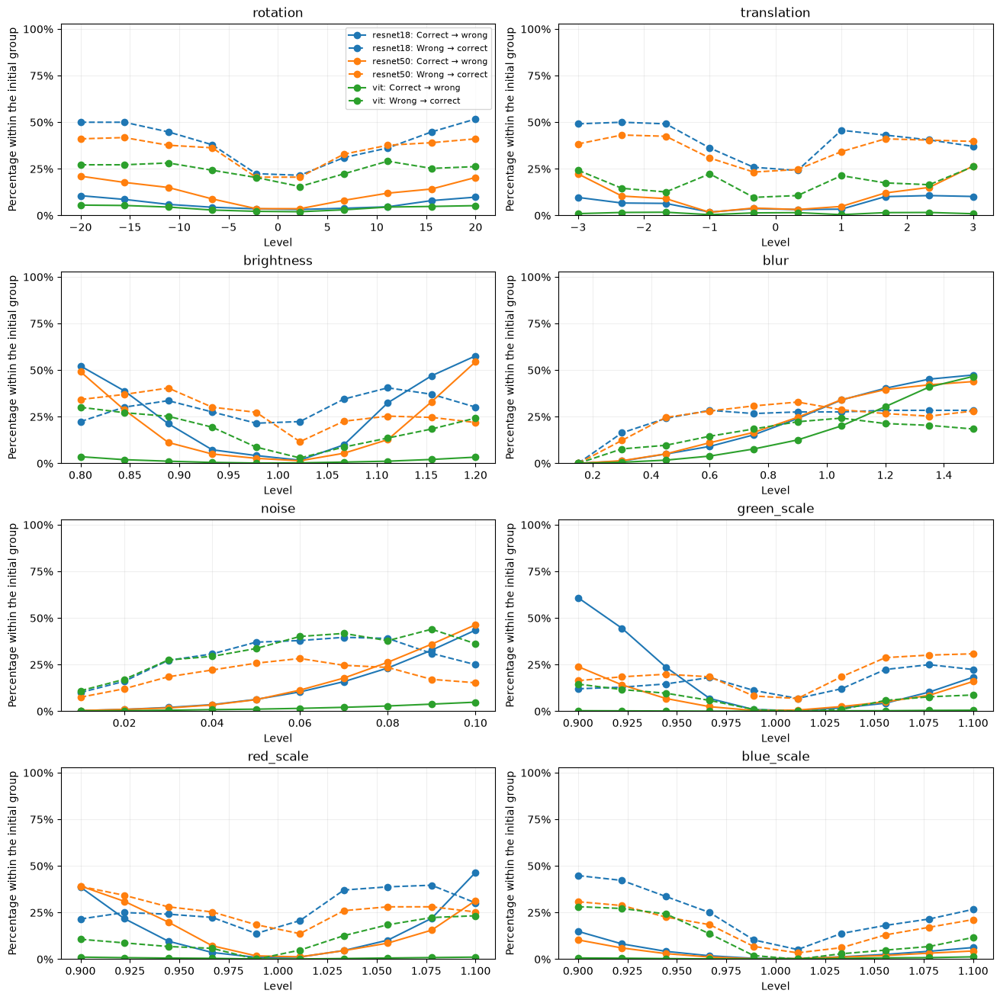

In [16]:
fig, axes = plt.subplots(4, 2, figsize=(13, 13), layout='constrained')
for ax, (kind, values) in zip(axes.flat, levels.items()):
    for m, name in enumerate(model_names):
        for title, style in [('Correct → wrong', '-'), ('Wrong → correct', '--')]:
            initial_accuracy = (base_class[m] == labels).mean()
            denominator = initial_accuracy if title == 'Correct → wrong' else 1 - initial_accuracy
            rate = metrics[kind][title][m].mean(-1) / denominator if denominator else np.full(len(values), np.nan)
            ax.plot(values, rate, style,
                    color=f'C{m}', marker='o', label=f'{name}: {title}')
    ax.set(title=kind, xlabel='Level', ylabel='Percentage within the initial group',
           ylim=(0, 1.03), yticks=np.linspace(0, 1, 5))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
plt.show()

Compare solid correct-to-wrong curves with dashed wrong-to-correct curves, each normalized by its own initial group. Averaged across rotation levels, ResNet18 becomes wrong on 6.3% of its 3,305 initially correct images and correct on 39.1% of its 116 initial errors. These view-dependent reversals reveal decision instability, not necessarily lower confidence, and rotation still reduces overall accuracy because losses in the larger correct group outweigh gains in the error group.

## 2B — Transformation sensitivity by true class: mean change in support for the original prediction; equal weight per level

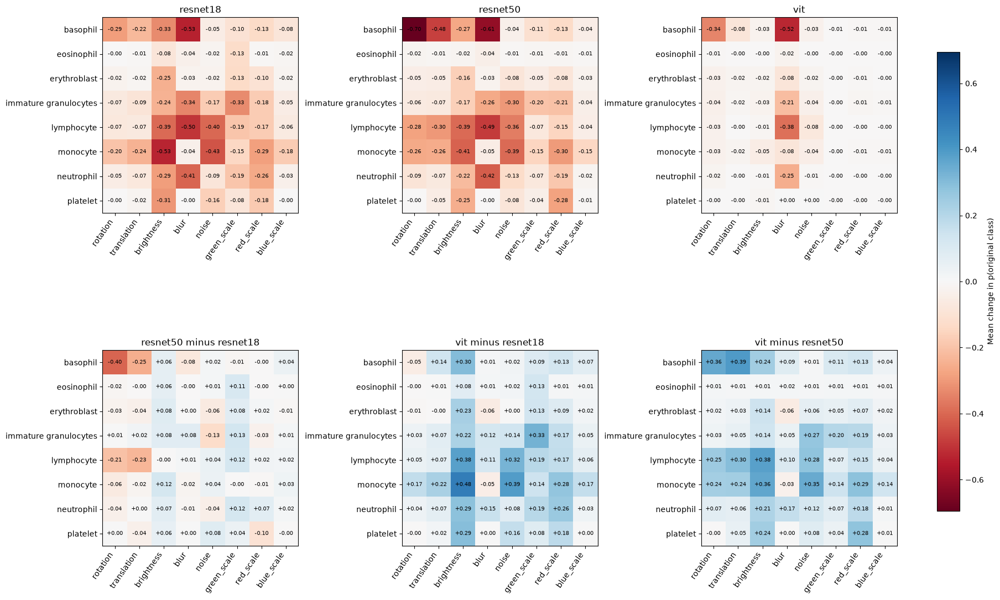

In [17]:
fingerprints = np.stack([np.array([
    metrics[kind]['Change in p(original class)'][m][:, labels == c].mean()
    for c in range(8) for kind in levels]).reshape(8, 8) for m in range(len(model_names))])
matrices = [*fingerprints, *[fingerprints[j] - fingerprints[i] for i, j in pairs]]
titles = [*model_names, *[f'{model_names[j]} minus {model_names[i]}' for i, j in pairs]]
scale = max(np.abs(matrices).max(), 0.01)
fig, axes = plt.subplots(2, 3, figsize=(18, 12), layout='constrained')
for ax, matrix, title in zip(axes.flat, matrices, titles):
    im = ax.imshow(matrix, cmap='RdBu', vmin=-scale, vmax=scale)
    ax.set(title=title, xticks=range(8), xticklabels=list(levels), yticks=range(8), yticklabels=class_names)
    plt.setp(ax.get_xticklabels(), rotation=55, ha='right')
    for c in range(8):
        for j in range(8):
            ax.text(j, c, f'{matrix[c, j]:+.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, ax=axes, shrink=0.7, label='Mean change in p(original class)')
plt.show()


In model maps, red/blue means loss/gain of original-class support and near zero means little change; in first-model-minus-second-model maps, blue means a more positive change for the first model, usually less loss. ViT minus ResNet50 is positive in 61 of 64 class/transformation cells, whereas ResNet50 minus ResNet18 is −0.40 for basophils under rotation. ViT therefore usually retains original-class support better relative to ResNet50, but blue is not proof of accuracy or unchanged labels because each model tracks its own potentially wrong original prediction.

## 2C — Selected examples of translation, brightness and blur; one largest-drop image per operation, not representative samples

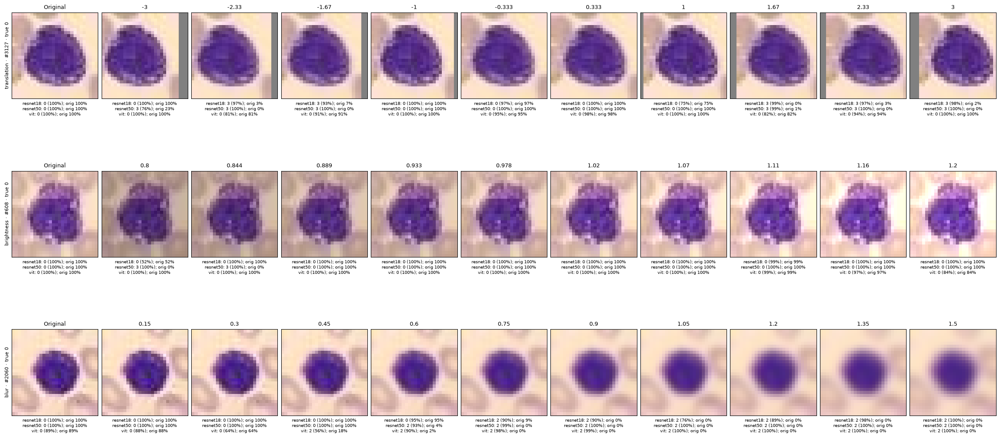

In [18]:
cases = ['translation', 'brightness', 'blur']
fig, axes = plt.subplots(len(cases), 11, figsize=(23, 11), layout='constrained')
for row, kind in enumerate(cases):
    values = levels[kind]
    p0 = np.take_along_axis(probabilities[kind][:, :, 0], base_class[:, None, :, None], axis=-1)[..., 0]
    pos = (base_probability[:, None, :] - p0).max(axis=(0, 1)).argmax()
    for col in range(11):
        ax = axes[row, col]
        ax.imshow(images[pos] if col == 0 else transform(images[pos:pos + 1], kind, values[col - 1])[0])
        p = baseline[:, pos] if col == 0 else probabilities[kind][:, col - 1, 0, pos]
        details = [f'{name}: {p[m].argmax()} ({p[m].max():.0%}); orig {p[m, base_class[m, pos]]:.0%}'
                   for m, name in enumerate(model_names)]
        ax.set_title('Original' if col == 0 else f'{values[col - 1]:.3g}', fontsize=9)
        ax.set_xlabel('\n'.join(details), fontsize=7)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[row, 0].set_ylabel(f'{kind} · #{indices[pos]} · true {labels[pos]}', fontsize=8)
plt.show()

Follow each selected image’s class labels across transformation levels rather than looking only at the endpoints. For translation #3127, ResNet18 switches away from basophil and back before switching again, while blur #2060 sends all three models to erythroblast. These selected largest-drop cases illustrate non-monotonic and shared decision changes, not how frequently those patterns occur in the population.

# Curated scaffold before the four-story revision

Complete executed intermediate versions follow, including all replaced compact plots and interpretations. Cell IDs alone are namespaced to keep this combined notebook valid; sources, metadata and outputs are unchanged.

## Intermediate confidence_analysis.ipynb

# Confidence and high-confidence errors — selected main results

All analyses use the same 3,421 TEST images and the run-1 ResNet18-224, ResNet50-28 and original ViT pipelines. This notebook reads validated binary caches; complete computation, removed views and previous interpretations are preserved in [archive.ipynb](archive.ipynb). Detailed severity curves are summarized in [stability_analysis.ipynb](stability_analysis.ipynb), with the interactive transition explorer retained below.

In [1]:
from pathlib import Path
from itertools import combinations
import hashlib
import json
import numpy as np
import matplotlib.pyplot as plt

# Main results are fast, CPU-only views of published caches; full computation is in archive.ipynb.
with np.load('data/bloodmnist.npz', allow_pickle=False) as saved:
    images, labels = saved['test_images'], saved['test_labels'].ravel()
with np.load('predictions/high_confidence_error_analysis.npz', allow_pickle=False) as saved:
    analysis = {key:saved[key] for key in saved.files}
with np.load('predictions/high_confidence_followup.npz', allow_pickle=False) as saved:
    followup = {key:saved[key] for key in saved.files}
model_names, class_names = analysis['model_names'].tolist(), analysis['class_names'].tolist()
probabilities = analysis['baseline_probabilities']
threshold, n_bins = float(analysis['threshold']), 10
assert str(analysis['split']) == 'test' and len(labels) == 3421
np.testing.assert_array_equal(analysis['true_labels'], labels)
assert probabilities.shape == (3, len(labels), 8)
np.testing.assert_allclose(probabilities.sum(-1), 1, atol=1e-6)
for m, name in enumerate(model_names):
    with np.load(f'predictions/{name}_test.npz', allow_pickle=False) as saved:
        assert str(saved['split']) == 'test'
        np.testing.assert_array_equal(saved['sample_index'], np.arange(len(labels)))
        np.testing.assert_array_equal(saved['labels'], labels)
        np.testing.assert_allclose(saved['probabilities'], probabilities[m], atol=1e-8, rtol=1e-6)
predicted, confidence = probabilities.argmax(-1), probabilities.max(-1)
correct = predicted == labels
error_ids = [analysis[f'{name}_error_ids'] for name in model_names]
high_confidence_wrong = dict(zip(model_names, error_ids))
for m, (name, ids) in enumerate(zip(model_names, error_ids)):
    np.testing.assert_array_equal(np.sort(ids), np.flatnonzero(~correct[m] & (confidence[m] >= threshold)))
    selected = analysis[f'{name}_saturation_ids']
    np.testing.assert_array_equal(selected, followup[f'{name}_ids'])
    np.testing.assert_array_equal(labels[selected[0]], labels[selected[1]])
    assert correct[m, selected[1]].all() and (confidence[m, selected] >= threshold).all()
# Verify the dataset/cache signature without loading models or redoing inference.
with np.load('predictions/occlusion_test.npz', allow_pickle=False) as saved:
    signature = hashlib.sha256(images.tobytes() + labels.tobytes() + probabilities.tobytes()
        + saved['positions'].tobytes() + str(saved['weight_hashes'].tolist()).encode()
        + b'gray128_resnet18-nearest224_resnet50-28_vit-local_v1').hexdigest()
    assert str(saved['signature']) == signature
bins = np.linspace(0, 1, n_bins + 1)
def bin_ids(values):
    return np.clip(np.searchsorted(bins, values, side='right') - 1, 0, n_bins - 1)
pairs = list(combinations(range(3), 2))
model_colors = ['#2678ad', '#3b9956', '#c25a7c']
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=model_colors)
print(f'{len(labels):,} TEST images; HC-error threshold {threshold:.0%}; counts: '+', '.join(f'{n}: {len(ids)}' for n, ids in zip(model_names, error_ids)))

3,421 TEST images; HC-error threshold 90%; counts: resnet18: 70, resnet50: 79, vit: 52


## Reliability diagram — equal-width confidence bins; ECE weighted by bin counts; empty bins omitted

resnet18: accuracy=96.61%, mean confidence=98.73%, ECE=0.0219
resnet50: accuracy=95.73%, mean confidence=98.66%, ECE=0.0298
vit: accuracy=96.99%, mean confidence=98.62%, ECE=0.0167


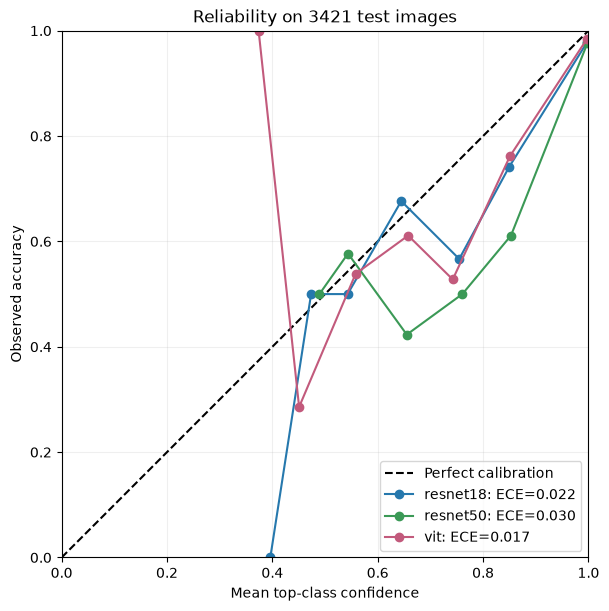

In [2]:
fig, ax = plt.subplots(figsize=(7, 6), layout='constrained')
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
for m, name in enumerate(model_names):
    groups = bin_ids(confidence[m])
    occupied = [groups == b for b in range(n_bins) if (groups == b).any()]
    x = np.array([confidence[m, mask].mean() for mask in occupied])
    y = np.array([correct[m, mask].mean() for mask in occupied])
    counts = np.array([mask.sum() for mask in occupied])
    ece = np.sum(counts * np.abs(y - x)) / len(labels)
    ax.plot(x, y, 'o-', label=f'{name}: ECE={ece:.3f}')
    print(f'{name}: accuracy={correct[m].mean():.2%}, mean confidence={confidence[m].mean():.2%}, ECE={ece:.4f}')
ax.set(xlabel='Mean top-class confidence', ylabel='Observed accuracy',
       title=f'Reliability on {len(labels)} test images', xlim=(0, 1), ylim=(0, 1))
ax.set_aspect('equal')
ax.grid(alpha=0.2)
ax.legend()
plt.show()

Compare each reliability curve with the diagonal, where confidence equals observed accuracy. Mean confidence exceeds accuracy by about 2.1 percentage points for ResNet18, 2.9 for ResNet50 and 1.6 for ViT. These test results indicate overconfidence, without establishing its training-time cause, and motivate checking calibration on separate data.

## High-confidence-error overlap — all three models and each model pair; model-relative percentages and Jaccard have different denominators

Errors shared by all three: 18 test IDs: [35, 340, 476, 496, 642, 839, 1413, 1462, 1629, 1750, 1762, 2384, 2434, 2649, 3015, 3126, 3329, 3373]
resnet18 / resnet50: shared 36, fractions 51.4% / 45.6%, Jaccard 31.9%
Same wrong class among shared errors: 97.2%
resnet18 / vit: shared 22, fractions 31.4% / 42.3%, Jaccard 22.0%
Same wrong class among shared errors: 95.5%
resnet50 / vit: shared 23, fractions 29.1% / 44.2%, Jaccard 21.3%
Same wrong class among shared errors: 95.7%


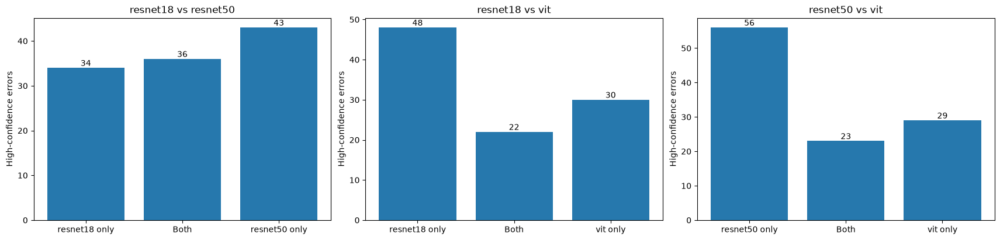

In [3]:
error_ids = [high_confidence_wrong[name] for name in model_names]
shared, union = error_ids[0].copy(), error_ids[0].copy()
for ids in error_ids[1:]:
    shared, union = np.intersect1d(shared, ids), np.union1d(union, ids)
print('Errors shared by all three:', len(shared), 'test IDs:', shared.tolist())
pair_overlap = np.zeros((len(model_names), len(model_names)), dtype=int)
pair_jaccard = np.full_like(pair_overlap, np.nan, dtype=float)
fig, axes = plt.subplots(1, len(pairs), figsize=(17, 4), layout='constrained')
for ax, (i, j) in zip(axes, pairs):
    common, combined = np.intersect1d(error_ids[i], error_ids[j]), np.union1d(error_ids[i], error_ids[j])
    pair_overlap[i, j] = pair_overlap[j, i] = len(common)
    pair_jaccard[i, j] = pair_jaccard[j, i] = len(common) / len(combined) if len(combined) else np.nan
    fractions = [len(common) / len(error_ids[m]) if len(error_ids[m]) else np.nan for m in (i, j)]
    print(f'{model_names[i]} / {model_names[j]}: shared {len(common)}, fractions {fractions[0]:.1%} / {fractions[1]:.1%}, Jaccard {pair_jaccard[i, j]:.1%}')
    if len(common):
        print(f'Same wrong class among shared errors: {(predicted[i, common] == predicted[j, common]).mean():.1%}')
    counts = [len(error_ids[i]) - len(common), len(common), len(error_ids[j]) - len(common)]
    ax.bar([f'{model_names[i]} only', 'Both', f'{model_names[j]} only'], counts)
    ax.bar_label(ax.containers[0])
    ax.set(ylabel='High-confidence errors', title=f'{model_names[i]} vs {model_names[j]}')
for m, ids in enumerate(error_ids):
    pair_overlap[m, m], pair_jaccard[m, m] = len(ids), 1 if len(ids) else np.nan
plt.show()


Compare pairwise high-confidence-error counts together with Jaccard overlap, which accounts for different cohort sizes. ResNet18 and ResNet50 share 36 errors with 31.9% Jaccard overlap, versus 22 and 23 errors and about 21–22% overlap for the CNN–ViT pairs. The CNNs share more of their confident failures, but their non-shared errors also show that the checkpoints are not interchangeable.

## A · Shared and exclusive errors — all 39 shared errors; mark cases with ≥90% confidence in every model; class IDs listed below

Shared errors: 39 with ≥90% confidence in all models: 18
Classes: {0: 'basophil', 1: 'eosinophil', 2: 'erythroblast', 3: 'immature granulocytes', 4: 'lymphocyte', 5: 'monocyte', 6: 'neutrophil', 7: 'platelet'}


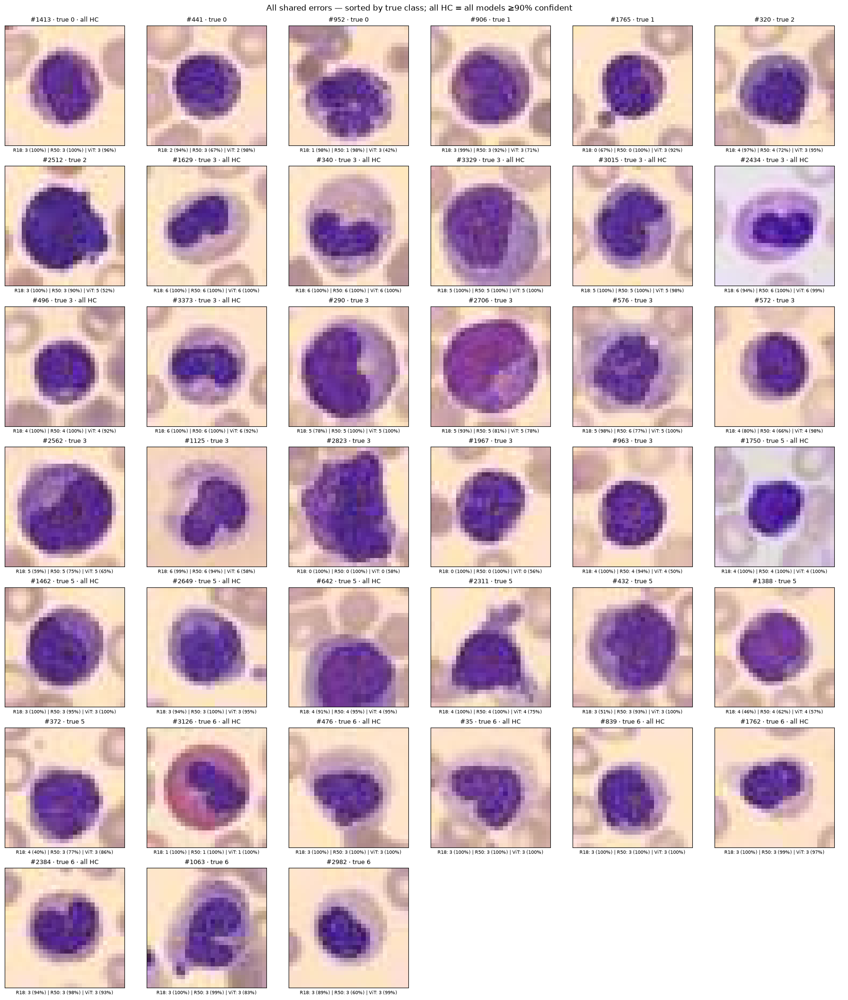

In [4]:
wrong = ~correct
high_wrong = wrong & (confidence >= threshold)
common_wrong = np.flatnonzero(wrong.all(0))
common_hc = np.flatnonzero(high_wrong.all(0))
exclusive_hc = [np.flatnonzero(high_wrong[m] & (wrong.sum(0) == 1)) for m in range(len(model_names))]
print('Shared errors:', len(common_wrong), 'with ≥90% confidence in all models:', len(common_hc))
print('Classes:', dict(enumerate(class_names)))

def gallery(ids, title, columns=6):
    rows = max(1, int(np.ceil(len(ids) / columns)))
    fig, axes = plt.subplots(rows, columns, figsize=(18, 3 * rows), squeeze=False, layout='constrained')
    for ax in axes.flat:
        ax.axis('off')
    for ax, i in zip(axes.flat, ids):
        ax.axis('on')
        ax.imshow(images[i])
        ax.set_title(f'#{i} · true {labels[i]}' + (' · all HC' if high_wrong[:, i].all() else ''), fontsize=9)
        ax.set_xlabel(' | '.join(f'{name}: {predicted[m, i]} ({confidence[m, i]:.0%})'
                                for m, name in enumerate(['R18', 'R50', 'ViT'])), fontsize=7, wrap=True)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(title)
    plt.show()

order = np.lexsort((-confidence[:, common_wrong].min(0), labels[common_wrong]))
gallery(common_wrong[order], 'All shared errors — sorted by true class; all HC = all models ≥90% confident')

Look for repeated wrong labels in the shared-error gallery, especially the images marked as highly confident in all models. All models misclassify 39 images, and the 18 shared HC errors receive the same wrong class from all three models, with nine substitutions between immature granulocytes and neutrophils. Agreement therefore leaves recurring class-specific blind spots rather than independently confirming the recorded label.

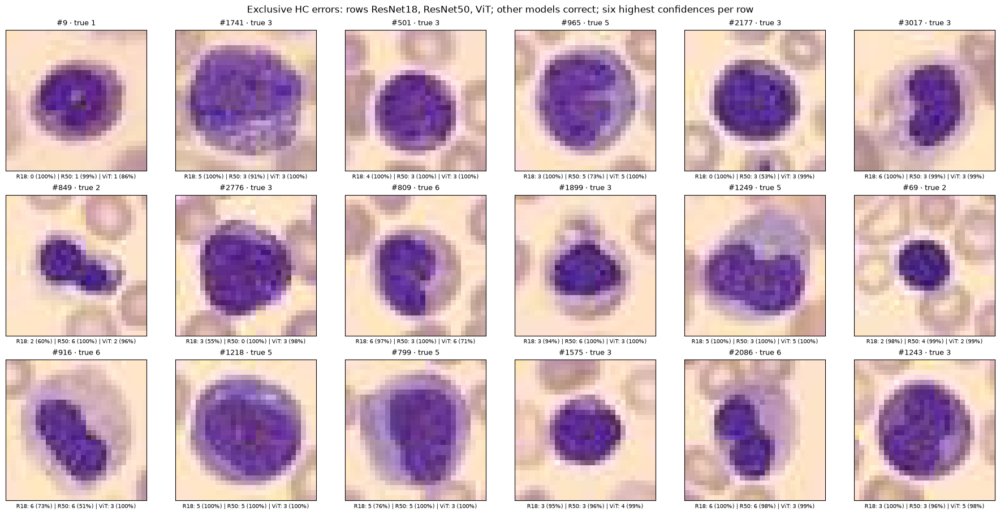

In [5]:
exclusive_examples = np.concatenate([ids[np.argsort(-confidence[m, ids], kind='stable')[:6]]
                                     for m, ids in enumerate(exclusive_hc)])
gallery(exclusive_examples, 'Exclusive HC errors: rows ResNet18, ResNet50, ViT; other models correct; six highest confidences per row')

Compare each row’s selected model with the other two models on the same images. The displayed high-confidence examples are wrong only for ResNet18, only for ResNet50 or only for ViT, while the other models classify them correctly. These exclusive failures show complementary behavior, but confidence-selected examples cannot establish that voting would resolve the shared errors.

## A · Matched images — errors beside similar same-class controls classified correctly with ≥90% confidence by every model

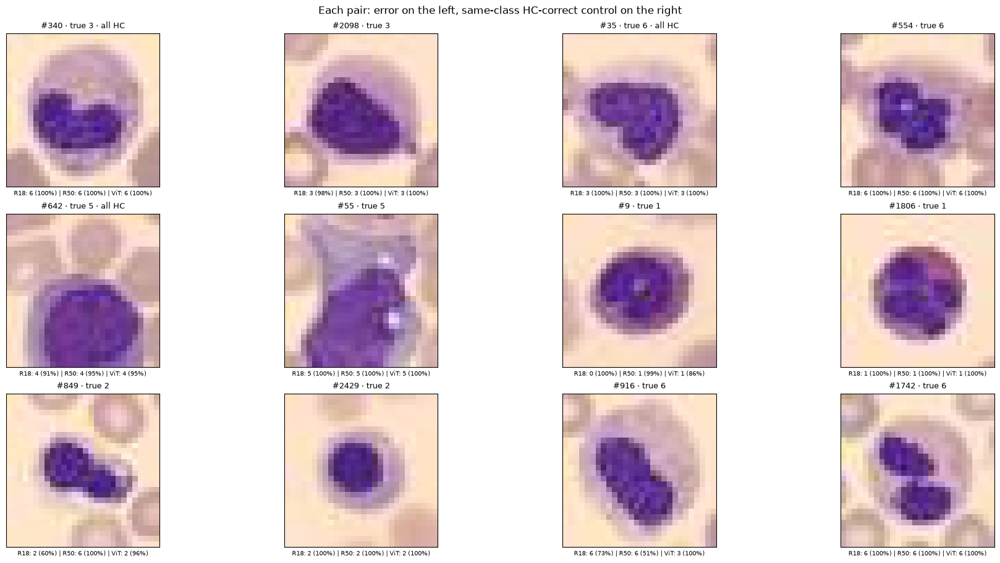

In [6]:
gallery_pairs = followup['gallery_pairs']
assert (correct[:, gallery_pairs[:, 1]] & (confidence[:, gallery_pairs[:, 1]] >= threshold)).all()
np.testing.assert_array_equal(labels[gallery_pairs[:, 0]], labels[gallery_pairs[:, 1]])
gallery(gallery_pairs.ravel(), 'Each pair: error on the left, same-class HC-correct control on the right', columns=4)

Compare each error image with its RGB-near same-class control, using the class and confidence labels to track their different decisions. Pairs #340/#2098 and #35/#554 have similar broad color and layout despite opposite correctness outcomes. Overall appearance alone therefore does not explain every error, while alignment-sensitive RGB matching cannot replace expert assessment of cell structures.

## Per-class high-confidence-error rates — class frequency is included in the denominator

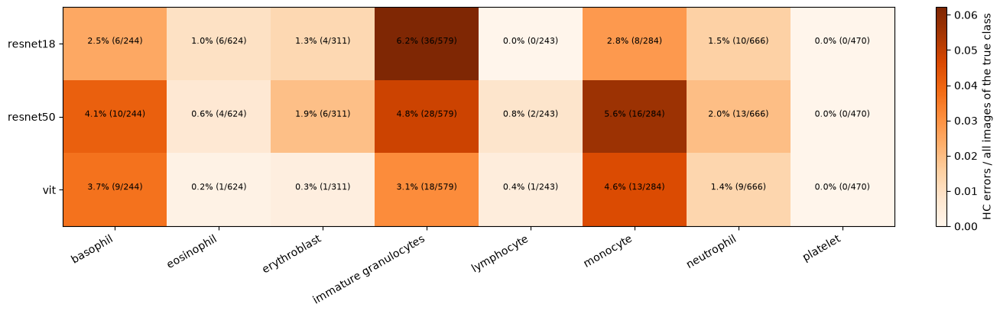

In [7]:
class_sizes = np.bincount(labels, minlength=8)
class_hc_counts = np.stack([np.bincount(labels[ids], minlength=8) for ids in error_ids])
class_hc_rates = class_hc_counts / class_sizes
fig, ax = plt.subplots(figsize=(13, 4), layout='constrained')
im = ax.imshow(class_hc_rates, cmap='Oranges', vmin=0, aspect='auto')
ax.set(xticks=range(8), xticklabels=class_names, yticks=range(3), yticklabels=model_names)
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
for m in range(3):
    for c in range(8):
        ax.text(c, m, f'{class_hc_rates[m,c]:.1%} ({class_hc_counts[m,c]}/{class_sizes[c]})', ha='center', fontsize=8)
fig.colorbar(im, ax=ax, label='HC errors / all images of the true class')
plt.show()

Compare HC-error rates within each true class rather than raw error counts. ResNet18 reaches 6.22% for immature granulocytes versus 2.05% overall, while monocytes have the highest rates for ResNet50 and ViT at 5.63% and 4.58%. Class frequency alone therefore does not explain the error concentration, and the differing rankings indicate checkpoint-specific weaknesses.

## True class → wrong predicted class — counts and percentages within each model's high-confidence errors, not class-specific error rates

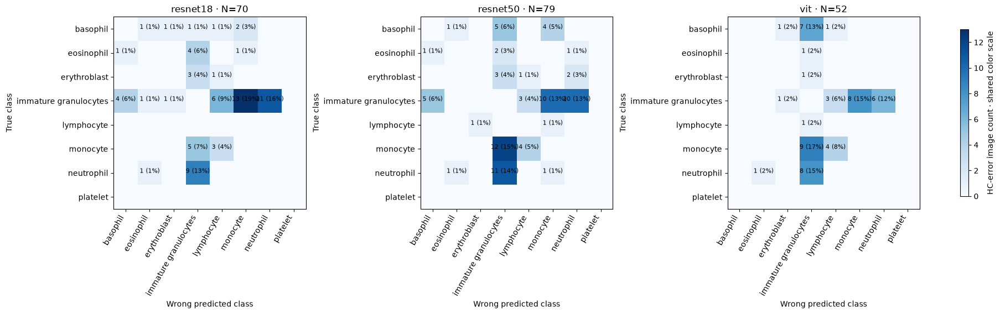

In [8]:
confusions = np.zeros((3, 8, 8), dtype=int)
for m, ids in enumerate(error_ids):
    np.add.at(confusions[m], (labels[ids], predicted[m, ids]), 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 6), layout='constrained')
for m, ax in enumerate(axes):
    im = ax.imshow(confusions[m], cmap='Blues', vmin=0, vmax=confusions.max())
    ax.set(title=f'{model_names[m]} · N={len(error_ids[m])}', xlabel='Wrong predicted class', ylabel='True class',
           xticks=range(8), xticklabels=class_names, yticks=range(8), yticklabels=class_names)
    plt.setp(ax.get_xticklabels(), rotation=60, ha='right')
    for c,d in zip(*np.nonzero(confusions[m])):
        ax.text(d,c,f'{confusions[m,c,d]} ({confusions[m,c,d]/len(error_ids[m]):.0%})',ha='center',fontsize=8)
fig.colorbar(im, ax=axes, shrink=.65, label='HC-error image count · shared color scale')
plt.show()

Read the true-to-predicted class counts to identify recurring substitutions, without treating them as per-class error rates. Immature granulocytes occur on either side of 58/70 ResNet18 error pairs, 61/79 ResNet50 pairs and 45/52 ViT pairs. These failures concentrate around particular class competitions, while the later class-rate view is needed to separate that concentration from class frequency.

## Appearance associations — three summaries rather than overlapping RGB distributions

The controls here are correctly classified images weighted to the HC errors’ true-class proportions, not one-to-one paired images. Brightness, saturation and image-border gradient fraction summarize intensity, color and spatial edge distribution without showing every correlated RGB channel. Full distributions and all seven original features remain in [archive.ipynb](archive.ipynb).

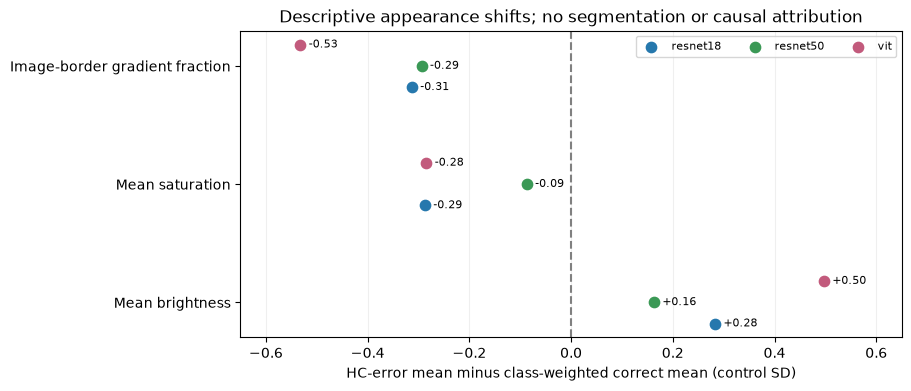

In [9]:
selected_features = [0, 1, 6]
feature_effects = analysis['feature_effects'][:, selected_features]
feature_labels = ['Mean brightness', 'Mean saturation', 'Image-border gradient fraction']
fig, ax = plt.subplots(figsize=(9, 3.8), layout='constrained')
for m, name in enumerate(model_names):
    y = np.arange(3) + (m-1)*.18
    ax.scatter(feature_effects[m], y, s=55, color=model_colors[m], label=name)
    for value, row in zip(feature_effects[m], y):
        ax.annotate(f'{value:+.2f}', (value,row), xytext=(6,0), textcoords='offset points', va='center', fontsize=8)
ax.axvline(0, color='gray', ls='--')
ax.set(yticks=range(3), yticklabels=feature_labels, xlim=(-.65,.65),
       xlabel='HC-error mean minus class-weighted correct mean (control SD)', title='Descriptive appearance shifts; no segmentation or causal attribution')
ax.legend(ncol=3, fontsize=8)
ax.grid(axis='x', alpha=.2)
plt.show()

Compare each model’s points with zero, where errors and class-weighted correct controls have the same feature mean. ViT errors are brighter by 0.50 control SD and have a lower image-border gradient fraction by 0.53 SD, while the CNN border-gradient shifts are −0.31 and −0.29 SD. These overlapping associations motivate interventions but do not identify a cell boundary, provide an error detector or establish which feature caused a mistake.

## Saturation intervention — original-decision support and the destination class

The same HC errors and nearest same-class HC-correct controls receive saturation factors from 0.5 to 1.5. The left panels retain every tested factor, while the right panels isolate the destination-class distribution at ×0.5 to make class collapse visible. Controls can be reused, so these paired cohorts are descriptive rather than independent replicated samples.

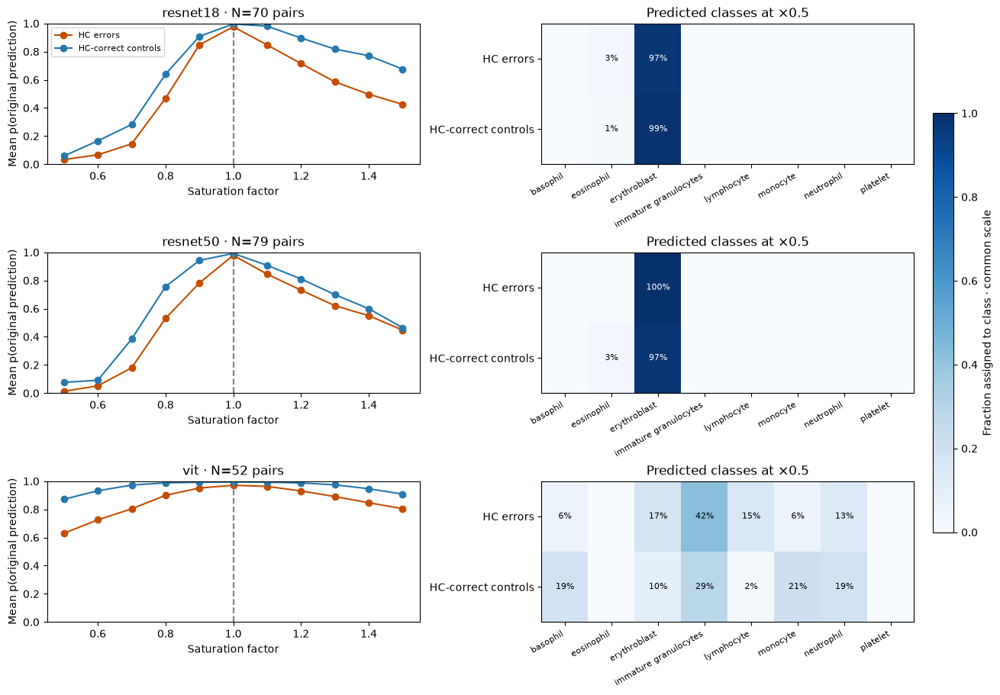

In [10]:
saturation_levels = analysis['saturation_levels']
saturation_index = int(np.argmin(np.abs(saturation_levels-.5)))
fig, axes = plt.subplots(3, 2, figsize=(13, 9), layout='constrained')
for m, name in enumerate(model_names):
    selected = analysis[f'{name}_saturation_ids']
    p = analysis[f'{name}_saturation_probabilities']
    np.testing.assert_allclose(p[:,5], probabilities[m,selected], atol=1e-5, rtol=1e-4)
    original = predicted[m,selected]
    retained = np.take_along_axis(p,original[:,None,:,None],axis=-1)[...,0]
    for role, title in enumerate(['HC errors','HC-correct controls']):
        axes[m,0].plot(saturation_levels,retained[role].mean(-1),'o-',label=title,
                       color=['#c44e00','#2678ad'][role])
    axes[m,0].axvline(1,color='gray',ls='--')
    axes[m,0].set(title=f'{name} · N={len(error_ids[m])} pairs',xlabel='Saturation factor',
                   ylabel='Mean p(original prediction)',ylim=(0,1))
    assigned = p[:,saturation_index].argmax(-1)
    distribution = np.stack([(assigned==c).mean(-1) for c in range(8)],axis=1)
    im = axes[m,1].imshow(distribution,vmin=0,vmax=1,cmap='Blues',aspect='auto')
    axes[m,1].set(title=f'Predicted classes at ×{saturation_levels[saturation_index]:g}',
                   xticks=range(8),xticklabels=class_names,yticks=[0,1],yticklabels=['HC errors','HC-correct controls'])
    plt.setp(axes[m,1].get_xticklabels(),rotation=30,ha='right',fontsize=8)
    for role,c in zip(*np.nonzero(distribution)):
        axes[m,1].text(c,role,f'{distribution[role,c]:.0%}',ha='center',va='center',fontsize=8,
                        color='white' if distribution[role,c]>.6 else 'black')
axes[0,0].legend(fontsize=8)
fig.colorbar(im,ax=axes[:,1],shrink=.7,label='Fraction assigned to class · common scale')
plt.show()

Follow original-decision support on the left and compare error/control destination classes at saturation ×0.5 on the right. ResNet18 assigns erythroblast to 68/70 errors and 69/70 controls, and ResNet50 to 79/79 errors and 77/79 controls, while ViT does not show that near-complete collapse. The shared CNN destination across different starting states supports color-dependent class assignment rather than a selective repair of initially wrong predictions.

## Occlusion — population context versus matched error-specific dependence

The top row averages all 3,421 test images; the bottom row subtracts same-class HC-correct controls from HC errors. Both rows use the same signed percentage-point scale, with positive values indicating original-decision support loss or additional loss among errors. The full class-by-class maps and correction diagnostics are preserved in [archive.ipynb](archive.ipynb).

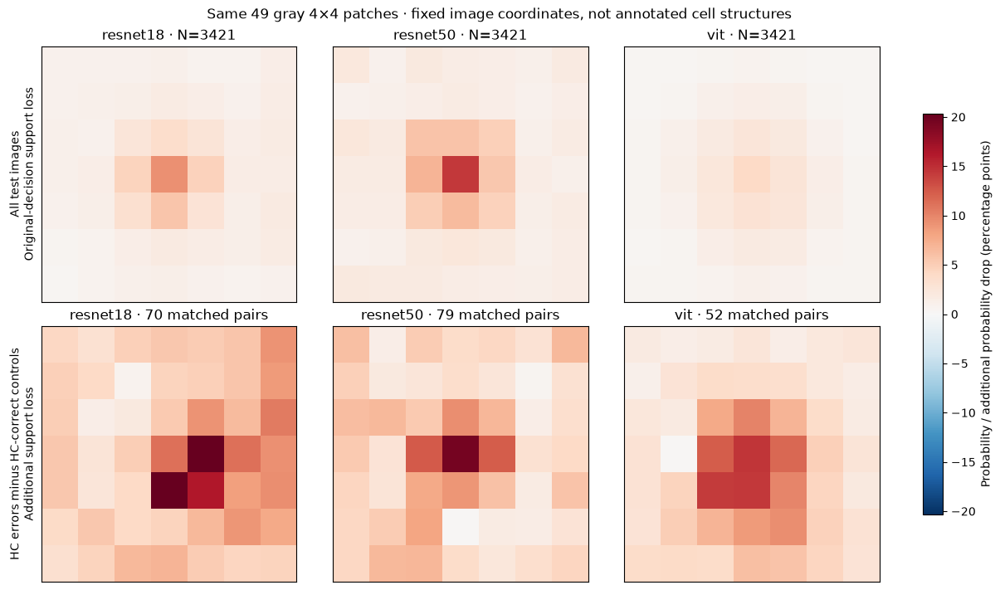

resnet18: original accuracy 96.61%; mean occluded accuracy 95.61%
resnet50: original accuracy 95.73%; mean occluded accuracy 94.23%
vit: original accuracy 96.99%; mean occluded accuracy 96.40%


In [11]:
with np.load('predictions/occlusion_test.npz',allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved['sample_index'],np.arange(len(labels)))
    np.testing.assert_array_equal(saved['baseline_probabilities'],probabilities)
    occluded = saved['probabilities']
original_support = np.take_along_axis(occluded,predicted[:,None,:,None],axis=-1)[...,0]
population_drop = (confidence[:,None]-original_support).transpose(0,2,1).reshape(3,len(labels),7,7)
paired_drop = []
for m,name in enumerate(model_names):
    selected = followup[f'{name}_ids']
    paired_drop.append((population_drop[m,selected[0]]-population_drop[m,selected[1]]).mean(0))
occlusion_maps = 100*np.stack([population_drop.mean(1),np.array(paired_drop)])
limit = max(np.abs(occlusion_maps).max(),1)
fig,axes = plt.subplots(2,3,figsize=(12,7),layout='constrained')
for row in range(2):
    for m,ax in enumerate(axes[row]):
        im=ax.imshow(occlusion_maps[row,m],cmap='RdBu_r',vmin=-limit,vmax=limit)
        ax.set(title=f'{model_names[m]} · '+(f'N={len(labels)}' if row==0 else f'{len(error_ids[m])} matched pairs'),xticks=[],yticks=[])
axes[0,0].set_ylabel('All test images\nOriginal-decision support loss')
axes[1,0].set_ylabel('HC errors minus HC-correct controls\nAdditional support loss')
fig.colorbar(im,ax=axes,shrink=.75,label='Probability / additional probability drop (percentage points)')
fig.suptitle('Same 49 gray 4×4 patches · fixed image coordinates, not annotated cell structures')
plt.show()
for m,name in enumerate(model_names):
    accuracy=(occluded[m].argmax(-1)==labels).mean()
    print(f'{name}: original accuracy {correct[m].mean():.2%}; mean occluded accuracy {accuracy:.2%}')

Compare the population row with the error-minus-control row rather than treating central dependence alone as an error explanation. HC errors have additional central support losses of 10.4, 9.8 and 11.3 percentage points for ResNet18, ResNet50 and ViT after matching true class and the ≥90% confidence threshold. This isolates differential dependence beyond the centered-crop effect, but exact confidence and anatomical structures are not matched.

## Transformation responses — detailed comparison in the stability notebook

Use the two grids in [stability_analysis.ipynb](stability_analysis.ipynb) to compare label consistency and accuracy across all ten levels of each transformation. The explorer below explains the balance of recovered errors, new errors and confidently wrong new errors without averaging away severity. The previous four-panel figures and targeted error/control curves are retained in [archive.ipynb](archive.ipynb).

## What drives the accuracy change? — interactive explorer

Compare recovered errors above zero with new errors below zero; dark orange marks new errors at ≥90% confidence. All panels use the same test-image denominator and linked axes, including while zooming. Choose a transformation, then wheel or drag to zoom; use Reset to return to the full range.

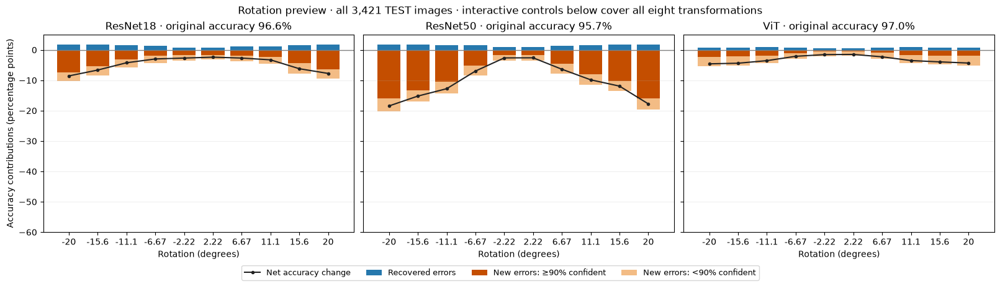

In [12]:
# Correctness changes explain accuracy; a switch between two wrong labels is not a gain or loss.
transition_data = dict(n=len(labels), threshold=threshold, models=['ResNet18', 'ResNet50', 'ViT'], operations={})
operation_names = {'rotation': ('Rotation', 'degrees'), 'translation': ('Translation', 'pixels'),
                   'brightness': ('Brightness', 'factor'), 'blur': ('Blur', 'pixels'),
                   'noise': ('Noise', 'sigma'), 'green_scale': ('Green scaling', 'factor'),
                   'red_scale': ('Red scaling', 'factor'), 'blue_scale': ('Blue scaling', 'factor')}
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    assert str(saved['split']) == 'test'
    np.testing.assert_array_equal(saved['indices'], np.arange(len(labels)))
    np.testing.assert_array_equal(saved['labels'], labels)
    np.testing.assert_array_equal(saved['baseline'], probabilities)
    was_correct = saved['baseline'].argmax(-1) == labels
    baseline_accuracy = 100 * was_correct.mean(-1)
    transition_data.update(baseline_accuracy=baseline_accuracy.tolist(),
                           baseline_errors=(~was_correct).sum(-1).tolist())
    for kind, (name, unit) in operation_names.items():
        p = saved[kind]
        now_correct = p.argmax(-1) == labels
        new_error = was_correct[:, None, None, :] & ~now_correct
        recovered = ~was_correct[:, None, None, :] & now_correct
        # Each original image has equal weight, including when noise has three repeats.
        counts = lambda mask: mask.mean(2).sum(-1)
        lost, gained = counts(new_error), counts(recovered)
        confident_lost = counts(new_error & (p.max(-1) >= threshold))
        np.testing.assert_allclose(baseline_accuracy[:, None] + 100 * (gained - lost) / len(labels),
                                   100 * now_correct.mean((2, 3)), atol=1e-10)
        assert (confident_lost <= lost).all()
        transition_data['operations'][kind] = dict(name=name, unit=unit, levels=saved[f'levels_{kind}'].tolist(),
            repeats=p.shape[2], lost=lost.tolist(), recovered=gained.tolist(), hc_lost=confident_lost.tolist())
max_loss = max(np.max(op['lost']) for op in transition_data['operations'].values())
max_gain = max(np.max(op['recovered']) for op in transition_data['operations'].values())
transition_data.update(ymin=float(-10 * np.ceil(100 * max_loss / len(labels) / 10)),
                       ymax=float(max(5, 5 * np.ceil(100 * max_gain / len(labels) / 5))))

# A static rotation preview remains readable on GitHub; the explorer below includes all operations.
preview = transition_data['operations']['rotation']
x = np.arange(len(preview['levels']))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True, layout='constrained')
for m, ax in enumerate(axes):
    gained, lost, hc = [100 * np.asarray(preview[key])[m] / len(labels) for key in ['recovered', 'lost', 'hc_lost']]
    ax.bar(x, gained, color='#2678ad', label='Recovered errors')
    ax.bar(x, -hc, color='#c44e00', label=f'New errors: ≥{threshold:.0%} confident')
    ax.bar(x, -(lost - hc), bottom=-hc, color='#f3bc85', label=f'New errors: <{threshold:.0%} confident')
    ax.plot(x, gained - lost, 'o-', color='#222', ms=3, label='Net accuracy change')
    ax.axhline(0, color='gray', lw=1)
    ax.set(title=f'{transition_data["models"][m]} · original accuracy {baseline_accuracy[m]:.1f}%',
           xticks=x, xticklabels=[f'{v:.3g}' for v in preview['levels']], xlabel='Rotation (degrees)',
           ylim=(transition_data['ymin'], transition_data['ymax']))
    ax.grid(axis='y', alpha=0.2)
axes[0].set_ylabel('Accuracy contributions (percentage points)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=4, fontsize=9)
fig.suptitle(f'Rotation preview · all {len(labels):,} TEST images · interactive controls below cover all eight transformations')
plt.show()


Compare bars above and below zero at the same level, then follow the black line to see which side dominates. At +20° rotation, ResNet50 recovers 60 errors but introduces 668 new ones, 547 of which are ≥90% confident, for a net accuracy loss of 17.8 percentage points. Helpful wrong-to-correct reversals are therefore overwhelmed by new, often confident errors, explaining why the overall accuracy falls despite some original mistakes becoming correct.

In [13]:
import html
from IPython.display import HTML, FileLink, display

# Self-contained HTML/SVG/JavaScript: no CDN, web service, widget backend or extra dependency.
transition_template = r'''<!doctype html>
<html lang="en"><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Transformation explorer</title>
<style>
*{box-sizing:border-box}body{font:14px system-ui,sans-serif;color:#252b32;max-width:1500px;margin:16px auto;padding:0 16px}h1{font-size:21px;margin:0}header,.toolbar,.legend{display:flex;align-items:center;flex-wrap:wrap;gap:12px}header{justify-content:space-between;margin-bottom:16px}.toolbar{gap:10px}label{display:flex;align-items:center;gap:8px;color:#58616b}select,button{font:inherit;background:white;border:1px solid #cfd5db;border-radius:5px;padding:5px 9px;color:#252b32}button{cursor:pointer}button:hover{background:#f1f4f7}button:focus-visible,select:focus-visible{outline:2px solid #2678ad}input{width:155px}output{min-width:94px;font-variant-numeric:tabular-nums}.legend{font-size:12px;color:#58616b;margin-bottom:12px;gap:18px}.swatch{display:inline-block;width:12px;height:9px;margin-right:5px}.models{display:grid;grid-template-columns:repeat(3,minmax(250px,1fr));gap:14px}.card{border:1px solid #e1e5e9;border-radius:7px;padding:12px}.model-head{display:flex;align-items:baseline;justify-content:space-between;gap:6px}.model-head h2{font-size:17px;margin:0}.accuracy{font-size:15px;font-weight:600;white-space:nowrap}.delta{font-size:12px;font-weight:400;color:#69737e;margin-left:6px}svg{width:100%;height:auto;touch-action:none;user-select:none;cursor:crosshair}.stats{display:grid;grid-template-columns:repeat(3,1fr);gap:8px;border-top:1px solid #edf0f3;padding-top:8px}.stats span{display:block;color:#69737e;font-size:11px}.stats strong{font-size:17px;font-weight:600;font-variant-numeric:tabular-nums}.footer{display:flex;justify-content:space-between;flex-wrap:wrap;gap:10px;margin-top:12px;color:#69737e;font-size:12px}details{margin-top:14px;color:#58616b;font-size:12px;line-height:1.6}summary{cursor:pointer}details p{max-width:1050px}a{color:#17689c}.selection{fill:#2678ad;fill-opacity:.12;stroke:#2678ad;stroke-dasharray:4 3;pointer-events:none}@media(max-width:850px){.models{grid-template-columns:1fr}header{align-items:flex-start}.toolbar{width:100%}}
</style>
<header><h1>Transformation explorer</h1><div class="toolbar"><select id="transformation" aria-label="Transformation"></select><label>Level <input id="level" aria-label="Transformation level" type="range" min="0" max="9" step="1" value="9"></label><output id="levelLabel" aria-live="polite"></output><button id="zoom-in" aria-label="Zoom in" title="Zoom into the selected level">+</button><button id="zoom-out" aria-label="Zoom out" title="Zoom out">−</button><button id="fit" title="Fit this transformation’s data, using the same axes for all models">Fit</button><button id="reset" title="Restore the shared full range">Reset</button></div></header>
<div class="legend"><span><i class="swatch" style="background:#2678ad"></i>Recovered</span><span><i class="swatch" style="background:#c44e00"></i>New: ≥__THRESHOLD__</span><span><i class="swatch" style="background:#f3bc85"></i>New: &lt;__THRESHOLD__</span><span>━━ Net accuracy change</span></div>
<div id="models" class="models"></div>
<div class="footer"><span id="status"></span><span>Wheel / drag to zoom · double-click to reset</span></div>
<details><summary>How to read · definitions · sources</summary><p>Bars above zero are originally wrong images that become correct; bars below zero are originally correct images that become wrong. Dark orange identifies new errors with confidence ≥__THRESHOLD__. The black line is recovered minus new errors, so it measures the net accuracy change. All contributions use the same full-test denominator, not different correct/wrong group sizes; switches between two wrong labels do not contribute. Header percentages show accuracy at the selected level, with the change from the original prediction beside them; hover for the original accuracy.</p><p>Zoom is linked across all three models. Drag a rectangle or use the wheel to zoom, click a bar or move the slider to inspect a level, use Fit for the current transformation’s range, or Reset / double-click for the full range. Changing transformations resets zoom. Noise counts are means of three realizations, not independent extra images. Transformed inputs may leave the data distribution or change the label: these views describe checkpoint responses, not a correction strategy.</p><p>Design: <a href="https://pmc.ncbi.nlm.nih.gov/articles/PMC7733875/">small multiples</a> · <a href="https://data.europa.eu/apps/data-visualisation-guide/the-information-seeking-mantra">overview, filter, details on demand</a>.</p></details>
<script>
const D=__DATA__;
const select=document.getElementById('transformation'), slider=document.getElementById('level');
for(const [key,p] of Object.entries(D.operations)){const o=document.createElement('option');o.value=key;o.textContent=p.name;select.append(o);}
const G={W:460,H:310,L:42,R:10,T:20,B:38};G.w=G.W-G.L-G.R;G.h=G.H-G.T-G.B;
const full={xmin:-.5,xmax:9.5,ymin:D.ymin,ymax:D.ymax};let view={...full},chosen=9,suppressClickUntil=0;
const fmt=x=>Math.abs(x)<1e-9?'0':Number(x.toPrecision(3)).toString();
const count=x=>Math.abs(x-Math.round(x))<1e-6?Math.round(x).toLocaleString():x.toFixed(1);
const pp=x=>(x>=0?'+':'')+x.toFixed(1)+' pp';
const X=j=>G.L+(j-view.xmin)/(view.xmax-view.xmin)*G.w;
const Y=v=>G.T+(view.ymax-v)/(view.ymax-view.ymin)*G.h;
const invX=x=>view.xmin+(x-G.L)/G.w*(view.xmax-view.xmin);
const invY=y=>view.ymax-(y-G.T)/G.h*(view.ymax-view.ymin);
function bounded(lo,hi,min,max,minSpan){const span=Math.min(max-min,Math.max(minSpan,hi-lo));lo=Math.max(min,Math.min((lo+hi-span)/2,max-span));return[lo,lo+span];}
function setView(xmin,xmax,ymin,ymax){[view.xmin,view.xmax]=bounded(xmin,xmax,full.xmin,full.xmax,1.5);[view.ymin,view.ymax]=bounded(ymin,ymax,full.ymin,full.ymax,.5);if(chosen<view.xmin||chosen>view.xmax){chosen=Math.max(0,Math.min(9,Math.round((view.xmin+view.xmax)/2)));slider.value=chosen;}render();}
function zoom(factor,cx=chosen,cy=0){setView(cx+(view.xmin-cx)*factor,cx+(view.xmax-cx)*factor,cy+(view.ymin-cy)*factor,cy+(view.ymax-cy)*factor);}
function reset(){view={...full};render();}
function ticks(lo,hi){const raw=(hi-lo)/5,power=10**Math.floor(Math.log10(raw)),r=raw/power,step=(r<=1?1:r<=2?2:r<=5?5:10)*power,result=[];for(let v=Math.ceil(lo/step)*step;v<=hi+step*1e-8;v+=step)result.push(v);return result;}
function chart(p,m){
 const dx=G.w/(view.xmax-view.xmin),clip=`clip${m}`;
 let s=`<svg viewBox="0 0 ${G.W} ${G.H}" data-model="${m}" role="img" aria-label="${D.models[m]}: zoomable accuracy contributions"><defs><clipPath id="${clip}"><rect x="${G.L}" y="${G.T}" width="${G.w}" height="${G.h}"/></clipPath></defs>`;
 s+=`<g clip-path="url(#${clip})"><rect x="${X(chosen)-dx/2}" y="${G.T}" width="${dx}" height="${G.h}" fill="#f5f7fa"/></g>`;
 for(const tick of ticks(view.ymin,view.ymax))s+=`<line x1="${G.L}" x2="${G.W-G.R}" y1="${Y(tick)}" y2="${Y(tick)}" stroke="${Math.abs(tick)<1e-8?'#969fa9':'#edf0f3'}"/><text x="${G.L-6}" y="${Y(tick)+4}" text-anchor="end" font-size="11" fill="#69737e">${fmt(tick)}</text>`;
 s+=`<text x="${G.L}" y="12" font-size="10" fill="#69737e">Accuracy contributions (pp)</text><g clip-path="url(#${clip})">`;
 for(let j=0;j<10;j++){
  const gain=100*p.recovered[m][j]/D.n,loss=100*p.lost[m][j]/D.n,hc=100*p.hc_lost[m][j]/D.n,a=X(j)-.33*dx,b=.66*dx;
  s+=`<g data-step="${j}" style="cursor:pointer"><title>${p.name} ${fmt(p.levels[j])} ${p.unit}: ${count(p.lost[m][j])} new (${count(p.hc_lost[m][j])} confident); ${count(p.recovered[m][j])} recovered</title><rect x="${X(j)-dx/2}" y="${G.T}" width="${dx}" height="${G.h}" fill="transparent"/><rect x="${a}" y="${Y(gain)}" width="${b}" height="${Y(0)-Y(gain)}" fill="#2678ad"/><rect x="${a}" y="${Y(0)}" width="${b}" height="${Y(-hc)-Y(0)}" fill="#c44e00"/><rect x="${a}" y="${Y(-hc)}" width="${b}" height="${Y(-loss)-Y(-hc)}" fill="#f3bc85"/></g>`;
 }
 const points=p.levels.map((_,j)=>`${X(j)},${Y(100*(p.recovered[m][j]-p.lost[m][j])/D.n)}`).join(' ');
 s+=`<polyline points="${points}" fill="none" stroke="#222" stroke-width="2" pointer-events="none"/><circle cx="${X(chosen)}" cy="${Y(100*(p.recovered[m][chosen]-p.lost[m][chosen])/D.n)}" r="4" fill="#222" pointer-events="none"/></g>`;
 const first=Math.max(0,Math.ceil(view.xmin)),last=Math.min(9,Math.floor(view.xmax)),stride=Math.max(1,Math.ceil((last-first+1)/6));
 for(let j=first;j<=last;j++)if((j-first)%stride===0||j===last||j===chosen)s+=`<text x="${X(j)}" y="${G.H-20}" text-anchor="middle" font-size="10" fill="#69737e">${fmt(p.levels[j])}</text>`;
 return s+`<text x="${G.L+G.w/2}" y="${G.H-3}" text-anchor="middle" font-size="10" fill="#69737e">${p.unit}</text></svg>`;
}
function localPoint(svg,e){const p=svg.createSVGPoint();p.x=e.clientX;p.y=e.clientY;return p.matrixTransform(svg.getScreenCTM().inverse());}
function inside(p){return p.x>=G.L&&p.x<=G.W-G.R&&p.y>=G.T&&p.y<=G.H-G.B;}
function bindZoom(svg){
 svg.addEventListener('wheel',e=>{const p=localPoint(svg,e);if(!inside(p))return;e.preventDefault();zoom(Math.exp(Math.max(-1,Math.min(1,e.deltaY*.002))),invX(p.x),invY(p.y));},{passive:false});
 svg.ondblclick=e=>{e.preventDefault();reset();};
 svg.onclick=e=>{if(Date.now()<suppressClickUntil)return;const p=localPoint(svg,e);if(inside(p)){chosen=Math.max(0,Math.min(9,Math.round(invX(p.x))));slider.value=chosen;render();}};
 let start=null,box=null;
 svg.onpointerdown=e=>{const p=localPoint(svg,e);if(e.button!==0||!inside(p))return;e.preventDefault();start=p;try{svg.setPointerCapture(e.pointerId);}catch{}box=document.createElementNS('http://www.w3.org/2000/svg','rect');box.setAttribute('class','selection');svg.append(box);};
 svg.onpointermove=e=>{if(!start)return;const p=localPoint(svg,e),x=Math.max(G.L,Math.min(G.W-G.R,p.x)),y=Math.max(G.T,Math.min(G.H-G.B,p.y));for(const[k,v]of Object.entries({x:Math.min(start.x,x),y:Math.min(start.y,y),width:Math.abs(x-start.x),height:Math.abs(y-start.y)}))box.setAttribute(k,v);};
 svg.onpointerup=e=>{if(!start)return;const p=localPoint(svg,e),x=Math.max(G.L,Math.min(G.W-G.R,p.x)),y=Math.max(G.T,Math.min(G.H-G.B,p.y)),a=start;start=null;box.remove();if(Math.abs(x-a.x)>6&&Math.abs(y-a.y)>6){suppressClickUntil=Date.now()+250;setView(invX(Math.min(x,a.x)),invX(Math.max(x,a.x)),invY(Math.max(y,a.y)),invY(Math.min(y,a.y)));}};
 svg.onpointercancel=()=>{start=null;if(box)box.remove();};
}
function render(){
 const p=D.operations[select.value],j=chosen;document.getElementById('levelLabel').textContent=fmt(p.levels[j])+' '+p.unit;
 document.getElementById('models').innerHTML=D.models.map((name,m)=>{const net=100*(p.recovered[m][j]-p.lost[m][j])/D.n,accuracy=D.baseline_accuracy[m]+net;return `<section class="card"><div class="model-head"><h2>${name}</h2><span class="accuracy" title="Original: ${D.baseline_accuracy[m].toFixed(1)}%; ${D.baseline_errors[m]} errors">${accuracy.toFixed(1)}%<span class="delta">${pp(net)}</span></span></div>${chart(p,m)}<div class="stats"><div><span>New errors</span><strong>${count(p.lost[m][j])}</strong></div><div><span>≥__THRESHOLD__ confident</span><strong>${count(p.hc_lost[m][j])}</strong></div><div><span>Recovered</span><strong>${count(p.recovered[m][j])}</strong></div></div></section>`;}).join('');
 document.querySelectorAll('svg').forEach(bindZoom);
 const zoomed=Object.keys(full).some(k=>Math.abs(view[k]-full[k])>1e-7);
 document.getElementById('status').textContent=`${D.n.toLocaleString()} TEST images · linked axes · ${zoomed?'zoomed':'full range'}`+(p.repeats===3?' · counts averaged over 3 noise realizations':'');
}
select.onchange=reset;slider.oninput=()=>{chosen=Number(slider.value);render();};
document.getElementById('zoom-in').onclick=()=>zoom(.65);document.getElementById('zoom-out').onclick=()=>zoom(1.6,(view.xmin+view.xmax)/2,(view.ymin+view.ymax)/2);
document.getElementById('reset').onclick=reset;
document.getElementById('fit').onclick=()=>{const p=D.operations[select.value],lo=-100*Math.max(...p.lost.flat())/D.n,hi=100*Math.max(...p.recovered.flat())/D.n,pad=Math.max(1,(hi-lo)*.08);setView(full.xmin,full.xmax,Math.max(full.ymin,lo-pad),Math.min(full.ymax,hi+pad));};
render();
</script></html>
'''
transition_html = transition_template.replace('__DATA__', json.dumps(transition_data, allow_nan=False).replace('</', '<\\/'))
transition_html = transition_html.replace('__THRESHOLD__', f'{threshold:.0%}')
transition_path = Path('visualizations/transformation_explorer.html')
transition_path.parent.mkdir(exist_ok=True)
transition_path.write_text(transition_html, encoding='utf-8')
display(HTML('<p>For interactive controls, trust this notebook or open the offline HTML.</p>'))
display(FileLink(str(transition_path), result_html_prefix='Standalone offline explorer: '))
display(HTML('<iframe title="Transformation transition explorer" sandbox="allow-scripts" '
             'style="width:100%;height:560px;border:1px solid #ddd" srcdoc="'
             + html.escape(transition_html, quote=True) + '"></iframe>'))


C:\Users\Viktor\projects\AI_and_Visualization_Project\visualizations\transformation_explorer.html

C:\Users\Viktor\AppData\Roaming\Python\Python314\site-packages\IPython\core\display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


## Main findings

- **Overconfidence:** Compare the reliability curves with the perfect-calibration diagonal. Mean confidence exceeds accuracy by 2.1, 2.9 and 1.6 percentage points for ResNet18, ResNet50 and ViT. Confidence therefore needs independent calibration checks rather than being treated as a correctness guarantee.
- **Recurring class competition:** Compare shared/exclusive samples with class rates and substitutions. The models share 18 HC errors with identical wrong labels, nine involving immature granulocytes and neutrophils, while the highest per-class rates differ by checkpoint. Their failures therefore include shared class-specific blind spots as well as complementary errors.
- **Color dependence:** Compare saturation destination classes in errors and same-class correct controls. At ×0.5, both CNNs assign almost every image in both cohorts to erythroblast, unlike ViT. This supports a testable dependence on saturation-related appearance rather than a selective correction of original mistakes.
- **Spatial dependence:** Compare population occlusion with the matched error-minus-control contrasts. Central support loss is greater for HC errors by 10.4, 9.8 and 11.3 percentage points across the three models. The contrast adds evidence beyond unsurprising central sensitivity but does not identify anatomical features or causal mechanisms.
- **Confident new failures:** Compare recoveries with newly wrong predictions in the explorer. At +20° rotation, ResNet50 recovers 60 errors but introduces 668 new errors, including 547 confident ones, losing 17.8 accuracy points overall. Some wrong-to-correct reversals therefore coexist with a much larger burden of new confident failures.

**Limits:** These are exploratory TEST-only checkpoint/pipeline comparisons, not independent confirmation of causal hypotheses. Controls match class and confidence threshold rather than exact confidence, can be reused, and RGB features are correlated. Preprocessing differs between pipelines, interventions may alter valid image content, and the tested severity ranges are not equal-strength comparisons between transformation types.

**Archive:** [archive.ipynb](archive.ipynb) preserves the complete previous notebooks, including entropy, all RGB distributions, detailed occlusion, original transformation panels and all PCA-based analyses.

## Intermediate stability_analysis.ipynb

# Transformation stability — consistency and correctness

Two comparison grids replace four plots for every transformation while retaining all ten levels and all 3,421 TEST images. The checkpoints use different preprocessing pipelines, so these are pipeline comparisons rather than a controlled architecture comparison. Full model loading, deterministic seeds, resumable inference, raw logits and previous visualizations are preserved in [archive.ipynb](archive.ipynb).

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

with np.load('data/bloodmnist.npz',allow_pickle=False) as saved:
    labels=saved['test_labels'].ravel()
with np.load('predictions/stability.npz',allow_pickle=False) as saved:
    assert str(saved['split'])=='test' and str(saved['noise_seed_scope'])=='original test index'
    np.testing.assert_array_equal(saved['indices'],np.arange(len(labels)))
    np.testing.assert_array_equal(saved['labels'],labels)
    assert len(labels)==3421
    baseline=saved['baseline']
    model_names=saved['model_names'].tolist()
    checkpoints=saved['checkpoints'].tolist()
    levels={key[7:]:saved[key] for key in saved.files if key.startswith('levels_')}
    base_class=baseline.argmax(-1)
    baseline_accuracy=(base_class==labels).mean(-1)
    curves={'Label changes':{},'Accuracy':{}}
    for kind,values in levels.items():
        p=saved[kind]
        assert p.shape==(3,10,3 if kind=='noise' else 1,len(labels),8)
        assigned=p.argmax(-1)
        # Equal weight per original image; the repeated-noise mean is not an enlarged sample.
        curves['Label changes'][kind]=(assigned!=base_class[:,None,None,:]).mean((2,3))
        curves['Accuracy'][kind]=(assigned==labels).mean((2,3))
model_colors=['#2678ad','#3b9956','#c25a7c']
axis_labels={'rotation':'Rotation (degrees)','translation':'Translation (pixels)',
             'brightness':'Brightness factor','blur':'Blur radius (pixels)','noise':'Noise σ',
             'green_scale':'Green factor','red_scale':'Red factor','blue_scale':'Blue factor'}
for name,accuracy,path in zip(model_names,baseline_accuracy,checkpoints):
    print(f'{name}: original accuracy {accuracy:.2%} · {path}')
def plot_comparison(metric):
    fig,axes=plt.subplots(2,4,figsize=(16,7),sharey=True,layout='constrained')
    for ax,(kind,values) in zip(axes.flat,levels.items()):
        for m,name in enumerate(model_names):
            ax.plot(values,curves[metric][kind][m],'o-',color=model_colors[m],label=name,ms=4)
            if metric=='Accuracy':
                ax.axhline(baseline_accuracy[m],color=model_colors[m],ls='--',alpha=.4)
        ax.set(title=axis_labels[kind],ylim=(0,1),yticks=np.linspace(0,1,5))
        ax.yaxis.set_major_formatter(PercentFormatter(1,decimals=0))
        ax.grid(alpha=.2)
    fig.legend(*axes[0,0].get_legend_handles_labels(),loc='outside lower center',ncol=3)
    fig.suptitle(f'{metric} · all {len(labels):,} TEST images · common 0–100% axes; no severity averaging')
    plt.show()

resnet18: original accuracy 96.61% · weights_bloodmnist/resnet18_224_1.pth
resnet50: original accuracy 95.73% · weights_bloodmnist/resnet50_28_1.pth
vit: original accuracy 96.99% · models/vit


## Do predictions keep the same label?

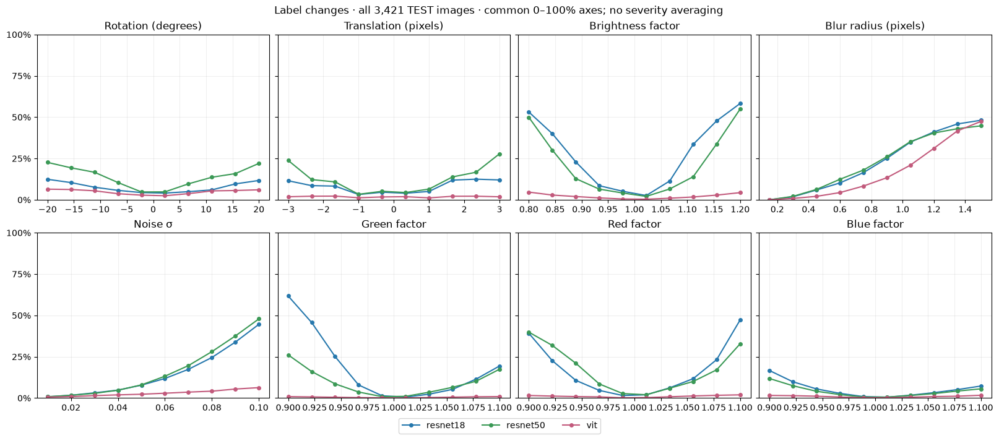

In [2]:
plot_comparison('Label changes')

Compare model curves within each panel and across transformations using the same percentage scale. Mean rotation flip rates are 7.7%, 14.0% and 4.8% for ResNet18, ResNet50 and ViT, while ViT reaches 17.0% under blur but only 2.9% under noise. Consistency is therefore intervention-specific, and a label change alone does not establish whether correctness improved or deteriorated.

## Are the predictions correct? — dashed lines show original accuracy

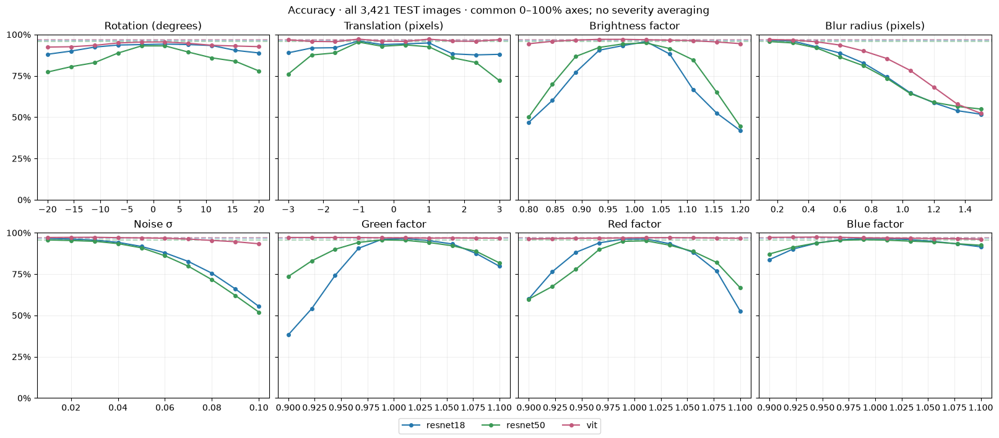

In [3]:
plot_comparison('Accuracy')

Compare accuracy with each model’s dashed baseline rather than inferring correctness from label stability alone. Mean brightness accuracy is 71.3%, 77.4% and 96.1% for ResNet18, ResNet50 and ViT, but strongest-blur accuracy converges to 51.8%, 54.9% and 52.3%. ViT’s advantage therefore depends on the intervention and does not imply uniformly greater robustness to removal of spatial detail.

## Explain the accuracy changes interactively

Use the explorer in [confidence_analysis.ipynb](confidence_analysis.ipynb), or download and open [the standalone HTML](visualizations/transformation_explorer.html). It separates recovered errors from new errors, highlights confidently wrong new errors, and provides synchronized zoom and per-level counts. Conditional transition plots, class-wise response maps, pairwise model differences and individual image sequences remain in [archive.ipynb](archive.ipynb).

# Targeted follow-up: reproducible experiment source

This TEST-only driver created `predictions/targeted_followup.npz`, using the actual checkpoints and shared preprocessing in `image_sandbox.py`. It uses one-to-one true-class matching with a 0.01 confidence caliper, 2,000 paired-image bootstrap draws stratified by true class, balanced 24-image ROI and 96-image interpolation probes, and equivalence gates before reusing native cached arms. No train/validation examples are queried.

The 24 core/expanded ROI overlays were visually inspected for gross plausibility, with #769 rejected for spillover and replaced by #663; the frozen digest is in the source and cache. This is **not expert cell segmentation**: pale cytoplasm can fall in the background complement, expanded masks can include background/neighbor material, and perturbation area/dose differ. The ROI experiment tests stained-object proxies and mask sensitivity, not an anatomical foreground/background causal separation.

The source is stored without executing it here. Run the explicitly marked replay cell below from the repository root to reproduce; it reuses signature-checked stage caches in `outputs/targeted_followup_cache/`, or computes missing stages with actual model inference. If masks change, inspect the complete contact sheet before deliberately updating its reviewed digest; do not bypass the gate.

In [ ]:
TARGETED_FOLLOWUP_SOURCE = r'''from pathlib import Path
import argparse
import hashlib
import json
import sys
import time
import numpy as np
from PIL import Image
from scipy import ndimage
from scipy.optimize import linear_sum_assignment
from threadpoolctl import threadpool_limits

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from image_sandbox import InferenceEngine, transform_image

CACHE = ROOT / 'outputs/targeted_followup_cache'
CACHE.mkdir(parents=True, exist_ok=True)
REVIEWED_MASK_SHA = '83f08bd138c526c8219c2d868aea249df123e3a589adf0c3ce087211d003652b'  # gross review, not expert segmentation
VISUAL_REJECTED_IDS = {769}  # core ROI visibly spills into neighboring/background material
SEED, CALIPER, BOOTSTRAPS = 42, .01, 2000
with np.load(ROOT/'data/bloodmnist.npz', allow_pickle=False) as z:
    images, labels = z['test_images'], z['test_labels'].ravel()
with np.load(ROOT/'predictions/high_confidence_error_analysis.npz', allow_pickle=False) as z:
    analysis = {k:z[k] for k in z.files}
baseline = analysis['baseline_probabilities']
predicted, confidence = baseline.argmax(-1), baseline.max(-1)
correct = predicted == labels
signature = hashlib.sha256(images.tobytes()+baseline.tobytes()+b'targeted-v1-caliper.01-boot2000-mask15-border90-dilate2-seed42-visual-exclude769').hexdigest()


def save(path, values):
    tmp = path.with_suffix('.tmp.npz')
    np.savez_compressed(tmp, signature=signature, **values)
    tmp.replace(path)


def stage(name, compute):
    path = CACHE / f'{name}.npz'
    if not path.exists():
        print('Computing', name, flush=True)
        save(path, compute())
    with np.load(path, allow_pickle=False) as z:
        assert str(z['signature']) == signature, f'Stale {name} cache'
        out = {k:z[k] for k in z.files if k != 'signature'}
    print('Ready', name, flush=True)
    return out


def approximate_mask(image):
    rgb = image.astype(float)
    border = np.ones((28,28), bool); border[2:-2,2:-2] = False
    bg = np.median(rgb[border], axis=0)
    distance = np.linalg.norm(rgb-bg, axis=-1)
    cutoff = max(15., float(np.quantile(distance[border], .90))+5.)
    binary = ndimage.binary_closing(distance > cutoff, iterations=1)
    components, n = ndimage.label(binary)
    if not n:return np.zeros((28,28),bool)
    yy,xx = np.indices((28,28))
    scores=[]
    for k in range(1,n+1):
        mask=components==k
        center=np.array([yy[mask].mean(),xx[mask].mean()])
        scores.append(mask.sum()*np.exp(-np.sum((center-13.5)**2)/98))
    return ndimage.binary_fill_holes(components == (int(np.argmax(scores))+1))


def prepare_masks():
    rng=np.random.default_rng(SEED)
    ids=[];core=[];expanded=[];rejected=[]
    clean=correct.all(0)&(confidence>=.9).all(0)
    for c in range(8):
        accepted=0
        for i in rng.permutation(np.flatnonzero(clean&(labels==c))):
            if int(i) in VISUAL_REJECTED_IDS:
                rejected.append(int(i));continue
            mask=approximate_mask(images[i]);area=mask.mean()
            if not (.005 if c==7 else .05)<=area<=.80:
                rejected.append(int(i));continue
            ids.append(i);core.append(mask);expanded.append(ndimage.binary_dilation(mask,iterations=2));accepted+=1
            if accepted==3:break
        assert accepted==3,f'Insufficient plausible masks in class {c}'
    masks=np.stack([core,expanded])
    soft=np.stack([[ndimage.gaussian_filter(m.astype(float),.7) for m in row] for row in masks])
    return dict(ids=np.array(ids),masks=masks,soft_masks=soft,rejected=np.array(rejected,dtype=int),
                mask_sha=hashlib.sha256(masks.tobytes()).hexdigest(),mask_names=['core','expanded'],
                mask_method='border median RGB distance > max(15,90th-border-distance+5); centered largest component; hole fill; expanded2; feather.7')


def mask_sheet(masks):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    fig,axes=plt.subplots(4,6,figsize=(15,9),layout='constrained')
    for j,(ax,i) in enumerate(zip(axes.flat,masks['ids'])):
        im=images[i]
        views=[im]
        for m in masks['masks'][:,j]:
            color=im.copy().astype(float);color[m]=.55*color[m]+.45*np.array([0,220,160]);views.append(color.astype(np.uint8))
        ax.imshow(np.concatenate(views,axis=1));ax.axis('off')
        ax.set_title(f'#{i} class{labels[i]} · core {masks["masks"][0,j].mean():.0%}\nOriginal | core | expanded',fontsize=8)
    fig.suptitle('Approximate ROIs: visual plausibility check, NOT expert cell segmentation')
    fig.savefig(CACHE/'mask_review.png',dpi=130)
    plt.close(fig)


def matching():
    with np.load(ROOT/'predictions/occlusion_test.npz',allow_pickle=False) as z:
        q=z['probabilities']
    support=np.take_along_axis(q,predicted[:,None,:,None],-1)[...,0]
    drop=(confidence[:,None]-support).transpose(0,2,1).reshape(3,len(labels),7,7)
    central=drop[:,:,2:5,2:5].mean((2,3))
    features=analysis['features'][:,[0,4,1]] # brightness, blue, saturation
    flat=images.reshape(len(images),-1).astype(np.float32)/255
    squared=np.square(flat).sum(-1)
    out={};rng=np.random.default_rng(SEED)
    for m,name in enumerate(analysis['model_names']):
        errors=analysis[f'{name}_error_ids'];pairs=[]
        for c in range(8):
            e=errors[labels[errors]==c];pool=np.flatnonzero(correct[m]&(confidence[m]>=.9)&(labels==c))
            if not len(e):continue
            delta=np.abs(confidence[m,e,None]-confidence[m,pool][None])
            with threadpool_limits(limits=4):
                rmse=np.sqrt(np.maximum(squared[e,None]+squared[pool][None]-2*flat[e]@flat[pool].T,0)/flat.shape[1])
            cost=np.where(delta<=CALIPER,delta/CALIPER+1e-3*rmse,1e6)
            cost=np.column_stack([cost,np.full((len(e),len(e)),2.)])
            rows,cols=linear_sum_assignment(cost)
            pairs += [(int(e[r]),int(pool[d])) for r,d in zip(rows,cols) if d<len(pool) and delta[r,d]<=CALIPER]
        pairs=np.array(sorted(pairs),dtype=int)
        assert len(np.unique(pairs[:,1]))==len(pairs)
        np.testing.assert_array_equal(labels[pairs[:,0]],labels[pairs[:,1]])
        gaps=np.abs(confidence[m,pairs[:,0]]-confidence[m,pairs[:,1]])
        assert gaps.max()<=CALIPER
        e,c=pairs.T
        sd=features[c].std(0)
        effect=(features[e]-features[c]).mean(0)/np.maximum(sd,1e-8)
        central_difference=100*(central[m,e]-central[m,c])
        draws=np.column_stack([rng.choice(np.flatnonzero(labels[e]==cls),size=(BOOTSTRAPS,np.sum(labels[e]==cls)))
                               for cls in np.unique(labels[e])])
        bootstrap=(features[e][draws]-features[c][draws]).mean(1)/np.maximum(features[c][draws].std(1),1e-8)
        ci=np.quantile(bootstrap,[.025,.975],axis=0)
        occlusion_ci=np.quantile(central_difference[draws].mean(1),[.025,.975])
        out.update({f'{name}_pairs':pairs,f'{name}_confidence_gaps':gaps,f'{name}_unmatched':np.setdiff1d(errors,e),
                    f'{name}_feature_effect':effect,f'{name}_feature_ci':ci,f'{name}_central_difference':central_difference,
                    f'{name}_central_ci':occlusion_ci})
        print(name,'matched',len(pairs),'of',len(errors),'mean gap',gaps.mean(),flush=True)
    out.update(caliper=CALIPER,bootstrap_repeats=BOOTSTRAPS,feature_indices=[0,4,1],
               feature_names=['Brightness','Mean blue','Saturation'],
               method='one-to-one true-class matching; confidence gap<=.01; confidence cost, tiny RGB tie-break; paired image bootstrap within true class')
    return out


def examples():
    chosen=[];specs=[];prob=[];changed=[]
    allowed={'translation':1.,'brightness':.05,'noise':.03}
    with np.load(ROOT/'predictions/stability.npz',allow_pickle=False) as z:
        for kind,limit in allowed.items():
            values=z[f'levels_{kind}'];q=z[kind]
            distance=np.abs(values-(1 if kind=='brightness' else 0))
            found=False
            for j in np.argsort(distance,kind='stable'):
                if distance[j]>limit+1e-12:continue
                flipped=(q[:,j,0].argmax(-1)!=predicted).any(0)
                eligible=np.flatnonzero(flipped&correct.all(0)&(confidence>=.9).all(0))
                eligible=eligible[~np.isin(eligible,chosen)]
                if not len(eligible):continue
                preferred=eligible[np.isin(labels[eligible],[3,6])]
                i=int((preferred if len(preferred) else eligible)[0]);level=values[j]
                chosen.append(i);specs.append((kind,float(level)));prob.append(q[:,j,0,i])
                changed.append(transform_image(images[i],kind,level,test_id=i))
                found=True;break
            assert found,f'No mild all-correct HC flip for {kind}'
    return dict(ids=chosen,kinds=[p[0] for p in specs],levels=[p[1] for p in specs],images=np.array(changed),
                probabilities=np.stack(prob,axis=1),baseline=baseline[:,chosen],
                selection='first original TEST index among all-model HC-correct small-change flips; prefer IG/neut; representative behaviors, not prevalence')


def roi_queries(engine,masks):
    ids=masks['ids'];specs=[('brightness',.9),('brightness',1.1),('saturation',.5),('saturation',1.5),('red_scale',.9),('green_scale',.9)]
    queries=[]
    for k in range(2):
        for kind,level in specs:
            whole=np.stack([transform_image(images[i],kind,level,test_id=int(i)) for i in ids])
            delta=whole.astype(float)-images[ids]
            for scope in [np.ones_like(masks['soft_masks'][k]),masks['soft_masks'][k],1-masks['soft_masks'][k]]:
                queries.append(np.rint(np.clip(images[ids]+delta*scope[...,None],0,255)).astype(np.uint8))
    queries=np.stack(queries).reshape(2,6,3,len(ids),28,28,3)
    p,logits=engine.predict(queries.reshape(-1,28,28,3))
    p=p.reshape(3,2,6,3,len(ids),8);logits=logits.reshape(p.shape)
    rms=np.sqrt(np.square((queries.astype(float)-images[ids])/255).mean((-1,-2,-3)))
    return dict(ids=ids,masks=masks['masks'],soft_masks=masks['soft_masks'],images=queries,
                probabilities=p,logits=logits,rms=rms,baseline=baseline[:,ids],
                kinds=[s[0] for s in specs],levels=[s[1] for s in specs],scopes=['whole image','foreground ROI','background ROI'],
                mask_names=masks['mask_names'],mask_sha=masks['mask_sha'],
                visual_review='gross visible-object overlap checked by agent; approximate ROI, not expert segmentation; dose and area differ')


def interpolation_queries(engine):
    rng=np.random.default_rng(SEED+1)
    ids=np.concatenate([rng.choice(np.flatnonzero(labels==c),12,replace=False) for c in range(8)])
    modes=['nearest','bilinear','bicubic']
    with np.load(ROOT/'predictions/stability.npz',allow_pickle=False) as z:
        noise_levels=z['levels_noise'][[0,4,9]]
        native=np.concatenate([baseline[:,None,ids].astype(np.float32),z['noise'][:,[0,4,9]][:,:,:,ids].reshape(3,9,len(ids),8)],axis=1)
        native_logits=np.concatenate([z['baseline_logits'][:,None,ids],z['logits_noise'][:,[0,4,9]][:,:,:,ids].reshape(3,9,len(ids),8)],axis=1)
    q=[images[ids]]
    for level in noise_levels:
        for repeat in range(3):
            q.append(np.stack([transform_image(images[i],'noise',level,test_id=int(i),repeat=repeat) for i in ids]))
    q=np.stack(q)
    p=np.empty((3,3,10,len(ids),8),np.float32);logits=np.empty_like(p)
    for m in range(3):
        native_mode=0 if m==0 else 1
        for j,mode in enumerate(modes):
            if m==1 or j==native_mode:
                p[m,j],logits[m,j]=native[m],native_logits[m]
                # Confirm the shared PIL/native equivalence before reusing a complete cached arm.
                if m!=1:
                    checks=np.concatenate([q[0,:8],q[4,:8]])
                    observed,_=engine.predict_one(m,checks,interpolation=mode)
                    expected=np.concatenate([native[m,0,:8],native[m,4,:8]])
                    np.testing.assert_allclose(observed,expected,atol=1e-5,rtol=1e-4)
                    np.testing.assert_array_equal(observed.argmax(-1),expected.argmax(-1))
            else:
                out,score=engine.predict_one(m,q.reshape(-1,28,28,3),interpolation=mode)
                p[m,j]=out.reshape(10,len(ids),8);logits[m,j]=score.reshape(10,len(ids),8)
            print('Interpolation',m,mode,'complete',flush=True)
    return dict(ids=ids,probabilities=p,logits=logits,modes=modes,noise_levels=noise_levels,
                baseline_native=baseline[:,ids],native_modes=['nearest','native28','bilinear'],
                method='balanced96 TEST images; identical noisy28 inputs; common PIL224 resize for R18/ViT; R50 stays28; native arms equivalence-gated and reused')


def run():
    masks=stage('masks',prepare_masks)
    mask_sheet(masks)
    assert REVIEWED_MASK_SHA is not None and str(masks['mask_sha'])==REVIEWED_MASK_SHA,'Inspect mask_review.png and freeze its digest first'
    matched=stage('matching',matching)
    ex=stage('examples',examples)
    engine=None
    def get_engine():
        nonlocal engine
        if engine is None:
            engine=InferenceEngine();p,_=engine.predict(images[:32])
            np.testing.assert_allclose(p,baseline[:,:32],atol=1e-5,rtol=1e-4)
            np.testing.assert_array_equal(p.argmax(-1),predicted[:,:32])
        return engine
    roi=stage('roi',lambda:roi_queries(get_engine(),masks))
    interp=stage('interpolation',lambda:interpolation_queries(get_engine()))
    # Check selected small-flip inputs reproduce the full population experiment, not just its labels.
    for j,kind in enumerate(ex['kinds']):
        p,_=get_engine().predict(ex['images'][j:j+1])
        np.testing.assert_allclose(p[:,0],ex['probabilities'][:,j],atol=1e-5,rtol=1e-4)
    for data in [roi,interp]:
        scores=data['logits'].astype(float);scores-=scores.max(-1,keepdims=True);e=np.exp(scores)
        np.testing.assert_allclose(e/e.sum(-1,keepdims=True),data['probabilities'],atol=2e-7,rtol=1e-5)
    result=dict(split='test',seed=SEED,model_names=analysis['model_names'],labels=labels,
                input_sha256=hashlib.sha256(images.tobytes()).hexdigest(),mask_review=REVIEWED_MASK_SHA,
                baseline_probabilities=baseline, weight_hashes=get_engine().weight_hashes)
    for prefix,data in [('matching',matched),('examples',ex),('roi',roi),('interpolation',interp)]:
        result.update({f'{prefix}_{k}':v for k,v in data.items()})
    save(ROOT/'predictions/targeted_followup.npz',result)
    print('Validated targeted_followup.npz',flush=True)


if __name__=='__main__':
    parser=argparse.ArgumentParser();parser.add_argument('--prepare-masks',action='store_true');args=parser.parse_args()
    if args.prepare_masks:
        masks=stage('masks',prepare_masks);mask_sheet(masks);print('MASK SHA:',str(masks['mask_sha']),flush=True)
    else:run()
'''

In [ ]:
# OPTIONAL: actual checkpoint inference; not part of the fast main results.
namespace = {'__name__': '__archived_targeted_followup__'}
exec(compile(TARGETED_FOLLOWUP_SOURCE, 'archived_targeted_followup', 'exec'), namespace)
namespace['run']()

## Recorded complete mask review

Original | core overlay | expanded overlay for all 24 accepted images; recorded from the actual pre-inference review. #769 was rejected for visible spillover and replaced with #663. The code below regenerates the sheet from the published cache without model inference; overlays are gross agent-reviewed ROI proxies, not verified segmentation.

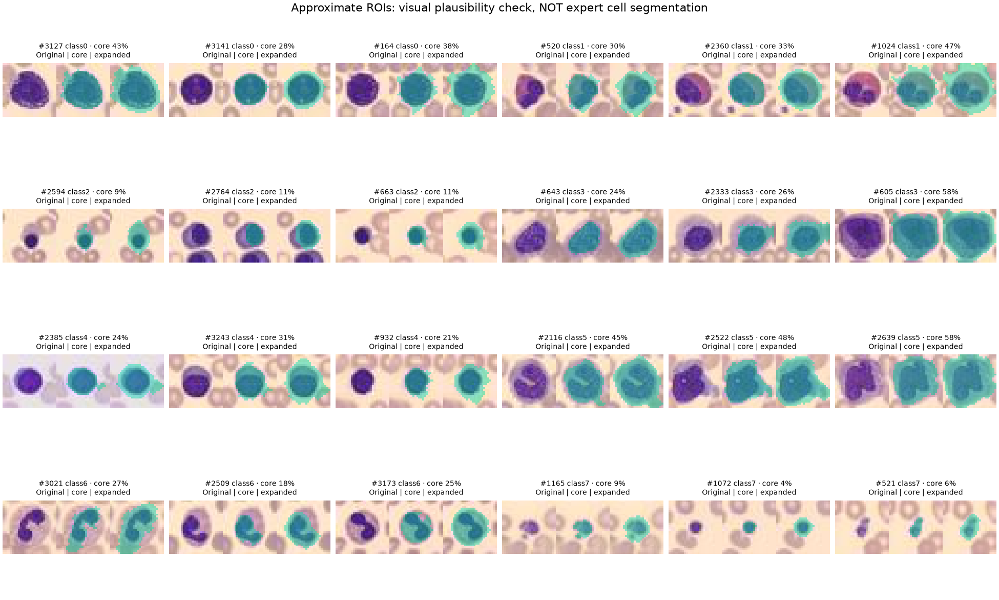

In [ ]:
# Regenerate the complete recorded visual review from the published TEST-only cache.
import numpy as np
import matplotlib.pyplot as plt
with np.load('data/bloodmnist.npz',allow_pickle=False) as saved:
    review_images,review_labels=saved['test_images'],saved['test_labels'].ravel()
with np.load('predictions/targeted_followup.npz',allow_pickle=False) as saved:
    review_ids,review_masks=saved['roi_ids'],saved['roi_masks']
fig,axes=plt.subplots(4,6,figsize=(15,9),layout='constrained')
for j,(ax,i) in enumerate(zip(axes.flat,review_ids)):
    im=review_images[i];views=[im]
    for mask in review_masks[:,j]:
        overlay=im.astype(float).copy();overlay[mask]=.55*overlay[mask]+.45*np.array([0,220,160]);views.append(overlay.astype(np.uint8))
    ax.imshow(np.concatenate(views,axis=1));ax.axis('off')
    ax.set_title(f'#{i} class{review_labels[i]} · core {review_masks[0,j].mean():.0%}\nOriginal | core | expanded',fontsize=8)
fig.suptitle('Approximate ROIs: visual plausibility check, NOT expert cell segmentation')
plt.show()


## Previous IG/neutrophil framing — before the descriptive editorial revision

The following three paragraphs preserve the earlier question/interpretation wording. The main notebook now emphasizes observable properties distinguishing selected misclassifications, rather than explaining their causes; all code and results are unchanged.

## Final focused investigation · why are immature granulocytes and neutrophils confused?

**Question:** Do the two directions share an appearance signature, excessive central dependence, or a simple image change that selectively repairs the mistakes?

**Biological motivation, not an image diagnosis:** The source [PBC dataset paper (Acevedo et al., 2020)](https://pmc.ncbi.nlm.nih.gov/articles/PMC7182702/) pools promyelocytes, myelocytes and metamyelocytes into the IG class and reports original images of 360×363 pixels. [ASH Image Bank](https://imagebank.hematology.org/image/60395/segmented-neutrophil) describes nuclear segmentation and chromatin in mature neutrophils; loss of such fine maturation cues in the available 28×28 images is a plausible hypothesis, **not a demonstrated cause here**. Upscaling the supplied 28px images to 224 does not restore missing detail, and no paired high-resolution images, IG subtype labels or expert nuclear annotations are available in this analysis.

**Evidence/design:** Restrict the existing one-to-one same-true-class, ≥90%-confidence, ≤1-percentage-point-confidence-gap pairs to HC errors predicted as the opposite member of {IG, neutrophil}. Compare the two directions separately for brightness, saturation and boundary-gradient fraction; then test central-versus-border occlusion and five mild cached perturbations against the same controls. This is a post-hoc TEST-only subgroup investigation, not new inference or independent confirmation; individual models' cohorts overlap and are not independent replications.

Compare the two directions in the top row, then ask whether a spatial contrast or mild intervention offers evidence beyond the appearance association. IG→neutrophil errors have brighter, less saturated and lower-boundary-fraction point estimates in all three models, whereas reverse-direction shifts are smaller or mixed; all excess-center intervals include zero and no tested mild edit has a strictly positive lower selective-repair bound. These results support a direction-dependent appearance/framing association rather than one demonstrated cause, and they do not establish excessive nuclear reliance, a simple color correction or annotation mistakes.

### Answer: a directional appearance pattern, not a proven biological mechanism

Read the appearance differences as evidence about the supplied pixels, and the paired perturbations as checks against easy causal explanations. The clearest recurring pattern is on **IG→neutrophil** errors, not equally in the reverse direction, while the tested changes do not selectively repair the subgroup with a clearly positive interval and the matched spatial contrast remains inconclusive. A heterogeneous maturation class and lost fine detail at 28px are plausible background explanations, but establishing **why a specific nucleus was misread** requires original-resolution, subtype-resolved expert review and controlled follow-up rather than stronger claims from these images alone.

# Complete snapshots before final branch consolidation

Replaced variants are preserved in full. Only cell IDs are namespaced for uniqueness; code, outputs and cell metadata are unchanged. The maintained notebooks no longer run train/validation inference or mix the legacy ResNet50 result with the final checkpoints.

## Pre-finalization confidence_analysis.ipynb

# BloodMNIST: disagreement, confidence, stability and possible drivers

**Scope:** 3,421 TEST images; the same ResNet18, supplied ResNet50 and local ViT checkpoints throughout. These are exploratory checkpoint-plus-preprocessing comparisons, not isolated architectural effects or independent hypothesis confirmation.

1. [Where do models disagree?](#story-1) — shared/exclusive errors, classes and images.
2. [Can we trust confidence?](#story-2) — reliability and tightly matched confidently wrong examples.
3. [Which changes destabilize predictions?](#story-3) — robustness grids, tiny-change flips, interpolation controls and interactive exploration.
4. [What might drive differences?](#story-4) — saturation, matched appearance/occlusion and approximate spatial color interventions.

Each story follows **question → evidence → interpretation**. Main notebooks read validated caches without loading models; [archive.ipynb](archive.ipynb) preserves complete original and intermediate notebooks, all removed/replaced plots and the targeted experiment source. The [live editing app](http://127.0.0.1:8765) runs actual model inference after `python image_sandbox.py` (see README); unlike the offline explorer, it needs the local Python server.

In [1]:
from pathlib import Path
from itertools import combinations
import hashlib
import json
import numpy as np
import matplotlib.pyplot as plt

# Main results are fast, CPU-only views of published caches; full computation is in archive.ipynb.
with np.load('data/bloodmnist.npz', allow_pickle=False) as saved:
    images, labels = saved['test_images'], saved['test_labels'].ravel()
with np.load('predictions/high_confidence_error_analysis.npz', allow_pickle=False) as saved:
    analysis = {key:saved[key] for key in saved.files}
with np.load('predictions/high_confidence_followup.npz', allow_pickle=False) as saved:
    followup = {key:saved[key] for key in saved.files}
model_names, class_names = analysis['model_names'].tolist(), analysis['class_names'].tolist()
probabilities = analysis['baseline_probabilities']
threshold, n_bins = float(analysis['threshold']), 10
assert str(analysis['split']) == 'test' and len(labels) == 3421
np.testing.assert_array_equal(analysis['true_labels'], labels)
assert probabilities.shape == (3, len(labels), 8)
np.testing.assert_allclose(probabilities.sum(-1), 1, atol=1e-6)
for m, name in enumerate(model_names):
    with np.load(f'predictions/{name}_test.npz', allow_pickle=False) as saved:
        assert str(saved['split']) == 'test'
        np.testing.assert_array_equal(saved['sample_index'], np.arange(len(labels)))
        np.testing.assert_array_equal(saved['labels'], labels)
        np.testing.assert_allclose(saved['probabilities'], probabilities[m], atol=1e-8, rtol=1e-6)
predicted, confidence = probabilities.argmax(-1), probabilities.max(-1)
correct = predicted == labels
error_ids = [analysis[f'{name}_error_ids'] for name in model_names]
high_confidence_wrong = dict(zip(model_names, error_ids))
for m, (name, ids) in enumerate(zip(model_names, error_ids)):
    np.testing.assert_array_equal(np.sort(ids), np.flatnonzero(~correct[m] & (confidence[m] >= threshold)))
    selected = analysis[f'{name}_saturation_ids']
    np.testing.assert_array_equal(selected, followup[f'{name}_ids'])
    np.testing.assert_array_equal(labels[selected[0]], labels[selected[1]])
    assert correct[m, selected[1]].all() and (confidence[m, selected] >= threshold).all()
# Verify the dataset/cache signature without loading models or redoing inference.
with np.load('predictions/occlusion_test.npz', allow_pickle=False) as saved:
    signature = hashlib.sha256(images.tobytes() + labels.tobytes() + probabilities.tobytes()
        + saved['positions'].tobytes() + str(saved['weight_hashes'].tolist()).encode()
        + b'gray128_resnet18-nearest224_resnet50-28_vit-local_v1').hexdigest()
    assert str(saved['signature']) == signature
bins = np.linspace(0, 1, n_bins + 1)
def bin_ids(values):
    return np.clip(np.searchsorted(bins, values, side='right') - 1, 0, n_bins - 1)
pairs = list(combinations(range(3), 2))
model_colors = ['#2678ad', '#3b9956', '#c25a7c']
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=model_colors)
print(f'{len(labels):,} TEST images; HC-error threshold {threshold:.0%}; counts: '+', '.join(f'{n}: {len(ids)}' for n, ids in zip(model_names, error_ids)))
with np.load('predictions/targeted_followup.npz',allow_pickle=False) as saved:
    targeted = {k:saved[k] for k in saved.files}
assert str(targeted['split']) == 'test'
np.testing.assert_array_equal(targeted['labels'],labels)
np.testing.assert_array_equal(targeted['baseline_probabilities'],probabilities)
assert str(targeted['input_sha256']) == hashlib.sha256(images.tobytes()).hexdigest()
assert str(targeted['roi_mask_sha']) == str(targeted['mask_review'])
with np.load('predictions/occlusion_test.npz',allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved['weight_hashes'],targeted['weight_hashes'])
matched_pairs = [targeted[f'matching_{name}_pairs'] for name in model_names]
for m, pair in enumerate(matched_pairs):
    e,c=pair.T
    assert len(np.unique(c))==len(c)
    np.testing.assert_array_equal(labels[e],labels[c])
    assert (~correct[m,e]).all() and correct[m,c].all()
    assert (confidence[m,pair]>=threshold).all()
    assert np.max(np.abs(confidence[m,e]-confidence[m,c]))<=.01
from IPython.display import display, Markdown


3,421 TEST images; HC-error threshold 90%; counts: resnet18: 70, resnet50: 79, vit: 52


<a id="story-1"></a>
## 1 · Where do models disagree?

**Question:** Are failures shared blind spots, model-specific mistakes, or recurring competition between particular classes?

**Evidence:** Read overlap first, then the actual images and class-conditioned rates; raw error counts alone mix class frequency with risk.

## High-confidence-error overlap — all three models and each model pair; model-relative percentages and Jaccard have different denominators

Errors shared by all three: 18 test IDs: [35, 340, 476, 496, 642, 839, 1413, 1462, 1629, 1750, 1762, 2384, 2434, 2649, 3015, 3126, 3329, 3373]
resnet18 / resnet50: shared 36, fractions 51.4% / 45.6%, Jaccard 31.9%
Same wrong class among shared errors: 97.2%
resnet18 / vit: shared 22, fractions 31.4% / 42.3%, Jaccard 22.0%
Same wrong class among shared errors: 95.5%
resnet50 / vit: shared 23, fractions 29.1% / 44.2%, Jaccard 21.3%
Same wrong class among shared errors: 95.7%


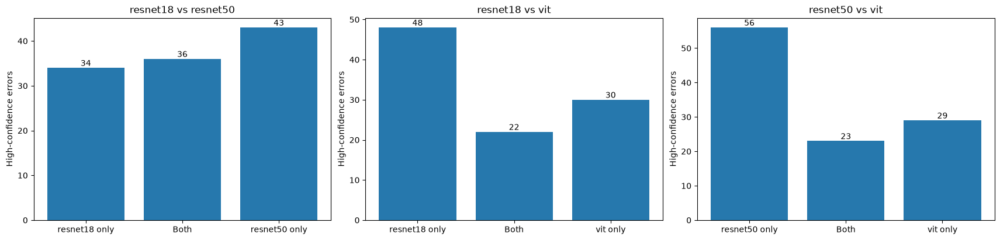

In [2]:
error_ids = [high_confidence_wrong[name] for name in model_names]
shared, union = error_ids[0].copy(), error_ids[0].copy()
for ids in error_ids[1:]:
    shared, union = np.intersect1d(shared, ids), np.union1d(union, ids)
print('Errors shared by all three:', len(shared), 'test IDs:', shared.tolist())
pair_overlap = np.zeros((len(model_names), len(model_names)), dtype=int)
pair_jaccard = np.full_like(pair_overlap, np.nan, dtype=float)
fig, axes = plt.subplots(1, len(pairs), figsize=(17, 4), layout='constrained')
for ax, (i, j) in zip(axes, pairs):
    common, combined = np.intersect1d(error_ids[i], error_ids[j]), np.union1d(error_ids[i], error_ids[j])
    pair_overlap[i, j] = pair_overlap[j, i] = len(common)
    pair_jaccard[i, j] = pair_jaccard[j, i] = len(common) / len(combined) if len(combined) else np.nan
    fractions = [len(common) / len(error_ids[m]) if len(error_ids[m]) else np.nan for m in (i, j)]
    print(f'{model_names[i]} / {model_names[j]}: shared {len(common)}, fractions {fractions[0]:.1%} / {fractions[1]:.1%}, Jaccard {pair_jaccard[i, j]:.1%}')
    if len(common):
        print(f'Same wrong class among shared errors: {(predicted[i, common] == predicted[j, common]).mean():.1%}')
    counts = [len(error_ids[i]) - len(common), len(common), len(error_ids[j]) - len(common)]
    ax.bar([f'{model_names[i]} only', 'Both', f'{model_names[j]} only'], counts)
    ax.bar_label(ax.containers[0])
    ax.set(ylabel='High-confidence errors', title=f'{model_names[i]} vs {model_names[j]}')
for m, ids in enumerate(error_ids):
    pair_overlap[m, m], pair_jaccard[m, m] = len(ids), 1 if len(ids) else np.nan
plt.show()


Compare pairwise high-confidence-error counts together with Jaccard overlap, which accounts for different cohort sizes. ResNet18 and ResNet50 share 36 errors with 31.9% Jaccard overlap, versus 22 and 23 errors and about 21–22% overlap for the CNN–ViT pairs. The CNNs share more of their confident failures, but their non-shared errors also show that the checkpoints are not interchangeable.

## A · Shared and exclusive errors — all 39 shared errors; mark cases with ≥90% confidence in every model; class IDs listed below

Shared errors: 39 with ≥90% confidence in all models: 18
Classes: {0: 'basophil', 1: 'eosinophil', 2: 'erythroblast', 3: 'immature granulocytes', 4: 'lymphocyte', 5: 'monocyte', 6: 'neutrophil', 7: 'platelet'}


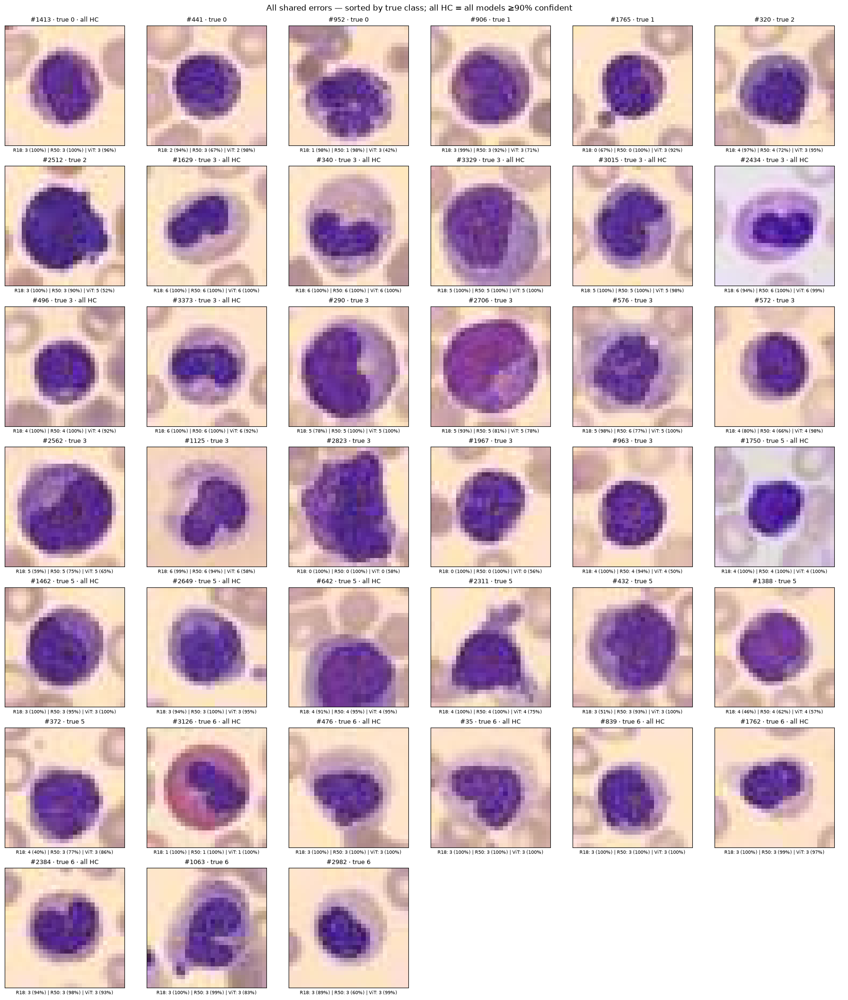

In [3]:
wrong = ~correct
high_wrong = wrong & (confidence >= threshold)
common_wrong = np.flatnonzero(wrong.all(0))
common_hc = np.flatnonzero(high_wrong.all(0))
exclusive_hc = [np.flatnonzero(high_wrong[m] & (wrong.sum(0) == 1)) for m in range(len(model_names))]
print('Shared errors:', len(common_wrong), 'with ≥90% confidence in all models:', len(common_hc))
print('Classes:', dict(enumerate(class_names)))

def gallery(ids, title, columns=6):
    rows = max(1, int(np.ceil(len(ids) / columns)))
    fig, axes = plt.subplots(rows, columns, figsize=(18, 3 * rows), squeeze=False, layout='constrained')
    for ax in axes.flat:
        ax.axis('off')
    for ax, i in zip(axes.flat, ids):
        ax.axis('on')
        ax.imshow(images[i])
        ax.set_title(f'#{i} · true {labels[i]}' + (' · all HC' if high_wrong[:, i].all() else ''), fontsize=9)
        ax.set_xlabel(' | '.join(f'{name}: {predicted[m, i]} ({confidence[m, i]:.0%})'
                                for m, name in enumerate(['R18', 'R50', 'ViT'])), fontsize=7, wrap=True)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(title)
    plt.show()

order = np.lexsort((-confidence[:, common_wrong].min(0), labels[common_wrong]))
gallery(common_wrong[order], 'All shared errors — sorted by true class; all HC = all models ≥90% confident')

Look for repeated wrong labels in the shared-error gallery, especially the images marked as highly confident in all models. All models misclassify 39 images, and the 18 shared HC errors receive the same wrong class from all three models, with nine substitutions between immature granulocytes and neutrophils. Agreement therefore leaves recurring class-specific blind spots rather than independently confirming the recorded label.

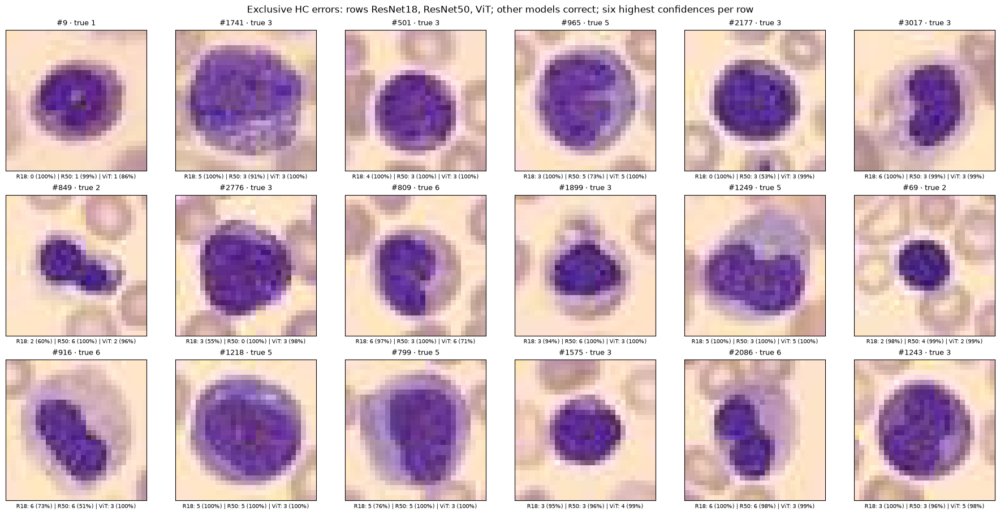

In [4]:
exclusive_examples = np.concatenate([ids[np.argsort(-confidence[m, ids], kind='stable')[:6]]
                                     for m, ids in enumerate(exclusive_hc)])
gallery(exclusive_examples, 'Exclusive HC errors: rows ResNet18, ResNet50, ViT; other models correct; six highest confidences per row')

Compare each row’s selected model with the other two models on the same images. The displayed high-confidence examples are wrong only for ResNet18, only for ResNet50 or only for ViT, while the other models classify them correctly. These exclusive failures show complementary behavior, but confidence-selected examples cannot establish that voting would resolve the shared errors.

## Per-class high-confidence-error rates — class frequency is included in the denominator

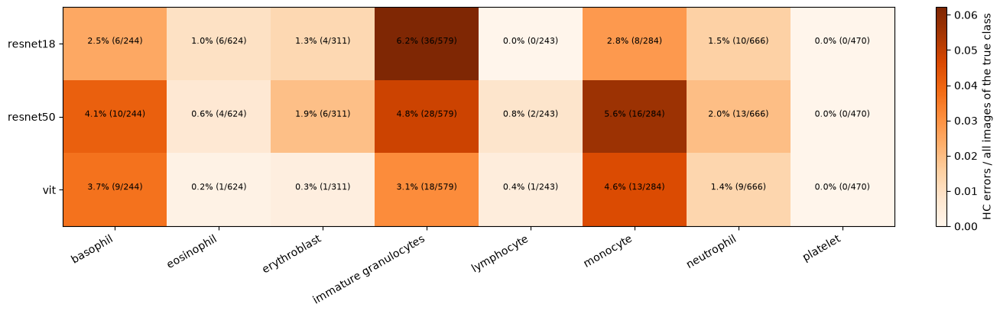

In [5]:
class_sizes = np.bincount(labels, minlength=8)
class_hc_counts = np.stack([np.bincount(labels[ids], minlength=8) for ids in error_ids])
class_hc_rates = class_hc_counts / class_sizes
fig, ax = plt.subplots(figsize=(13, 4), layout='constrained')
im = ax.imshow(class_hc_rates, cmap='Oranges', vmin=0, aspect='auto')
ax.set(xticks=range(8), xticklabels=class_names, yticks=range(3), yticklabels=model_names)
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
for m in range(3):
    for c in range(8):
        ax.text(c, m, f'{class_hc_rates[m,c]:.1%} ({class_hc_counts[m,c]}/{class_sizes[c]})', ha='center', fontsize=8)
fig.colorbar(im, ax=ax, label='HC errors / all images of the true class')
plt.show()

Compare HC-error rates within each true class rather than raw error counts. ResNet18 reaches 6.22% for immature granulocytes versus 2.05% overall, while monocytes have the highest rates for ResNet50 and ViT at 5.63% and 4.58%. Class frequency alone therefore does not explain the error concentration, and the differing rankings indicate checkpoint-specific weaknesses.

## True class → wrong predicted class — counts and percentages within each model's high-confidence errors, not class-specific error rates

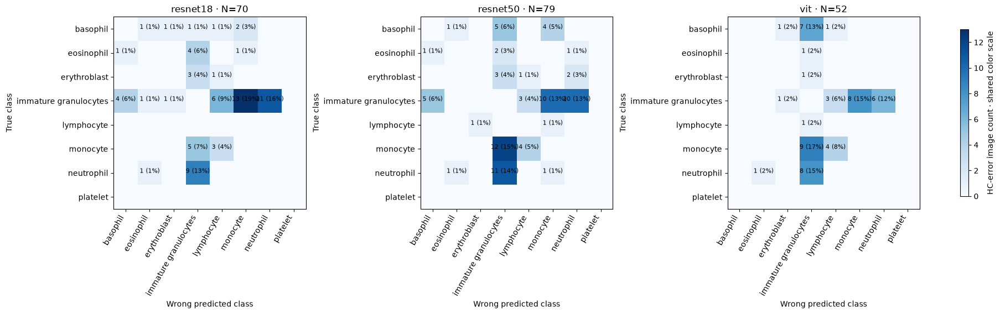

In [6]:
confusions = np.zeros((3, 8, 8), dtype=int)
for m, ids in enumerate(error_ids):
    np.add.at(confusions[m], (labels[ids], predicted[m, ids]), 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 6), layout='constrained')
for m, ax in enumerate(axes):
    im = ax.imshow(confusions[m], cmap='Blues', vmin=0, vmax=confusions.max())
    ax.set(title=f'{model_names[m]} · N={len(error_ids[m])}', xlabel='Wrong predicted class', ylabel='True class',
           xticks=range(8), xticklabels=class_names, yticks=range(8), yticklabels=class_names)
    plt.setp(ax.get_xticklabels(), rotation=60, ha='right')
    for c,d in zip(*np.nonzero(confusions[m])):
        ax.text(d,c,f'{confusions[m,c,d]} ({confusions[m,c,d]/len(error_ids[m]):.0%})',ha='center',fontsize=8)
fig.colorbar(im, ax=axes, shrink=.65, label='HC-error image count · shared color scale')
plt.show()

Read the true-to-predicted class counts to identify recurring substitutions, without treating them as per-class error rates. Immature granulocytes occur on either side of 58/70 ResNet18 error pairs, 61/79 ResNet50 pairs and 45/52 ViT pairs. These failures concentrate around particular class competitions, while the later class-rate view is needed to separate that concentration from class frequency.

### Focus: immature granulocytes ↔ neutrophils

In [7]:
rows=['| Model | True → predicted | All errors / true class | HC errors / true class |','|---|---|---:|---:|']
for m,name in enumerate(model_names):
    for source,destination in [(3,6),(6,3)]:
        selected=(labels==source)&(predicted[m]==destination)
        n=int((labels==source).sum());hc=int((selected&(confidence[m]>=threshold)).sum())
        rows.append(f'| {name} | {class_names[source]} → {class_names[destination]} | {selected.sum()}/{n} ({selected.sum()/n:.1%}) | {hc}/{n} ({hc/n:.1%}) |')
display(Markdown('\n'.join(rows)))

| Model | True → predicted | All errors / true class | HC errors / true class |
|---|---|---:|---:|
| resnet18 | immature granulocytes → neutrophil | 16/579 (2.8%) | 11/579 (1.9%) |
| resnet18 | neutrophil → immature granulocytes | 10/666 (1.5%) | 9/666 (1.4%) |
| resnet50 | immature granulocytes → neutrophil | 17/579 (2.9%) | 10/579 (1.7%) |
| resnet50 | neutrophil → immature granulocytes | 16/666 (2.4%) | 11/666 (1.7%) |
| vit | immature granulocytes → neutrophil | 7/579 (1.2%) | 6/579 (1.0%) |
| vit | neutrophil → immature granulocytes | 16/666 (2.4%) | 8/666 (1.2%) |

**Interpretation:** Compare the two directions using the true-class denominators, distinguishing all errors from the ≥90%-confidence subset. IG→neutrophil errors number 16/17/7 and the reverse direction 10/16/16 for ResNet18/ResNet50/ViT, with many confidently wrong in both directions. This localizes an informative class competition but neither verifies the dataset labels nor establishes which cell morphology caused it.

<a id="story-2"></a>
## 2 · Can we trust confidence?

**Question:** Does a high reported probability imply correctness, and how do wrong images compare with correct images at nearly the same confidence?

**Evidence:** Reliability uses the whole TEST set; the gallery uses one-to-one within-model, same-true-class matching with confidence gap ≤1 percentage point, prioritizing smaller gaps and using RGB distance only as a tiny tie-break.

## Reliability diagram — equal-width confidence bins; ECE weighted by bin counts; empty bins omitted

resnet18: accuracy=96.61%, mean confidence=98.73%, ECE=0.0219
resnet50: accuracy=95.73%, mean confidence=98.66%, ECE=0.0298
vit: accuracy=96.99%, mean confidence=98.62%, ECE=0.0167


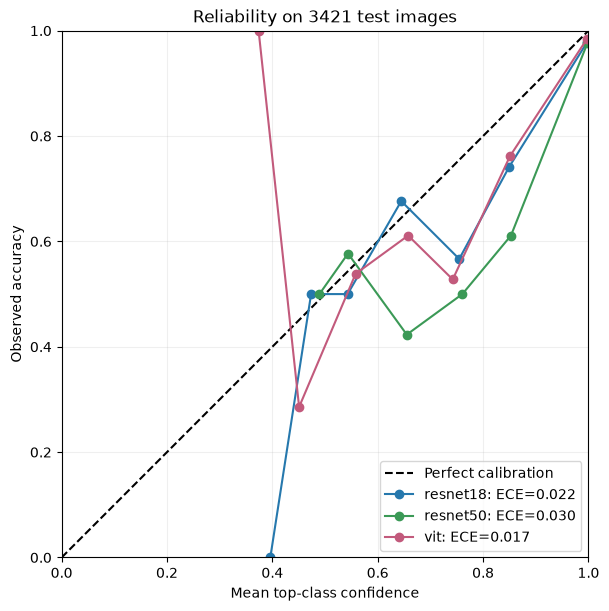

In [8]:
fig, ax = plt.subplots(figsize=(7, 6), layout='constrained')
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
for m, name in enumerate(model_names):
    groups = bin_ids(confidence[m])
    occupied = [groups == b for b in range(n_bins) if (groups == b).any()]
    x = np.array([confidence[m, mask].mean() for mask in occupied])
    y = np.array([correct[m, mask].mean() for mask in occupied])
    counts = np.array([mask.sum() for mask in occupied])
    ece = np.sum(counts * np.abs(y - x)) / len(labels)
    ax.plot(x, y, 'o-', label=f'{name}: ECE={ece:.3f}')
    print(f'{name}: accuracy={correct[m].mean():.2%}, mean confidence={confidence[m].mean():.2%}, ECE={ece:.4f}')
ax.set(xlabel='Mean top-class confidence', ylabel='Observed accuracy',
       title=f'Reliability on {len(labels)} test images', xlim=(0, 1), ylim=(0, 1))
ax.set_aspect('equal')
ax.grid(alpha=0.2)
ax.legend()
plt.show()

Compare each reliability curve with the diagonal, where confidence equals observed accuracy. Mean confidence exceeds accuracy by about 2.1 percentage points for ResNet18, 2.9 for ResNet50 and 1.6 for ViT. These test results indicate overconfidence, without establishing its training-time cause, and motivate checking calibration on separate data.

### Confidently wrong beside tightly matched correct images

resnet18: 65/70 errors matched; mean confidence gap 0.106 pp; unmatched 5
resnet50: 78/79 errors matched; mean confidence gap 0.111 pp; unmatched 1
vit: 49/52 errors matched; mean confidence gap 0.139 pp; unmatched 3


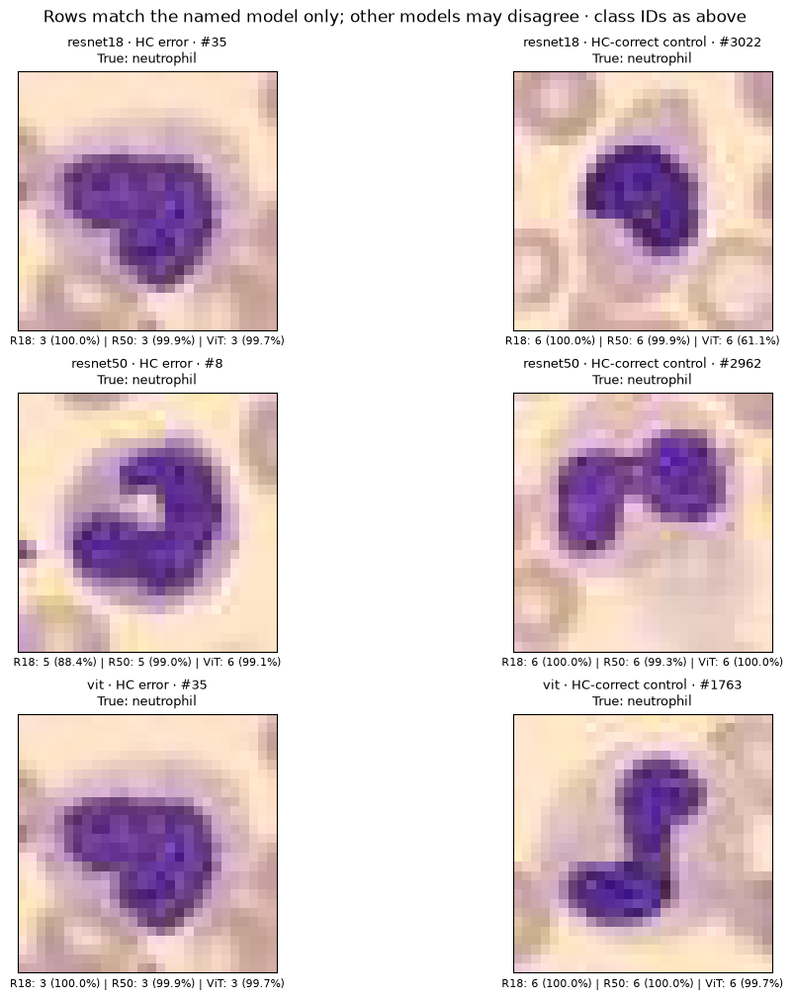

In [9]:
fig,axes=plt.subplots(3,2,figsize=(10,10),layout='constrained')
for m,(name,pairs_m) in enumerate(zip(model_names,matched_pairs)):
    preferred=pairs_m[np.isin(labels[pairs_m[:,0]],[3,6])]
    pair=(preferred if len(preferred) else pairs_m)[0]
    for role,(ax,i) in enumerate(zip(axes[m],pair)):
        ax.imshow(images[i]);ax.set(xticks=[],yticks=[])
        ax.set_title(f'{name} · '+('HC error' if role==0 else 'HC-correct control')+f' · #{i}\nTrue: {class_names[labels[i]]}',fontsize=9)
        ax.set_xlabel(' | '.join(f'{n}: {predicted[k,i]} ({confidence[k,i]:.1%})' for k,n in enumerate(['R18','R50','ViT'])),fontsize=8)
    gaps=targeted[f'matching_{name}_confidence_gaps']
    print(f'{name}: {len(pairs_m)}/{len(error_ids[m])} errors matched; mean confidence gap {100*gaps.mean():.3f} pp; unmatched {len(error_ids[m])-len(pairs_m)}')
fig.suptitle('Rows match the named model only; other models may disagree · class IDs as above')
plt.show()

**Interpretation:** Compare each error/control pair within its named model, then inspect how the other two models respond to those same images. The tighter one-to-one match retains 65/70, 78/79 and 49/52 HC errors with mean confidence gaps of approximately 0.11, 0.11 and 0.14 percentage points. Visually plausible, similarly confident correct controls show why confidence alone cannot identify these mistakes, while unmatched errors limit generalization of the paired analyses.

<a id="story-3"></a>
## 3 · Which visual changes destabilize predictions?

**Question:** Which changes alter decisions or correctness, and is the apparent noise advantage separable from resizing?

**Evidence:** Start with the two common-scale grids in [stability_analysis.ipynb](stability_analysis.ipynb): label-change rate and accuracy across all 3,421 images and all ten severity levels. The selected examples below show all eight probabilities; the balanced 96-image interpolation probe is a targeted control, not a replacement population estimate.

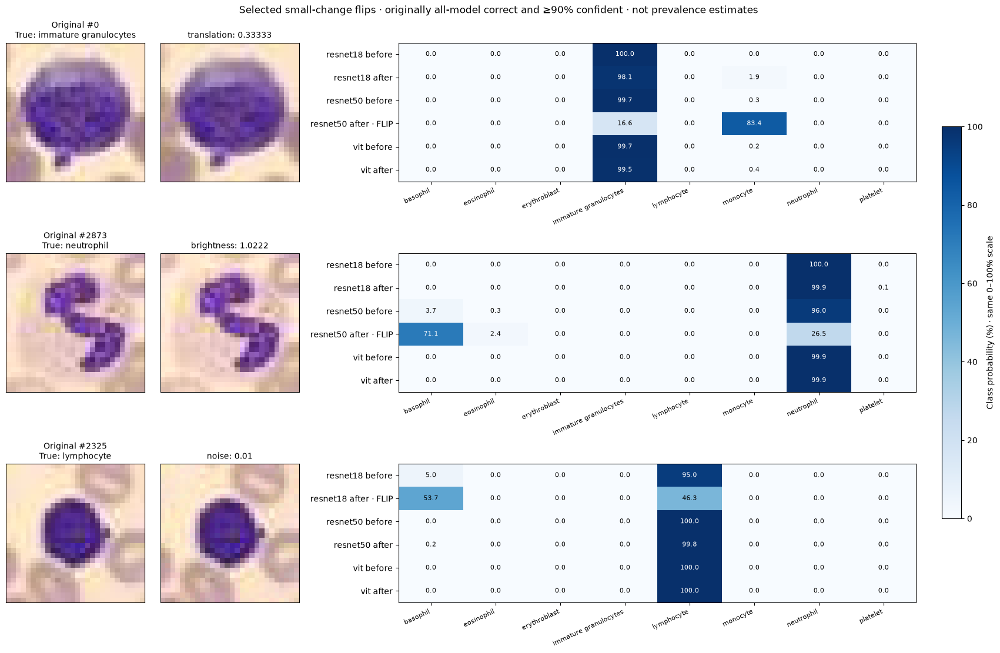

In [10]:
ids=targeted['examples_ids'];before=targeted['examples_baseline'];after=targeted['examples_probabilities']
fig,axes=plt.subplots(3,3,figsize=(17,11),gridspec_kw={'width_ratios':[1,1,3.5]},layout='constrained')
for j,i in enumerate(ids):
    kind,level=str(targeted['examples_kinds'][j]),targeted['examples_levels'][j]
    for ax,im,title in [(axes[j,0],images[i],f'Original #{i}\nTrue: {class_names[labels[i]]}'),(axes[j,1],targeted['examples_images'][j],f'{kind}: {level:.5g}')]:
        ax.imshow(im);ax.set_title(title,fontsize=10);ax.set(xticks=[],yticks=[])
    matrix=np.stack([before[:,j],after[:,j]],axis=1).reshape(6,8)*100
    ax=axes[j,2];im=ax.imshow(matrix,vmin=0,vmax=100,cmap='Blues',aspect='auto')
    row_labels=[f'{name} {role}'+(' · FLIP' if role=='after' and before[m,j].argmax()!=after[m,j].argmax() else '') for m,name in enumerate(model_names) for role in ['before','after']]
    ax.set(yticks=range(6),yticklabels=row_labels,xticks=range(8),xticklabels=class_names)
    plt.setp(ax.get_xticklabels(),rotation=25,ha='right',fontsize=8)
    for r in range(6):
        for c in range(8):ax.text(c,r,f'{matrix[r,c]:.1f}',ha='center',va='center',fontsize=8,color='white' if matrix[r,c]>60 else 'black')
fig.colorbar(im,ax=axes[:,2],shrink=.7,label='Class probability (%) · same 0–100% scale')
fig.suptitle('Selected small-change flips · originally all-model correct and ≥90% confident · not prevalence estimates')
plt.show()

Compare each original/transformed image with the before/after rows for all eight class probabilities, noting the explicitly marked label flips. A one-third-pixel translation, brightness factor 1.0222 and noise σ=0.01 each flip at least one previously ≥90%-confident correct prediction. These deterministically selected counterexamples demonstrate local instability, not typical failure rates or preserved clinical validity of every edit.

### Noise control: identical noisy 28×28 images, common interpolation

Balanced 96 TEST images (12/class), three noise repeats per image and severity; ResNet18/ViT use common PIL nearest/bilinear/bicubic resizing to 224, while ResNet50 stays native 28 as a reference. Native cached arms were reused only after numerical/label equivalence checks where an alternative resize implementation was used. Shaded 95% intervals resample **images within true class**, keeping repeats and before/after observations paired.

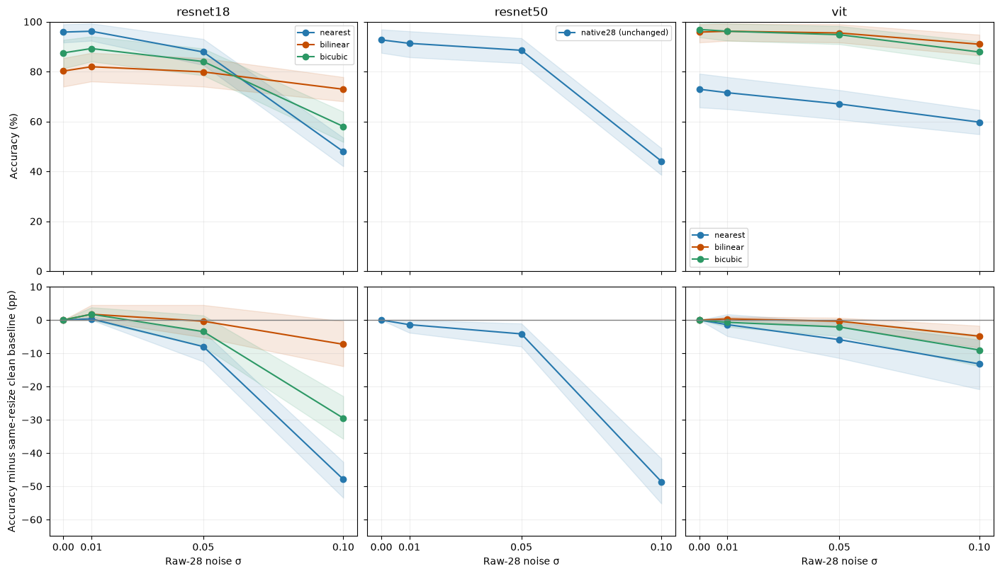

resnet18 nearest: clean 95.8%, σ=.1 47.9%; bilinear: clean 80.2%, σ=.1 72.9%; bicubic: clean 87.5%, σ=.1 58.0%
vit nearest: clean 72.9%, σ=.1 59.7%; bilinear: clean 95.8%, σ=.1 91.0%; bicubic: clean 96.9%, σ=.1 87.8%


In [11]:
q=targeted['interpolation_probabilities'];ids=targeted['interpolation_ids'];noise_levels=targeted['interpolation_noise_levels']
noise_x=np.r_[0,noise_levels]
# One observation per image: average the three repeats before uncertainty estimation.
acc=np.concatenate([(q[:,:,0].argmax(-1)==labels[ids])[:,:,None,:],(q[:,:,1:].reshape(3,3,3,3,len(ids),8).argmax(-1)==labels[ids]).mean(3)],axis=2)
rng=np.random.default_rng(42)
draws=np.column_stack([rng.choice(np.flatnonzero(labels[ids]==c),size=(2000,12)) for c in range(8)])
fig,axes=plt.subplots(2,3,figsize=(14,8),sharex=True,sharey='row',layout='constrained')
resize_colors=['#2678ad','#c44e00','#2c9865']
for m in range(3):
    modes=range(3) if m!=1 else [0]
    for j in modes:
        values=100*acc[m,j];change=values-values[0]
        title=str(targeted['interpolation_modes'][j]) if m!=1 else 'native28 (unchanged)'
        for row,data in enumerate([values,change]):
            ci=np.quantile(data[:,draws].mean(-1),[.025,.975],axis=1)
            axes[row,m].plot(noise_x,data.mean(-1),'o-',label=title,color=resize_colors[j])
            axes[row,m].fill_between(noise_x,ci[0],ci[1],alpha=.12,color=resize_colors[j])
    axes[0,m].set(title=model_names[m],ylim=(0,100));axes[0,m].legend(fontsize=8)
    axes[1,m].axhline(0,color='gray',lw=1);axes[1,m].set(xlabel='Raw-28 noise σ',ylim=(-65,10),xticks=noise_x)
    for ax in axes[:,m]:ax.grid(alpha=.2)
axes[0,0].set_ylabel('Accuracy (%)');axes[1,0].set_ylabel('Accuracy minus same-resize clean baseline (pp)')
plt.show()
for m in [0,2]:
    print(model_names[m],'; '.join(f'{mode}: clean {100*acc[m,j,0].mean():.1f}%, σ=.1 {100*acc[m,j,-1].mean():.1f}%' for j,mode in enumerate(targeted['interpolation_modes'])))

**Interpretation:** Compare absolute accuracy in the top row and loss from each interpolation’s own clean baseline below, rather than comparing noise curves alone. At σ=0.1, native ResNet18/ViT lose 47.9/4.9 accuracy points, versus 7.3/4.9 with common bilinear resizing, but ResNet18’s clean accuracy simultaneously falls from 95.8% to 80.2%. Resizing is therefore a substantial confound of the observed noise gap, not proof that interpolation alone explains it or that the architectures are now fairly isolated.

## What drives the accuracy change? — interactive explorer

Compare recovered errors above zero with new errors below zero; dark orange marks new errors at ≥90% confidence. All panels use the same test-image denominator and linked axes, including while zooming. Choose a transformation, then wheel or drag to zoom; use Reset to return to the full range.

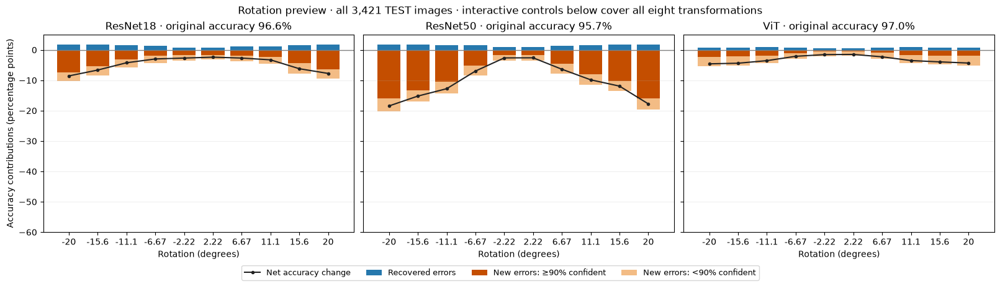

In [12]:
# Correctness changes explain accuracy; a switch between two wrong labels is not a gain or loss.
transition_data = dict(n=len(labels), threshold=threshold, models=['ResNet18', 'ResNet50', 'ViT'], operations={})
operation_names = {'rotation': ('Rotation', 'degrees'), 'translation': ('Translation', 'pixels'),
                   'brightness': ('Brightness', 'factor'), 'blur': ('Blur', 'pixels'),
                   'noise': ('Noise', 'sigma'), 'green_scale': ('Green scaling', 'factor'),
                   'red_scale': ('Red scaling', 'factor'), 'blue_scale': ('Blue scaling', 'factor')}
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    assert str(saved['split']) == 'test'
    np.testing.assert_array_equal(saved['indices'], np.arange(len(labels)))
    np.testing.assert_array_equal(saved['labels'], labels)
    np.testing.assert_array_equal(saved['baseline'], probabilities)
    was_correct = saved['baseline'].argmax(-1) == labels
    baseline_accuracy = 100 * was_correct.mean(-1)
    transition_data.update(baseline_accuracy=baseline_accuracy.tolist(),
                           baseline_errors=(~was_correct).sum(-1).tolist())
    for kind, (name, unit) in operation_names.items():
        p = saved[kind]
        now_correct = p.argmax(-1) == labels
        new_error = was_correct[:, None, None, :] & ~now_correct
        recovered = ~was_correct[:, None, None, :] & now_correct
        # Each original image has equal weight, including when noise has three repeats.
        counts = lambda mask: mask.mean(2).sum(-1)
        lost, gained = counts(new_error), counts(recovered)
        confident_lost = counts(new_error & (p.max(-1) >= threshold))
        np.testing.assert_allclose(baseline_accuracy[:, None] + 100 * (gained - lost) / len(labels),
                                   100 * now_correct.mean((2, 3)), atol=1e-10)
        assert (confident_lost <= lost).all()
        transition_data['operations'][kind] = dict(name=name, unit=unit, levels=saved[f'levels_{kind}'].tolist(),
            repeats=p.shape[2], lost=lost.tolist(), recovered=gained.tolist(), hc_lost=confident_lost.tolist())
max_loss = max(np.max(op['lost']) for op in transition_data['operations'].values())
max_gain = max(np.max(op['recovered']) for op in transition_data['operations'].values())
transition_data.update(ymin=float(-10 * np.ceil(100 * max_loss / len(labels) / 10)),
                       ymax=float(max(5, 5 * np.ceil(100 * max_gain / len(labels) / 5))))

# A static rotation preview remains readable on GitHub; the explorer below includes all operations.
preview = transition_data['operations']['rotation']
x = np.arange(len(preview['levels']))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True, layout='constrained')
for m, ax in enumerate(axes):
    gained, lost, hc = [100 * np.asarray(preview[key])[m] / len(labels) for key in ['recovered', 'lost', 'hc_lost']]
    ax.bar(x, gained, color='#2678ad', label='Recovered errors')
    ax.bar(x, -hc, color='#c44e00', label=f'New errors: ≥{threshold:.0%} confident')
    ax.bar(x, -(lost - hc), bottom=-hc, color='#f3bc85', label=f'New errors: <{threshold:.0%} confident')
    ax.plot(x, gained - lost, 'o-', color='#222', ms=3, label='Net accuracy change')
    ax.axhline(0, color='gray', lw=1)
    ax.set(title=f'{transition_data["models"][m]} · original accuracy {baseline_accuracy[m]:.1f}%',
           xticks=x, xticklabels=[f'{v:.3g}' for v in preview['levels']], xlabel='Rotation (degrees)',
           ylim=(transition_data['ymin'], transition_data['ymax']))
    ax.grid(axis='y', alpha=0.2)
axes[0].set_ylabel('Accuracy contributions (percentage points)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=4, fontsize=9)
fig.suptitle(f'Rotation preview · all {len(labels):,} TEST images · interactive controls below cover all eight transformations')
plt.show()


Compare bars above and below zero at the same level, then follow the black line to see which side dominates. At +20° rotation, ResNet50 recovers 60 errors but introduces 668 new ones, 547 of which are ≥90% confident, for a net accuracy loss of 17.8 percentage points. Helpful wrong-to-correct reversals are therefore overwhelmed by new, often confident errors, explaining why the overall accuracy falls despite some original mistakes becoming correct.

In [13]:
import html
from IPython.display import HTML, FileLink, display

# Self-contained HTML/SVG/JavaScript: no CDN, web service, widget backend or extra dependency.
transition_template = r'''<!doctype html>
<html lang="en"><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Transformation explorer</title>
<style>
*{box-sizing:border-box}body{font:14px system-ui,sans-serif;color:#252b32;max-width:1500px;margin:16px auto;padding:0 16px}h1{font-size:21px;margin:0}header,.toolbar,.legend{display:flex;align-items:center;flex-wrap:wrap;gap:12px}header{justify-content:space-between;margin-bottom:16px}.toolbar{gap:10px}label{display:flex;align-items:center;gap:8px;color:#58616b}select,button{font:inherit;background:white;border:1px solid #cfd5db;border-radius:5px;padding:5px 9px;color:#252b32}button{cursor:pointer}button:hover{background:#f1f4f7}button:focus-visible,select:focus-visible{outline:2px solid #2678ad}input{width:155px}output{min-width:94px;font-variant-numeric:tabular-nums}.legend{font-size:12px;color:#58616b;margin-bottom:12px;gap:18px}.swatch{display:inline-block;width:12px;height:9px;margin-right:5px}.models{display:grid;grid-template-columns:repeat(3,minmax(250px,1fr));gap:14px}.card{border:1px solid #e1e5e9;border-radius:7px;padding:12px}.model-head{display:flex;align-items:baseline;justify-content:space-between;gap:6px}.model-head h2{font-size:17px;margin:0}.accuracy{font-size:15px;font-weight:600;white-space:nowrap}.delta{font-size:12px;font-weight:400;color:#69737e;margin-left:6px}svg{width:100%;height:auto;touch-action:none;user-select:none;cursor:crosshair}.stats{display:grid;grid-template-columns:repeat(3,1fr);gap:8px;border-top:1px solid #edf0f3;padding-top:8px}.stats span{display:block;color:#69737e;font-size:11px}.stats strong{font-size:17px;font-weight:600;font-variant-numeric:tabular-nums}.footer{display:flex;justify-content:space-between;flex-wrap:wrap;gap:10px;margin-top:12px;color:#69737e;font-size:12px}details{margin-top:14px;color:#58616b;font-size:12px;line-height:1.6}summary{cursor:pointer}details p{max-width:1050px}a{color:#17689c}.selection{fill:#2678ad;fill-opacity:.12;stroke:#2678ad;stroke-dasharray:4 3;pointer-events:none}@media(max-width:850px){.models{grid-template-columns:1fr}header{align-items:flex-start}.toolbar{width:100%}}
</style>
<header><h1>Transformation explorer</h1><div class="toolbar"><select id="transformation" aria-label="Transformation"></select><label>Level <input id="level" aria-label="Transformation level" type="range" min="0" max="9" step="1" value="9"></label><output id="levelLabel" aria-live="polite"></output><button id="zoom-in" aria-label="Zoom in" title="Zoom into the selected level">+</button><button id="zoom-out" aria-label="Zoom out" title="Zoom out">−</button><button id="fit" title="Fit this transformation’s data, using the same axes for all models">Fit</button><button id="reset" title="Restore the shared full range">Reset</button></div></header>
<div class="legend"><span><i class="swatch" style="background:#2678ad"></i>Recovered</span><span><i class="swatch" style="background:#c44e00"></i>New: ≥__THRESHOLD__</span><span><i class="swatch" style="background:#f3bc85"></i>New: &lt;__THRESHOLD__</span><span>━━ Net accuracy change</span></div>
<div id="models" class="models"></div>
<div class="footer"><span id="status"></span><span>Wheel / drag to zoom · double-click to reset</span></div>
<details><summary>How to read · definitions · sources</summary><p>Bars above zero are originally wrong images that become correct; bars below zero are originally correct images that become wrong. Dark orange identifies new errors with confidence ≥__THRESHOLD__. The black line is recovered minus new errors, so it measures the net accuracy change. All contributions use the same full-test denominator, not different correct/wrong group sizes; switches between two wrong labels do not contribute. Header percentages show accuracy at the selected level, with the change from the original prediction beside them; hover for the original accuracy.</p><p>Zoom is linked across all three models. Drag a rectangle or use the wheel to zoom, click a bar or move the slider to inspect a level, use Fit for the current transformation’s range, or Reset / double-click for the full range. Changing transformations resets zoom. Noise counts are means of three realizations, not independent extra images. Transformed inputs may leave the data distribution or change the label: these views describe checkpoint responses, not a correction strategy.</p><p>Design: <a href="https://pmc.ncbi.nlm.nih.gov/articles/PMC7733875/">small multiples</a> · <a href="https://data.europa.eu/apps/data-visualisation-guide/the-information-seeking-mantra">overview, filter, details on demand</a>.</p></details>
<script>
const D=__DATA__;
const select=document.getElementById('transformation'), slider=document.getElementById('level');
for(const [key,p] of Object.entries(D.operations)){const o=document.createElement('option');o.value=key;o.textContent=p.name;select.append(o);}
const G={W:460,H:310,L:42,R:10,T:20,B:38};G.w=G.W-G.L-G.R;G.h=G.H-G.T-G.B;
const full={xmin:-.5,xmax:9.5,ymin:D.ymin,ymax:D.ymax};let view={...full},chosen=9,suppressClickUntil=0;
const fmt=x=>Math.abs(x)<1e-9?'0':Number(x.toPrecision(3)).toString();
const count=x=>Math.abs(x-Math.round(x))<1e-6?Math.round(x).toLocaleString():x.toFixed(1);
const pp=x=>(x>=0?'+':'')+x.toFixed(1)+' pp';
const X=j=>G.L+(j-view.xmin)/(view.xmax-view.xmin)*G.w;
const Y=v=>G.T+(view.ymax-v)/(view.ymax-view.ymin)*G.h;
const invX=x=>view.xmin+(x-G.L)/G.w*(view.xmax-view.xmin);
const invY=y=>view.ymax-(y-G.T)/G.h*(view.ymax-view.ymin);
function bounded(lo,hi,min,max,minSpan){const span=Math.min(max-min,Math.max(minSpan,hi-lo));lo=Math.max(min,Math.min((lo+hi-span)/2,max-span));return[lo,lo+span];}
function setView(xmin,xmax,ymin,ymax){[view.xmin,view.xmax]=bounded(xmin,xmax,full.xmin,full.xmax,1.5);[view.ymin,view.ymax]=bounded(ymin,ymax,full.ymin,full.ymax,.5);if(chosen<view.xmin||chosen>view.xmax){chosen=Math.max(0,Math.min(9,Math.round((view.xmin+view.xmax)/2)));slider.value=chosen;}render();}
function zoom(factor,cx=chosen,cy=0){setView(cx+(view.xmin-cx)*factor,cx+(view.xmax-cx)*factor,cy+(view.ymin-cy)*factor,cy+(view.ymax-cy)*factor);}
function reset(){view={...full};render();}
function ticks(lo,hi){const raw=(hi-lo)/5,power=10**Math.floor(Math.log10(raw)),r=raw/power,step=(r<=1?1:r<=2?2:r<=5?5:10)*power,result=[];for(let v=Math.ceil(lo/step)*step;v<=hi+step*1e-8;v+=step)result.push(v);return result;}
function chart(p,m){
 const dx=G.w/(view.xmax-view.xmin),clip=`clip${m}`;
 let s=`<svg viewBox="0 0 ${G.W} ${G.H}" data-model="${m}" role="img" aria-label="${D.models[m]}: zoomable accuracy contributions"><defs><clipPath id="${clip}"><rect x="${G.L}" y="${G.T}" width="${G.w}" height="${G.h}"/></clipPath></defs>`;
 s+=`<g clip-path="url(#${clip})"><rect x="${X(chosen)-dx/2}" y="${G.T}" width="${dx}" height="${G.h}" fill="#f5f7fa"/></g>`;
 for(const tick of ticks(view.ymin,view.ymax))s+=`<line x1="${G.L}" x2="${G.W-G.R}" y1="${Y(tick)}" y2="${Y(tick)}" stroke="${Math.abs(tick)<1e-8?'#969fa9':'#edf0f3'}"/><text x="${G.L-6}" y="${Y(tick)+4}" text-anchor="end" font-size="11" fill="#69737e">${fmt(tick)}</text>`;
 s+=`<text x="${G.L}" y="12" font-size="10" fill="#69737e">Accuracy contributions (pp)</text><g clip-path="url(#${clip})">`;
 for(let j=0;j<10;j++){
  const gain=100*p.recovered[m][j]/D.n,loss=100*p.lost[m][j]/D.n,hc=100*p.hc_lost[m][j]/D.n,a=X(j)-.33*dx,b=.66*dx;
  s+=`<g data-step="${j}" style="cursor:pointer"><title>${p.name} ${fmt(p.levels[j])} ${p.unit}: ${count(p.lost[m][j])} new (${count(p.hc_lost[m][j])} confident); ${count(p.recovered[m][j])} recovered</title><rect x="${X(j)-dx/2}" y="${G.T}" width="${dx}" height="${G.h}" fill="transparent"/><rect x="${a}" y="${Y(gain)}" width="${b}" height="${Y(0)-Y(gain)}" fill="#2678ad"/><rect x="${a}" y="${Y(0)}" width="${b}" height="${Y(-hc)-Y(0)}" fill="#c44e00"/><rect x="${a}" y="${Y(-hc)}" width="${b}" height="${Y(-loss)-Y(-hc)}" fill="#f3bc85"/></g>`;
 }
 const points=p.levels.map((_,j)=>`${X(j)},${Y(100*(p.recovered[m][j]-p.lost[m][j])/D.n)}`).join(' ');
 s+=`<polyline points="${points}" fill="none" stroke="#222" stroke-width="2" pointer-events="none"/><circle cx="${X(chosen)}" cy="${Y(100*(p.recovered[m][chosen]-p.lost[m][chosen])/D.n)}" r="4" fill="#222" pointer-events="none"/></g>`;
 const first=Math.max(0,Math.ceil(view.xmin)),last=Math.min(9,Math.floor(view.xmax)),stride=Math.max(1,Math.ceil((last-first+1)/6));
 for(let j=first;j<=last;j++)if((j-first)%stride===0||j===last||j===chosen)s+=`<text x="${X(j)}" y="${G.H-20}" text-anchor="middle" font-size="10" fill="#69737e">${fmt(p.levels[j])}</text>`;
 return s+`<text x="${G.L+G.w/2}" y="${G.H-3}" text-anchor="middle" font-size="10" fill="#69737e">${p.unit}</text></svg>`;
}
function localPoint(svg,e){const p=svg.createSVGPoint();p.x=e.clientX;p.y=e.clientY;return p.matrixTransform(svg.getScreenCTM().inverse());}
function inside(p){return p.x>=G.L&&p.x<=G.W-G.R&&p.y>=G.T&&p.y<=G.H-G.B;}
function bindZoom(svg){
 svg.addEventListener('wheel',e=>{const p=localPoint(svg,e);if(!inside(p))return;e.preventDefault();zoom(Math.exp(Math.max(-1,Math.min(1,e.deltaY*.002))),invX(p.x),invY(p.y));},{passive:false});
 svg.ondblclick=e=>{e.preventDefault();reset();};
 svg.onclick=e=>{if(Date.now()<suppressClickUntil)return;const p=localPoint(svg,e);if(inside(p)){chosen=Math.max(0,Math.min(9,Math.round(invX(p.x))));slider.value=chosen;render();}};
 let start=null,box=null;
 svg.onpointerdown=e=>{const p=localPoint(svg,e);if(e.button!==0||!inside(p))return;e.preventDefault();start=p;try{svg.setPointerCapture(e.pointerId);}catch{}box=document.createElementNS('http://www.w3.org/2000/svg','rect');box.setAttribute('class','selection');svg.append(box);};
 svg.onpointermove=e=>{if(!start)return;const p=localPoint(svg,e),x=Math.max(G.L,Math.min(G.W-G.R,p.x)),y=Math.max(G.T,Math.min(G.H-G.B,p.y));for(const[k,v]of Object.entries({x:Math.min(start.x,x),y:Math.min(start.y,y),width:Math.abs(x-start.x),height:Math.abs(y-start.y)}))box.setAttribute(k,v);};
 svg.onpointerup=e=>{if(!start)return;const p=localPoint(svg,e),x=Math.max(G.L,Math.min(G.W-G.R,p.x)),y=Math.max(G.T,Math.min(G.H-G.B,p.y)),a=start;start=null;box.remove();if(Math.abs(x-a.x)>6&&Math.abs(y-a.y)>6){suppressClickUntil=Date.now()+250;setView(invX(Math.min(x,a.x)),invX(Math.max(x,a.x)),invY(Math.max(y,a.y)),invY(Math.min(y,a.y)));}};
 svg.onpointercancel=()=>{start=null;if(box)box.remove();};
}
function render(){
 const p=D.operations[select.value],j=chosen;document.getElementById('levelLabel').textContent=fmt(p.levels[j])+' '+p.unit;
 document.getElementById('models').innerHTML=D.models.map((name,m)=>{const net=100*(p.recovered[m][j]-p.lost[m][j])/D.n,accuracy=D.baseline_accuracy[m]+net;return `<section class="card"><div class="model-head"><h2>${name}</h2><span class="accuracy" title="Original: ${D.baseline_accuracy[m].toFixed(1)}%; ${D.baseline_errors[m]} errors">${accuracy.toFixed(1)}%<span class="delta">${pp(net)}</span></span></div>${chart(p,m)}<div class="stats"><div><span>New errors</span><strong>${count(p.lost[m][j])}</strong></div><div><span>≥__THRESHOLD__ confident</span><strong>${count(p.hc_lost[m][j])}</strong></div><div><span>Recovered</span><strong>${count(p.recovered[m][j])}</strong></div></div></section>`;}).join('');
 document.querySelectorAll('svg').forEach(bindZoom);
 const zoomed=Object.keys(full).some(k=>Math.abs(view[k]-full[k])>1e-7);
 document.getElementById('status').textContent=`${D.n.toLocaleString()} TEST images · linked axes · ${zoomed?'zoomed':'full range'}`+(p.repeats===3?' · counts averaged over 3 noise realizations':'');
}
select.onchange=reset;slider.oninput=()=>{chosen=Number(slider.value);render();};
document.getElementById('zoom-in').onclick=()=>zoom(.65);document.getElementById('zoom-out').onclick=()=>zoom(1.6,(view.xmin+view.xmax)/2,(view.ymin+view.ymax)/2);
document.getElementById('reset').onclick=reset;
document.getElementById('fit').onclick=()=>{const p=D.operations[select.value],lo=-100*Math.max(...p.lost.flat())/D.n,hi=100*Math.max(...p.recovered.flat())/D.n,pad=Math.max(1,(hi-lo)*.08);setView(full.xmin,full.xmax,Math.max(full.ymin,lo-pad),Math.min(full.ymax,hi+pad));};
render();
</script></html>
'''
transition_html = transition_template.replace('__DATA__', json.dumps(transition_data, allow_nan=False).replace('</', '<\\/'))
transition_html = transition_html.replace('__THRESHOLD__', f'{threshold:.0%}')
transition_path = Path('visualizations/transformation_explorer.html')
transition_path.parent.mkdir(exist_ok=True)
transition_path.write_text(transition_html, encoding='utf-8')
display(HTML('<p>For interactive controls, trust this notebook or open the offline HTML.</p>'))
display(FileLink(str(transition_path), result_html_prefix='Standalone offline explorer: '))
display(HTML('<iframe title="Transformation transition explorer" sandbox="allow-scripts" '
             'style="width:100%;height:560px;border:1px solid #ddd" srcdoc="'
             + html.escape(transition_html, quote=True) + '"></iframe>'))


C:\Users\Viktor\projects\AI_and_Visualization_Project\visualizations\transformation_explorer.html

C:\Users\Viktor\AppData\Roaming\Python\Python314\site-packages\IPython\core\display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


### Try a random TEST image with actual model inference

Start `python image_sandbox.py` from the repository root and open **[http://127.0.0.1:8765](http://127.0.0.1:8765)**. Load a random image, a confident error, an IG↔neutrophil case or a specific TEST ID; apply transformations, draw, gray-mask or restore pixels, and inspect all eight class probabilities for all three models against the original baseline. The app keeps models loaded, serializes inference, uses the exact original preprocessing and sends nothing outside localhost; edits can invalidate the original label.

The offline explorer above only explores cached cohort transitions; the local app actually evaluates your edited image. Neither should be interpreted as a clinical diagnostic tool.

<a id="story-4"></a>
## 4 · What might drive the differences?

**Question:** Are the observed errors associated with color or spatial dependence once class and confidence are better controlled?

**Evidence:** Use the tight matches from story 2 for appearance and occlusion; retain the original broader saturation cohorts as explicitly separate context, then probe approximate foreground/background ROIs on a small balanced, originally all-model HC-correct subset.

### Appearance: tighter matched pairs with image-level uncertainty

Error-minus-control means are standardized by the matched controls’ feature SD. Intervals use 2,000 paired-image bootstrap samples stratified by true class, recomputing the SD in each sample; unmatched errors are excluded and these exploratory feature comparisons are not multiplicity-corrected.

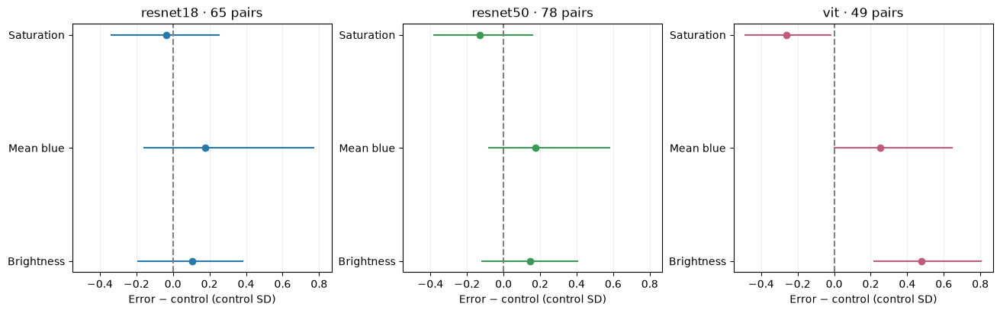

In [14]:
fig,axes=plt.subplots(1,3,figsize=(13,4),sharex=True,layout='constrained')
for m,(ax,name) in enumerate(zip(axes,model_names)):
    means=targeted[f'matching_{name}_feature_effect'];ci=targeted[f'matching_{name}_feature_ci']
    for j in range(3):
        ax.plot(ci[:,j],[j,j],color=model_colors[m]);ax.plot(means[j],j,'o',color=model_colors[m])
    ax.axvline(0,color='gray',ls='--');ax.set(title=f'{name} · {len(matched_pairs[m])} pairs',yticks=range(3),yticklabels=targeted['matching_feature_names'],xlabel='Error − control (control SD)');ax.grid(axis='x',alpha=.2)
plt.show()

Compare error-minus-control effects with zero and their paired-image 95% intervals under the tighter same-class, similar-confidence match. ViT errors are brighter by 0.48 control SD and less saturated by 0.26 SD, whereas both CNNs’ intervals include zero for all three features. These associations prioritize hypotheses but are sensitive to the retained cohort, correlated measurements and exploratory selection, rather than demonstrating a causal color mechanism.

## Saturation intervention — original-decision support and the destination class

The same HC errors and nearest same-class HC-correct controls receive saturation factors from 0.5 to 1.5. The left panels retain every tested factor, while the right panels isolate the destination-class distribution at ×0.5 to make class collapse visible. Controls can be reused, so these paired cohorts are descriptive rather than independent replicated samples.

**Cohort distinction:** These existing saturation curves use the original same-class HC-correct controls (threshold ≥90%, controls may be reused), not the tighter one-to-one confidence-caliper match above; no new saturation inference is implied.

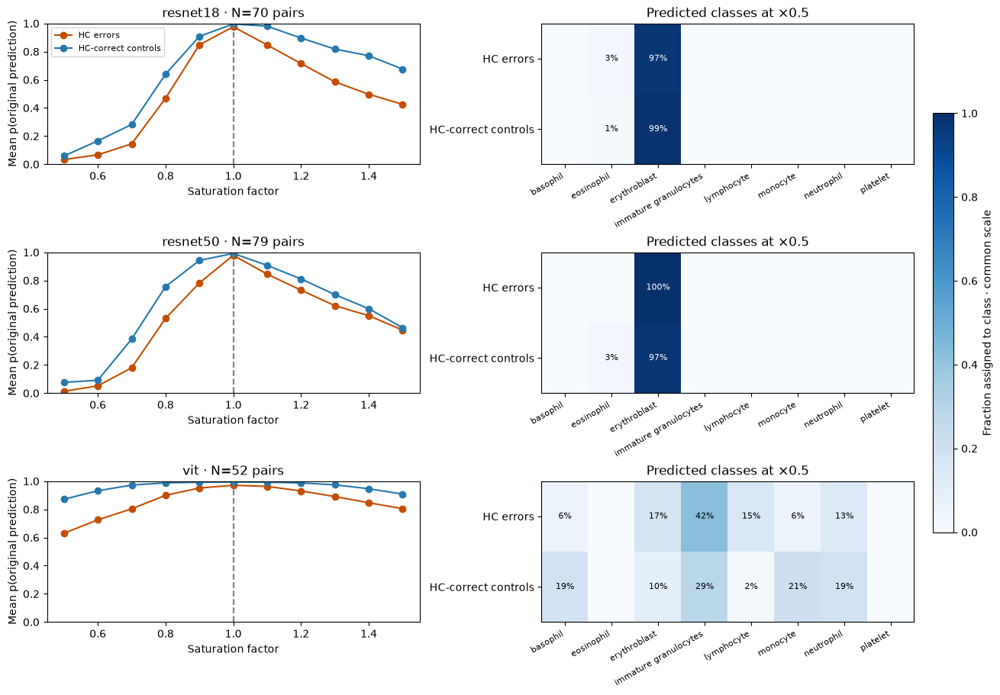

In [15]:
saturation_levels = analysis['saturation_levels']
saturation_index = int(np.argmin(np.abs(saturation_levels-.5)))
fig, axes = plt.subplots(3, 2, figsize=(13, 9), layout='constrained')
for m, name in enumerate(model_names):
    selected = analysis[f'{name}_saturation_ids']
    p = analysis[f'{name}_saturation_probabilities']
    np.testing.assert_allclose(p[:,5], probabilities[m,selected], atol=1e-5, rtol=1e-4)
    original = predicted[m,selected]
    retained = np.take_along_axis(p,original[:,None,:,None],axis=-1)[...,0]
    for role, title in enumerate(['HC errors','HC-correct controls']):
        axes[m,0].plot(saturation_levels,retained[role].mean(-1),'o-',label=title,
                       color=['#c44e00','#2678ad'][role])
    axes[m,0].axvline(1,color='gray',ls='--')
    axes[m,0].set(title=f'{name} · N={len(error_ids[m])} pairs',xlabel='Saturation factor',
                   ylabel='Mean p(original prediction)',ylim=(0,1))
    assigned = p[:,saturation_index].argmax(-1)
    distribution = np.stack([(assigned==c).mean(-1) for c in range(8)],axis=1)
    im = axes[m,1].imshow(distribution,vmin=0,vmax=1,cmap='Blues',aspect='auto')
    axes[m,1].set(title=f'Predicted classes at ×{saturation_levels[saturation_index]:g}',
                   xticks=range(8),xticklabels=class_names,yticks=[0,1],yticklabels=['HC errors','HC-correct controls'])
    plt.setp(axes[m,1].get_xticklabels(),rotation=30,ha='right',fontsize=8)
    for role,c in zip(*np.nonzero(distribution)):
        axes[m,1].text(c,role,f'{distribution[role,c]:.0%}',ha='center',va='center',fontsize=8,
                        color='white' if distribution[role,c]>.6 else 'black')
axes[0,0].legend(fontsize=8)
fig.colorbar(im,ax=axes[:,1],shrink=.7,label='Fraction assigned to class · common scale')
plt.show()

Follow original-decision support on the left and compare error/control destination classes at saturation ×0.5 on the right. ResNet18 assigns erythroblast to 68/70 errors and 69/70 controls, and ResNet50 to 79/79 errors and 77/79 controls, while ViT does not show that near-complete collapse. The shared CNN destination across different starting states supports color-dependent class assignment rather than a selective repair of initially wrong predictions.

### Occlusion: population versus tightly matched errors

Same 49 gray 4×4 patches and original-decision support; the bottom row now uses the confidence-caliper pairs, not the older RGB-near matches. The central contrast averages the nine fixed center patches per image before the paired, class-stratified bootstrap; patch locations are not independent samples or annotated cell structures.

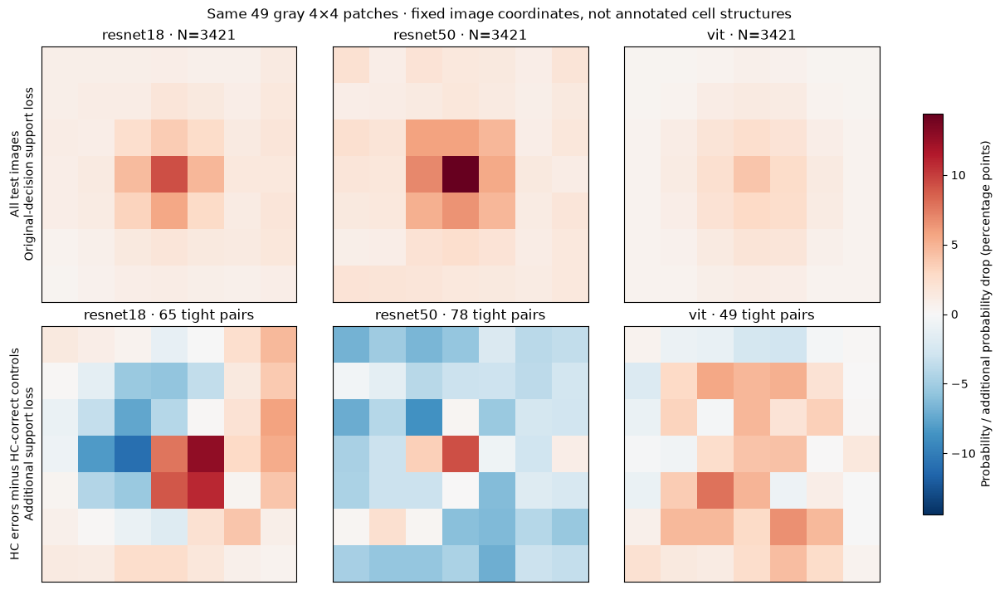

resnet18: original accuracy 96.61%; mean occluded accuracy 95.61%
resnet50: original accuracy 95.73%; mean occluded accuracy 94.23%
vit: original accuracy 96.99%; mean occluded accuracy 96.40%
resnet18: extra central loss +1.41 pp; paired-image 95% interval [-3.68, +6.52]
resnet50: extra central loss -1.22 pp; paired-image 95% interval [-5.73, +3.30]
vit: extra central loss +3.26 pp; paired-image 95% interval [-3.32, +10.58]


In [16]:
with np.load('predictions/occlusion_test.npz',allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved['sample_index'],np.arange(len(labels)))
    np.testing.assert_array_equal(saved['baseline_probabilities'],probabilities)
    occluded = saved['probabilities']
original_support = np.take_along_axis(occluded,predicted[:,None,:,None],axis=-1)[...,0]
population_drop = (confidence[:,None]-original_support).transpose(0,2,1).reshape(3,len(labels),7,7)
paired_drop = []
for m,name in enumerate(model_names):
    selected = matched_pairs[m].T
    paired_drop.append((population_drop[m,selected[0]]-population_drop[m,selected[1]]).mean(0))
occlusion_maps = 100*np.stack([population_drop.mean(1),np.array(paired_drop)])
limit = max(np.abs(occlusion_maps).max(),1)
fig,axes = plt.subplots(2,3,figsize=(12,7),layout='constrained')
for row in range(2):
    for m,ax in enumerate(axes[row]):
        im=ax.imshow(occlusion_maps[row,m],cmap='RdBu_r',vmin=-limit,vmax=limit)
        ax.set(title=f'{model_names[m]} · '+(f'N={len(labels)}' if row==0 else f'{len(matched_pairs[m])} tight pairs'),xticks=[],yticks=[])
axes[0,0].set_ylabel('All test images\nOriginal-decision support loss')
axes[1,0].set_ylabel('HC errors minus HC-correct controls\nAdditional support loss')
fig.colorbar(im,ax=axes,shrink=.75,label='Probability / additional probability drop (percentage points)')
fig.suptitle('Same 49 gray 4×4 patches · fixed image coordinates, not annotated cell structures')
plt.show()
for m,name in enumerate(model_names):
    accuracy=(occluded[m].argmax(-1)==labels).mean()
    print(f'{name}: original accuracy {correct[m].mean():.2%}; mean occluded accuracy {accuracy:.2%}')
for m,name in enumerate(model_names):
    mean=targeted[f'matching_{name}_central_difference'].mean();ci=targeted[f'matching_{name}_central_ci']
    print(f'{name}: extra central loss {mean:+.2f} pp; paired-image 95% interval [{ci[0]:+.2f}, {ci[1]:+.2f}]')


Compare population sensitivity with the tightly matched error-minus-control maps and the central nine-patch intervals printed below. Additional central losses are +1.4, −1.2 and +3.3 percentage points for ResNet18, ResNet50 and ViT, with every 95% interval crossing zero, unlike the roughly 10-point contrasts under the older broader matching. The earlier error-specific spatial story is therefore not supported under tighter confidence control, and neither map identifies an anatomical causal feature.

### Approximate foreground/background color probes — inspect the masks first

Balanced 24 TEST images (three/class), originally correct and ≥90% confident in every model; these are **not** the error/control cohorts. Border-color distance defines a central stained-object core, then a two-pixel expansion tests sensitivity, with soft feathered boundaries; one visibly spilling mask (#769) was rejected before inference and replaced by #663.

**Important:** This is agent-reviewed gross overlap, **not expert cell segmentation**: pale cytoplasm can be assigned to the background complement, and expansion can include background or neighbor material. Foreground/background therefore mean approximate ROI/complement, not verified biological compartments; perturbation area and RMS dose are unequal, and three images per class can yield narrow or degenerate conditional bootstrap intervals. Full 24-image review and methods are preserved in the archive/source and cache.

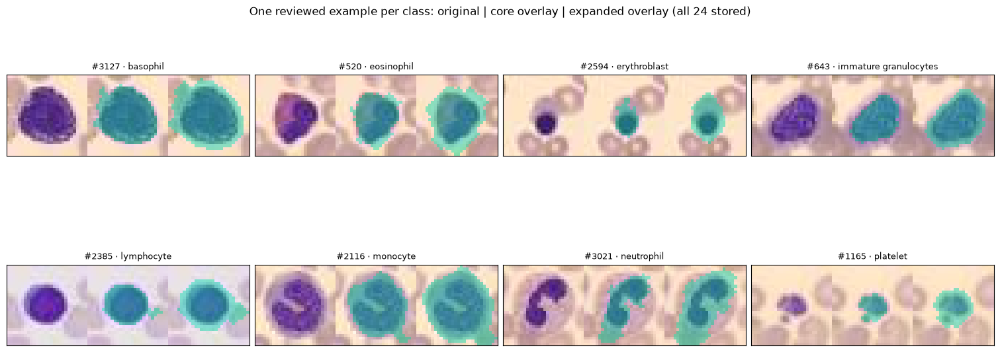

In [17]:
ids=targeted['roi_ids'];masks=targeted['roi_masks']
fig,axes=plt.subplots(2,4,figsize=(15,6),layout='constrained')
for cls,ax in enumerate(axes.flat):
    j=int(np.flatnonzero(labels[ids]==cls)[0]);i=ids[j];views=[images[i]]
    for mask in masks[:,j]:
        overlay=images[i].astype(float).copy();overlay[mask]=.55*overlay[mask]+.45*np.array([0,220,160]);views.append(overlay.astype(np.uint8))
    ax.imshow(np.concatenate(views,axis=1));ax.set(xticks=[],yticks=[],title=f'#{i} · {class_names[cls]}');ax.title.set_fontsize(9)
fig.suptitle('One reviewed example per class: original | core overlay | expanded overlay (all 24 stored)')
plt.show()

Compare the unmodified image with both overlays before interpreting any foreground/background intervention. The core generally tracks stained material and the expansion changes its spatial coverage, but pale cytoplasm and neighboring material remain visibly ambiguous. These approximate masks support a sensitivity probe only, not a definitive separation of cell and background evidence.

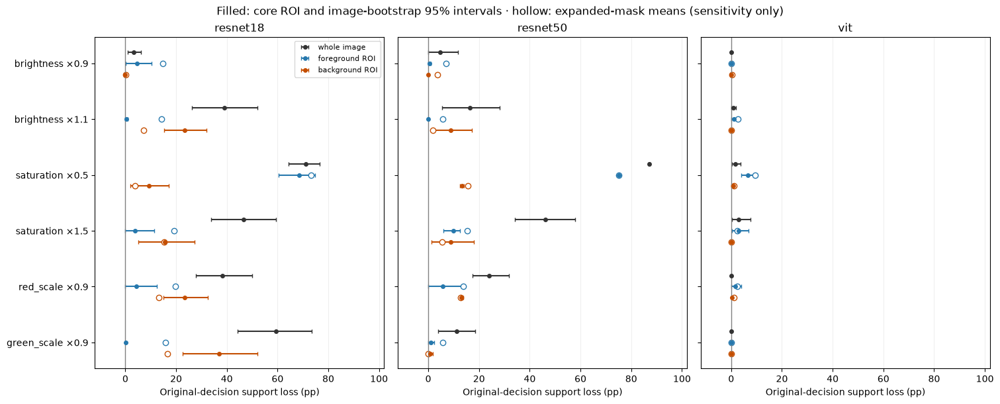

Core/expanded mean hard-mask area: 28.1%, 42.0%
Mean perturbation RMS on [0,1] intensity; whole / foreground / background, core mask:
brightness ×0.9: 0.0761 / 0.0244 / 0.0690
brightness ×1.1: 0.0644 / 0.0224 / 0.0575
saturation ×0.5: 0.0478 / 0.0324 / 0.0317
saturation ×1.5: 0.0458 / 0.0319 / 0.0294
red_scale ×0.9: 0.0470 / 0.0141 / 0.0430
green_scale ×0.9: 0.0405 / 0.0100 / 0.0379


In [18]:
q=targeted['roi_probabilities'];ids=targeted['roi_ids'];base=targeted['roi_baseline']
support=np.take_along_axis(q,base.argmax(-1)[:,None,None,None,:,None],axis=-1)[...,0]
drops=100*(base.max(-1)[:,None,None,None,:]-support)
rng=np.random.default_rng(43)
draws=np.column_stack([rng.choice(np.flatnonzero(labels[ids]==c),size=(2000,3)) for c in range(8)])
fig,axes=plt.subplots(1,3,figsize=(15,6),sharex=True,sharey=True,layout='constrained')
scopes=targeted['roi_scopes'];scope_colors=['#333333','#2678ad','#c44e00']
for m,ax in enumerate(axes):
    for scope in range(3):
        core=drops[m,0,:,scope];means=core.mean(-1);ci=np.quantile(core[:,draws].mean(-1),[.025,.975],axis=1)
        yy=np.arange(6)+(scope-1)*.2
        ax.errorbar(means,yy,xerr=[means-ci[0],ci[1]-means],fmt='o',color=scope_colors[scope],ms=4,capsize=2,label=str(scopes[scope]))
        if scope:
            ax.plot(drops[m,1,:,scope].mean(-1),yy,'o',mfc='white',mec=scope_colors[scope],ms=6)
    ax.axvline(0,color='gray',lw=1);ax.set(title=model_names[m],xlabel='Original-decision support loss (pp)',xlim=(-12,102),yticks=range(6),yticklabels=[f'{k} ×{v:g}' for k,v in zip(targeted['roi_kinds'],targeted['roi_levels'])]);ax.grid(axis='x',alpha=.2)
axes[0].invert_yaxis();axes[0].legend(fontsize=8)
fig.suptitle('Filled: core ROI and image-bootstrap 95% intervals · hollow: expanded-mask means (sensitivity only)')
plt.show()
print('Core/expanded mean hard-mask area:',', '.join(f'{mask.mean():.1%}' for mask in targeted['roi_masks']))
print('Mean perturbation RMS on [0,1] intensity; whole / foreground / background, core mask:')
for j,(kind,level) in enumerate(zip(targeted['roi_kinds'],targeted['roi_levels'])):
    print(f'{kind} ×{level:g}: '+ ' / '.join(f'{v:.4f}' for v in targeted['roi_rms'][0,j].mean(-1)))

**Interpretation:** Compare each scope within an intervention, treating hollow expanded-mask points as a mask-sensitivity check and the printed RMS values as unequal-dose warnings. At saturation ×0.5, core-ROI losses average 68/75/7 points versus background-complement losses 9/13/1 points for ResNet18/ResNet50/ViT, while some brightness/channel effects are more background- and mask-sensitive. The result supports saturation sensitivity in the approximate stained-object ROI but cannot establish anatomical localization or background reliance independently of mask error, unequal dose and nonlinear interactions.

## Final focused investigation · which observable properties distinguish IG–neutrophil misclassifications?

**Question:** Which measured appearance properties and perturbation responses distinguish IG→neutrophil and neutrophil→IG misclassifications from their same-class, similar-confidence correct controls?

**Background context, not a mechanistic finding:** The source [PBC dataset paper (Acevedo et al., 2020)](https://pmc.ncbi.nlm.nih.gov/articles/PMC7182702/) pools promyelocytes, myelocytes and metamyelocytes into the IG class and reports original images of 360×363 pixels. [ASH Image Bank](https://imagebank.hematology.org/image/60395/segmented-neutrophil) describes nuclear segmentation and chromatin in mature neutrophils; loss of such fine maturation cues in the available 28×28 images is a plausible hypothesis, **not a demonstrated cause here**. Upscaling the supplied 28px images to 224 does not restore missing detail, and no paired high-resolution images, IG subtype labels or expert nuclear annotations are available in this analysis.

**Evidence/design:** Restrict the existing one-to-one same-true-class, ≥90%-confidence, ≤1-percentage-point-confidence-gap pairs to HC errors predicted as the opposite member of {IG, neutrophil}. Compare the two directions separately for brightness, saturation and boundary-gradient fraction; then test central-versus-border occlusion and five mild cached perturbations against the same controls. This is a post-hoc TEST-only subgroup investigation, not new inference or independent confirmation; individual models' cohorts overlap and are not independent replications.

In [19]:
# Reuse the frozen tight matches; no model/runtime imports or fresh model queries.
ig_classes=(3,6)
ig_pairs=[];ig_draws=[];ig_direction_draws={};ig_coverage=[]
ig_feature_columns=[0,1,6]
ig_specs=[('brightness',4,'Brightness ×0.9778'),('brightness',5,'Brightness ×1.0222'),
          ('blur',1,'Blur radius 0.30'),('translation',4,'Shift −1/3 px'),('translation',5,'Shift +1/3 px')]
for ig_m,ig_name in enumerate(model_names):
    ig_all=targeted[f'matching_{ig_name}_pairs'];ig_e=ig_all[:,0]
    ig_keep=np.isin(labels[ig_e],ig_classes)&(predicted[ig_m,ig_e]==np.where(labels[ig_e]==3,6,3))
    ig_pair=ig_all[ig_keep];ig_pairs.append(ig_pair);ig_e,ig_c=ig_pair.T
    np.testing.assert_array_equal(labels[ig_e],labels[ig_c])
    assert len(np.unique(ig_c))==len(ig_c) and correct[ig_m,ig_c].all()
    assert (confidence[ig_m,ig_pair]>=.9).all() and np.abs(confidence[ig_m,ig_e]-confidence[ig_m,ig_c]).max()<=.01
    ig_rng=np.random.default_rng(42+ig_m)
    ig_draws.append(np.column_stack([ig_rng.choice(np.flatnonzero(labels[ig_e]==ig_cls),size=(2000,np.sum(labels[ig_e]==ig_cls))) for ig_cls in ig_classes]))
    for ig_cls in ig_classes:
        ig_idx=np.flatnonzero(labels[ig_e]==ig_cls)
        ig_direction_draws[ig_m,ig_cls]=ig_rng.choice(ig_idx,size=(2000,len(ig_idx)))
    ig_total=np.isin(labels,ig_classes)&(predicted[ig_m]==np.where(labels==3,6,3))&(confidence[ig_m]>=.9)
    ig_counts=[int((labels[ig_e]==c).sum()) for c in ig_classes]
    ig_coverage.append(dict(model=ig_name,matched=len(ig_e),eligible=int(ig_total.sum()),directions=ig_counts))
    print(f'{ig_name}: {len(ig_e)}/{ig_total.sum()} HC IG↔neutrophil errors retained; IG→neut {ig_counts[0]}, neut→IG {ig_counts[1]}')
print('Controls are HC-correct for the named matching model, not necessarily for the other models.')


resnet18: 19/20 HC IG↔neutrophil errors retained; IG→neut 10, neut→IG 9
resnet50: 21/21 HC IG↔neutrophil errors retained; IG→neut 10, neut→IG 11
vit: 13/14 HC IG↔neutrophil errors retained; IG→neut 6, neut→IG 7
Controls are HC-correct for the named matching model, not necessarily for the other models.


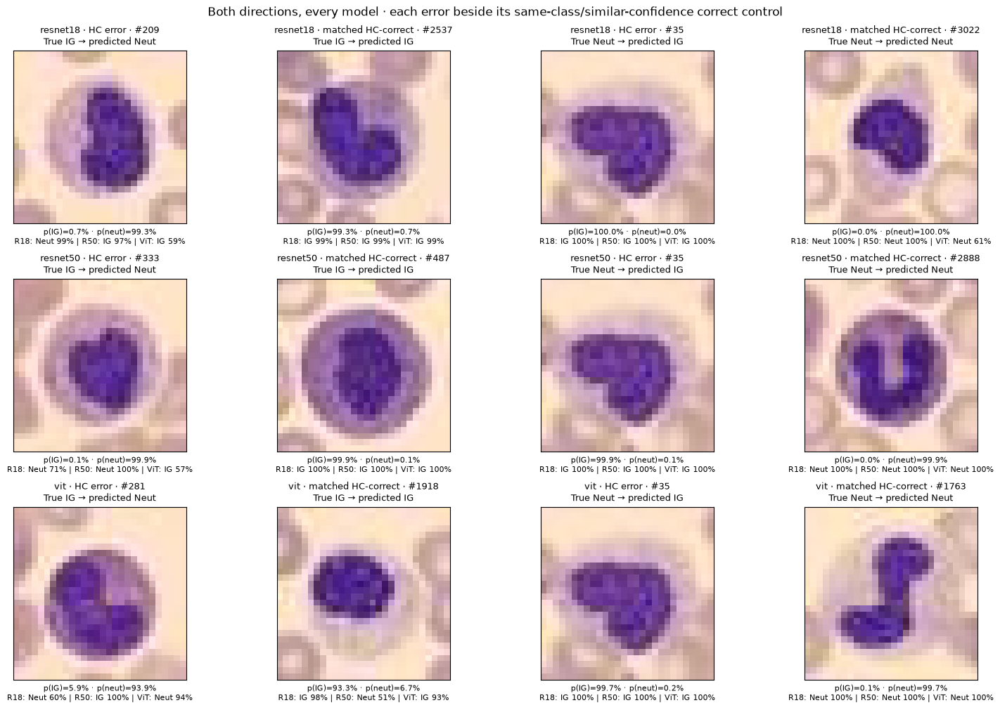

In [20]:
# First original TEST index in each available direction: no visual cherry-picking.
ig_short=['Baso','Eos','Ery','IG','Lymph','Mono','Neut','Platelet']
ig_gallery_ids=[]
fig,ig_axes=plt.subplots(3,4,figsize=(15,10),layout='constrained')
for ig_m,ig_name in enumerate(model_names):
    for ig_direction,ig_cls in enumerate(ig_classes):
        ig_candidates=ig_pairs[ig_m][labels[ig_pairs[ig_m][:,0]]==ig_cls]
        ig_pair=ig_candidates[np.argmin(ig_candidates[:,0])];ig_gallery_ids.append(ig_pair.tolist())
        for ig_role,ig_id in enumerate(ig_pair):
            ig_ax=ig_axes[ig_m,2*ig_direction+ig_role];ig_ax.imshow(images[ig_id]);ig_ax.set(xticks=[],yticks=[])
            ig_ax.set_title(f'{ig_name} · '+('HC error' if ig_role==0 else 'matched HC-correct')+f' · #{ig_id}\nTrue {ig_short[labels[ig_id]]} → predicted {ig_short[predicted[ig_m,ig_id]]}',fontsize=9)
            ig_ax.set_xlabel(f'p(IG)={probabilities[ig_m,ig_id,3]:.1%} · p(neut)={probabilities[ig_m,ig_id,6]:.1%}\n'+
                ' | '.join(f'{n}: {ig_short[predicted[k,ig_id]]} {confidence[k,ig_id]:.0%}' for k,n in enumerate(['R18','R50','ViT'])),fontsize=8)
fig.suptitle('Both directions, every model · each error beside its same-class/similar-confidence correct control')
plt.show()


Compare each wrong image with the same-class correct image immediately beside it, then compare the two directions within each model row. The selected mistakes have ≥90% reported confidence despite choosing the opposite class, so they are not merely indecisive softmax outputs. Similar-looking low-resolution examples motivate a maturation/detail hypothesis, but this gallery cannot diagnose nuclear morphology, verify the labels or prove that the classes are intrinsically ambiguous.

In [21]:
ig_features=analysis['features'][:,ig_feature_columns]
ig_feature_results=[];ig_spatial_results=[];ig_intervention_results=[]
for ig_m,ig_pair in enumerate(ig_pairs):
    ig_e,ig_c=ig_pair.T;ig_delta=100*(ig_features[ig_e]-ig_features[ig_c])
    for ig_cls in ig_classes:
        ig_idx=np.flatnonzero(labels[ig_e]==ig_cls);ig_boot=ig_delta[ig_direction_draws[ig_m,ig_cls]].mean(1)
        ig_feature_results.append(dict(model=ig_m,true_class=ig_cls,n=len(ig_idx),mean=ig_delta[ig_idx].mean(0),ci=np.quantile(ig_boot,[.025,.975],axis=0)))
# Average patches within each image BEFORE resampling pairs; patches are not independent units.
with np.load('predictions/occlusion_test.npz',allow_pickle=False) as ig_saved:
    np.testing.assert_array_equal(ig_saved['baseline_probabilities'],probabilities)
    ig_occluded=ig_saved['probabilities']
ig_retained=np.take_along_axis(ig_occluded,predicted[:,None,:,None],axis=-1)[...,0]
ig_loss=100*(confidence[:,None]-ig_retained).transpose(0,2,1).reshape(3,len(labels),7,7)
ig_ring=np.ones((7,7),bool);ig_ring[1:-1,1:-1]=False
ig_center=ig_loss[:,:,2:5,2:5].mean((2,3));ig_border=ig_loss[:,:,ig_ring].mean(-1)
assert ig_center.shape==ig_border.shape==(3,len(labels))
for ig_m,ig_pair in enumerate(ig_pairs):
    ig_e,ig_c=ig_pair.T
    ig_difference=(ig_center[ig_m,ig_e]-ig_border[ig_m,ig_e])-(ig_center[ig_m,ig_c]-ig_border[ig_m,ig_c])
    ig_spatial_results.append(dict(mean=ig_difference.mean(),ci=np.quantile(ig_difference[ig_draws[ig_m]].mean(1),[.025,.975])))
with np.load('predictions/stability.npz',allow_pickle=False) as ig_saved:
    np.testing.assert_array_equal(ig_saved['baseline'],probabilities)
    np.testing.assert_array_equal(ig_saved['indices'],np.arange(len(labels)))
    # Decompress each operation once, then extract all requested mild levels/models.
    for ig_kind in dict.fromkeys(spec[0] for spec in ig_specs):
        ig_p=ig_saved[ig_kind]
        for ig_spec_index,(ig_operation,ig_level_index,ig_title) in enumerate(ig_specs):
            if ig_operation!=ig_kind:continue
            for ig_m,ig_pair in enumerate(ig_pairs):
                ig_e,ig_c=ig_pair.T;ig_now=ig_p[ig_m,ig_level_index].argmax(-1)
                ig_recovered=(ig_now[:,ig_e]==labels[ig_e]).mean(0)
                ig_damaged=(ig_now[:,ig_c]!=labels[ig_c]).mean(0)
                ig_stayed=(ig_now[:,ig_e]==np.where(labels[ig_e]==3,6,3)).mean(0)
                ig_other=1-ig_recovered-ig_stayed
                ig_net=100*(ig_recovered-ig_damaged)
                ig_intervention_results.append(dict(model=ig_m,spec=ig_spec_index,label=ig_title,level=float(ig_saved[f'levels_{ig_kind}'][ig_level_index]),
                    recovered=ig_recovered.mean(),damaged=ig_damaged.mean(),stayed=ig_stayed.mean(),other=ig_other.mean(),
                    mean=ig_net.mean(),ci=np.quantile(ig_net[ig_draws[ig_m]].mean(1),[.025,.975])))


### Directional appearance, spatial specificity and selective repair

Top panels: paired error-minus-control differences for each direction separately, on each feature’s native 0–100 scale (**not accuracy units or feature-importance scores**). Brightness is mean luminance, saturation is mean HSV saturation, and boundary-gradient fraction is the fraction of total gradient energy in the outer four-pixel image frame; that fraction is not a nuclear-segmentation measure and can change with cell size, position or central energy.

Bottom left: [(center−border support loss) in errors] − [(center−border support loss) in controls], using nine central and 24 outer-ring patches. Bottom right: percentage of original errors repaired **minus** percentage of matched correct controls made wrong; switching into a third wrong class does not count as recovery. Positive selective repair would support a more useful local intervention, but would still not establish a biological cause.

Intervals use 2,000 paired-image bootstrap samples, stratified by true class for pooled contrasts and within direction for appearance. They condition on the selected matches, exclude training/annotation/matching uncertainty and have no multiplicity correction; zero-width intervals when no selected image changes are **not proof of population-wide stability**.

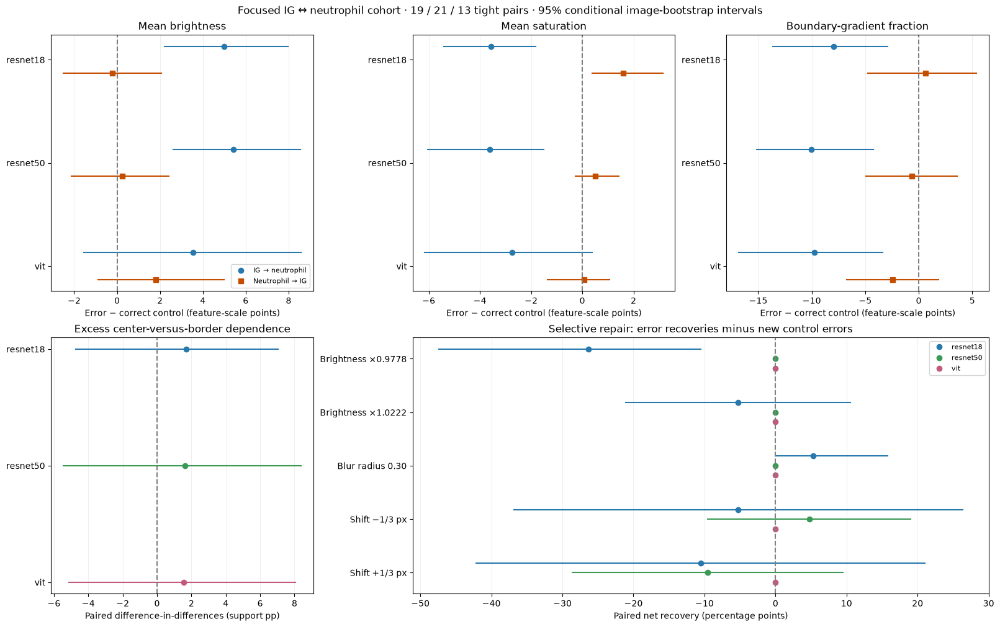

In [22]:
fig=plt.figure(figsize=(16,10),layout='constrained');ig_grid=fig.add_gridspec(2,3)
ig_direction_colors={3:'#2678ad',6:'#c44e00'}
for ig_f,ig_title in enumerate(['Mean brightness','Mean saturation','Boundary-gradient fraction']):
    ig_ax=fig.add_subplot(ig_grid[0,ig_f])
    for ig_result in ig_feature_results:
        ig_m,ig_cls=ig_result['model'],ig_result['true_class'];ig_y=ig_m+(-.13 if ig_cls==3 else .13)
        ig_ci=ig_result['ci'][:,ig_f];ig_mean=ig_result['mean'][ig_f]
        ig_ax.plot(ig_ci,[ig_y,ig_y],color=ig_direction_colors[ig_cls]);ig_ax.plot(ig_mean,ig_y,'o' if ig_cls==3 else 's',color=ig_direction_colors[ig_cls],
            label=('IG → neutrophil' if ig_cls==3 else 'Neutrophil → IG') if ig_m==0 else None)
    ig_ax.axvline(0,color='gray',ls='--');ig_ax.set(title=ig_title,yticks=range(3),yticklabels=model_names,xlabel='Error − correct control (feature-scale points)');ig_ax.invert_yaxis();ig_ax.grid(axis='x',alpha=.2)
    if ig_f==0:ig_ax.legend(fontsize=8)
ig_ax=fig.add_subplot(ig_grid[1,0])
for ig_m,ig_result in enumerate(ig_spatial_results):
    ig_ax.plot(ig_result['ci'],[ig_m,ig_m],color=model_colors[ig_m]);ig_ax.plot(ig_result['mean'],ig_m,'o',color=model_colors[ig_m])
ig_ax.axvline(0,color='gray',ls='--');ig_ax.set(title='Excess center-versus-border dependence',yticks=range(3),yticklabels=model_names,xlabel='Paired difference-in-differences (support pp)');ig_ax.invert_yaxis();ig_ax.grid(axis='x',alpha=.2)
ig_ax=fig.add_subplot(ig_grid[1,1:])
for ig_result in ig_intervention_results:
    ig_m=ig_result['model'];ig_y=ig_result['spec']+(ig_m-1)*.18
    ig_ax.plot(ig_result['ci'],[ig_y,ig_y],color=model_colors[ig_m]);ig_ax.plot(ig_result['mean'],ig_y,'o',color=model_colors[ig_m],label=model_names[ig_m] if ig_result['spec']==0 else None)
ig_ax.axvline(0,color='gray',ls='--');ig_ax.set(title='Selective repair: error recoveries minus new control errors',yticks=range(len(ig_specs)),yticklabels=[s[2] for s in ig_specs],xlabel='Paired net recovery (percentage points)');ig_ax.invert_yaxis();ig_ax.grid(axis='x',alpha=.2);ig_ax.legend(fontsize=8)
fig.suptitle('Focused IG ↔ neutrophil cohort · 19 / 21 / 13 tight pairs · 95% conditional image-bootstrap intervals')
plt.show()


Compare the observed property differences and perturbation responses between the two error directions and their matched correct controls. IG→neutrophil errors have brighter, less saturated and lower-boundary-fraction point estimates in all three models, whereas reverse-direction shifts are smaller or mixed; all excess-center intervals include zero and no tested mild edit has a strictly positive lower selective-repair bound. These results characterize direction-dependent appearance/framing associations in the selected misclassifications, not the mechanisms that caused them.

In [23]:
from IPython.display import HTML
ig_rows=['<tr><th>Model / intervention</th><th>Repaired</th><th>Still opposite</th><th>Other wrong</th><th>Controls made wrong</th><th>Paired net pp [95% interval]</th></tr>']
for ig_result in sorted(ig_intervention_results,key=lambda r:(r['model'],r['spec'])):
    ig_ci=ig_result['ci'];ig_rows.append(f"<tr><td>{model_names[ig_result['model']]} · {ig_result['label']}</td>"+
        ''.join(f'<td>{100*ig_result[k]:.1f}%</td>' for k in ['recovered','stayed','other','damaged'])+
        f"<td>{ig_result['mean']:+.1f} [{ig_ci[0]:+.1f}, {ig_ci[1]:+.1f}]</td></tr>")
display(HTML('<details><summary>Show all error destinations and paired intervention rates (15 rows)</summary><table>'+''.join(ig_rows)+'</table></details>'))
for ig_m,ig_result in enumerate(ig_spatial_results):
    print(f"{model_names[ig_m]}: excess center-vs-border {ig_result['mean']:+.2f} support pp; interval {ig_result['ci'].round(2).tolist()}")


Model / intervention,Repaired,Still opposite,Other wrong,Controls made wrong,Paired net pp [95% interval]
resnet18 · Brightness ×0.9778,0.0%,78.9%,21.1%,26.3%,"-26.3 [-47.4, -10.5]"
resnet18 · Brightness ×1.0222,5.3%,94.7%,0.0%,10.5%,"-5.3 [-21.1, +10.5]"
resnet18 · Blur radius 0.30,5.3%,94.7%,0.0%,0.0%,"+5.3 [+0.0, +15.8]"
resnet18 · Shift −1/3 px,21.1%,78.9%,0.0%,26.3%,"-5.3 [-36.8, +26.3]"
resnet18 · Shift +1/3 px,21.1%,78.9%,0.0%,31.6%,"-10.5 [-42.1, +21.1]"
resnet50 · Brightness ×0.9778,0.0%,95.2%,4.8%,0.0%,"+0.0 [+0.0, +0.0]"
resnet50 · Brightness ×1.0222,0.0%,100.0%,0.0%,0.0%,"+0.0 [+0.0, +0.0]"
resnet50 · Blur radius 0.30,0.0%,100.0%,0.0%,0.0%,"+0.0 [+0.0, +0.0]"
resnet50 · Shift −1/3 px,19.0%,81.0%,0.0%,14.3%,"+4.8 [-9.5, +19.0]"
resnet50 · Shift +1/3 px,4.8%,95.2%,0.0%,14.3%,"-9.5 [-28.6, +9.5]"


resnet18: excess center-vs-border +1.69 support pp; interval [-4.74, 7.04]
resnet50: excess center-vs-border +1.61 support pp; interval [-5.47, 8.4]
vit: excess center-vs-border +1.55 support pp; interval [-5.12, 8.04]


### Observable distinctions: a directional appearance pattern

Read the measured properties and perturbation responses as descriptive contrasts with matched correct examples. The clearest recurring pattern is on **IG→neutrophil** errors, not equally in the reverse direction, while the tested changes do not selectively repair the subgroup with a clearly positive interval and the matched spatial contrast remains inconclusive. These observations characterize the selected misclassifications rather than explain their causes; proposed maturation- or resolution-related mechanisms require original-resolution, subtype-resolved expert review and controlled follow-up.

## What survives the controls?

- **Disagreement and confidence:** Compare shared/exclusive images and class substitutions with reliability. The checkpoints share 18 HC errors despite different class-specific risks, and confidence exceeds observed accuracy. High confidence is therefore not a correctness guarantee, especially around the IG/neutrophil competition.
- **Stability and preprocessing:** Compare population robustness, selected flips and the paired interpolation control. Tiny edits can flip HC-correct predictions, while common bilinear resizing greatly narrows the selected noise-loss gap but worsens clean ResNet18 accuracy. Robustness here belongs to the checkpoint-plus-preprocessing pipeline, not architecture alone.
- **Appearance:** Compare the matched feature intervals, saturation destinations and approximate ROI probes. ViT brightness/saturation associations remain under tight matching, both CNNs show the broad saturation-to-erythroblast attractor, and desaturating stained-object ROIs strongly affects CNN support. This prioritizes color-related hypotheses without proving a biological cause or clean foreground/background separation.
- **A weakened explanation:** Compare the old archived occlusion contrast with the new tightly matched intervals. The old roughly 10-point extra central losses shrink to +1.4/−1.2/+3.3 points and all intervals cross zero. Stronger central dependence of HC errors is not supported after this tighter confidence control.

**Limits:** Exploratory TEST-only analysis, correlated features and no multiple-comparison correction; unmatched errors are excluded from tight-pair results. Small balanced ROI/interpolation cohorts are not full-population prevalence estimates, bootstrap intervals condition on the selected cohort/matching and do not incorporate model-training or segmentation uncertainty, and image edits may invalidate labels. [archive.ipynb](archive.ipynb) retains every original/intermediate plot, output and interpretation, including all entropy/PCA work and the source for reproducing the targeted controls.

## Pre-finalization stability_analysis.ipynb

# Story 3 companion · transformation stability

**Question:** Which visual changes alter labels, and which actually change correctness? Two shared-scale grids distinguish decision consistency from accuracy across all **3,421 TEST images**, all ten severity levels and the original eight transformations; noise repeats are averaged within image.

**Evidence:** These cache-only views use the exact frozen checkpoint/preprocessing pipelines. Return to [the four-story notebook](confidence_analysis.ipynb#story-3) for tiny-change image/probability examples, resizing controls, the offline transition explorer and the actual-model live editing app. Complete previous panels, code and outputs remain in [archive.ipynb](archive.ipynb).

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

with np.load('data/bloodmnist.npz',allow_pickle=False) as saved:
    labels=saved['test_labels'].ravel()
with np.load('predictions/stability.npz',allow_pickle=False) as saved:
    assert str(saved['split'])=='test' and str(saved['noise_seed_scope'])=='original test index'
    np.testing.assert_array_equal(saved['indices'],np.arange(len(labels)))
    np.testing.assert_array_equal(saved['labels'],labels)
    assert len(labels)==3421
    baseline=saved['baseline']
    model_names=saved['model_names'].tolist()
    checkpoints=saved['checkpoints'].tolist()
    levels={key[7:]:saved[key] for key in saved.files if key.startswith('levels_')}
    base_class=baseline.argmax(-1)
    baseline_accuracy=(base_class==labels).mean(-1)
    curves={'Label changes':{},'Accuracy':{}}
    for kind,values in levels.items():
        p=saved[kind]
        assert p.shape==(3,10,3 if kind=='noise' else 1,len(labels),8)
        assigned=p.argmax(-1)
        # Equal weight per original image; the repeated-noise mean is not an enlarged sample.
        curves['Label changes'][kind]=(assigned!=base_class[:,None,None,:]).mean((2,3))
        curves['Accuracy'][kind]=(assigned==labels).mean((2,3))
model_colors=['#2678ad','#3b9956','#c25a7c']
axis_labels={'rotation':'Rotation (degrees)','translation':'Translation (pixels)',
             'brightness':'Brightness factor','blur':'Blur radius (pixels)','noise':'Noise σ',
             'green_scale':'Green factor','red_scale':'Red factor','blue_scale':'Blue factor'}
for name,accuracy,path in zip(model_names,baseline_accuracy,checkpoints):
    print(f'{name}: original accuracy {accuracy:.2%} · {path}')
def plot_comparison(metric):
    fig,axes=plt.subplots(2,4,figsize=(16,7),sharey=True,layout='constrained')
    for ax,(kind,values) in zip(axes.flat,levels.items()):
        for m,name in enumerate(model_names):
            ax.plot(values,curves[metric][kind][m],'o-',color=model_colors[m],label=name,ms=4)
            if metric=='Accuracy':
                ax.axhline(baseline_accuracy[m],color=model_colors[m],ls='--',alpha=.4)
        ax.set(title=axis_labels[kind],ylim=(0,1),yticks=np.linspace(0,1,5))
        ax.yaxis.set_major_formatter(PercentFormatter(1,decimals=0))
        ax.grid(alpha=.2)
    fig.legend(*axes[0,0].get_legend_handles_labels(),loc='outside lower center',ncol=3)
    fig.suptitle(f'{metric} · all {len(labels):,} TEST images · common 0–100% axes; no severity averaging')
    plt.show()

resnet18: original accuracy 96.61% · weights_bloodmnist/resnet18_224_1.pth
resnet50: original accuracy 95.73% · weights_bloodmnist/resnet50_28_1.pth
vit: original accuracy 96.99% · models/vit


## Do predictions keep the same label?

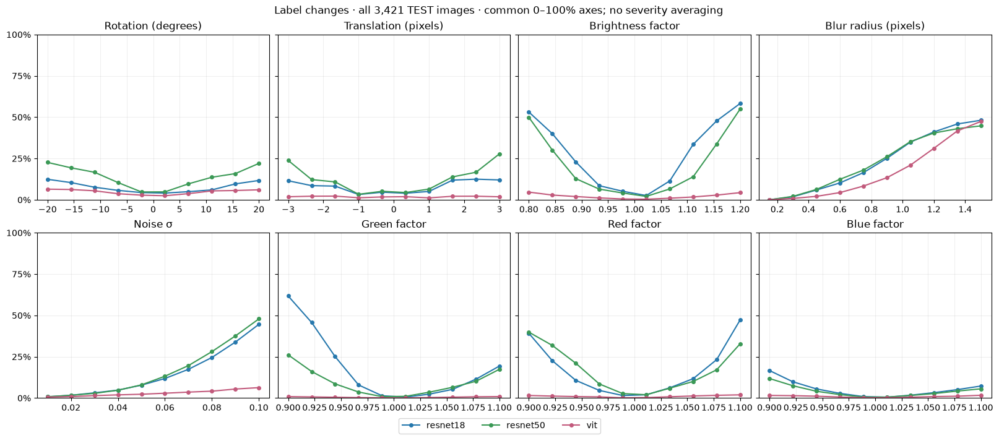

In [2]:
plot_comparison('Label changes')

Compare model curves within each panel and across transformations using the same percentage scale. Mean rotation flip rates are 7.7%, 14.0% and 4.8% for ResNet18, ResNet50 and ViT, while ViT reaches 17.0% under blur but only 2.9% under noise. Consistency is therefore intervention-specific, and a label change alone does not establish whether correctness improved or deteriorated.

## Are the predictions correct? — dashed lines show original accuracy

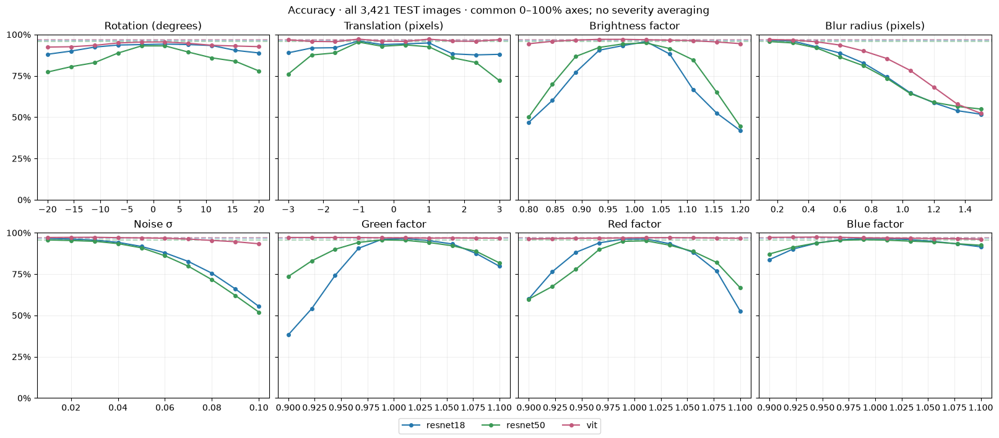

In [3]:
plot_comparison('Accuracy')

Compare accuracy with each model’s dashed baseline rather than inferring correctness from label stability alone. Mean brightness accuracy is 71.3%, 77.4% and 96.1% for ResNet18, ResNet50 and ViT, but strongest-blur accuracy converges to 51.8%, 54.9% and 52.3%. ViT’s advantage therefore depends on the intervention and does not imply uniformly greater robustness to removal of spatial detail.

## Interpretation and interactive follow-through

Use the [four-story notebook](confidence_analysis.ipynb#story-3) to decompose recoveries versus newly wrong predictions, inspect tiny-change examples with all eight probabilities, and check how interpolation confounds the noise comparison. Its offline explorer needs no model server; the [live app](http://127.0.0.1:8765) needs `python image_sandbox.py` and evaluates actual edited inputs. The targeted 96-image interpolation control does not replace these full-test curves or justify an architecture-only robustness claim.

## Pre-finalization predictions.ipynb

# BloodMNIST predictions
## Run 1: ResNet18 at 224 × 224 (nearest-neighbor resize), ResNet50 at 28 × 28, original ViT processor

In [1]:
from pathlib import Path
import numpy as np
import torch
from transformers import ViTForImageClassification, ViTImageProcessor
from torchvision.models import resnet18
from models.resnet18.models import ResNet50

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
batch_size = 32
output = Path('predictions')
output.mkdir(exist_ok=True)
print(device)
model_names = ['resnet18', 'resnet50', 'vit']

cuda


## Dataset

In [2]:
with np.load('data/bloodmnist.npz', allow_pickle=False) as data:
    splits = {split: (data[f'{split}_images'], data[f'{split}_labels'].ravel())
              for split in ('train', 'val', 'test')}

## Models

In [3]:
models = [resnet18(weights=None, num_classes=8), ResNet50(in_channels=3, num_classes=8)]
checkpoints = ['weights_bloodmnist/resnet18_224_1.pth', 'weights_bloodmnist/resnet50_28_1.pth', 'models/vit']
for model, path in zip(models, checkpoints):
    model.load_state_dict(torch.load(path, map_location='cpu', weights_only=True)['net'])
models.append(ViTForImageClassification.from_pretrained('models/vit', local_files_only=True))
models = [model.to(device).eval() for model in models]
processor = ViTImageProcessor.from_pretrained('models/vit', local_files_only=True)


## Predictions → CSV (image_index, label, prediction, p0–p7)

In [4]:
@torch.inference_mode()
def predict(m, images):
    probabilities, scores = [], []
    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size]
        if model_names[m] != 'vit':
            x = torch.from_numpy(batch.copy()).permute(0, 3, 1, 2).to(device).float()
            if model_names[m] == 'resnet18':
                x = torch.nn.functional.interpolate(x, size=(224, 224), mode='nearest')
            logits = models[m]((x / 255 - 0.5) / 0.5)
        else:
            inputs = processor(images=list(batch), return_tensors='pt').to(device)
            logits = models[m](**inputs).logits
        probabilities.append(logits.softmax(-1).cpu().numpy())
        scores.append(logits.cpu().numpy())
    return np.concatenate(probabilities), np.concatenate(scores)

for m, name in enumerate(model_names):
    for split, (images, labels) in splits.items():
        probabilities, logits = predict(m, images)
        predictions = probabilities.argmax(axis=1)
        rows = np.column_stack((np.arange(len(labels)), labels, predictions, probabilities))
        np.savetxt(output / f'{name}_{split}.csv', rows, delimiter=',',
                   header='image_index,label,prediction,' + ','.join(f'p{i}' for i in range(8)),
                   comments='', fmt=['%d'] * 3 + ['%.9g'] * 8)
        np.savez_compressed(output / f'{name}_{split}.npz', probabilities=probabilities, logits=logits,
                            sample_index=np.arange(len(labels)), labels=labels, model=name,
                            checkpoint=checkpoints[m], split=split, input_resolution=224 if name != 'resnet50' else 28)
        print(f'{name} {split}: {len(labels)} predictions, accuracy {(predictions == labels).mean():.2%}')


resnet18 train: 11959 predictions, accuracy 100.00%


resnet18 val: 1712 predictions, accuracy 97.20%


resnet18 test: 3421 predictions, accuracy 96.61%


resnet50 train: 11959 predictions, accuracy 100.00%


resnet50 val: 1712 predictions, accuracy 96.09%


resnet50 test: 3421 predictions, accuracy 95.73%


vit train: 11959 predictions, accuracy 99.48%


vit val: 1712 predictions, accuracy 97.78%


vit test: 3421 predictions, accuracy 96.99%


## Pre-finalization visualization/predictions.ipynb

#### About

This file is used to make the predictions on all the splits for all 3 models. This predictions are saved in a seperate file to use for visualizations, to not recompute it all the time.

##### Data

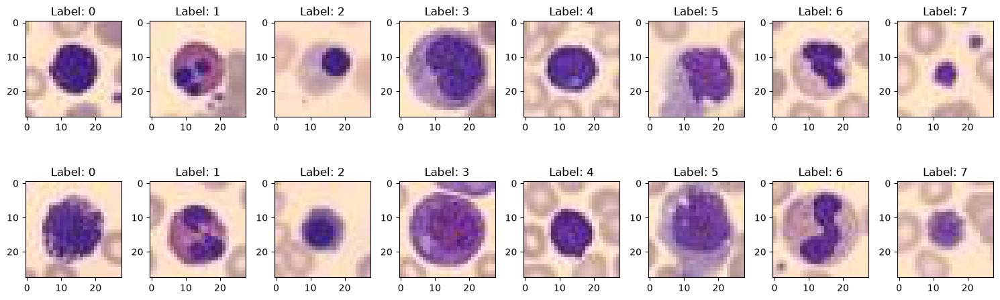

(11959, 28, 28, 3)


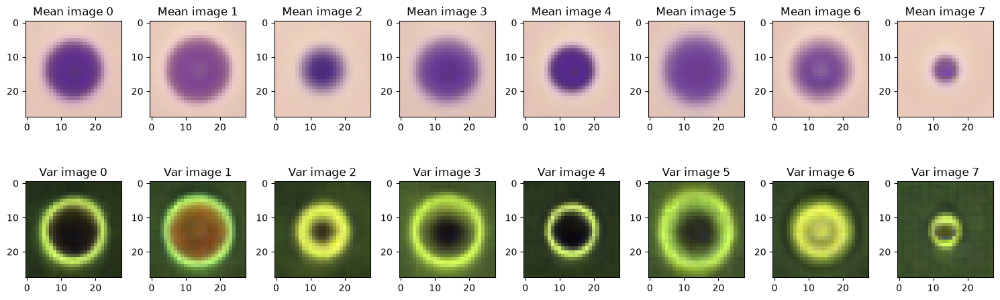

[244 624 311 579 243 284 666 470]


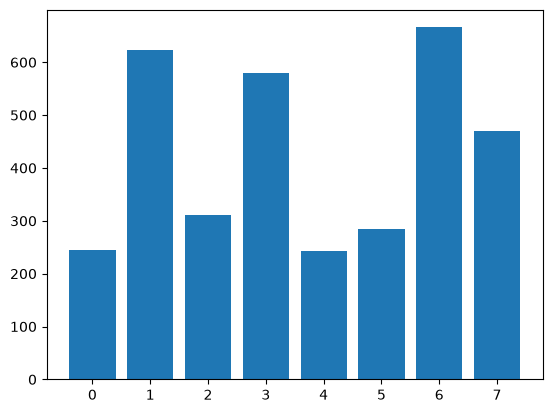

In [95]:
import numpy as np
import matplotlib.pyplot as plt

with np.load("../data/bloodmnist.npz", allow_pickle=False) as dataset:
    t_images = dataset["train_images"]
    t_labels = dataset["train_labels"].reshape(-1)
    test_images = dataset["test_images"]
    test_labels = dataset["test_labels"].reshape(-1)




fig, axes = plt.subplots(2,8,figsize=(15,5))
for i in range(8): 
    class_img = t_images[t_labels==i]
    axes[0,i].imshow(class_img[0])
    axes[0,i].title.set_text(f"Label: {i}")
    axes[1,i].imshow(class_img[1])
    axes[1,i].title.set_text(f"Label: {i}")

plt.tight_layout()
plt.show()


print(t_images.shape)

fig, axes = plt.subplots(2,8,figsize=(15,5))
for i in range(0,8):
    class_img = t_images[t_labels==i]
    mean_image = np.mean(class_img, axis=(0,), dtype=np.int64) 
    var_image = np.var(class_img, axis=(0,), dtype=np.int64) 
    var_image = var_image/np.max(var_image)
    axes[0,i].imshow(mean_image)
    axes[0,i].title.set_text(f"Mean image {i}")    
    axes[1,i].imshow(var_image)
    axes[1,i].title.set_text(f"Var image {i}")   

plt.tight_layout()
plt.show()

labels = np.bincount(test_labels)
print(labels)
axes= plt.bar(np.arange(0,8), labels)

plt.show()

[0.2664876  0.08916575]
(3421, 2) (11959,)


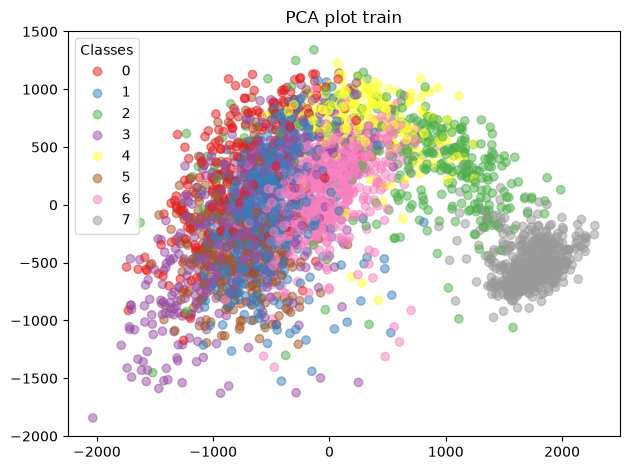

(3421, 2) (11959,)


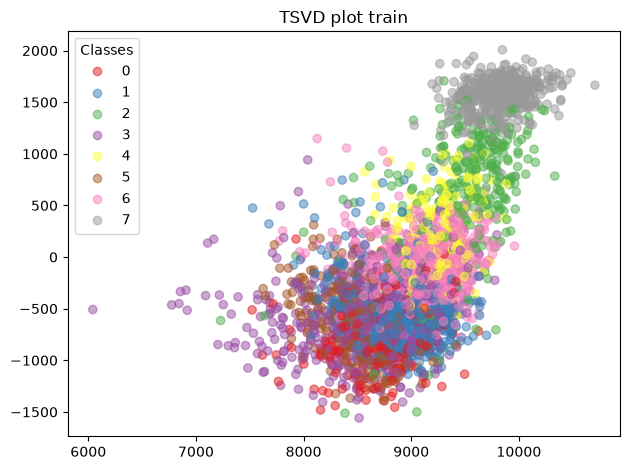

In [71]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.decomposition import TruncatedSVD  

pca = PCA(n_components=2)
train_pca = pca.fit_transform(test_images.reshape((test_images.shape[0], -1)))
print(pca.explained_variance_ratio_)
print(train_pca.shape, t_labels.shape)
scatter=plt.scatter(train_pca[:,0], train_pca[:,1], c=test_labels, alpha=0.5, cmap="Set1")
plt.title("PCA plot train")
handles, labels = scatter.legend_elements()
plt.legend(handles, labels, title="Classes")
plt.tight_layout()
plt.show()

"""tsne = TSNE(n_components=2, perplexity=15)
train_tnse = tsne.fit_transform(test_images.reshape((test_images.shape[0], -1)))
print(train_tnse.shape, t_labels.shape)
scatter=plt.scatter(train_tnse[:,0], train_tnse[:,1], c=test_labels, alpha=0.5, cmap="Set1")
plt.title("TSNE plot train")
handles, labels = scatter.legend_elements()
plt.legend(handles, labels, title="Classes")
plt.tight_layout()
plt.show()"""

tsvd = TruncatedSVD(n_components=2)
train_tsvd = tsvd.fit_transform(test_images.reshape((test_images.shape[0], -1)))
print(train_tsvd.shape, t_labels.shape)
scatter=plt.scatter(train_tsvd[:,0], train_tsvd[:,1], c=test_labels, alpha=0.5, cmap="Set1")
plt.title("TSVD plot train")
handles, labels = scatter.legend_elements()
plt.legend(handles, labels, title="Classes")
plt.tight_layout()
plt.show()


#### Predictions

(3421, 9)
[318 626 289 551 233 256 675 473]


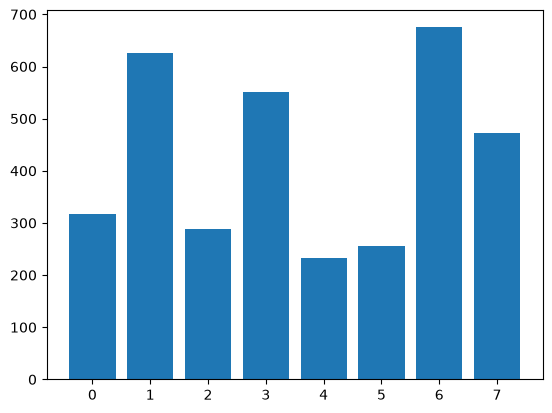

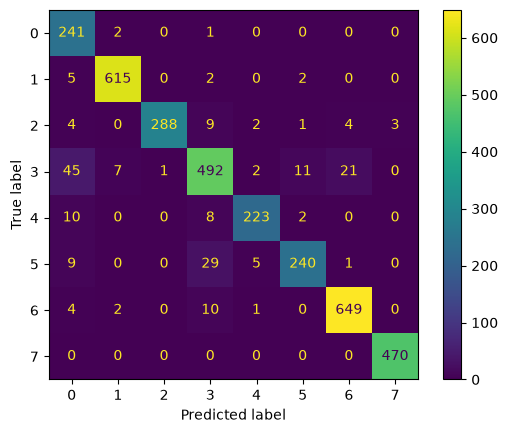

In [66]:
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

test_pred = pd.read_csv("../predictions/bloodmnist_test_[AUC]0.997_[ACC]0.941@resnet50_224_1.csv", header=None)
test_pred = test_pred.to_numpy()
print(test_pred.shape)
test_pred = np.argmax(test_pred[:,1:], axis=1)

labels = np.bincount(test_pred)
print(labels)
axes= plt.bar(np.arange(0,8), labels)

plt.show()

cm = confusion_matrix(test_labels, test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()